## 1. Environment Setup and Library Imports
Load standard libraries for data manipulation, pathway enrichment (`gseapy`), regularized regression and machine learning (`scikit-learn`, `shap`), survival and statistical modeling (`lifelines`, `statsmodels`, `scipy`, `semopy`), network analysis (`networkx`), and visualization (`matplotlib`, `seaborn`).

Run from the project root containing `analysis_notebook.ipynb`. Inputs belong in `data/raw/` or `data/processed/`; generated files go to `results/`. Some required inputs are not supplied; consult README before running.

In [ ]:
# Standard library
import gc
import gzip
import os
import re
import shutil
import subprocess
import warnings
from itertools import combinations

# Data manipulation & visualization
import joblib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from networkx.algorithms.community import louvain_communities, modularity as nx_modularity

# Statistical & survival modeling
import gseapy as gp
from gseapy import gsva
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import chi2, fisher_exact, kruskal, mannwhitneyu, pearsonr, spearmanr
import semopy
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Machine learning & explainability
import shap
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.linear_model import (
    ElasticNet,
    ElasticNetCV,
    Lasso,
    LassoCV,
    LinearRegression,
    LogisticRegression,
)
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

warnings.filterwarnings("ignore")

os.makedirs("results", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)



### Assessing the Missingness of GDSC Drug Response Data

To investigate whether missing IC50 measurements are associated with underlying drug sensitivity patterns, we perform the following analysis:

1. **Data integration:** Combine the GDSC1 and GDSC2 dose–response datasets into `gdsc_full`, averaging `LN_IC50` values for duplicate drug–cell line pairs.

2. **Pathway annotation:** Map drugs to their associated signaling pathways using the compound metadata and construct `gdsc_full_pathway`. Standardize `LN_IC50` values within each drug using z-scores.

3. **Missingness analysis:** Calculate pathway-level dependency scores as the mean standardized `LN_IC50` across drugs targeting the same pathway, without imputation. For each drug, exclude its own measurements when calculating the corresponding pathway scores to avoid circularity. Restrict the analysis to drugs tested in at least 20 cell lines and compare two groups:
   - **Observed:** Cell lines with available IC50 measurements for the drug.
   - **Missing:** Cell lines without IC50 measurements for the drug.

   Include only cell lines with available leave-one-drug-out pathway scores and require at least five cell lines per group. Compare the score distributions using a two-sided Mann–Whitney U test, with Benjamini–Hochberg false discovery rate (FDR) correction across tests. Adjusted p-values (q-values) below 0.05 are considered statistically significant.

4. **Visualization:** Examine the distribution of unadjusted p-values and the proportion of significant tests among the 20 drugs with the highest number of eligible tests.


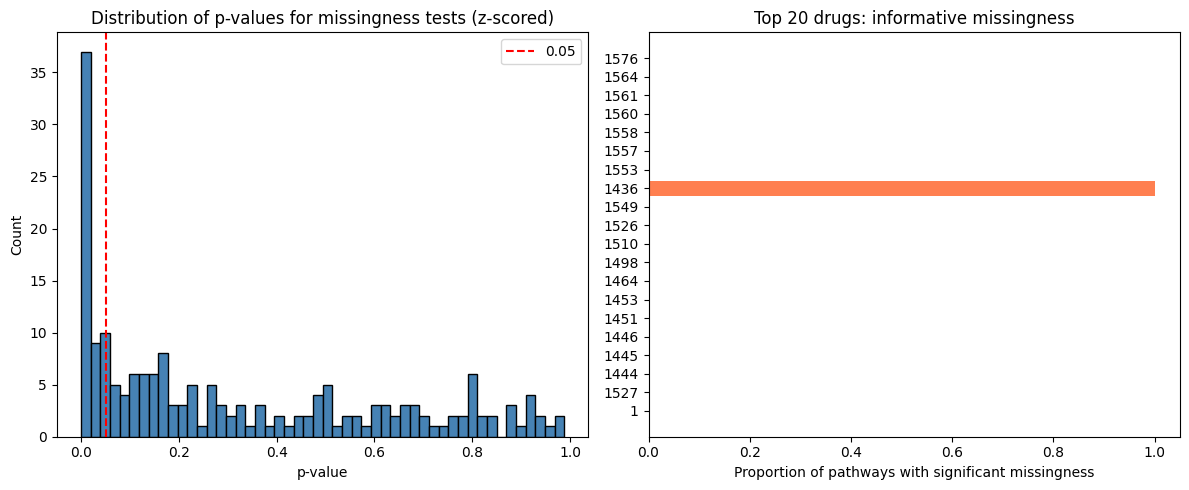

In [25]:

gdsc1 = pd.read_excel("data/raw/GDSC1_fitted_dose_response_15Oct19.xlsx")
gdsc2 = pd.read_excel("data/raw/GDSC2_fitted_dose_response_15Oct19.xlsx")

gdsc_full = pd.concat([gdsc1, gdsc2], ignore_index=True)
gdsc_full = gdsc_full[['SANGER_MODEL_ID', 'DRUG_ID', 'LN_IC50']]

dup_mask = gdsc_full.duplicated(subset=['SANGER_MODEL_ID', 'DRUG_ID'], keep=False)
n_dup = dup_mask.sum()

if n_dup > 0:
    gdsc_full = (gdsc_full
                 .groupby(['SANGER_MODEL_ID', 'DRUG_ID'], as_index=False)['LN_IC50']
                 .mean())

compounds = pd.read_csv("data/raw/screened_compounds_rel_8.1.csv")

pathway_mapping = {
    'PI3K/MTOR signaling': 'PI3K_MTOR',
    'ERK MAPK signaling': 'MAPK',
    'EGFR signaling': 'EGFR',
    'WNT signaling': 'WNT',
    'Apoptosis regulation': 'APOPTOSIS',
    'Cell cycle': 'CELL_CYCLE',
    'Mitosis': 'CELL_CYCLE',
    'IGF1R signaling': 'IGF1R',
    'JNK and p38 signaling': 'JNK_P38',
    'p53 pathway': 'P53',
}

compound_to_pathway = {}
for idx, row in compounds.iterrows():
    tp = row.get('TARGET_PATHWAY', '')
    if tp in pathway_mapping:
        compound_to_pathway[row['DRUG_ID']] = pathway_mapping[tp]

gdsc_full['Pathway'] = gdsc_full['DRUG_ID'].map(compound_to_pathway)
gdsc_full_pathway = gdsc_full.dropna(subset=['Pathway']).copy()

gdsc_full_pathway['LN_IC50_Z'] = (
    gdsc_full_pathway
    .groupby('DRUG_ID')['LN_IC50']
    .transform(lambda x: (x - x.mean()) / x.std() if x.std() > 0 else 0)
)

gdsc_full_pathway.to_csv("results/gdsc_full_pathway_z.csv", index=False)

dep_scores_raw = (
    gdsc_full_pathway
    .groupby(['SANGER_MODEL_ID', 'Pathway'])['LN_IC50_Z']
    .mean()
    .unstack()
)
dep_scores_raw = dep_scores_raw.loc[dep_scores_raw.dropna(how='all').index]

drug_ids = gdsc_full['DRUG_ID'].unique()
drug_counts = gdsc_full.groupby('DRUG_ID')['SANGER_MODEL_ID'].nunique()
valid_drugs = drug_counts[drug_counts >= 20].index

missingness_results = []

for drug in valid_drugs:
    pathway = compound_to_pathway.get(drug)
    if pathway is None:
        continue

    tested_cells = gdsc_full[gdsc_full['DRUG_ID'] == drug]['SANGER_MODEL_ID'].unique()
    all_cells = dep_scores_raw.index
    pathway_data = gdsc_full_pathway[gdsc_full_pathway['Pathway'] == pathway]
    excl_drug_data = pathway_data[pathway_data['DRUG_ID'] != drug]

    dep_excl = excl_drug_data.groupby('SANGER_MODEL_ID')['LN_IC50_Z'].mean()
    dep_excl = dep_excl.reindex(all_cells)
    dep_obs = dep_excl.loc[dep_excl.index.isin(tested_cells)].dropna()
    dep_miss = dep_excl.loc[~dep_excl.index.isin(tested_cells)].dropna()

    if len(dep_obs) < 5 or len(dep_miss) < 5:
        continue

    stat, p = mannwhitneyu(dep_obs, dep_miss, alternative='two-sided')

    missingness_results.append({
        'drug_id': drug,
        'pathway': pathway,
        'n_observed': len(dep_obs),
        'n_missing': len(dep_miss),
        'p_value': p,
        'median_obs': dep_obs.median(),
        'median_miss': dep_miss.median()
    })

df_missing = pd.DataFrame(missingness_results)

if df_missing.empty:
    print("No tests performed (insufficient data).")
else:
    df_missing['q_value'] = multipletests(df_missing['p_value'], method='fdr_bh')[1]
    df_missing['significant'] = df_missing['q_value'] < 0.05

    df_missing.to_csv("results/ic50_missingness_analysis_z.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].hist(df_missing['p_value'], bins=50, color='steelblue', edgecolor='black')
    axes[0].axvline(x=0.05, color='red', linestyle='--', label='0.05')
    axes[0].set_xlabel('p-value')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Distribution of p-values for missingness tests (z-scored)')
    axes[0].legend()

    drug_summary = df_missing.groupby('drug_id').agg(
        n_tests=('p_value', 'count'),
        n_significant=('significant', 'sum')
    )
    drug_summary['prop_significant'] = drug_summary['n_significant'] / drug_summary['n_tests']
    top_drugs = drug_summary.sort_values('n_tests', ascending=False).head(20)

    axes[1].barh(top_drugs.index.astype(str), top_drugs['prop_significant'], color='coral')
    axes[1].set_xlabel('Proportion of pathways with significant missingness')
    axes[1].set_title('Top 20 drugs: informative missingness')

    plt.tight_layout()
    plt.savefig('results/ic50_missingness_analysis_z.png', dpi=150)
    plt.show()



### Dependency Score Imputation and Hallmark Pathway Activity

1. **Dependency score preparation:** Compute pathway-level dependency scores by averaging drug-wise standardized `LN_IC50` values for each cell line and pathway. Impute missing scores using the pathway median and reverse their sign so that higher values indicate greater sensitivity.

2. **Gene expression preprocessing:** Load the GDSC RNA-seq expression data (`RNA_Seq_All_TPM.csv`), retain genes belonging to the MSigDB Hallmark gene sets, and align the expression and dependency matrices using shared cell lines.

3. **Pathway activity estimation:** Extract the 50 Hallmark gene sets from the MSigDB GMT file and calculate single-sample gene set enrichment analysis (ssGSEA) scores for the aligned cell lines.

4. **Data export:** Ensure gene symbols are represented as strings and save the pathway activity scores and aligned dependency scores for downstream analysis.


In [26]:

gdsc_full_pathway['LN_IC50_Z'] = gdsc_full_pathway.groupby('DRUG_ID')['LN_IC50'].transform(
    lambda x: (x - x.mean()) / x.std() if x.std() > 0 else 0
)

dep_scores = (
    gdsc_full_pathway
    .groupby(['SANGER_MODEL_ID', 'Pathway'])['LN_IC50_Z']
    .mean()
    .unstack()
)

dep_scores = dep_scores.fillna(dep_scores.median())
dep_scores = -dep_scores

dep_scores.to_csv("results/gdsc_full_dependency_scores.csv")

gmt_file = "data/raw/Human MSigDB Hs Symbols v2026.1.gmt"
gene_sets = {}

with open(gmt_file, 'r') as f:
    for line in f:
        parts = line.strip().split('\t')
        pathway_name = parts[0]
        if pathway_name.startswith('HALLMARK_'):
            gene_sets[pathway_name] = parts[2:]

hallmark_genes = set()
for genes in gene_sets.values():
    hallmark_genes.update(genes)

chunks = []
reader = pd.read_csv(
    "data/raw/RNA_Seq_All_TPM.csv",
    chunksize=1_000_000,
    usecols=['gene_symbol', 'model_id', 'rsem_tpm'],
    dtype={'gene_symbol': 'category', 'model_id': 'category', 'rsem_tpm': 'float32'},
    engine='c'
)

total_kept = 0
for i, chunk in enumerate(reader):
    chunk = chunk[chunk['gene_symbol'].isin(hallmark_genes)]
    if len(chunk) > 0:
        chunks.append(chunk)
        total_kept += len(chunk)

rna_filtered = pd.concat(chunks, ignore_index=True)
del chunks
gc.collect()

expr_full = rna_filtered.pivot_table(
    index='gene_symbol',
    columns='model_id',
    values='rsem_tpm',
    aggfunc='first'
)
expr_full = expr_full.loc[~expr_full.index.duplicated(keep='first')]

del rna_filtered
gc.collect()

common_cell_lines = dep_scores.index.intersection(expr_full.columns)
dep_scores_aligned = dep_scores.loc[common_cell_lines]
expr_aligned = expr_full[common_cell_lines].astype(np.float32)

del expr_full
gc.collect()

expr_aligned.index = expr_aligned.index.astype(str)

gsva_obj = gsva(
    data=expr_aligned,
    gene_sets=gene_sets,
    min_size=5,
    max_size=1000,
    verbose=True,
    method='ssgsea',
    parallel=False
)

features_full = pd.DataFrame(gsva_obj.results).T
for col in features_full.columns:
    features_full[col] = features_full[col].apply(lambda x: x['es'])

features_full.to_csv("results/gdsc_full_50pathway_scores.csv")
dep_scores_aligned.to_csv("results/gdsc_full_dependency_scores_aligned.csv")


FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/RNA_Seq_All_TPM.csv'


### Pathway Dependency Prediction Using Elastic Net

Evaluate the ability of Hallmark pathway activity scores to predict drug dependency scores using Elastic Net regression with five-fold outer cross-validation.

1. **Cross-validation:** Split cell lines into five shuffled folds, using four folds for training and one for validation in each iteration.

2. **Target preparation:** Calculate drug-specific `LN_IC50` standardization parameters using training cell lines only. Apply these parameters to both training and validation data to construct pathway dependency scores without target leakage.

3. **Feature standardization:** Standardize the ssGSEA features using training-set statistics and apply the same transformation to the validation set.

4. **Model training:** Fit a separate Elastic Net model for each pathway, using five-fold internal cross-validation to select the optimal regularization strength and L1 ratio.

5. **Performance evaluation:** Predict dependency scores for held-out cell lines, calculate the coefficient of determination (R²) for each valid outer fold, and report the mean R² across folds. Folds with fewer than 50 training or 20 validation observations are excluded.


In [ ]:

X = features_full.copy()

gfp = gdsc_full_pathway[
    ['SANGER_MODEL_ID', 'DRUG_ID', 'Pathway', 'LN_IC50']
].copy()


def fit_drug_stats(data, train_cells):
    train_data = data[
        data['SANGER_MODEL_ID'].isin(train_cells)
    ].copy()

    stats = (
        train_data
        .groupby('DRUG_ID')['LN_IC50']
        .agg(['mean', 'std', 'count'])
    )

    stats['valid'] = (
        np.isfinite(stats['mean']) &
        np.isfinite(stats['std'])
    )

    stats.loc[
        np.isfinite(stats['mean']) & (stats['std'] == 0),
        'valid'
    ] = True

    return stats


def apply_drug_stats(data, drug_stats):
    out = data.copy()

    out = out.merge(
        drug_stats[['mean', 'std', 'valid']],
        left_on='DRUG_ID',
        right_index=True,
        how='left'
    )

    out = out[out['valid'].fillna(False)].copy()

    zero_sd = out['std'] == 0

    out['z'] = np.nan

    out.loc[~zero_sd, 'z'] = (
        (
            out.loc[~zero_sd, 'LN_IC50']
            - out.loc[~zero_sd, 'mean']
        )
        / out.loc[~zero_sd, 'std']
    )

    out.loc[zero_sd, 'z'] = 0.0
    out = out[np.isfinite(out['z'])].copy()

    return out


def build_pathway_target(data, drug_stats, cells, pathway):
    sub = data[
        data['SANGER_MODEL_ID'].isin(cells) &
        (data['Pathway'] == pathway)
    ].copy()

    sub = apply_drug_stats(sub, drug_stats)

    if sub.empty:
        return pd.Series(dtype=float, name=pathway)

    target = (
        sub.groupby('SANGER_MODEL_ID')['z']
        .mean()
        .mul(-1)
        .rename(pathway)
    )

    return target


cv_outer = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

r2_scores = {}
cv_fold_counts = {}

for pathway in dep_scores_aligned.columns:
    fold_r2_list = []
    fold_n_train = []
    fold_n_val = []

    for train_idx, val_idx in cv_outer.split(X):
        train_cells = X.index[train_idx]
        val_cells = X.index[val_idx]

        drug_stats = fit_drug_stats(
            gfp,
            train_cells
        )

        y_train_fold = build_pathway_target(
            gfp,
            drug_stats,
            train_cells,
            pathway
        )

        y_val_fold = build_pathway_target(
            gfp,
            drug_stats,
            val_cells,
            pathway
        )

        if len(y_train_fold) < 50 or len(y_val_fold) < 20:
            continue

        train_idx_valid = y_train_fold.index.intersection(X.index)
        val_idx_valid = y_val_fold.index.intersection(X.index)

        y_train_fold = y_train_fold.loc[train_idx_valid]
        y_val_fold = y_val_fold.loc[val_idx_valid]

        X_tr = X.loc[train_idx_valid]
        X_vl = X.loc[val_idx_valid]

        if len(X_tr) < 50 or len(X_vl) < 20:
            continue

        scaler = StandardScaler()

        X_tr_s = scaler.fit_transform(X_tr)
        X_vl_s = scaler.transform(X_vl)

        en = ElasticNetCV(
            l1_ratio=[
                0.1, 0.3, 0.5, 0.7,
                0.9, 0.95, 0.99, 1.0
            ],
            alphas=np.logspace(-4, 1, 50),
            cv=5,
            random_state=42,
            max_iter=10000,
            n_jobs=-1
        )

        en.fit(
            X_tr_s,
            y_train_fold.values
        )

        y_pred = en.predict(X_vl_s)

        fold_r2_list.append(
            r2_score(
                y_val_fold.values,
                y_pred
            )
        )

        fold_n_train.append(len(y_train_fold))
        fold_n_val.append(len(y_val_fold))

    if fold_r2_list:
        r2_scores[pathway] = float(
            np.mean(fold_r2_list)
        )

        cv_fold_counts[pathway] = {
            'N_folds': len(fold_r2_list),
            'N_train_mean': float(np.mean(fold_n_train)),
            'N_val_mean': float(np.mean(fold_n_val))
        }

r2_df = pd.DataFrame(
    list(r2_scores.items()),
    columns=['Pathway', 'CV_R2']
)

r2_df.to_csv(
    "results/cv_r2_leakage_free.csv",
    index=False
)



### Evaluating Pairwise Interactions Between Hallmark Pathway Features

Assess whether incorporating pairwise interactions between Hallmark pathway activity scores improves Elastic Net predictions of drug dependency.

1. **Baseline model:** For each dependency target, train an Elastic Net model using the 50 ssGSEA features.

2. **Interaction generation:** Construct all pairwise multiplicative interactions between the 50 standardized features, yielding up to 1,225 additional features.

3. **Cross-validation:** Evaluate both models using five-fold outer cross-validation. Within each fold, standardize features using training data only and perform three-fold internal cross-validation for hyperparameter selection:
   - **Baseline model:** Original 50 pathway features.
   - **Interaction model:** Original features and their pairwise interaction terms.

4. **Performance comparison:** Calculate the out-of-fold R² for both models and average the results across valid folds. Quantify the improvement as:

   \[
   \Delta R^2 = R^2_{\text{interaction}} - R^2_{\text{baseline}}
   \]

5. **Interpretation:** An improvement of \(\Delta R^2 > 0.01\) is considered practically meaningful.


In [ ]:

K_TOP = 50
ALPHAS = np.logspace(-3, 1, 20)
L1_RATIOS = [0.1, 0.5, 0.9, 1.0]
INNER_CV = 3

X = features_full.copy()

gfp = gdsc_full_pathway[
    ['SANGER_MODEL_ID', 'DRUG_ID', 'Pathway', 'LN_IC50']
].copy()


def build_interaction_fold_target(gfp, drug_stats, cells, pathway):
    sub = gfp[
        gfp['SANGER_MODEL_ID'].isin(cells) &
        (gfp['Pathway'] == pathway)
    ].copy()

    if sub.empty:
        return pd.Series(dtype=float)

    sub = sub.merge(
        drug_stats[['mean', 'std', 'valid']],
        left_on='DRUG_ID', right_index=True, how='left'
    )
    sub = sub[sub['valid'].fillna(False)].copy()

    if sub.empty:
        return pd.Series(dtype=float)

    zero_sd = sub['std'] == 0
    sub['z'] = np.nan
    valid_sd = (~zero_sd) & np.isfinite(sub['std'])

    sub.loc[valid_sd, 'z'] = (
        (sub.loc[valid_sd, 'LN_IC50'] - sub.loc[valid_sd, 'mean'])
        / sub.loc[valid_sd, 'std']
    )
    sub.loc[zero_sd, 'z'] = 0.0
    sub = sub[np.isfinite(sub['z'])].copy()

    if sub.empty:
        return pd.Series(dtype=float)

    return sub.groupby('SANGER_MODEL_ID')['z'].mean().mul(-1)


cv_outer = KFold(n_splits=5, shuffle=True, random_state=42)

interaction_results = []

for pathway in dep_scores_aligned.columns:
    fold_results = []

    for train_idx, val_idx in cv_outer.split(X):
        train_cells = X.index[train_idx]
        val_cells = X.index[val_idx]

        train_subset = gfp[gfp['SANGER_MODEL_ID'].isin(train_cells)].copy()

        drug_stats = (
            train_subset
            .groupby('DRUG_ID')['LN_IC50']
            .agg(['mean', 'std', 'count'])
        )
        drug_stats['valid'] = (
            np.isfinite(drug_stats['mean']) &
            np.isfinite(drug_stats['std'])
        )
        drug_stats.loc[
            np.isfinite(drug_stats['mean']) & (drug_stats['std'] == 0),
            'valid'
        ] = True

        y_train = build_interaction_fold_target(
            gfp, drug_stats, train_cells, pathway
        )
        y_val = build_interaction_fold_target(
            gfp, drug_stats, val_cells, pathway
        )

        if len(y_train) < 50 or len(y_val) < 20:
            continue

        X_train = X.loc[y_train.index]
        X_val = X.loc[y_val.index]

        top_features = X_train.columns.tolist()

        X_train_top = X_train[top_features]
        X_val_top = X_val[top_features]

        scaler_top = StandardScaler()
        X_train_top_scaled = scaler_top.fit_transform(X_train_top)
        X_val_top_scaled = scaler_top.transform(X_val_top)

        en_base = ElasticNetCV(
            l1_ratio=L1_RATIOS,
            alphas=ALPHAS,
            cv=INNER_CV,
            random_state=42,
            max_iter=3000,
            n_jobs=-1,
        )
        en_base.fit(X_train_top_scaled, y_train.values)
        y_pred_base = en_base.predict(X_val_top_scaled)
        Base_R2 = r2_score(y_val.values, y_pred_base)

        tr_vals = X_train_top_scaled
        vl_vals = X_val_top_scaled

        pair_idx = list(combinations(range(len(top_features)), 2))
        n_pairs = len(pair_idx)

        inter_tr = np.empty((tr_vals.shape[0], n_pairs), dtype=np.float32)
        inter_vl = np.empty((vl_vals.shape[0], n_pairs), dtype=np.float32)

        for k, (i, j) in enumerate(pair_idx):
            inter_tr[:, k] = tr_vals[:, i] * tr_vals[:, j]
            inter_vl[:, k] = vl_vals[:, i] * vl_vals[:, j]

        X_tr_ext = np.hstack([tr_vals.astype(np.float32), inter_tr])
        X_vl_ext = np.hstack([vl_vals.astype(np.float32), inter_vl])

        scaler_ext = StandardScaler()
        X_tr_ext = scaler_ext.fit_transform(X_tr_ext)
        X_vl_ext = scaler_ext.transform(X_vl_ext)

        en_interaction = ElasticNetCV(
            l1_ratio=L1_RATIOS,
            alphas=ALPHAS,
            cv=INNER_CV,
            random_state=42,
            max_iter=3000,
            n_jobs=-1,
        )
        en_interaction.fit(X_tr_ext, y_train.values)
        y_pred_interaction = en_interaction.predict(X_vl_ext)
        Interaction_R2 = r2_score(y_val.values, y_pred_interaction)

        fold_results.append({
            'Target': pathway,
            'Base_R2': Base_R2,
            'Interaction_R2': Interaction_R2,
            'Improvement': Interaction_R2 - Base_R2,
            'N_train': len(y_train),
            'N_val': len(y_val),
            'N_features': len(top_features),
            'Top_Features': ', '.join(top_features),
        })

    if fold_results:
        pathway_df = pd.DataFrame(fold_results)
        interaction_results.extend(fold_results)

interaction_impact_df = pd.DataFrame(interaction_results)

if interaction_impact_df.empty:
    raise ValueError("No valid interaction-evaluation results were generated.")

interaction_summary_df = (
    interaction_impact_df
    .groupby('Target', as_index=False)
    .agg(
        Base_R2=('Base_R2', 'mean'),
        Interaction_R2=('Interaction_R2', 'mean'),
        Improvement=('Improvement', 'mean'),
        N_train=('N_train', 'mean'),
        N_val=('N_val', 'mean'),
        N_features=('N_features', 'mean'),
    )
)

interaction_impact_df.to_csv("results/interaction_impact_evaluation.csv", index=False)
interaction_summary_df.to_csv("results/interaction_impact_summary.csv", index=False)



### Identifying Hallmark Feature Interactions Associated with IGF1R Dependency

Examine the pairwise Hallmark feature interactions retained by the final Elastic Net model for IGF1R dependency.

1. **Model extraction:** Load the trained IGF1R model and separate its coefficients into 50 main effects and 1,225 pairwise interaction terms.

2. **Interaction ranking:** Identify non-zero interaction coefficients and rank them by absolute magnitude to highlight the strongest retained pairwise effects.

3. **Feature involvement:** Count how frequently each Hallmark feature appears among the non-zero interactions to identify features most commonly involved in the model's interaction structure.


In [ ]:

models = joblib.load("results/full_gdsc_models_z.pkl")
entry = models['IGF1R']

assert entry['has_interactions'], "IGF1R should be the interaction model"

model = entry['model']
coefs = model.coef_
n_main = 50
n_inter = len(coefs) - n_main

main_names = entry['top_features']
pair_names = [f"{a} * {b}" for a, b in combinations(main_names, 2)]

main_coefs = pd.DataFrame({
    'feature': main_names,
    'coef': coefs[:n_main]
})

inter_coefs = pd.DataFrame({
    'pair': pair_names,
    'coef': coefs[n_main:]
})

inter_nz = inter_coefs[inter_coefs['coef'] != 0].copy()
inter_nz['abs_coef'] = inter_nz['coef'].abs()
inter_nz = inter_nz.sort_values('abs_coef', ascending=False)

print(f"Non-zero main effects: {(main_coefs['coef'] != 0).sum()} / {n_main}")
print(f"Non-zero interactions: {len(inter_nz)} / {n_inter}")
print("\nTop 20 interactions by |coef|:")
print(inter_nz.head(20).to_string(index=False))

from collections import Counter

counts = Counter()
for pair in inter_nz['pair']:
    a, b = pair.split(' * ')
    counts[a] += 1
    counts[b] += 1

print("\nHallmark features most often involved in non-zero IGF1R interactions:")
for feat, n in counts.most_common(15):
    print(f"  {feat}: {n}")



### Final Model Training with Selected Interaction Terms

Retrain the pathway dependency models on the full GDSC dataset, incorporating pairwise Hallmark feature interactions where they provide a meaningful improvement in predictive performance.

1. **Model selection:** Use the cross-validation results to identify pathways for which interaction terms improve predictive performance by \(\Delta R^2 > 0.01\).

2. **Data alignment:** Align the ssGSEA feature matrix and pathway dependency scores by cell line, excluding samples with invalid target values.

3. **Final model training:** Fit a separate Elastic Net model for each pathway using the full aligned dataset:
   - **Additive model:** Use the 50 standardized Hallmark features for pathways without meaningful interaction improvements.
   - **Interaction model:** Include all pairwise multiplicative interactions alongside the original 50 features for pathways exceeding the improvement threshold.

   Optimize regularization parameters using internal cross-validation.

4. **Model export and verification:** Save the trained models, fitted scalers, feature information, and interaction indicators to `full_gdsc_models_z.pkl`. Verify consistency between the expected feature counts, model coefficients, and scaler dimensions.


In [ ]:

interaction_summary_df = pd.read_csv("results/interaction_impact_summary.csv")

has_interactions = dict(zip(
    interaction_summary_df['Target'],
    interaction_summary_df['Improvement'] > 0.01
))

X = features_full.copy()
y = dep_scores_aligned.copy()

X.index = X.index.astype(str)
y.index = y.index.astype(str)

common_idx = X.index.intersection(y.index)
X = X.loc[common_idx].copy()
y = y.loc[common_idx].copy()

K_TOP = 50

ALPHAS_INT = np.logspace(-3, 1, 20)
L1_RATIOS_INT = [0.1, 0.5, 0.9, 1.0]
INNER_CV_INT = 3

ALPHAS_ADD = np.logspace(-4, 1, 50)
L1_RATIOS_ADD = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]
INNER_CV_ADD = 5

models_dict = {}

for pathway in y.columns:
    y_path = y[pathway].copy()
    valid = y_path.notna() & np.isfinite(y_path)
    X_path = X.loc[valid]
    y_path = y_path.loc[valid]

    if len(y_path) < 50:
        continue

    if not has_interactions.get(pathway, False):
        scaler_50 = StandardScaler()
        X_scaled = scaler_50.fit_transform(X_path)

        en_add = ElasticNetCV(
            l1_ratio=L1_RATIOS_ADD,
            alphas=ALPHAS_ADD,
            cv=INNER_CV_ADD,
            random_state=42,
            max_iter=5000,
            n_jobs=-1,
        )
        en_add.fit(X_scaled, y_path.values)

        models_dict[pathway] = {
            'model': en_add,
            'scaler': scaler_50,
            'top_features': None,
            'has_interactions': False,
        }

    else:
        top_features = X_path.columns.tolist()
        X_raw = X_path.values.astype(np.float32)

        pair_idx = list(combinations(range(len(top_features)), 2))
        n_samples, n_pairs = X_raw.shape[0], len(pair_idx)

        inter = np.empty((n_samples, n_pairs), dtype=np.float32)

        for k, (i, j) in enumerate(pair_idx):
            inter[:, k] = X_raw[:, i] * X_raw[:, j]

        X_ext = np.hstack([X_raw, inter])

        scaler_ext = StandardScaler()
        X_ext_scaled = scaler_ext.fit_transform(X_ext)

        en_final = ElasticNetCV(
            l1_ratio=L1_RATIOS_INT,
            alphas=ALPHAS_INT,
            cv=INNER_CV_INT,
            random_state=42,
            max_iter=5000,
            n_jobs=-1,
            selection='random',
        )
        en_final.fit(X_ext_scaled, y_path.values)

        models_dict[pathway] = {
            'model': en_final,
            'scaler': scaler_ext,
            'top_features': top_features,
            'has_interactions': True,
        }

joblib.dump(models_dict, "results/full_gdsc_models_z.pkl")

for p, e in models_dict.items():
    n = (50 if e['top_features'] is None
         else len(e['top_features'])
              + len(e['top_features']) * (len(e['top_features']) - 1) // 2)
    coef_n = e['model'].coef_.shape[0]
    scaler_n = e['scaler'].n_features_in_
    ok = (n == coef_n == scaler_n)
    print(f"  {p}: expected={n}, coef={coef_n}, scaler={scaler_n} "
          f"{'OK' if ok else 'MISMATCH'}")



### Bootstrap Estimation of Elastic Net Coefficient Stability

Assess the stability of the fitted Elastic Net coefficients and estimate their 95% confidence intervals using nonparametric bootstrapping.

1. **Model preparation:** Load the nine trained Elastic Net models and align the Hallmark pathway features with the corresponding dependency scores. Reconstruct the appropriate feature matrix for each model, including pairwise interactions where applicable.

2. **Bootstrap resampling:** Resample cell lines with replacement and refit each model using its previously selected regularization parameters. Perform 1,000 bootstrap iterations per pathway, except for IGF1R, which uses 500 iterations.

3. **Coefficient estimation:** Calculate the mean, 2.5th percentile, and 97.5th percentile of the bootstrap coefficient distributions to obtain percentile-based 95% confidence intervals. Estimate coefficient selection frequency as the proportion of bootstrap iterations in which each coefficient is non-zero.

4. **Stability assessment:** Identify stable predictors as features with non-zero coefficients in more than 50% of bootstrap iterations.

5. **Results and visualization:** Export pathway-specific coefficient summaries, intercept estimates, and confidence intervals. Visualize the mean coefficients and 95% confidence intervals of stable predictors for each pathway.


In [ ]:

X = features_full.copy()
y = dep_scores_aligned.copy()

X.index = X.index.astype(str)
y.index = y.index.astype(str)

common_idx = X.index.intersection(y.index)

if len(common_idx) == 0:
    raise ValueError("No common cell lines between X and y.")

X = X.loc[common_idx].copy()
y = y.loc[common_idx].copy()

models = joblib.load("results/full_gdsc_models_z.pkl")

K_TOP_EXPECTED = 50
N_ADDITIVE_EXPECTED = 50
N_INTERACTION_EXPECTED = (
    K_TOP_EXPECTED + K_TOP_EXPECTED * (K_TOP_EXPECTED - 1) // 2
)

for pathway, entry in models.items():
    n_coef = entry['model'].coef_.shape[0]

    if not entry['has_interactions']:
        expected = N_ADDITIVE_EXPECTED
        top_len_actual = None
    else:
        top_len_actual = len(entry['top_features'])
        expected = N_INTERACTION_EXPECTED

    if n_coef != expected:
        raise ValueError(
            f"Mismatch: model for {pathway} expects "
            f"{n_coef} coefficients, but the K_TOP=50 "
            f"architecture requires {expected}. "
            f"Re-run the deploy block with K_TOP=50."
        )

n_bootstrap = 1000
bootstrap_results = {}

for pathway in y.columns:
    if pathway not in models:
        continue

    entry = models[pathway]
    trained_model = entry['model']

    y_path = y[pathway].copy()
    valid = y_path.notna() & np.isfinite(y_path)
    valid_idx = y_path.index[valid]

    if len(valid_idx) < 50:
        continue

    if not entry['has_interactions']:
        X_path_scaled = pd.DataFrame(
            entry['scaler'].transform(X.loc[valid_idx]),
            index=valid_idx,
            columns=X.columns
        )
        features_list = X.columns.tolist()

    else:
        top = entry['top_features']
        X_top = X.loc[valid_idx, top].copy()
        X_ext = X_top.copy()

        for i in range(len(top)):
            for j in range(i + 1, len(top)):
                X_ext[f"{top[i]}_x_{top[j]}"] = (
                    X_top[top[i]] * X_top[top[j]]
                )

        X_path_scaled = pd.DataFrame(
            entry['scaler'].transform(X_ext),
            index=valid_idx,
            columns=X_ext.columns
        )
        features_list = X_ext.columns.tolist()

    y_path = y_path.loc[valid_idx]
    n_samples = len(y_path)

    rng = np.random.default_rng(42)
    n_boot_path = 500 if pathway == 'IGF1R' else n_bootstrap

    coefs = []
    intercepts = []

    for i in range(n_boot_path):
        idx = rng.choice(
            n_samples,
            size=n_samples,
            replace=True
        )

        X_res = X_path_scaled.iloc[idx].values
        y_res = y_path.iloc[idx].values

        en = ElasticNet(
            alpha=trained_model.alpha_,
            l1_ratio=trained_model.l1_ratio_,
            random_state=42,
            max_iter=10000
        )

        en.fit(X_res, y_res)

        coefs.append(en.coef_)
        intercepts.append(en.intercept_)

    coefs = np.asarray(coefs)
    intercepts = np.asarray(intercepts)

    mean_intercept = np.mean(intercepts)
    lower_ci_intercept = np.percentile(intercepts, 2.5)
    upper_ci_intercept = np.percentile(intercepts, 97.5)

    mean_coef = np.mean(coefs, axis=0)
    lower_ci_coef = np.percentile(coefs, 2.5, axis=0)
    upper_ci_coef = np.percentile(coefs, 97.5, axis=0)
    non_zero_prob = np.mean(coefs != 0, axis=0)

    bootstrap_results[pathway] = {
        'mean_coef': mean_coef,
        'lower_ci_coef': lower_ci_coef,
        'upper_ci_coef': upper_ci_coef,
        'non_zero_prob': non_zero_prob,
        'features': features_list,
        'mean_intercept': mean_intercept,
        'lower_ci_intercept': lower_ci_intercept,
        'upper_ci_intercept': upper_ci_intercept,
        'n_samples': n_samples
    }

    df_temp = pd.DataFrame({
        'feature': features_list,
        'mean': mean_coef,
        'lower_ci': lower_ci_coef,
        'upper_ci': upper_ci_coef,
        'non_zero_prob': non_zero_prob
    })

    stable = df_temp[
        df_temp['non_zero_prob'] > 0.5
    ]

    if not stable.empty:
        stable_sorted = (
            stable
            .assign(abs_mean=stable['mean'].abs())
            .sort_values('abs_mean', ascending=False)
        )

for pathway, res in bootstrap_results.items():
    df_coef = pd.DataFrame({
        'feature': res['features'],
        'mean': res['mean_coef'],
        'lower_ci': res['lower_ci_coef'],
        'upper_ci': res['upper_ci_coef'],
        'non_zero_prob': res['non_zero_prob']
    })

    df_coef['abs_mean'] = df_coef['mean'].abs()

    df_coef = (
        df_coef
        .sort_values('abs_mean', ascending=False)
        .drop(columns='abs_mean')
    )

    df_coef.to_csv(
        f"results/bootstrap_coef_{pathway}.csv",
        index=False
    )

    df_model = pd.DataFrame({
        'metric': [
            'Intercept',
            'N_samples'
        ],
        'mean': [
            res['mean_intercept'],
            res['n_samples']
        ],
        'lower_ci': [
            res['lower_ci_intercept'],
            np.nan
        ],
        'upper_ci': [
            res['upper_ci_intercept'],
            np.nan
        ]
    })

    df_model.to_csv(
        f"results/bootstrap_model_stats_{pathway}.csv",
        index=False
    )

    df_sig = df_coef[
        df_coef['non_zero_prob'] > 0.5
    ].copy()

    if df_sig.empty:
        continue

    df_sig = df_sig.sort_values(
        'mean',
        ascending=False
    )

    plt.figure(figsize=(10, 6))
    y_pos = np.arange(len(df_sig))

    plt.barh(
        y_pos,
        df_sig['mean'],
        xerr=[
            df_sig['mean'] - df_sig['lower_ci'],
            df_sig['upper_ci'] - df_sig['mean']
        ],
        align='center',
        error_kw={'capsize': 5}
    )

    plt.yticks(y_pos, df_sig['feature'])

    plt.axvline(
        x=0,
        color='black',
        linestyle='--',
        linewidth=0.8
    )

    plt.xlabel('Coefficient (mean ± 95% CI)')

    plt.title(
        f'Stable predictors for {pathway} '
        f'dependency '
        f'(selected in >50% bootstraps)'
    )

    plt.tight_layout()

    plt.savefig(
        f'results/bootstrap_coef_{pathway}.png',
        dpi=150
    )

    plt.show()



### Leave-One-Pathway-Out (LOPO) Validation

Evaluate whether drug dependency patterns learned from other pathways can predict sensitivity to drugs targeting a held-out pathway.

1. **Pathway exclusion:** For each of the nine dependency pathways, separate its associated drugs from those targeting the remaining pathways.

2. **Cross-validation:** Perform five-fold outer cross-validation across cell lines. Within each fold, calculate drug-specific standardization parameters using training data only.

3. **Target construction:** Compute the training dependency scores by averaging standardized drug responses across the non-held-out pathways. Independently construct the held-out pathway dependency scores for validation cell lines using training-derived normalization parameters.

4. **Model training:** Train an Elastic Net model using the 50 standardized Hallmark features and the non-held-out dependency scores. Optimize regularization parameters through five-fold internal cross-validation.

5. **Performance evaluation:** Predict dependency scores for the held-out pathway in validation cell lines and evaluate performance using R² and Spearman rank correlation.

6. **Results:** Average performance metrics across valid outer folds, summarize the number of evaluated cell lines and held-out drugs, and export the pathway-level results to `nested_lopo_results.csv`.


In [ ]:

common_cells = (
    dep_scores_aligned.index
    .intersection(features_full.index)
)

common_cells_array = np.array(common_cells)
X = features_full.loc[common_cells]

pathways = dep_scores_aligned.columns.tolist()

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

gfp = gdsc_full_pathway[
    ['SANGER_MODEL_ID', 'DRUG_ID', 'Pathway', 'LN_IC50']
].copy()


def fit_drug_stats_from_subset(data, train_cells):
    train_data = data[
        data['SANGER_MODEL_ID'].isin(train_cells)
    ].copy()

    stats = (
        train_data
        .groupby('DRUG_ID')['LN_IC50']
        .agg(['mean', 'std', 'count'])
    )

    stats['valid'] = (
        np.isfinite(stats['mean']) &
        np.isfinite(stats['std'])
    )

    stats.loc[
        np.isfinite(stats['mean']) & (stats['std'] == 0),
        'valid'
    ] = True

    return stats


def normalize_with_training_stats(data, drug_stats):
    if data.empty:
        return data.copy()

    out = data.merge(
        drug_stats[['mean', 'std', 'valid']],
        left_on='DRUG_ID',
        right_index=True,
        how='left'
    )

    out = out[
        out['valid'].fillna(False)
    ].copy()

    out['z'] = np.nan
    zero_sd = out['std'] == 0

    out.loc[~zero_sd, 'z'] = (
        (
            out.loc[~zero_sd, 'LN_IC50']
            - out.loc[~zero_sd, 'mean']
        )
        / out.loc[~zero_sd, 'std']
    )

    out.loc[zero_sd, 'z'] = 0.0

    out = out[
        np.isfinite(out['z'])
    ].copy()

    return out


nested_results = []

for held_pathway in pathways:
    held_drugs = (
        gfp.loc[
            gfp['Pathway'] == held_pathway,
            'DRUG_ID'
        ]
        .dropna()
        .unique()
    )

    train_drugs = (
        gfp.loc[
            gfp['Pathway'] != held_pathway,
            'DRUG_ID'
        ]
        .dropna()
        .unique()
    )

    fold_r2 = []
    fold_spearman = []
    fold_n_train = []
    fold_n_test = []

    for train_idx, test_idx in outer_cv.split(common_cells_array):
        train_cells = common_cells_array[train_idx]
        test_cells = common_cells_array[test_idx]

        train_subset = gfp[
            gfp['DRUG_ID'].isin(train_drugs) &
            gfp['SANGER_MODEL_ID'].isin(train_cells)
        ].copy()

        train_drug_stats = fit_drug_stats_from_subset(
            train_subset,
            train_cells
        )

        train_z = normalize_with_training_stats(
            train_subset,
            train_drug_stats
        )

        if train_z.empty:
            continue

        dep_train = (
            train_z
            .groupby('SANGER_MODEL_ID')['z']
            .mean()
            .mul(-1)
        )

        y_train = dep_train.dropna()

        if len(y_train) < 50:
            continue

        held_train_subset = gfp[
            gfp['DRUG_ID'].isin(held_drugs) &
            gfp['SANGER_MODEL_ID'].isin(train_cells)
        ].copy()

        held_drug_stats = fit_drug_stats_from_subset(
            held_train_subset,
            train_cells
        )

        held_test_subset = gfp[
            gfp['DRUG_ID'].isin(held_drugs) &
            gfp['SANGER_MODEL_ID'].isin(test_cells)
        ].copy()

        held_test_z = normalize_with_training_stats(
            held_test_subset,
            held_drug_stats
        )

        if held_test_z.empty:
            continue

        dep_held = (
            held_test_z
            .groupby('SANGER_MODEL_ID')['z']
            .mean()
            .mul(-1)
        )

        y_true = dep_held.dropna()

        if len(y_true) < 5:
            continue

        train_valid_cells = (
            y_train.index
            .intersection(X.index)
        )

        test_valid_cells = (
            y_true.index
            .intersection(X.index)
        )

        y_train = y_train.loc[train_valid_cells]
        y_true = y_true.loc[test_valid_cells]

        if len(y_train) < 50 or len(y_true) < 5:
            continue

        X_train = X.loc[train_valid_cells]
        X_test = X.loc[test_valid_cells]

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        en = ElasticNetCV(
            l1_ratio=[
                0.1, 0.3, 0.5, 0.7,
                0.9, 0.95, 0.99, 1.0
            ],
            alphas=np.logspace(-4, 1, 50),
            cv=5,
            random_state=42,
            max_iter=10000,
            n_jobs=-1
        )

        en.fit(X_train_scaled, y_train.values)
        y_pred = en.predict(X_test_scaled)

        r2 = r2_score(y_true.values, y_pred)
        sp_r, sp_p = spearmanr(y_true.values, y_pred)

        fold_r2.append(r2)
        fold_spearman.append(sp_r)
        fold_n_train.append(len(y_train))
        fold_n_test.append(len(y_true))

    if fold_r2:
        avg_r2 = float(np.mean(fold_r2))
        avg_sp = float(np.mean(fold_spearman))

        nested_results.append({
            'Pathway': held_pathway,
            'N_cells_avg': float(np.mean(fold_n_test)),
            'N_train_cells_avg': float(np.mean(fold_n_train)),
            'N_held_drugs': len(held_drugs),
            'N_folds': len(fold_r2),
            'Avg_R2': avg_r2,
            'Avg_Spearman': avg_sp
        })

nested_df = pd.DataFrame(nested_results)

if not nested_df.empty:
    nested_df = nested_df.sort_values(
        'Avg_Spearman',
        ascending=False
    )

nested_df.to_csv(
    "results/nested_lopo_results.csv",
    index=False
)



### Association Between Drug Count and Predictive Performance

Examine whether differences in cross-validated R² across the nine dependency pathways are associated with the number of drugs assigned to each pathway.

1. **Data preparation:** Load the leakage-free cross-validation results and calculate the number of drugs assigned to each pathway using the compound metadata.

2. **Correlation analysis:** Assess the relationship between drug count and predictive performance using Pearson and Spearman correlation coefficients.

3. **Linear regression:** Fit a linear regression model to estimate the association between drug count and CV R². Calculate residual R² values to identify pathways performing above or below the fitted relationship.

4. **IGF1R assessment:** Compare the observed IGF1R CV R² with its regression-predicted value and quantify the residual.

5. **Visualization:** Plot CV R² against pathway drug count, annotate individual pathways, highlight IGF1R, and overlay the fitted regression line. Export the figure and summary dataset.


In [ ]:

try:
    r2_df = pd.read_csv("results/cv_r2_leakage_free.csv")
except FileNotFoundError:
    raise FileNotFoundError(
        "results/cv_r2_leakage_free.csv not found. Re-run the leakage-free CV "
        "block first."
    )

compounds = pd.read_csv("data/raw/screened_compounds_rel_8.1.csv")

pathway_mapping = {
    'PI3K/MTOR signaling': 'PI3K_MTOR',
    'ERK MAPK signaling': 'MAPK',
    'EGFR signaling': 'EGFR',
    'WNT signaling': 'WNT',
    'Apoptosis regulation': 'APOPTOSIS',
    'Cell cycle': 'CELL_CYCLE',
    'Mitosis': 'CELL_CYCLE',
    'IGF1R signaling': 'IGF1R',
    'JNK and p38 signaling': 'JNK_P38',
    'p53 pathway': 'P53',
}

compound_to_pathway = {}
for _, row in compounds.iterrows():
    tp = row.get('TARGET_PATHWAY', '')
    if tp in pathway_mapping:
        compound_to_pathway[row['DRUG_ID']] = pathway_mapping[tp]

drug_counts = (
    pd.Series(compound_to_pathway)
    .value_counts()
    .rename_axis('Pathway')
    .reset_index(name='N_drugs')
)

merged = r2_df.merge(drug_counts, on='Pathway', how='left')
merged = merged.sort_values('CV_R2', ascending=False)

rho_s, p_s = spearmanr(merged['N_drugs'], merged['CV_R2'])
r_p, p_p = pearsonr(merged['N_drugs'], merged['CV_R2'])

X = merged['N_drugs'].values.reshape(-1, 1)
y = merged['CV_R2'].values

lr = LinearRegression().fit(X, y)
resid = y - lr.predict(X)
merged['residual_R2'] = resid

igf1r_row = merged[merged['Pathway'] == 'IGF1R'].iloc[0]

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    merged['N_drugs'],
    merged['CV_R2'],
    s=120,
    edgecolor='black',
    linewidth=1.2,
    zorder=3
)

x_line = np.linspace(
    merged['N_drugs'].min() - 2,
    merged['N_drugs'].max() + 2,
    100
)
y_line = lr.predict(x_line.reshape(-1, 1))

ax.plot(
    x_line,
    y_line,
    'k--',
    alpha=0.5,
    zorder=2,
    label='Linear fit'
)

for _, row in merged.iterrows():
    ax.annotate(
        row['Pathway'],
        xy=(row['N_drugs'], row['CV_R2']),
        xytext=(6, 4),
        textcoords='offset points',
        fontsize=9
    )

ax.scatter(
    [igf1r_row['N_drugs']],
    [igf1r_row['CV_R2']],
    s=200,
    facecolor='none',
    edgecolor='red',
    linewidth=2.5,
    zorder=4,
    label='IGF1R (highlighted)'
)

ax.set_xlabel('Number of drugs per pathway', fontsize=12, fontweight='bold')
ax.set_ylabel('Cross-validated R²', fontsize=12, fontweight='bold')
ax.set_title(
    'CV R² versus number of drugs per pathway\n'
    f'Spearman ρ = {rho_s:.2f}, p = {p_s:.3f}',
    fontsize=12,
    fontweight='bold'
)

ax.grid(alpha=0.3)
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig('results/fig_drugcount_vs_r2.png', dpi=300, bbox_inches='tight')
plt.show()

merged.to_csv("results/drugcount_vs_r2.csv", index=False)



### Out-of-Fold Predictions for Pathway Model Calibration

Generate out-of-fold predictions for the nine pathway dependency models to support subsequent calibration analysis.

1. **Data preparation:** Load the aligned dependency scores, Hallmark pathway features, and drug response data. Match cell lines across datasets.

2. **Cross-validation:** Perform five-fold outer cross-validation for each pathway, using training-derived drug standardization parameters to construct dependency targets without target leakage.

3. **Model training:** Standardize the 50 Hallmark features using training data only and fit an Elastic Net model with five-fold internal cross-validation for hyperparameter selection.

4. **Out-of-fold prediction:** Predict dependency scores for held-out cell lines and collect the corresponding observed and predicted values.

5. **Performance assessment:** Evaluate out-of-fold predictions using R² and Spearman rank correlation, and export the predictions to `oof_predictions.csv` for downstream calibration analysis.


In [ ]:

dep_scores_aligned = pd.read_csv(
    "results/gdsc_full_dependency_scores_aligned.csv", index_col=0
)
features_full = pd.read_csv("results/gdsc_full_50pathway_scores.csv", index_col=0)
gdsc_full_pathway = pd.read_csv("results/gdsc_full_pathway_z.csv")

assert 'Pathway' in gdsc_full_pathway.columns
assert 'LN_IC50' in gdsc_full_pathway.columns

X = features_full.copy()
X.index = X.index.astype(str)

y_all = dep_scores_aligned.copy()
y_all.index = y_all.index.astype(str)

common_cells = X.index.intersection(y_all.index)
X = X.loc[common_cells]
y_all = y_all.loc[common_cells]

gfp = gdsc_full_pathway[
    ['SANGER_MODEL_ID', 'DRUG_ID', 'Pathway', 'LN_IC50']
].copy()
gfp['SANGER_MODEL_ID'] = gfp['SANGER_MODEL_ID'].astype(str)


def fit_drug_stats(data, train_cells):
    train_data = data[data['SANGER_MODEL_ID'].isin(train_cells)].copy()

    stats = (
        train_data
        .groupby('DRUG_ID')['LN_IC50']
        .agg(['mean', 'std'])
    )

    stats['valid'] = (
        np.isfinite(stats['mean']) & np.isfinite(stats['std'])
    )
    stats.loc[
        np.isfinite(stats['mean']) & (stats['std'] == 0),
        'valid'
    ] = True

    return stats


def build_target(data, drug_stats, cells, pathway):
    sub = data[
        data['SANGER_MODEL_ID'].isin(cells)
        & (data['Pathway'] == pathway)
    ].copy()

    if sub.empty:
        return pd.Series(dtype=float)

    sub = sub.merge(
        drug_stats[['mean', 'std', 'valid']],
        left_on='DRUG_ID', right_index=True, how='left'
    )
    sub = sub[sub['valid'].fillna(False)].copy()

    if sub.empty:
        return pd.Series(dtype=float)

    zero_sd = sub['std'] == 0
    sub['z'] = np.nan

    sub.loc[~zero_sd, 'z'] = (
        (sub.loc[~zero_sd, 'LN_IC50'] - sub.loc[~zero_sd, 'mean'])
        / sub.loc[~zero_sd, 'std']
    )
    sub.loc[zero_sd, 'z'] = 0.0
    sub = sub[np.isfinite(sub['z'])].copy()

    if sub.empty:
        return pd.Series(dtype=float)

    return sub.groupby('SANGER_MODEL_ID')['z'].mean().mul(-1)


outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)

oof_records = []

for pathway in y_all.columns:
    oof_pred = pd.Series(index=X.index, dtype=float)
    oof_true = pd.Series(index=X.index, dtype=float)

    for train_idx, val_idx in outer_cv.split(X):
        train_cells = X.index[train_idx]
        val_cells = X.index[val_idx]

        drug_stats = fit_drug_stats(gfp, train_cells)
        y_train = build_target(gfp, drug_stats, train_cells, pathway)
        y_val = build_target(gfp, drug_stats, val_cells, pathway)

        if len(y_train) < 50 or len(y_val) < 20:
            continue

        train_valid = y_train.index.intersection(X.index)
        val_valid = y_val.index.intersection(X.index)

        y_train = y_train.loc[train_valid]
        y_val = y_val.loc[val_valid]

        if len(y_train) < 50 or len(y_val) < 20:
            continue

        X_tr = X.loc[train_valid]
        X_vl = X.loc[val_valid]

        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_vl_s = scaler.transform(X_vl)

        en = ElasticNetCV(
            l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0],
            alphas=np.logspace(-4, 1, 50),
            cv=5,
            random_state=42,
            max_iter=10000,
            n_jobs=-1
        )

        en.fit(X_tr_s, y_train.values)
        y_pred = en.predict(X_vl_s)

        oof_pred.loc[val_valid] = y_pred
        oof_true.loc[val_valid] = y_val.values

    for cell in X.index:
        if pd.notna(oof_pred.loc[cell]) and pd.notna(oof_true.loc[cell]):
            oof_records.append({
                'cell_line': cell,
                'pathway': pathway,
                'y_true': oof_true.loc[cell],
                'y_pred': oof_pred.loc[cell],
            })

    n_valid = oof_pred.notna().sum()

    if n_valid > 0:
        r2 = r2_score(oof_true.dropna(), oof_pred.dropna())
        rho, _ = spearmanr(oof_true.dropna(), oof_pred.dropna())
        print(f"{pathway}: n_oof={n_valid}, R²={r2:.4f}, ρ={rho:.4f}")

oof_df = pd.DataFrame(oof_records)
oof_df.to_csv("results/oof_predictions.csv", index=False)



### Calibration Analysis from Out-of-Fold Predictions

Assess the calibration of the nine pathway dependency models using out-of-fold predictions.

For each pathway:

1. **Prediction binning:** Partition out-of-fold predicted values into deciles.

2. **Bin-level summaries:** Compute the mean predicted and mean observed dependency score within each bin.

3. **Calibration fit:** Estimate a linear calibration relationship between mean observed and mean predicted values across bins. A slope close to 1 indicates good calibration, whereas slopes below or above 1 suggest over- or under-confidence, respectively.

4. **Visualization:** Plot the decile-level mean predicted versus mean observed values, include standard error bars for the observed means, overlay the identity line representing perfect calibration, and add the fitted calibration line.

5. **Summary export:** Save a pathway-level summary of calibration slope, intercept, and bin-level correlation, together with a multi-panel calibration figure for all pathways.

In [ ]:

oof_df = pd.read_csv("results/oof_predictions.csv")

pathways = sorted(oof_df['pathway'].unique())
n_path = len(pathways)

fig, axes = plt.subplots(3, 3, figsize=(14, 14))
axes = axes.flatten()

summary = []

for i, pathway in enumerate(pathways):
    ax = axes[i]
    sub = oof_df[oof_df['pathway'] == pathway].copy()

    if len(sub) < 30:
        ax.text(
            0.5, 0.5, f'{pathway}\ninsufficient data',
            ha='center', va='center', transform=ax.transAxes
        )
        ax.axis('off')
        continue

    sub['bin'] = pd.qcut(sub['y_pred'], q=10, labels=False, duplicates='drop')

    binned = (
        sub.groupby('bin')
        .agg(
            mean_pred=('y_pred', 'mean'),
            mean_true=('y_true', 'mean'),
            n=('y_pred', 'size')
        )
        .reset_index()
    )

    if len(binned) >= 3:
        r_bin, p_bin = pearsonr(binned['mean_pred'], binned['mean_true'])
        slope = np.polyfit(binned['mean_pred'], binned['mean_true'], 1)[0]
        intercept = np.polyfit(binned['mean_pred'], binned['mean_true'], 1)[1]
    else:
        slope, intercept, r_bin, p_bin = np.nan, np.nan, np.nan, np.nan

    ax.scatter(
        binned['mean_pred'],
        binned['mean_true'],
        s=60,
        edgecolor='black',
        zorder=3,
        label='Decile means'
    )

    sem = (
        sub.groupby('bin')['y_true']
        .sem()
        .reindex(binned['bin'])
        .values
    )

    ax.errorbar(
        binned['mean_pred'],
        binned['mean_true'],
        yerr=sem,
        fmt='none',
        ecolor='gray',
        capsize=3,
        zorder=2
    )

    lims = [
        min(binned['mean_pred'].min(), binned['mean_true'].min()),
        max(binned['mean_pred'].max(), binned['mean_true'].max())
    ]
    ax.plot(lims, lims, 'k--', alpha=0.4, label='Perfect calibration')

    if not np.isnan(slope):
        x_fit = np.linspace(lims[0], lims[1], 50)
        y_fit = slope * x_fit + intercept
        ax.plot(x_fit, y_fit, 'r-', alpha=0.6, label=f'Fit (slope={slope:.2f})')

    ax.set_xlabel('Mean predicted', fontsize=10)
    ax.set_ylabel('Mean observed', fontsize=10)
    ax.set_title(
        f'{pathway}\nslope = {slope:.2f}, r = {r_bin:.2f}',
        fontsize=11,
        fontweight='bold'
    )
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='upper left')

    summary.append({
        'Pathway': pathway,
        'N_oof': len(sub),
        'Calibration_slope': slope,
        'Calibration_intercept': intercept,
        'Bin_corr_r': r_bin,
        'Bin_corr_p': p_bin,
    })

for j in range(len(pathways), len(axes)):
    axes[j].axis('off')

plt.suptitle(
    'Calibration of pathway dependency models\n'
    '(out-of-fold predictions, decile-binned)',
    fontsize=14,
    fontweight='bold',
    y=1.00
)

plt.tight_layout()
plt.savefig('results/fig_calibration_grid.png', dpi=300, bbox_inches='tight')
plt.show()

summary_df = pd.DataFrame(summary).sort_values('Calibration_slope')
summary_df.to_csv("results/calibration_summary.csv", index=False)


### IGF1R Predictive Performance and Stability Analysis

Investigate the robustness of IGF1R dependency predictions and assess whether its predictive performance differs systematically from the other eight pathways.

Three complementary analyses are performed:

1. **Repeated cross-validation stability:** Summarize pathway-specific R² and Spearman correlations across five random seeds. Evaluate the consistency of IGF1R's performance ranking relative to the other pathways.

2. **Interaction contribution:** Compare the improvement in cross-validated R² obtained by adding pairwise Hallmark feature interactions to each pathway model. Rank IGF1R by its improvement relative to the remaining pathways.

3. **Learning curve analysis:** Evaluate model performance using 25%, 50%, 75%, and 100% of the available training data within five-fold cross-validation. Apply training-derived drug standardization and feature scaling to prevent data leakage. Compare learning curves across pathways and quantify the change in IGF1R R² between 75% and 100% training fractions.

The analyses are consolidated into a pathway-level summary and visualized using repeated cross-validation performance, interaction-related improvements, and learning curves, with IGF1R highlighted.


In [ ]:

X = pd.read_csv("results/gdsc_full_50pathway_scores.csv", index_col=0)
X.index = X.index.astype(str)

y = pd.read_csv("results/gdsc_full_dependency_scores_aligned.csv", index_col=0)
y.index = y.index.astype(str)

gfp = pd.read_csv("results/gdsc_full_pathway_z.csv")
gfp['SANGER_MODEL_ID'] = gfp['SANGER_MODEL_ID'].astype(str)
gfp = gfp[['SANGER_MODEL_ID', 'DRUG_ID', 'Pathway', 'LN_IC50']].copy()

common = X.index.intersection(y.index)
X = X.loc[common]
y = y.loc[common]


def fit_drug_stats(data, train_cells):
    train_data = data[data['SANGER_MODEL_ID'].isin(train_cells)].copy()
    stats = train_data.groupby('DRUG_ID')['LN_IC50'].agg(['mean', 'std'])
    stats['valid'] = np.isfinite(stats['mean']) & np.isfinite(stats['std'])
    stats.loc[np.isfinite(stats['mean']) & (stats['std'] == 0), 'valid'] = True
    return stats


def build_target(data, drug_stats, cells, pathway):
    sub = data[
        data['SANGER_MODEL_ID'].isin(cells)
        & (data['Pathway'] == pathway)
    ].copy()

    if sub.empty:
        return pd.Series(dtype=float)

    sub = sub.merge(
        drug_stats[['mean', 'std', 'valid']],
        left_on='DRUG_ID',
        right_index=True,
        how='left'
    )
    sub = sub[sub['valid'].fillna(False)].copy()

    if sub.empty:
        return pd.Series(dtype=float)

    zero_sd = sub['std'] == 0
    sub['z'] = np.nan

    sub.loc[~zero_sd, 'z'] = (
        (sub.loc[~zero_sd, 'LN_IC50'] - sub.loc[~zero_sd, 'mean'])
        / sub.loc[~zero_sd, 'std']
    )
    sub.loc[zero_sd, 'z'] = 0.0
    sub = sub[np.isfinite(sub['z'])].copy()

    if sub.empty:
        return pd.Series(dtype=float)

    return sub.groupby('SANGER_MODEL_ID')['z'].mean().mul(-1)


EN_KWARGS = dict(
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0],
    alphas=np.logspace(-4, 1, 50),
    cv=5,
    random_state=42,
    max_iter=10000,
    n_jobs=-1,
)

rep_df = pd.read_csv("data/processed/igf1r_repeated_cv.csv")

t1_summary = rep_df.groupby('Pathway').agg(
    R2_mean=('R2', 'mean'),
    R2_std=('R2', 'std'),
    R2_min=('R2', 'min'),
    R2_max=('R2', 'max'),
    Spearman_mean=('Spearman', 'mean'),
).sort_values('R2_mean')

rank_pivot = rep_df.pivot(index='Seed', columns='Pathway', values='R2')
ranks = rank_pivot.rank(axis=1, ascending=False)
igf1r_ranks = ranks['IGF1R'].values
n_pathways = len(y.columns)

int_df = pd.read_csv("results/interaction_impact_summary.csv")

int_df = int_df.rename(columns={
    'Target': 'Pathway',
    'Base_R2': 'Base_R2',
    'Interaction_R2': 'Interaction_R2',
    'Improvement': 'Delta_R2',
})

keep_cols = ['Pathway', 'Base_R2', 'Interaction_R2', 'Delta_R2']
t2_summary = int_df[keep_cols].sort_values('Delta_R2', ascending=False)
t2_summary = t2_summary.reset_index(drop=True)

igf1r_rank_t2 = t2_summary[
    t2_summary['Pathway'] == 'IGF1R'
].index[0] + 1

igf1r_row = t2_summary[t2_summary['Pathway'] == 'IGF1R'].iloc[0]
others = t2_summary[t2_summary['Pathway'] != 'IGF1R']['Delta_R2']

train_fracs = [0.25, 0.50, 0.75, 1.00]
lc_results = []

for pathway in y.columns:
    for frac in train_fracs:
        cv = KFold(n_splits=5, shuffle=True, random_state=42)
        r2_list = []

        for train_idx, val_idx in cv.split(X):
            train_cells = X.index[train_idx]
            val_cells = X.index[val_idx]

            n_sub = max(50, int(len(train_cells) * frac))
            rng = np.random.default_rng(42)
            sub_idx = rng.choice(len(train_cells), size=n_sub, replace=False)
            train_cells_sub = train_cells[sub_idx]

            drug_stats = fit_drug_stats(gfp, train_cells_sub)
            y_train = build_target(gfp, drug_stats, train_cells_sub, pathway)
            y_val = build_target(gfp, drug_stats, val_cells, pathway)

            if len(y_train) < 30 or len(y_val) < 20:
                continue

            train_valid = y_train.index.intersection(X.index)
            val_valid = y_val.index.intersection(X.index)

            y_train = y_train.loc[train_valid]
            y_val = y_val.loc[val_valid]

            if len(y_train) < 30 or len(y_val) < 20:
                continue

            X_tr = X.loc[train_valid]
            X_vl = X.loc[val_valid]

            scaler = StandardScaler()
            X_tr_s = scaler.fit_transform(X_tr)
            X_vl_s = scaler.transform(X_vl)

            model = ElasticNetCV(**EN_KWARGS)
            model.fit(X_tr_s, y_train.values)
            y_pred = model.predict(X_vl_s)

            r2_list.append(r2_score(y_val.values, y_pred))

        if r2_list:
            lc_results.append({
                'Pathway': pathway,
                'Train_Fraction': frac,
                'R2': float(np.mean(r2_list)),
            })

lc_df = pd.DataFrame(lc_results)
lc_df.to_csv("results/igf1r_learning_curve.csv", index=False)

igf1r_lc = lc_df[lc_df['Pathway'] == 'IGF1R'].set_index('Train_Fraction')

if 0.75 in igf1r_lc.index and 1.0 in igf1r_lc.index:
    delta_75_100 = igf1r_lc.loc[1.0, 'R2'] - igf1r_lc.loc[0.75, 'R2']

fig, ax = plt.subplots(figsize=(10, 6))

for pathway in y.columns:
    sub = lc_df[lc_df['Pathway'] == pathway].sort_values('Train_Fraction')
    lw = 3 if pathway == 'IGF1R' else 1.5
    alpha = 1.0 if pathway == 'IGF1R' else 0.5

    ax.plot(
        sub['Train_Fraction'],
        sub['R2'],
        marker='o',
        label=pathway,
        linewidth=lw,
        alpha=alpha
    )

ax.set_xlabel('Training fraction', fontsize=12)
ax.set_ylabel('Cross-validated R²', fontsize=12)
ax.set_title('Learning curve: does more data help?', fontsize=13)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('results/fig_igf1r_learning_curve.png', dpi=300, bbox_inches='tight')
plt.show()

combined = t1_summary[['R2_mean', 'R2_std', 'Spearman_mean']].copy()
combined.columns = ['T1_R2_mean', 'T1_R2_std', 'T1_Spearman']

t2_join = t2_summary.set_index('Pathway')[
    ['Base_R2', 'Interaction_R2', 'Delta_R2']
]
combined = combined.join(t2_join, how='left')

lc_wide = lc_df.pivot(index='Pathway', columns='Train_Fraction', values='R2')
lc_wide.columns = [f'T3_R2_frac{c:.2f}' for c in lc_wide.columns]
combined = combined.join(lc_wide, how='left')

combined['T1_rank'] = combined['T1_R2_mean'].rank(ascending=False)
combined['T2_rank'] = combined['Delta_R2'].rank(ascending=False)
combined = combined.sort_values('T1_R2_mean', ascending=False)

combined.to_csv("results/igf1r_stability_summary.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

order_a = t1_summary.sort_values('R2_mean').index
x_a = np.arange(len(order_a))
colors_a = ['#d62728' if p == 'IGF1R' else '#4C72B0' for p in order_a]

axes[0].barh(
    x_a,
    t1_summary.loc[order_a, 'R2_mean'],
    xerr=t1_summary.loc[order_a, 'R2_std'],
    color=colors_a,
    edgecolor='black',
    capsize=3
)
axes[0].set_yticks(x_a)
axes[0].set_yticklabels(order_a)
axes[0].set_xlabel(
    'CV R² (mean ± SD across 5 seeds)',
    fontsize=11,
    fontweight='bold'
)
axes[0].set_title(
    'A. Repeated CV stability',
    fontsize=12,
    fontweight='bold'
)
axes[0].grid(axis='x', alpha=0.3)
axes[0].invert_yaxis()

t2_sorted = t2_summary.sort_values('Delta_R2')
x_b = np.arange(len(t2_sorted))
colors_b = [
    '#d62728' if p == 'IGF1R' else '#4C72B0'
    for p in t2_sorted['Pathway']
]

axes[1].barh(
    x_b,
    t2_sorted['Delta_R2'],
    color=colors_b,
    edgecolor='black'
)
axes[1].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[1].set_yticks(x_b)
axes[1].set_yticklabels(t2_sorted['Pathway'])
axes[1].set_xlabel(
    'ΔR² (interaction − additive)',
    fontsize=11,
    fontweight='bold'
)
axes[1].set_title(
    'B. Benefit from pairwise interactions',
    fontsize=12,
    fontweight='bold'
)
axes[1].grid(axis='x', alpha=0.3)
axes[1].invert_yaxis()

for pathway in y.columns:
    sub = lc_df[lc_df['Pathway'] == pathway].sort_values('Train_Fraction')
    lw = 3 if pathway == 'IGF1R' else 1.2
    alpha = 1.0 if pathway == 'IGF1R' else 0.4
    color = '#d62728' if pathway == 'IGF1R' else None

    axes[2].plot(
        sub['Train_Fraction'],
        sub['R2'],
        marker='o',
        linewidth=lw,
        alpha=alpha,
        color=color,
        label=pathway if pathway == 'IGF1R' else None
    )

axes[2].set_xlabel('Training fraction', fontsize=11, fontweight='bold')
axes[2].set_ylabel('CV R²', fontsize=11, fontweight='bold')
axes[2].set_title(
    'C. Learning curve (IGF1R highlighted)',
    fontsize=12,
    fontweight='bold'
)
axes[2].legend(fontsize=9, loc='lower right')
axes[2].grid(alpha=0.3)

plt.suptitle(
    'IGF1R model stability analysis',
    fontsize=14,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.savefig('results/fig_igf1r_stability.png', dpi=300, bbox_inches='tight')
plt.show()

print(
    f"IGF1R lowest-ranked in "
    f"{int(np.sum(igf1r_ranks == n_pathways))}/{len(igf1r_ranks)} seeds"
)
print(
    f"IGF1R mean CV R²: "
    f"{t1_summary.loc['IGF1R', 'R2_mean']:.4f} ± "
    f"{t1_summary.loc['IGF1R', 'R2_std']:.4f}"
)
print(
    f"IGF1R ΔR²: {igf1r_row['Delta_R2']:+.4f} "
    f"(rank {igf1r_rank_t2}/{len(t2_summary)})"
)
print(
    f"Other pathways ΔR²: {others.mean():+.4f} "
    f"[{others.min():+.4f}, {others.max():+.4f}]"
)

if 0.75 in igf1r_lc.index and 1.0 in igf1r_lc.index:
    print(f"IGF1R R² gain (75% → 100%): {delta_75_100:+.4f}")



### Clinical and Phenotypic Associations with Predicted Pathway Dependencies

Investigate associations between predicted pathway dependency scores and clinical characteristics in TCGA patients using untransformed prediction values.

1. **Data integration:** Load the predicted pathway dependency scores, clinical phenotype data, and survival records. Align datasets by patient identifiers.

2. **Covariate extraction:** Extract age, gender, clinical stage, smoking history, alcohol consumption, HPV status, and treatment information. Construct a treatment score from surgery, radiation therapy, and chemotherapy indicators.

3. **HPV associations:** Compare predicted pathway dependencies between HPV-positive and HPV-negative patients using two-sided Mann–Whitney U tests. Perform covariate-adjusted ordinary least squares (OLS) regression controlling for age, gender, stage, smoking, and treatment score. Apply Benjamini–Hochberg false discovery rate (FDR) correction.

4. **Treatment associations:** Classify patients into no treatment, low treatment (one modality), and high treatment (two or more modalities). Compare pathway dependencies between high- and low-treatment groups and between high- and no-treatment groups using Mann–Whitney U tests with FDR correction.

5. **Phenotypic associations:** Calculate Spearman correlations between predicted pathway dependencies and age, clinical stage, smoking, and alcohol consumption. Additionally, assess stage-related differences using Kruskal–Wallis tests. Apply FDR correction to each analysis.

6. **Results and visualization:** Export HPV, treatment, and phenotype association results. Visualize selected stage-, treatment-, and HPV-associated pathways using boxplots and summarize phenotype correlations in a heatmap.

All association analyses use untransformed predicted dependency scores. Alcohol consumption is included in the univariate phenotype analysis but excluded from the multivariable HPV regression.


In [ ]:

pred_df = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].str.strip().astype(str)

surv = pd.read_csv("data/processed/tcga_survival_ready_for_pfi.csv", index_col=0)
surv.index = surv.index.str.strip().astype(str)

common = pred_df.index.intersection(pheno['sampleID']).intersection(surv.index)
pred_aligned = pred_df.loc[common]
pheno_aligned = pheno[pheno['sampleID'].isin(common)].set_index('sampleID')
surv_aligned = surv.loc[common]

pheno_aligned['Age'] = pd.to_numeric(
    pheno_aligned['age_at_initial_pathologic_diagnosis'],
    errors='coerce'
)
pheno_aligned['Gender'] = pheno_aligned['gender'].map({'MALE': 1, 'FEMALE': 0})

stage_map = {
    'Stage I': 1, 'Stage II': 2, 'Stage III': 3, 'Stage IV': 4,
    'Stage IVA': 4, 'Stage IVB': 4, 'Stage IVC': 4,
    'I': 1, 'II': 2, 'III': 3, 'IV': 4
}
pheno_aligned['Stage'] = pheno_aligned['clinical_stage'].map(stage_map)

smoking_map = {1.0: 0, 2.0: 1, 3.0: 2, 4.0: 2, 5.0: np.nan}
pheno_aligned['Smoking'] = pheno_aligned['tobacco_smoking_history'].map(smoking_map)


def map_alcohol(x):
    if pd.isna(x):
        return np.nan
    if x == 0.0:
        return 0
    elif x == 1.0:
        return 1
    elif x >= 2.0:
        return 2
    else:
        return np.nan


pheno_aligned['Alcohol'] = pheno_aligned['frequency_of_alcohol_consumption'].apply(map_alcohol)

pheno_aligned['HPV'] = pheno_aligned['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)


def map_treatment(x):
    if pd.isna(x):
        return 0
    return 1 if str(x).strip().lower() in ['yes', 'y', '1', 'true'] else 0


pheno_aligned['Surgery'] = pheno_aligned['additional_surgery_locoregional_procedure'].apply(map_treatment)
pheno_aligned['Radiation'] = pheno_aligned['additional_radiation_therapy'].apply(map_treatment)
pheno_aligned['Chemotherapy'] = pheno_aligned['additional_pharmaceutical_therapy'].apply(map_treatment)
pheno_aligned['Treatment_Score'] = (
    pheno_aligned['Surgery']
    + pheno_aligned['Radiation']
    + pheno_aligned['Chemotherapy']
)

merged = pred_aligned.join(
    pheno_aligned[
        ['Age', 'Gender', 'Stage', 'Smoking', 'Alcohol', 'HPV', 'Treatment_Score']
    ]
)

pathways = pred_aligned.columns.tolist()
covariates = ['Age', 'Gender', 'Stage', 'Smoking', 'Treatment_Score']

hpv_results = []

for pathway in pathways:
    data = merged[[pathway, 'HPV'] + covariates].dropna()

    if data.shape[0] < 50:
        continue

    hpv_neg = data[data['HPV'] == 0][pathway]
    hpv_pos = data[data['HPV'] == 1][pathway]

    if len(hpv_pos) > 5 and len(hpv_neg) > 5:
        _, p_uni = mannwhitneyu(hpv_pos, hpv_neg, alternative='two-sided')
    else:
        p_uni = np.nan

    data_std = data.copy()

    for cov in covariates:
        data_std[cov] = (data_std[cov] - data_std[cov].mean()) / data_std[cov].std()

    model = ols(
        f'{pathway} ~ HPV + ' + ' + '.join(covariates),
        data=data_std
    ).fit()

    p_adj = model.pvalues['HPV']
    coef = model.params['HPV']

    hpv_results.append({
        'Pathway': pathway,
        'N': data.shape[0],
        'HPV_N_pos': len(hpv_pos),
        'HPV_N_neg': len(hpv_neg),
        'Univariate_p': p_uni,
        'Adjusted_p': p_adj,
        'Adjusted_coef': coef
    })

if hpv_results:
    hpv_df = pd.DataFrame(hpv_results)
    hpv_df['Univariate_q'] = multipletests(
        hpv_df['Univariate_p'], method='fdr_bh'
    )[1]
    hpv_df['Adjusted_q'] = multipletests(
        hpv_df['Adjusted_p'], method='fdr_bh'
    )[1]
    hpv_df.to_csv("results/covariate_adjustment_results_raw_noalcohol.csv", index=False)

merged['Treatment_Group'] = merged['Treatment_Score'].apply(
    lambda x: 'High' if x >= 2 else ('Low' if x == 1 else 'None')
)

treat_results = []

for pathway in pathways:
    high = merged[merged['Treatment_Group'] == 'High'][pathway]
    low = merged[merged['Treatment_Group'] == 'Low'][pathway]
    none = merged[merged['Treatment_Group'] == 'None'][pathway]

    p_hl = mannwhitneyu(high, low, alternative='two-sided').pvalue if len(high) > 5 and len(low) > 5 else np.nan
    p_hn = mannwhitneyu(high, none, alternative='two-sided').pvalue if len(high) > 5 and len(none) > 5 else np.nan

    treat_results.append({
        'Pathway': pathway,
        'N_high': len(high),
        'N_low': len(low),
        'N_none': len(none),
        'p_high_vs_low': p_hl,
        'p_high_vs_none': p_hn
    })

if treat_results:
    treat_df = pd.DataFrame(treat_results)

    all_p = np.concatenate([
        treat_df['p_high_vs_low'].values,
        treat_df['p_high_vs_none'].values
    ])
    all_p = all_p[~np.isnan(all_p)]

    if len(all_p) > 0:
        q_vals = multipletests(all_p, method='fdr_bh')[1]
        idx = 0

        for i in range(len(treat_df)):
            for col in ['p_high_vs_low', 'p_high_vs_none']:
                if not np.isnan(treat_df.loc[i, col]):
                    treat_df.loc[i, f'q_{col}'] = q_vals[idx]
                    idx += 1
                else:
                    treat_df.loc[i, f'q_{col}'] = np.nan

        treat_df.to_csv("results/treatment_effects_results_raw_noalcohol.csv", index=False)

pheno_covars = ['Age', 'Stage', 'Smoking', 'Alcohol']
pheno_results = []

for cov in pheno_covars:
    for pathway in pathways:
        data = merged[[pathway, cov]].dropna()

        if data.shape[0] < 20:
            continue

        corr, p = spearmanr(data[pathway], data[cov])

        pheno_results.append({
            'Covariate': cov,
            'Pathway': pathway,
            'N': data.shape[0],
            'Spearman_r': corr,
            'P_value': p
        })

if pheno_results:
    pheno_df = pd.DataFrame(pheno_results)
    pheno_df['Q_value'] = multipletests(
        pheno_df['P_value'], method='fdr_bh'
    )[1]
    pheno_df.to_csv(
        "results/phenotype_associations_all_pathways_raw_noalcohol.csv",
        index=False
    )

stage_results = []

for pathway in pathways:
    data = merged[['Stage', pathway]].dropna()

    if data['Stage'].nunique() > 1 and data.shape[0] > 10:
        groups = [
            data[data['Stage'] == s][pathway]
            for s in sorted(data['Stage'].unique())
        ]
        stat, p = kruskal(*groups)
        stage_results.append({'Pathway': pathway, 'P_value': p})

stage_df = pd.DataFrame(stage_results).sort_values('P_value')

if not stage_df.empty:
    stage_df['Q_value'] = multipletests(
        stage_df['P_value'], method='fdr_bh'
    )[1]

if not stage_df.empty:
    top_stage = stage_df.head(3)['Pathway'].tolist()
    fig, ax = plt.subplots(figsize=(8, 5))

    for pathway in top_stage:
        sns.boxplot(data=merged, x='Stage', y=pathway, ax=ax, label=pathway)

    ax.set_title('Top 3 Stage-Associated Pathways')
    ax.legend()

    plt.tight_layout()
    plt.savefig('results/stage_top3_boxplots_noalcohol.png', dpi=300)
    plt.show()

if not treat_df.empty:
    treat_df_sig = treat_df[treat_df['q_p_high_vs_low'] < 0.05] if 'q_p_high_vs_low' in treat_df.columns else treat_df
    top_treat = treat_df_sig.head(3)['Pathway'].tolist()

    if top_treat:
        fig, ax = plt.subplots(figsize=(8, 5))

        for pathway in top_treat:
            sns.boxplot(
                data=merged,
                x='Treatment_Group',
                y=pathway,
                ax=ax,
                label=pathway,
                order=['None', 'Low', 'High']
            )

        ax.set_title('Top 3 Treatment-Associated Pathways')
        ax.legend()

        plt.tight_layout()
        plt.savefig('results/treatment_top3_boxplots_noalcohol.png', dpi=300)
        plt.show()

if pheno_results:
    pivot_r = pheno_df.pivot(
        index='Pathway',
        columns='Covariate',
        values='Spearman_r'
    )
    pivot_q = pheno_df.pivot(
        index='Pathway',
        columns='Covariate',
        values='Q_value'
    )

    def sig_star(q):
        if q < 0.001:
            return '***'
        elif q < 0.01:
            return '**'
        elif q < 0.05:
            return '*'
        else:
            return ''

    annot = pivot_q.applymap(sig_star)

    plt.figure(figsize=(10, 6))

    ax = sns.heatmap(
        pivot_r,
        annot=annot,
        fmt='',
        cmap='coolwarm',
        center=0,
        cbar_kws={'label': 'Spearman correlation (r)'},
        linewidths=0.5,
        square=True,
        annot_kws={'size': 10, 'weight': 'bold'}
    )

    ax.set_xlabel('Phenotype')
    ax.set_ylabel('Pathway')
    ax.set_title(
        'Phenotype associations with predicted pathway dependencies '
        '(alcohol excluded from multivariate)'
    )

    plt.text(
        0.5, -0.3,
        '* q < 0.05, ** q < 0.01, *** q < 0.001',
        transform=ax.transAxes,
        ha='center',
        va='center',
        fontsize=10
    )

    plt.tight_layout()
    plt.savefig('results/phenotype_associations_heatmap_noalcohol.png', dpi=300)
    plt.show()

if 'hpv_df' in locals() and not hpv_df.empty:
    top_hpv_pathways = hpv_df.sort_values('Adjusted_p').head(3)['Pathway'].tolist()
else:
    top_hpv_pathways = ['APOPTOSIS', 'P53', 'CELL_CYCLE']

fig, axes = plt.subplots(1, len(top_hpv_pathways), figsize=(15, 5))

if len(top_hpv_pathways) == 1:
    axes = [axes]

for i, pathway in enumerate(top_hpv_pathways):
    data = merged[['HPV', pathway]].dropna()

    sns.boxplot(
        data=data,
        x='HPV',
        y=pathway,
        ax=axes[i],
        palette=['blue', 'orange']
    )

    axes[i].set_title(f'{pathway.replace("PROP_", "")} by HPV')
    axes[i].set_xticklabels(['HPV-', 'HPV+'])

    if 'hpv_df' in locals() and not hpv_df.empty:
        pval = hpv_df[hpv_df['Pathway'] == pathway]['Univariate_p'].values[0]
        axes[i].text(
            0.5, 0.9,
            f'p = {pval:.4f}',
            transform=axes[i].transAxes,
            ha='center',
            fontsize=12,
            color='red'
        )

plt.tight_layout()
plt.savefig('results/hpv_association_boxplots_noalcohol.png', dpi=300)
plt.show()



### Identifying Candidate Mediators of HPV-Associated P53 Dependency

Investigate which genes within the MSigDB Hallmark P53 pathway may contribute to the association between HPV status and predicted P53 dependency in TCGA patients.

1. **Data preparation:** Align TCGA gene expression, predicted P53 dependency scores, and clinical phenotype data. Extract Hallmark P53 genes from the MSigDB GMT file and retain genes available in the expression dataset.

2. **Baseline association:** Estimate the association between HPV status and predicted P53 dependency using ordinary least squares (OLS) regression adjusted for age and gender.

3. **Gene-level analysis:** For each Hallmark P53 gene, calculate Spearman correlations with HPV status and predicted P53 dependency. Fit a separate covariate-adjusted regression model including gene expression and quantify attenuation of the HPV coefficient relative to the baseline model:

   \[
   \text{Attenuation} =
   \frac{\beta_{\text{HPV, baseline}}-\beta_{\text{HPV, adjusted}}}
   {\beta_{\text{HPV, baseline}}}
   \]

4. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction to gene-associated and adjusted HPV p-values across successfully evaluated genes.

5. **Candidate identification:** Rank genes by attenuation and identify candidates showing positive association with HPV status, FDR-significant gene coefficients, and loss of statistical significance for the adjusted HPV coefficient.

6. **Random-gene comparison:** Generate 500 random gene sets from non-P53 genes restricted to the central expression range of Hallmark P53 genes. Repeat the regression-based attenuation analysis and compare the observed median and maximum attenuation against their empirical null distributions.

7. **Results:** Export ranked gene-level results and candidate mediators, and summarize whether Hallmark P53 genes exhibit greater attenuation than expression-range-matched random genes.

This analysis evaluates statistical attenuation and candidate mediators rather than establishing causal mediation. The random-gene comparison provides an empirical assessment of pathway specificity.


In [ ]:

expr = pd.read_csv("data/processed/tcga_expression_ready_for_gsva.csv", index_col=0)
expr.columns = expr.columns.astype(str).str.strip()
expr.index = expr.index.astype(str).str.upper()
expr = expr.loc[~expr.index.duplicated(keep='first')]

pred = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
pred.index = pred.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
pheno = pheno.set_index('sampleID')

pheno['HPV'] = pheno['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)
pheno['Age'] = pd.to_numeric(
    pheno['age_at_initial_pathologic_diagnosis'], errors='coerce'
)
pheno['Gender'] = pheno['gender'].map({'MALE': 1, 'FEMALE': 0})

common = expr.columns.intersection(pred.index).intersection(pheno.index)
expr = expr[common]
pred = pred.loc[common]
pheno = pheno.loc[common]

covs = ['Age', 'Gender']

gmt_file = "data/raw/Human MSigDB Hs Symbols v2026.1.gmt"
p53_genes = None

with open(gmt_file) as f:
    for line in f:
        parts = line.strip().split('\t')
        if parts[0] == 'HALLMARK_P53_PATHWAY':
            p53_genes = [g.upper() for g in parts[2:]]
            break

p53_in_expr = [g for g in p53_genes if g in expr.index]

base = pd.concat(
    [pred[['P53']], pheno[['HPV'] + covs]],
    axis=1
).dropna()

base_std = base.copy()

for c in covs:
    base_std[c] = (base_std[c] - base_std[c].mean()) / base_std[c].std()

m_base = ols('P53 ~ HPV + ' + ' + '.join(covs), data=base_std).fit()
coef_base = m_base.params['HPV']
p_base = m_base.pvalues['HPV']
N_base = base.shape[0]

rows = []

for gene in p53_in_expr:
    gs = expr.loc[gene].T
    gs.name = gene
    df = base.join(gs).dropna()

    if df.shape[0] < 50:
        continue

    r_gene_hpv, _ = spearmanr(df[gene], df['HPV'])
    r_gene_dep, _ = spearmanr(df[gene], df['P53'])

    df_std = df.copy()

    for c in covs + [gene]:
        if df_std[c].std() > 0:
            df_std[c] = (
                (df_std[c] - df_std[c].mean()) / df_std[c].std()
            )

    try:
        m = ols(
            f'P53 ~ HPV + {gene} + ' + ' + '.join(covs),
            data=df_std
        ).fit()
    except Exception:
        continue

    rows.append({
        'Gene': gene,
        'N': df.shape[0],
        'r_gene_HPV': r_gene_hpv,
        'r_gene_dep': r_gene_dep,
        'gene_coef': m.params[gene],
        'gene_p': m.pvalues[gene],
        'HPV_coef_adj': m.params['HPV'],
        'HPV_p_adj': m.pvalues['HPV'],
    })

med = pd.DataFrame(rows)
med['attenuation'] = (coef_base - med['HPV_coef_adj']) / coef_base

med['q_gene'] = multipletests(med['gene_p'], method='fdr_bh')[1]
med['q_HPV_adj'] = multipletests(med['HPV_p_adj'], method='fdr_bh')[1]

med = med.sort_values('attenuation', ascending=False).reset_index(drop=True)
med.to_csv("results/p53_mediation_per_gene_FDR.csv", index=False)

candidates = med[
    (med['r_gene_HPV'] > 0) &
    (med['q_gene'] < 0.05) &
    (med['q_HPV_adj'] > 0.05)
].sort_values('attenuation', ascending=False)

candidates.to_csv("results/p53_candidate_mediators.csv", index=False)

non_p53_genes = [g for g in expr.index if g not in p53_genes]
p53_mean_expr = expr.loc[p53_in_expr].mean(axis=1)
non_p53_mean_expr = expr.loc[non_p53_genes].mean(axis=1)

lower = p53_mean_expr.quantile(0.01)
upper = p53_mean_expr.quantile(0.99)

matched_pool = non_p53_mean_expr[
    (non_p53_mean_expr >= lower) & (non_p53_mean_expr <= upper)
].index.tolist()


def run_mediation_for_genes(gene_list, base_df, covs, coef_base):
    atten = []

    for gene in gene_list:
        gs = expr.loc[gene].T
        gs.name = gene
        df = base_df.join(gs).dropna()

        if df.shape[0] < 50:
            continue

        df_std = df.copy()

        for c in covs + [gene]:
            if df_std[c].std() > 0:
                df_std[c] = (
                    (df_std[c] - df_std[c].mean()) / df_std[c].std()
                )

        try:
            m = ols(
                f'P53 ~ HPV + {gene} + ' + ' + '.join(covs),
                data=df_std
            ).fit()

            atten.append(
                (coef_base - m.params['HPV']) / coef_base
            )
        except Exception:
            continue

    return np.array(atten)


real_atten = med['attenuation'].values

rng = np.random.default_rng(42)
n_perm = 500

null_medians = []
null_maxes = []
null_95th = []

for i in range(n_perm):
    rand_genes = rng.choice(
        matched_pool,
        size=len(p53_in_expr),
        replace=False
    )

    atten = run_mediation_for_genes(
        rand_genes, base, covs, coef_base
    )

    if len(atten) > 0:
        null_medians.append(np.median(atten))
        null_maxes.append(np.max(atten))
        null_95th.append(np.percentile(atten, 95))

null_medians = np.array(null_medians)
null_maxes = np.array(null_maxes)
null_95th = np.array(null_95th)

real_median_p = (null_medians >= np.median(real_atten)).mean()
real_max_p = (null_maxes >= np.max(real_atten)).mean()

print(f"Baseline HPV effect: β={coef_base:+.3f}, p={p_base:.4f}, N={N_base}")
print(f"Hallmark P53 genes analyzed: {len(med)}")
print(f"FDR-significant gene coefficients: {(med['q_gene'] < 0.05).sum()}")
print(f"Candidate mediators: {len(candidates)}")

print(
    f"Real median attenuation: {np.median(real_atten):.3f} | "
    f"Null median: {np.median(null_medians):.3f}"
)
print(
    f"Empirical p-values: median={real_median_p:.4f}, "
    f"maximum={real_max_p:.4f}"
)

if real_median_p < 0.05:
    print("Hallmark P53 genes attenuate more than random genes.")
else:
    print(
        "Hallmark P53 genes do not attenuate more than random genes; "
        "the apparent mediation is consistent with shared-feature variance."
    )



### TP53 Mutation-Stratified Analysis of HPV-Associated P53 Dependency

Investigate whether the association between HPV positivity and elevated predicted P53 dependency is maintained in TP53 wild-type (TP53-WT) tumors or is primarily driven by TP53-mutant tumors.

1. **Data integration and stratification:** Align TCGA gene expression, predicted pathway dependency, clinical phenotype, and somatic mutation data. Classify tumors by HPV status and TP53 mutation status.

2. **Stratified association analysis:** Estimate the association between HPV status and predicted P53 dependency using age- and gender-adjusted ordinary least squares (OLS) regression in the full cohort, TP53-WT tumors, and TP53-mutant tumors. Report regression coefficients, 95% confidence intervals, and FDR-adjusted p-values.

3. **P53 transcriptional activity:** Construct expression-based scores using selected p53 target and repressed genes. Compare target, repression, and net activity scores between HPV-positive and HPV-negative tumors within each mutation stratum using Mann–Whitney U tests with FDR correction.

4. **Gene-level attenuation in TP53-WT tumors:** Evaluate individual Hallmark P53 genes as potential contributors to the HPV–P53 dependency association. Estimate attenuation of the HPV regression coefficient after adjusting for each gene's expression and apply FDR correction.

5. **TP53 expression analysis:** Compare TP53 mRNA expression across HPV and TP53 mutation strata, including a separate comparison of HPV-positive and HPV-negative tumors within the TP53-WT subgroup.

6. **Interpretation:** Compare HPV regression coefficients between the full cohort and TP53-WT tumors to assess whether the association persists independently of TP53-mutant cases. Interpret estimates from small mutation-defined subgroups cautiously, particularly when fewer than 10 HPV-positive TP53-mutant samples are available.

The analysis assesses mutation-stratified associations and transcriptional patterns. Persistence of the association in TP53-WT tumors is consistent with, but does not independently establish, residual p53 protein activity.


In [ ]:

expr = pd.read_csv("data/processed/tcga_expression_ready_for_gsva.csv", index_col=0)
expr.columns = expr.columns.astype(str).str.strip()
expr.index = expr.index.astype(str).str.upper()
expr = expr.loc[~expr.index.duplicated(keep='first')]

pred = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
pred.index = pred.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
pheno = pheno.set_index('sampleID')

pheno['HPV'] = pheno['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)
pheno['Age'] = pd.to_numeric(
    pheno['age_at_initial_pathologic_diagnosis'], errors='coerce'
)
pheno['Gender'] = pheno['gender'].map({'MALE': 1, 'FEMALE': 0})

mut_raw = pd.read_csv("data/raw/HNSC_mc3_gene_level.txt", sep='\t', index_col=0)


def looks_like_tcga(idx):
    s = str(idx[0])
    return s.startswith('TCGA-')


if not looks_like_tcga(mut_raw.index):
    mut_raw = mut_raw.T

mut_raw.index = mut_raw.index.astype(str).str.strip()
mut_raw = mut_raw.fillna(0)

if 'TP53' in mut_raw.columns:
    tp53_mut = mut_raw['TP53'].astype(int)
elif 'TP53' in mut_raw.index:
    tp53_mut = mut_raw.loc['TP53'].astype(int)
else:
    raise KeyError("TP53 not found in mutation matrix")

common = (
    expr.columns
    .intersection(pred.index)
    .intersection(pheno.index)
    .intersection(tp53_mut.index)
)

expr = expr[common]
pred = pred.loc[common]
pheno = pheno.loc[common]
tp53_mut = tp53_mut.loc[common]

df = pd.DataFrame({
    'P53_dep': pred['P53'],
    'HPV': pheno['HPV'],
    'Age': pheno['Age'],
    'Gender': pheno['Gender'],
    'TP53_mut': tp53_mut,
}, index=common).dropna(subset=['P53_dep', 'HPV', 'Age', 'Gender'])

ct = pd.crosstab(df['HPV'], df['TP53_mut'], margins=True)
ct.to_csv("results/tps3_stratification_summary.csv")


def fit_hpv_effect(sub, label):
    if len(sub) < 20 or sub['HPV'].nunique() < 2:
        return None

    d = sub[['P53_dep', 'HPV', 'Age', 'Gender']].dropna().copy()

    for c in ['Age', 'Gender']:
        if d[c].std() > 0:
            d[c] = (d[c] - d[c].mean()) / d[c].std()

    m = ols('P53_dep ~ HPV + Age + Gender', data=d).fit()

    return {
        'Stratum': label,
        'N': len(d),
        'N_HPV_pos': int((d['HPV'] == 1).sum()),
        'N_HPV_neg': int((d['HPV'] == 0).sum()),
        'coef_HPV': m.params['HPV'],
        'CI_lower': m.conf_int().loc['HPV'][0],
        'CI_upper': m.conf_int().loc['HPV'][1],
        'p_value': m.pvalues['HPV'],
    }


rows = []

for label, sub in [
    ('All', df),
    ('TP53-WT', df[df['TP53_mut'] == 0]),
    ('TP53-mut', df[df['TP53_mut'] == 1]),
]:
    res = fit_hpv_effect(sub, label)

    if res is not None:
        rows.append(res)

strat_df = pd.DataFrame(rows)

if not strat_df.empty:
    _, q, _, _ = multipletests(strat_df['p_value'], method='fdr_bh')
    strat_df['q_value'] = q

strat_df.to_csv("results/tps3_dependency_by_strata.csv", index=False)

p53_targets = [
    'CDKN1A', 'MDM2', 'GADD45A', 'BAX', 'BBC3', 'FAS',
    'TNFRSF10B', 'RRM2B', 'TIGAR', 'ZMAT3', 'TRIAP1',
    'POLH', 'XPC', 'ISCU'
]

p53_repressed = [
    'SLC7A11', 'SLC3A2', 'UPP1', 'SDC1', 'TGFA', 'HBEGF',
    'KLK8', 'KRT17', 'CLCA2', 'CDH13', 'IER3', 'SERPINB5'
]

targets_present = [g for g in p53_targets if g in expr.index]
repress_present = [g for g in p53_repressed if g in expr.index]

target_score = expr.loc[targets_present, df.index].mean(axis=0)
repress_score = expr.loc[repress_present, df.index].mean(axis=0)
net_score = target_score - repress_score

df['p53_target_score'] = target_score
df['p53_repress_score'] = repress_score
df['p53_net_activity'] = net_score

score_rows = []

for score_name in ['p53_target_score', 'p53_repress_score', 'p53_net_activity']:
    for strat_label, sub in [
        ('All', df),
        ('TP53-WT', df[df['TP53_mut'] == 0]),
        ('TP53-mut', df[df['TP53_mut'] == 1]),
    ]:
        pos = sub[sub['HPV'] == 1][score_name].dropna()
        neg = sub[sub['HPV'] == 0][score_name].dropna()

        if len(pos) < 5 or len(neg) < 5:
            continue

        u, p = mannwhitneyu(pos, neg, alternative='two-sided')
        n1, n2 = len(pos), len(neg)
        N = n1 + n2
        z = (u - n1*n2/2) / np.sqrt(n1*n2*(n1+n2+1)/12)

        score_rows.append({
            'Score': score_name,
            'Stratum': strat_label,
            'N_HPV_pos': n1,
            'N_HPV_neg': n2,
            'Median_HPV_pos': pos.median(),
            'Median_HPV_neg': neg.median(),
            'U': u,
            'r_effect': z / np.sqrt(N),
            'p_value': p,
        })

score_df = pd.DataFrame(score_rows)

if not score_df.empty:
    _, qs, _, _ = multipletests(score_df['p_value'], method='fdr_bh')
    score_df['q_value'] = qs
    score_df.to_csv("results/tps3_transcriptional_score.csv", index=False)

gmt_file = "data/raw/Human MSigDB Hs Symbols v2026.1.gmt"
p53_genes = None

with open(gmt_file) as f:
    for line in f:
        parts = line.strip().split('\t')

        if parts[0] == 'HALLMARK_P53_PATHWAY':
            p53_genes = [g.upper() for g in parts[2:]]
            break

p53_in_expr = [g for g in p53_genes if g in expr.index]


def baseline_coef(sub_df):
    d = sub_df[['P53_dep', 'HPV', 'Age', 'Gender']].dropna().copy()

    for c in ['Age', 'Gender']:
        if d[c].std() > 0:
            d[c] = (d[c] - d[c].mean()) / d[c].std()

    m = ols('P53_dep ~ HPV + Age + Gender', data=d).fit()

    return m.params['HPV'], m.pvalues['HPV'], d.shape[0]


def mediation_within(sub_df, gene_list, coef_base):
    rows = []
    covs = ['Age', 'Gender']

    for gene in gene_list:
        if gene not in expr.index:
            continue

        gs = expr.loc[gene].T
        gs.name = gene
        d = sub_df.join(gs).dropna()

        if d.shape[0] < 30:
            continue

        r_gene_hpv, _ = spearmanr(d[gene], d['HPV'])
        r_gene_dep, _ = spearmanr(d[gene], d['P53_dep'])

        d_std = d.copy()

        for c in covs + ['P53_dep', gene]:
            if d_std[c].std() > 0:
                d_std[c] = (d_std[c] - d_std[c].mean()) / d_std[c].std()

        try:
            m = ols(
                f'P53_dep ~ HPV + {gene} + ' + ' + '.join(covs),
                data=d_std
            ).fit()
        except Exception:
            continue

        rows.append({
            'Gene': gene,
            'N': d.shape[0],
            'r_gene_HPV': r_gene_hpv,
            'r_gene_dep': r_gene_dep,
            'gene_coef': m.params[gene],
            'gene_p': m.pvalues[gene],
            'HPV_coef_adj': m.params['HPV'],
            'HPV_p_adj': m.pvalues['HPV'],
            'attenuation': (coef_base - m.params['HPV']) / coef_base,
        })

    out = pd.DataFrame(rows)

    if not out.empty:
        out['q_gene'] = multipletests(
            out['gene_p'], method='fdr_bh'
        )[1]
        out['q_HPV_adj'] = multipletests(
            out['HPV_p_adj'], method='fdr_bh'
        )[1]
        out = out.sort_values(
            'attenuation', ascending=False
        ).reset_index(drop=True)

    return out


sub_wt = df[df['TP53_mut'] == 0][
    ['P53_dep', 'HPV', 'Age', 'Gender']
].dropna()

coef_wt, p_wt, n_wt = baseline_coef(sub_wt)

med_wt = mediation_within(sub_wt, p53_in_expr, coef_wt)

if not med_wt.empty:
    med_wt['is_target'] = med_wt['Gene'].isin(p53_targets)
    med_wt['is_repressor'] = med_wt['Gene'].isin(p53_repressed)
    med_wt.to_csv("results/tps3_attenuation_within_WT.csv", index=False)

if 'TP53' in expr.index:
    df['TP53_mrna'] = expr.loc['TP53'].reindex(df.index)

    for label, mask in [
        ('HPV+ / TP53-WT', (df['HPV'] == 1) & (df['TP53_mut'] == 0)),
        ('HPV+ / TP53-mut', (df['HPV'] == 1) & (df['TP53_mut'] == 1)),
        ('HPV- / TP53-WT', (df['HPV'] == 0) & (df['TP53_mut'] == 0)),
        ('HPV- / TP53-mut', (df['HPV'] == 0) & (df['TP53_mut'] == 1)),
    ]:
        vals = df.loc[mask, 'TP53_mrna'].dropna()

    pos = df[
        (df['HPV'] == 1) & (df['TP53_mut'] == 0)
    ]['TP53_mrna'].dropna()

    neg = df[
        (df['HPV'] == 0) & (df['TP53_mut'] == 0)
    ]['TP53_mrna'].dropna()

    if len(pos) > 5 and len(neg) > 5:
        u, p = mannwhitneyu(pos, neg, alternative='two-sided')

    df[['HPV', 'TP53_mut', 'P53_dep', 'TP53_mrna']].to_csv(
        "results/tps3_mrna_by_strata.csv"
    )

print("HPV × TP53 mutation:")
print(pd.crosstab(df['HPV'], df['TP53_mut'], margins=True))

if not strat_df.empty:
    print("\nHPV association with P53 dependency:")
    print(strat_df.round(3).to_string(index=False))

if not score_df.empty:
    print("\nP53 transcriptional activity:")
    print(score_df.round(3).to_string(index=False))



### Association Between TP53 Expression and P53 Transcriptional Activity

Assess the relationship between TP53 mRNA expression and the p53 transcriptional target score in HPV-positive, TP53 wild-type (TP53-WT) tumors.

1. **Sample selection:** Restrict the analysis to HPV-positive, TP53-WT tumors with available TP53 expression and p53 target scores.

2. **Correlation analysis:** Calculate Spearman's rank correlation coefficient (ρ) and its associated p-value.

3. **Effect size estimation:** Estimate the approximate 95% confidence interval using the Fisher Z transformation. Calculate ρ² as a squared correlation measure and convert ρ to an approximate Cohen's d for cross-study comparison.

4. **Results:** Report sample size, correlation coefficient, confidence interval, squared correlation, statistical significance, and standardized effect size.


In [ ]:

sub = df[
    (df['HPV'] == 1) & (df['TP53_mut'] == 0)
].dropna(subset=['TP53_mrna', 'p53_target_score'])

n = len(sub)
rho, p = spearmanr(sub['TP53_mrna'], sub['p53_target_score'])

z = np.arctanh(rho)
se = 1 / np.sqrt(n - 3)
ci_lower = np.tanh(z - 1.96 * se)
ci_upper = np.tanh(z + 1.96 * se)

r_squared = rho ** 2
cohens_d = 2 * rho / np.sqrt(1 - rho**2)

print(f"TP53 mRNA vs p53 target score (HPV+/TP53-WT)")
print(f"  n          = {n}")
print(f"  Spearman ρ = {rho:.3f}")
print(f"  95% CI     = [{ci_lower:.3f}, {ci_upper:.3f}]")
print(f"  ρ²         = {r_squared:.3f}")
print(f"  p          = {p:.4f}")
print(f"  Cohen's d  = {cohens_d:.3f}")



### Gene-Level Analysis of HPV-Associated PI3K/AKT/mTOR Dependency

Apply the gene-level association and attenuation analysis used for P53 to investigate the relationship between HPV status and predicted PI3K/mTOR dependency in TCGA tumors.

1. **Data preparation:** Align TCGA gene expression, predicted PI3K/mTOR dependency scores, and clinical phenotype data. Extract genes belonging to the MSigDB Hallmark PI3K/AKT/mTOR signaling gene set.

2. **Baseline association:** Estimate the association between HPV status and predicted PI3K/mTOR dependency using ordinary least squares (OLS) regression adjusted for age and gender.

3. **Gene-level analysis:** For each Hallmark PI3K/AKT/mTOR gene, calculate Spearman correlations with HPV status and predicted dependency. Fit a covariate-adjusted regression model including individual gene expression and quantify attenuation of the HPV coefficient relative to the baseline model.

4. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction to gene-associated and adjusted HPV p-values across successfully evaluated genes.

5. **Candidate identification:** Rank genes by attenuation and identify candidates showing positive association with HPV status, an FDR-significant gene coefficient, and loss of statistical significance for the adjusted HPV coefficient.

6. **Random-gene comparison:** Generate 500 random gene sets from non-PI3K genes restricted to the central expression range of Hallmark PI3K/AKT/mTOR genes. Compare observed median and maximum attenuation with the corresponding empirical null distributions.

7. **Results:** Export ranked gene-level results and candidate mediators. Summarize whether Hallmark PI3K/AKT/mTOR genes exhibit greater attenuation than expression-range-matched random genes.

This analysis evaluates statistical attenuation and pathway specificity rather than establishing causal mediation or direct inhibition of PI3K/AKT/mTOR signaling.


In [ ]:

expr = pd.read_csv("data/processed/tcga_expression_ready_for_gsva.csv", index_col=0)
expr.columns = expr.columns.astype(str).str.strip()
expr.index = expr.index.astype(str).str.upper()
expr = expr.loc[~expr.index.duplicated(keep='first')]

pred = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
pred.index = pred.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
pheno = pheno.set_index('sampleID')

pheno['HPV'] = pheno['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)
pheno['Age'] = pd.to_numeric(
    pheno['age_at_initial_pathologic_diagnosis'], errors='coerce'
)
pheno['Gender'] = pheno['gender'].map({'MALE': 1, 'FEMALE': 0})

common = expr.columns.intersection(pred.index).intersection(pheno.index)
expr = expr[common]
pred = pred.loc[common]
pheno = pheno.loc[common]

covs = ['Age', 'Gender']

gmt_file = "data/raw/Human MSigDB Hs Symbols v2026.1.gmt"
pi3k_genes = None

with open(gmt_file) as f:
    for line in f:
        parts = line.strip().split('\t')
        if parts[0] == 'HALLMARK_PI3K_AKT_MTOR_SIGNALING':
            pi3k_genes = [g.upper() for g in parts[2:]]
            break

if pi3k_genes is None:
    raise ValueError("HALLMARK_PI3K_AKT_MTOR_SIGNALING not found in GMT")

pi3k_in_expr = [g for g in pi3k_genes if g in expr.index]

base = pd.concat(
    [pred[['PI3K_MTOR']], pheno[['HPV'] + covs]],
    axis=1
).dropna()

base_std = base.copy()

for c in covs:
    base_std[c] = (base_std[c] - base_std[c].mean()) / base_std[c].std()

m_base = ols('PI3K_MTOR ~ HPV + ' + ' + '.join(covs), data=base_std).fit()
coef_base = m_base.params['HPV']
p_base = m_base.pvalues['HPV']
N_base = base.shape[0]

rows = []

for gene in pi3k_in_expr:
    gs = expr.loc[gene].T
    gs.name = gene
    df = base.join(gs).dropna()

    if df.shape[0] < 50:
        continue

    r_gene_hpv, _ = spearmanr(df[gene], df['HPV'])
    r_gene_dep, _ = spearmanr(df[gene], df['PI3K_MTOR'])

    df_std = df.copy()

    for c in covs + [gene]:
        if df_std[c].std() > 0:
            df_std[c] = (
                (df_std[c] - df_std[c].mean()) / df_std[c].std()
            )

    try:
        m = ols(
            f'PI3K_MTOR ~ HPV + {gene} + ' + ' + '.join(covs),
            data=df_std
        ).fit()
    except Exception:
        continue

    rows.append({
        'Gene': gene,
        'N': df.shape[0],
        'r_gene_HPV': r_gene_hpv,
        'r_gene_dep': r_gene_dep,
        'gene_coef': m.params[gene],
        'gene_p': m.pvalues[gene],
        'HPV_coef_adj': m.params['HPV'],
        'HPV_p_adj': m.pvalues['HPV'],
    })

med = pd.DataFrame(rows)
med['attenuation'] = (coef_base - med['HPV_coef_adj']) / coef_base

med['q_gene'] = multipletests(med['gene_p'], method='fdr_bh')[1]
med['q_HPV_adj'] = multipletests(med['HPV_p_adj'], method='fdr_bh')[1]

med = med.sort_values('attenuation', ascending=False).reset_index(drop=True)
med.to_csv("results/pi3k_mediation_per_gene_FDR.csv", index=False)

candidates = med[
    (med['r_gene_HPV'] > 0) &
    (med['q_gene'] < 0.05) &
    (med['q_HPV_adj'] > 0.05)
].sort_values('attenuation', ascending=False)

candidates.to_csv("results/pi3k_candidate_mediators.csv", index=False)

non_pi3k_genes = [g for g in expr.index if g not in pi3k_genes]
pi3k_mean_expr = expr.loc[pi3k_in_expr].mean(axis=1)
non_pi3k_mean_expr = expr.loc[non_pi3k_genes].mean(axis=1)

lower = pi3k_mean_expr.quantile(0.01)
upper = pi3k_mean_expr.quantile(0.99)

matched_pool = non_pi3k_mean_expr[
    (non_pi3k_mean_expr >= lower) & (non_pi3k_mean_expr <= upper)
].index.tolist()


def run_mediation_for_genes(gene_list, base_df, covs, coef_base):
    atten = []

    for gene in gene_list:
        gs = expr.loc[gene].T
        gs.name = gene
        df = base_df.join(gs).dropna()

        if df.shape[0] < 50:
            continue

        df_std = df.copy()

        for c in covs + [gene]:
            if df_std[c].std() > 0:
                df_std[c] = (
                    (df_std[c] - df_std[c].mean()) / df_std[c].std()
                )

        try:
            m = ols(
                f'PI3K_MTOR ~ HPV + {gene} + ' + ' + '.join(covs),
                data=df_std
            ).fit()

            atten.append(
                (coef_base - m.params['HPV']) / coef_base
            )
        except Exception:
            continue

    return np.array(atten)


real_atten = med['attenuation'].values

rng = np.random.default_rng(42)
n_perm = 500
null_medians, null_maxes, null_95th = [], [], []

for i in range(n_perm):
    rand_genes = rng.choice(
        matched_pool,
        size=len(pi3k_in_expr),
        replace=False
    )

    atten = run_mediation_for_genes(
        rand_genes, base, covs, coef_base
    )

    if len(atten) > 0:
        null_medians.append(np.median(atten))
        null_maxes.append(np.max(atten))
        null_95th.append(np.percentile(atten, 95))

null_medians = np.array(null_medians)
null_maxes = np.array(null_maxes)
null_95th = np.array(null_95th)

real_median_p = (null_medians >= np.median(real_atten)).mean()
real_max_p = (null_maxes >= np.max(real_atten)).mean()

print(f"Baseline HPV effect: β={coef_base:+.3f}, p={p_base:.4f}, N={N_base}")
print(f"Hallmark PI3K genes analyzed: {len(med)}")
print(f"FDR-significant gene coefficients: {(med['q_gene'] < 0.05).sum()}")
print(f"Candidate mediators: {len(candidates)}")

print(
    f"Real median attenuation: {np.median(real_atten):.3f} | "
    f"Null median: {np.median(null_medians):.3f}"
)
print(
    f"Empirical p-values: median={real_median_p:.4f}, "
    f"maximum={real_max_p:.4f}"
)

if real_median_p < 0.05:
    print("Hallmark PI3K genes attenuate more than random genes.")
else:
    print("No pathway-level specificity.")



### PI3K/mTOR Dependency Stratified by PIK3CA and PTEN Alterations

Investigate whether the association between HPV status and predicted PI3K/mTOR dependency persists after excluding tumors with genomic alterations affecting PI3K signaling.

1. **Genomic data integration:** Load TCGA somatic mutation data for `PIK3CA` and `PTEN`, together with copy-number alterations when available. Identify PIK3CA amplification and PTEN deletion using thresholded GISTIC2 copy-number values.

2. **Sample alignment:** Align genomic alterations with predicted PI3K/mTOR dependency scores and clinical covariates, including HPV status, age, and gender.

3. **Mutation and copy-number stratification:** Define the full cohort and alteration-negative subgroups:
   - PIK3CA wild-type
   - PTEN wild-type
   - No PIK3CA amplification
   - No PTEN deletion

4. **Stratified association analysis:** Estimate the association between HPV status and predicted PI3K/mTOR dependency within each subgroup using age- and gender-adjusted ordinary least squares (OLS) regression. Report HPV coefficients, 95% confidence intervals, and p-values.

5. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across the stratified regression analyses.

6. **Results:** Export the stratified association results and summarize predicted PI3K/mTOR dependency by HPV status and mutation status.

This analysis evaluates whether HPV-associated PI3K/mTOR dependency persists in the absence of selected genomic alterations. Mutation indicators represent gene-level mutation status rather than specific activating hotspots or functional consequences.


In [ ]:

mut_raw = pd.read_csv("data/raw/HNSC_mc3_gene_level.txt", sep='\t', index_col=0)


def looks_like_tcga(idx):
    return str(idx[0]).startswith('TCGA-')


if not looks_like_tcga(mut_raw.index):
    mut_raw = mut_raw.T

mut_raw.index = mut_raw.index.astype(str).str.strip()
mut_raw = mut_raw.fillna(0)

for gene in ['PIK3CA', 'PTEN']:
    if gene not in mut_raw.columns:
        raise KeyError(f"{gene} not in mutation matrix")

pik3ca_mut = mut_raw['PIK3CA'].astype(int)
pten_mut = mut_raw['PTEN'].astype(int)

try:
    cnv_raw = pd.read_csv(
        "data/raw/Gistic2_CopyNumber_Gistic2_all_thresholded.by_genes",
        sep='\t',
        index_col=0
    )

    if looks_like_tcga(cnv_raw.index):
        cnv = cnv_raw
    else:
        cnv = cnv_raw.T

    cnv.index = cnv.index.astype(str).str.strip()

    pik3ca_amp = (
        (cnv['PIK3CA'] >= 1).astype(int)
        if 'PIK3CA' in cnv.columns else None
    )
    pten_del = (
        (cnv['PTEN'] <= -1).astype(int)
        if 'PTEN' in cnv.columns else None
    )

except FileNotFoundError:
    pik3ca_amp = None
    pten_del = None

common2 = (
    expr.columns
    .intersection(pred.index)
    .intersection(pheno.index)
    .intersection(pik3ca_mut.index)
)

df2 = pd.DataFrame({
    'PI3K_dep': pred.loc[common2, 'PI3K_MTOR'],
    'HPV': pheno.loc[common2, 'HPV'],
    'Age': pheno.loc[common2, 'Age'],
    'Gender': pheno.loc[common2, 'Gender'],
    'PIK3CA_mut': pik3ca_mut.reindex(common2).fillna(0).astype(int),
    'PTEN_mut': pten_mut.reindex(common2).fillna(0).astype(int),
}, index=common2).dropna(subset=['PI3K_dep', 'HPV', 'Age', 'Gender'])

if pik3ca_amp is not None:
    df2['PIK3CA_amp'] = pik3ca_amp.reindex(common2).fillna(0).astype(int)

if pten_del is not None:
    df2['PTEN_del'] = pten_del.reindex(common2).fillna(0).astype(int)


def fit_hpv(sub, label):
    if len(sub) < 20 or sub['HPV'].nunique() < 2:
        return None

    d = sub[['PI3K_dep', 'HPV', 'Age', 'Gender']].dropna().copy()

    for c in ['Age', 'Gender']:
        if d[c].std() > 0:
            d[c] = (d[c] - d[c].mean()) / d[c].std()

    m = ols('PI3K_dep ~ HPV + Age + Gender', data=d).fit()

    return {
        'Stratum': label,
        'N': len(d),
        'N_HPV_pos': int((d['HPV'] == 1).sum()),
        'N_HPV_neg': int((d['HPV'] == 0).sum()),
        'coef_HPV': m.params['HPV'],
        'CI_lower': m.conf_int().loc['HPV'][0],
        'CI_upper': m.conf_int().loc['HPV'][1],
        'p_value': m.pvalues['HPV'],
    }


strata = [('All', df2)]

for col, neg_label in [
    ('PIK3CA_mut', 'PIK3CA-WT'),
    ('PTEN_mut', 'PTEN-WT'),
    ('PIK3CA_amp', 'PIK3CA-noamp'),
    ('PTEN_del', 'PTEN-nodel'),
]:
    if col in df2.columns:
        strata.append((neg_label, df2[df2[col] == 0]))

rows = []

for label, sub in strata:
    res = fit_hpv(sub, label)

    if res is not None:
        rows.append(res)

strat_df = pd.DataFrame(rows)

if not strat_df.empty:
    _, q, _, _ = multipletests(strat_df['p_value'], method='fdr_bh')
    strat_df['q_value'] = q

print("\nHPV association with PI3K/mTOR dependency:")
print(strat_df.round(4).to_string(index=False))

strat_df.to_csv("results/pi3k_dependency_by_strata.csv", index=False)

group_cols = ['HPV']

for c in ['PIK3CA_mut', 'PTEN_mut']:
    if c in df2.columns:
        group_cols.append(c)

print("\nPI3K/mTOR dependency by HPV and mutation status:")
print(
    df2.groupby(group_cols)['PI3K_dep']
    .agg(['mean', 'std', 'count'])
    .round(3)
)



### IGF1R Dependency and Downstream Signaling Activity

Investigate the association between predicted IGF1R dependency and protein-level signaling activity in TCGA tumors, with comparisons to PI3K/mTOR and MAPK dependencies and an exploratory validation in GSE65858.

1. **Data integration:** Load TCGA reverse-phase protein array (RPPA) measurements and predicted pathway dependency scores, aligning datasets by shared sample identifiers.

2. **Global protein association analysis:** Calculate Spearman correlations between predicted IGF1R dependency and all available RPPA proteins. Apply Benjamini–Hochberg false discovery rate (FDR) correction.

3. **Canonical signaling analysis:** Examine associations with selected components of the IGF1R, PI3K/AKT/mTOR, and MAPK signaling axes, including total and phosphorylated proteins. Repeat these analyses for predicted PI3K/mTOR and MAPK dependencies.

4. **Additional signaling contexts:** Explore associations between IGF1R dependency and available steroid hormone receptor and Wnt pathway proteins.

5. **Targeted phosphoprotein analysis:** Evaluate associations between IGF1R dependency and selected downstream signaling readouts, including phosphorylated AKT, MEK, ERK, mTOR, p70S6K, and 4EBP1. Apply FDR correction and compare selected phosphoproteins across all predicted dependency pathways.

6. **Independent cohort analysis:** Where data are available, evaluate correlations between predicted IGF1R dependency and expression-based scores for PI3K/AKT/mTOR, MAPK, and IGF1R-axis genes in GSE65858.

The analyses characterize associations between predicted drug dependency and signaling-related molecular measurements rather than establishing direct pathway activation or causal relationships.


In [ ]:

rppa = pd.read_csv("data/raw/RPPA_RBN.txt", sep='\t', index_col=0).T
rppa.index = rppa.index.astype(str).str.strip()
rppa.columns = rppa.columns.astype(str)

tcga_dep = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
tcga_dep.index = tcga_dep.index.astype(str).str.strip()

common = rppa.index.intersection(tcga_dep.index)
rppa_al = rppa.loc[common]
dep_al = tcga_dep.loc[common]


def corr_scan(y, X, y_name, min_n=30, fdr=True):
    rows = []

    for col in X.columns:
        sub = pd.concat(
            [y.rename('y'), X[col].rename('x')],
            axis=1
        ).dropna()

        if len(sub) < min_n:
            continue
        if sub['y'].nunique() < 3 or sub['x'].nunique() < 3:
            continue

        rho, p = spearmanr(sub['y'], sub['x'])

        rows.append({
            'target': y_name,
            'feature': col,
            'n': len(sub),
            'rho': rho,
            'p': p
        })

    df = pd.DataFrame(rows)

    if len(df) == 0:
        return df

    if fdr:
        df['q'] = multipletests(df['p'], method='fdr_bh')[1]
        df['significant'] = df['q'] < 0.05

    df = df.sort_values('p')
    return df


igf1r_dep = dep_al['IGF1R']
scan_igf1r = corr_scan(igf1r_dep, rppa_al, 'IGF1R_dependency')

print(f"IGF1R dependency vs RPPA: {len(scan_igf1r)} tests")
print(f"Significant after FDR: {scan_igf1r['significant'].sum()}")
print(scan_igf1r.head(20).to_string(index=False))

canonical = {
    'IRS1': 'IGF1R axis (adaptor)',
    'IGFBP2': 'IGF1R axis (binding protein)',
    'PTEN': 'PI3K axis (tumour suppressor)',
    'PI3KP110ALPHA': 'PI3K axis (catalytic)',
    'PDK1PS241': 'PI3K axis (PDK1)',
    'AKT': 'PI3K axis (total AKT)',
    'AKTPS473': 'PI3K axis (p-AKT S473)',
    'AKTPT308': 'PI3K axis (p-AKT T308)',
    'PRAS40PT246': 'PI3K axis (PRAS40)',
    'MTOR': 'PI3K axis (total MTOR)',
    'MTORPS2448': 'PI3K axis (p-MTOR S2448)',
    'P70S6K': 'PI3K axis (total P70S6K)',
    'P70S6KPT389': 'PI3K axis (p-P70S6K T389)',
    '4EBP1': 'PI3K axis (total 4EBP1)',
    '4EBP1PS65': 'PI3K axis (p-4EBP1 S65)',
    '4EBP1PT37T46': 'PI3K axis (p-4EBP1 T37/T46)',
    'CRAF': 'MAPK axis (total CRAF)',
    'CRAFPS338': 'MAPK axis (p-CRAF S338)',
    'MEK1': 'MAPK axis (total MEK1)',
    'MEK1PS217S221': 'MAPK axis (p-MEK1)',
    'ERK2': 'MAPK axis (total ERK2)',
    'MAPKPT202Y204': 'MAPK axis (p-ERK T202/Y204)',
}

steroid_candidates = [
    c for c in rppa_al.columns
    if any(
        k in c.upper()
        for k in [
            'ERALPHA', 'ERB', 'ER_', 'ESR1', 'PR', 'AR',
            'ANDROGEN', 'ESTROGEN', 'PROGESTERONE'
        ]
    )
]

for c in steroid_candidates:
    canonical[c] = 'Steroid receptor'

wnt_proteins = [
    c for c in [
        'BETACATENIN', 'DVL3',
        'GSK3ALPHABETA', 'GSK3ALPHABETAPS21S9'
    ]
    if c in rppa_al.columns
]

for c in wnt_proteins:
    canonical[c] = 'Wnt axis'

canon_cols = [c for c in canonical.keys() if c in rppa_al.columns]
missing = [c for c in canonical if c not in rppa_al.columns]

rppa_canon = rppa_al[canon_cols]

scan_canon = corr_scan(
    igf1r_dep,
    rppa_canon,
    'IGF1R_dependency',
    min_n=30
)
scan_canon['category'] = scan_canon['feature'].map(canonical)

print("\nIGF1R dependency vs canonical signaling readouts:")
print(scan_canon.to_string(index=False))

for pw in ['PI3K_MTOR', 'MAPK']:
    if pw not in dep_al.columns:
        continue

    scan = corr_scan(
        dep_al[pw],
        rppa_canon,
        f'{pw}_dependency',
        min_n=30
    )
    scan['category'] = scan['feature'].map(canonical)

    print(f"\n{pw} dependency vs canonical readouts:")
    print(scan.to_string(index=False))

key_readouts = [
    'IRS1', 'AKTPS473', 'AKTPT308',
    'MEK1PS217S221', 'MAPKPT202Y204',
    'MTORPS2448', 'P70S6KPT389',
    '4EBP1PS65'
]
key_readouts = [k for k in key_readouts if k in rppa_al.columns]

key_rows = []

for feat in key_readouts:
    sub = pd.concat(
        [igf1r_dep.rename('y'), rppa_al[feat].rename('x')],
        axis=1
    ).dropna()

    if len(sub) < 30:
        continue

    rho, p = spearmanr(sub['y'], sub['x'])

    key_rows.append({
        'feature': feat,
        'n': len(sub),
        'rho': rho,
        'p': p
    })

key_df = pd.DataFrame(key_rows)

if not key_df.empty:
    key_df['q'] = multipletests(key_df['p'], method='fdr_bh')[1]
    key_df = key_df.sort_values('p')

    print("\nIGF1R dependency vs selected downstream phosphoproteins:")
    print(key_df.to_string(index=False))

    n_sig = (key_df['q'] < 0.05).sum()
    print(f"Significant after FDR: {n_sig}/{len(key_df)}")

for rppa_feat, rppa_label in [
    ('AKTPS473', 'p-AKT S473'),
    ('MAPKPT202Y204', 'p-ERK T202/Y204')
]:
    if rppa_feat not in rppa_al.columns:
        continue

    rows = []

    for pw in dep_al.columns:
        sub = pd.concat(
            [dep_al[pw].rename('y'), rppa_al[rppa_feat].rename('x')],
            axis=1
        ).dropna()

        if len(sub) < 30:
            continue

        rho, p = spearmanr(sub['y'], sub['x'])

        rows.append({
            'pathway': pw,
            'rho': rho,
            'p': p,
            'n': len(sub)
        })

    df = pd.DataFrame(rows).sort_values('p')

    if not df.empty:
        df['q'] = multipletests(df['p'], method='fdr_bh')[1]

        print(f"\n{rppa_label} vs dependency scores:")
        print(df.to_string(index=False))

try:
    gse_dep = pd.read_csv("results/gse65858_predictions.csv", index_col=0)
    gse_dep.index = gse_dep.index.astype(str).str.strip()

    gse_expr = pd.read_csv("data/raw/GSE65858_expression_genes.csv", index_col=0)
    gse_expr.columns = gse_expr.columns.astype(str).str.strip()

    pathway_genes = {
        'PI3K_AKT_MTOR_genes': [
            'AKT1', 'AKT2', 'MTOR', 'PIK3CA',
            'RPTOR', 'RICTOR', 'PDPK1', 'RPS6KB1'
        ],
        'MAPK_genes': [
            'MAP2K1', 'MAP2K2', 'MAPK1', 'MAPK3',
            'RAF1', 'BRAF', 'KRAS'
        ],
        'IGF1R_axis_genes': [
            'IGF1R', 'IGF1', 'IGF2', 'IRS1', 'IRS2'
        ],
    }

    common_gse = gse_dep.index.intersection(gse_expr.columns)

    if len(common_gse) > 30 and 'IGF1R' in gse_dep.columns:
        igf1r_gse = gse_dep.loc[common_gse, 'IGF1R']

        for label, genes in pathway_genes.items():
            present = [g for g in genes if g in gse_expr.index]

            if len(present) < 2:
                continue

            score = gse_expr.loc[present, common_gse].mean(axis=0)
            rho, p = spearmanr(igf1r_gse, score)

            print(
                f"GSE65858 IGF1R vs {label} "
                f"(n_genes={len(present)}): rho={rho:.3f}, p={p:.4f}"
            )

except Exception as e:
    print(f"GSE65858 analysis skipped: {e}")



### IGF1R Dependency and Downstream Gene Signatures in TCGA-HNSC

Investigate associations between predicted IGF1R dependency and expression-based signaling signatures in TCGA-HNSC, with reference to previously observed results from GSE65858.

1. **Data preparation:** Load predicted pathway dependency scores and gene expression data, standardize gene identifiers, and align samples across datasets.

2. **Gene signature analysis:** Calculate mean expression scores for three predefined gene sets representing MAPK, PI3K/AKT/mTOR, and IGF1R-axis signaling. Assess their associations with predicted IGF1R dependency using Spearman rank correlations.

3. **Hallmark pathway analysis:** Examine associations between IGF1R dependency and available Hallmark KRAS/MAPK-related pathway activity scores.

4. **Specificity and reciprocal analyses:** Compare the MAPK gene signature against all nine predicted dependency pathways. Additionally, evaluate associations between IGF1R-axis gene expression and predicted MAPK and PI3K/mTOR dependencies.

5. **Individual gene analysis:** Calculate correlations between predicted IGF1R dependency and each of the seven predefined MAPK genes. Apply Benjamini–Hochberg false discovery rate (FDR) correction to the specificity and individual gene analyses.

6. **HPV-stratified analysis:** Assess the association between IGF1R dependency and MAPK gene expression separately in HPV-positive and HPV-negative tumors.

7. **Cross-cohort comparison:** Summarize TCGA-HNSC correlations alongside the previously reported GSE65858 IGF1R–MAPK association (ρ = −0.252, n = 270). Export the comparison to `tcga_igf1r_mapk_replication.csv`.

The analysis evaluates concordance between predicted dependency and transcriptional signatures rather than directly measuring downstream signaling activity.


In [ ]:

tcga_dep = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
tcga_dep.index = tcga_dep.index.astype(str).str.strip()

tcga_expr = pd.read_csv("data/processed/tcga_expression_ready_for_gsva.csv", index_col=0)
tcga_expr.columns = tcga_expr.columns.astype(str).str.strip()
tcga_expr.index = tcga_expr.index.astype(str).str.upper()
tcga_expr = tcga_expr.loc[~tcga_expr.index.duplicated(keep='first')]

common = tcga_dep.index.intersection(tcga_expr.columns)
dep = tcga_dep.loc[common]
expr = tcga_expr[common]

pathway_genes = {
    'MAPK_genes': [
        'MAP2K1', 'MAP2K2', 'MAPK1', 'MAPK3',
        'RAF1', 'BRAF', 'KRAS'
    ],
    'PI3K_AKT_MTOR_genes': [
        'AKT1', 'AKT2', 'MTOR', 'PIK3CA',
        'RPTOR', 'RICTOR', 'PDPK1', 'RPS6KB1'
    ],
    'IGF1R_axis_genes': [
        'IGF1R', 'IGF1', 'IGF2', 'IRS1', 'IRS2'
    ],
}

gene_scores = {}

for label, genes in pathway_genes.items():
    present = [g for g in genes if g in expr.index]

    if len(present) < 2:
        continue

    gene_scores[label] = expr.loc[present].mean(axis=0)

replication_results = []

for label, score in gene_scores.items():
    sub = pd.concat(
        [
            dep['IGF1R'].rename('igf1r_dep'),
            score.rename('gene_score')
        ],
        axis=1
    ).dropna()

    rho, p = spearmanr(sub['igf1r_dep'], sub['gene_score'])

    replication_results.append({
        'target': 'IGF1R_dependency',
        'signature': label,
        'n': len(sub),
        'rho': rho,
        'p': p,
    })

try:
    tcga_gsva = pd.read_csv("data/processed/tcga_50pathway_scores.csv", index_col=0)
    tcga_gsva.index = tcga_gsva.index.astype(str).str.strip()

    hallmark_candidates = [
        c for c in tcga_gsva.columns
        if 'KRAS_SIGNALING' in c.upper() or 'MAPK' in c.upper()
    ]

    for hc in hallmark_candidates:
        sub = pd.concat(
            [
                dep['IGF1R'].rename('igf1r_dep'),
                tcga_gsva[hc].rename('hallmark_score')
            ],
            axis=1
        ).dropna()

        if len(sub) < 30:
            continue

        rho, p = spearmanr(sub['igf1r_dep'], sub['hallmark_score'])

        print(
            f"IGF1R dependency vs {hc}: "
            f"ρ={rho:+.3f}, p={p:.2e}, n={len(sub)}"
        )

except FileNotFoundError:
    print("data/processed/tcga_50pathway_scores.csv not found — skipping Hallmark check")

if 'MAPK_genes' in gene_scores:
    specificity_rows = []

    for pw in dep.columns:
        sub = pd.concat(
            [
                dep[pw].rename('dep'),
                gene_scores['MAPK_genes'].rename('gene_score')
            ],
            axis=1
        ).dropna()

        if len(sub) < 30:
            continue

        rho, p = spearmanr(sub['dep'], sub['gene_score'])

        specificity_rows.append({
            'pathway': pw,
            'n': len(sub),
            'rho': rho,
            'p': p
        })

    spec_df = pd.DataFrame(specificity_rows).sort_values('p')
    spec_df['q'] = multipletests(spec_df['p'], method='fdr_bh')[1]

    print("\nDependency pathway specificity:")
    print(spec_df.to_string(index=False))

if 'IGF1R_axis_genes' in gene_scores:
    sub = pd.concat(
        [
            dep['MAPK'].rename('mapk_dep'),
            gene_scores['IGF1R_axis_genes'].rename('igf1r_genes')
        ],
        axis=1
    ).dropna()

    rho, p = spearmanr(sub['mapk_dep'], sub['igf1r_genes'])

    print(f"MAPK dependency vs IGF1R-axis genes: ρ={rho:+.3f}, p={p:.2e}")

    if 'PI3K_AKT_MTOR_genes' in gene_scores:
        sub = pd.concat(
            [
                dep['PI3K_MTOR'].rename('pi3k_dep'),
                gene_scores['IGF1R_axis_genes'].rename('igf1r_genes')
            ],
            axis=1
        ).dropna()

        rho, p = spearmanr(sub['pi3k_dep'], sub['igf1r_genes'])

        print(f"PI3K/mTOR dependency vs IGF1R-axis genes: ρ={rho:+.3f}, p={p:.2e}")

if 'MAPK_genes' in pathway_genes:
    per_gene_rows = []

    for g in pathway_genes['MAPK_genes']:
        if g not in expr.index:
            continue

        sub = pd.concat(
            [
                dep['IGF1R'].rename('dep'),
                expr.loc[g].rename('expr')
            ],
            axis=1
        ).dropna()

        if len(sub) < 30:
            continue

        rho, p = spearmanr(sub['dep'], sub['expr'])

        per_gene_rows.append({
            'gene': g,
            'n': len(sub),
            'rho': rho,
            'p': p
        })

    if per_gene_rows:
        pg_df = pd.DataFrame(per_gene_rows).sort_values('p')
        pg_df['q'] = multipletests(pg_df['p'], method='fdr_bh')[1]

        print("\nIndividual MAPK gene associations:")
        print(pg_df.to_string(index=False))

try:
    pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
    pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
    pheno = pheno.set_index('sampleID')

    pheno['HPV'] = pheno['hpv_status_by_p16_testing'].apply(
        lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
            0 if str(x).lower() in ['negative', 'neg'] else np.nan
        )
    )

    if 'MAPK_genes' in gene_scores:
        for hpv_val, label in [(1, 'HPV+'), (0, 'HPV-')]:
            idx = pheno[pheno['HPV'] == hpv_val].index
            common_idx = dep.index.intersection(idx)

            if len(common_idx) < 30:
                continue

            sub = pd.concat(
                [
                    dep.loc[common_idx, 'IGF1R'].rename('dep'),
                    gene_scores['MAPK_genes'].loc[common_idx].rename('gene')
                ],
                axis=1
            ).dropna()

            rho, p = spearmanr(sub['dep'], sub['gene'])

            print(f"{label} (n={len(sub)}): ρ={rho:+.3f}, p={p:.2e}")

except FileNotFoundError:
    print("data/raw/phenotype.txt not found — skipping HPV stratification")

summary_rows = []

for label, score in gene_scores.items():
    sub = pd.concat(
        [
            dep['IGF1R'].rename('y'),
            score.rename('x')
        ],
        axis=1
    ).dropna()

    rho, p = spearmanr(sub['y'], sub['x'])

    summary_rows.append({
        'Cohort': 'TCGA-HNSC',
        'Signature': label,
        'N': len(sub),
        'Spearman_rho': rho,
        'p_value': p,
    })

summary_rows.append({
    'Cohort': 'GSE65858',
    'Signature': 'MAPK_genes',
    'N': 270,
    'Spearman_rho': -0.252,
    'p_value': 0.0000,
})

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv("results/tcga_igf1r_mapk_replication.csv", index=False)

print(summary_df.to_string(index=False))



### Hallmark Pathway Interactions and IGF1R Signaling Readouts

Investigate whether pairwise interactions between selected Hallmark pathway signatures are associated with IGF1R-related protein and gene expression measurements in TCGA tumors.

1. **Feature preparation:** Load TCGA Hallmark pathway activity scores, align features with the GDSC training set, and standardize each signature using z-scores.

2. **IGF1R readout construction:** Calculate mean RPPA measurements for available IRS1 and IGFBP2 proteins and mean mRNA expression across available IGF1R-axis genes (`IGF1R`, `IGF1`, `IGF2`, `IRS1`, and `IRS2`).

3. **Interaction analysis:** Generate multiplicative interaction terms for eight predefined pairs of standardized Hallmark signatures. Assess their associations with IGF1R protein and mRNA readouts using Spearman rank correlations.

4. **Adjustment for main effects:** Fit ordinary least squares (OLS) regression models containing both individual Hallmark signatures and their interaction term to evaluate the additional association attributable to the interaction.

5. **Statistical evaluation:** Apply Benjamini–Hochberg false discovery rate (FDR) correction separately to the correlation tests and interaction-term regression tests. Report association coefficients, adjusted p-values, sample sizes, and model R².

This analysis evaluates whether selected Hallmark interactions provide information about IGF1R-related molecular readouts beyond their individual main effects.


In [ ]:

gsva = pd.read_csv("data/processed/tcga_50pathway_scores.csv", index_col=0)
gsva.index = gsva.index.astype(str).str.strip()

training_features = pd.read_csv(
    "results/gdsc_full_50pathway_scores.csv", index_col=0
).columns.tolist()

gsva = gsva[training_features]

scaler = StandardScaler()
gsva_z = pd.DataFrame(
    scaler.fit_transform(gsva),
    index=gsva.index,
    columns=gsva.columns
)

top_pairs = [
    ('HALLMARK_ESTROGEN_RESPONSE_EARLY', 'HALLMARK_TNFA_SIGNALING_VIA_NFKB'),
    ('HALLMARK_ESTROGEN_RESPONSE_LATE', 'HALLMARK_MTORC1_SIGNALING'),
    ('HALLMARK_BILE_ACID_METABOLISM', 'HALLMARK_KRAS_SIGNALING_UP'),
    ('HALLMARK_ANGIOGENESIS', 'HALLMARK_APOPTOSIS'),
    ('HALLMARK_ALLOGRAFT_REJECTION', 'HALLMARK_XENOBIOTIC_METABOLISM'),
    ('HALLMARK_TGF_BETA_SIGNALING', 'HALLMARK_XENOBIOTIC_METABOLISM'),
    ('HALLMARK_GLYCOLYSIS', 'HALLMARK_INTERFERON_ALPHA_RESPONSE'),
    ('HALLMARK_IL6_JAK_STAT3_SIGNALING', 'HALLMARK_UV_RESPONSE_UP'),
]

rppa = pd.read_csv("data/raw/RPPA_RBN.txt", sep='\t', index_col=0).T
rppa.index = rppa.index.astype(str).str.strip()

igf1r_prot = [p for p in ['IRS1', 'IGFBP2'] if p in rppa.columns]
common_rppa = gsva_z.index.intersection(rppa.index)

igf1r_rppa = (
    rppa.loc[common_rppa, igf1r_prot].mean(axis=1)
    if igf1r_prot else None
)

expr = pd.read_csv("data/processed/tcga_expression_ready_for_gsva.csv", index_col=0)
expr.columns = expr.columns.astype(str).str.strip()

igf1r_genes = [
    g for g in ['IGF1R', 'IGF1', 'IGF2', 'IRS1', 'IRS2']
    if g in expr.index
]

common_expr = gsva_z.index.intersection(expr.columns)

igf1r_mrna = (
    expr.loc[igf1r_genes, common_expr].mean(axis=0)
    if igf1r_genes else None
)

corr_results = []

for a, b in top_pairs:
    if a not in gsva_z.columns or b not in gsva_z.columns:
        continue

    inter = gsva_z[a] * gsva_z[b]

    if igf1r_rppa is not None:
        idx = inter.index.intersection(igf1r_rppa.index)
        rho, p = spearmanr(inter.loc[idx], igf1r_rppa.loc[idx])

        corr_results.append({
            'pair': f"{a.replace('HALLMARK_', '')} × {b.replace('HALLMARK_', '')}",
            'readout': 'RPPA',
            'rho': rho,
            'p': p,
            'n': len(idx)
        })

    if igf1r_mrna is not None:
        idx = inter.index.intersection(igf1r_mrna.index)
        rho, p = spearmanr(inter.loc[idx], igf1r_mrna.loc[idx])

        corr_results.append({
            'pair': f"{a.replace('HALLMARK_', '')} × {b.replace('HALLMARK_', '')}",
            'readout': 'mRNA',
            'rho': rho,
            'p': p,
            'n': len(idx)
        })

corr_df = pd.DataFrame(corr_results)

if not corr_df.empty:
    corr_df['q'] = multipletests(corr_df['p'], method='fdr_bh')[1]

    print("Spearman correlations: Hallmark interactions vs IGF1R readouts")
    print(corr_df.sort_values('p').to_string(index=False))

reg_results = []

for a, b in top_pairs:
    if a not in gsva_z.columns or b not in gsva_z.columns:
        continue

    X = pd.DataFrame({
        'main_a': gsva_z[a],
        'main_b': gsva_z[b],
        'inter': gsva_z[a] * gsva_z[b],
    })

    for label, y in [('RPPA', igf1r_rppa), ('mRNA', igf1r_mrna)]:
        if y is None:
            continue

        idx = X.index.intersection(y.index)
        X_sub = sm.add_constant(X.loc[idx])
        y_sub = y.loc[idx]

        model = sm.OLS(y_sub, X_sub).fit()

        reg_results.append({
            'pair': f"{a.replace('HALLMARK_', '')} × {b.replace('HALLMARK_', '')}",
            'readout': label,
            'inter_coef': model.params['inter'],
            'inter_p': model.pvalues['inter'],
            'r2_full': model.rsquared,
            'n': len(idx)
        })

reg_df = pd.DataFrame(reg_results)

if not reg_df.empty:
    reg_df['q'] = multipletests(reg_df['inter_p'], method='fdr_bh')[1]

    print("\nOLS interaction effects adjusted for main effects")
    print(reg_df.sort_values('inter_p').to_string(index=False))



### Pathway Co-Dependency Networks in TCGA-HNSC

Investigate co-dependency patterns among the nine predicted pathway dependency scores in TCGA-HNSC. Unlike correlations derived from GDSC training cell lines, this analysis uses continuous, untransformed TCGA predictions to characterize pathway relationships within the HNSCC tumor context.

1. **Data preparation:** Align predicted pathway dependency scores with TCGA clinical annotations, including HPV status and clinical stage. Retain the full aligned cohort for the primary analysis and clinically annotated patients for subgroup comparisons.

2. **Pairwise correlations:** Calculate Spearman rank correlations between all pathway pairs. Estimate approximate 95% confidence intervals using Fisher's Z transformation and apply Benjamini–Hochberg false discovery rate (FDR) correction.

3. **Network construction:** Construct pathway co-dependency networks using correlations satisfying \(q < 0.05\) and \(|\rho| > 0.3\). Distinguish positive and negative associations through edge colors and represent correlation strength through edge width.

4. **Subgroup analysis:** Repeat the correlation and network analyses separately for HPV-positive, HPV-negative, early-stage (I–II), and late-stage (III–IV) tumors.

5. **Multivariable analysis:** Fit a separate Lasso regression model for each pathway using the remaining pathway dependency scores as predictors. Select regularization parameters through five-fold cross-validation and visualize the resulting coefficients in a heatmap.

6. **Results:** Report the strongest positive and negative pathway correlations, summarize significant subgroup-specific associations, and export correlation tables, network figures, Lasso coefficients as a heatmap, and HPV-specific reference dictionaries.

These analyses characterize statistical co-dependency patterns rather than demonstrating direct biological interactions or causal relationships between pathways.


In [ ]:

pred_df = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
pred_df.index = pred_df.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].str.strip().astype(str)

common = pred_df.index.intersection(pheno['sampleID'])
pred_df = pred_df.loc[common]
pheno = pheno[pheno['sampleID'].isin(common)].set_index('sampleID')

pheno['HPV'] = pheno['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

stage_map = {
    'Stage I': 1, 'Stage II': 2, 'Stage III': 3, 'Stage IV': 4,
    'Stage IVA': 4, 'Stage IVB': 4, 'Stage IVC': 4,
    'I': 1, 'II': 2, 'III': 3, 'IV': 4
}

pheno['Stage'] = pheno['clinical_stage'].map(stage_map)
pheno['Stage_Group'] = pheno['Stage'].apply(
    lambda x: 'Early' if x <= 2 else 'Late'
)

pheno_annot = pheno.dropna(subset=['HPV', 'Stage'])
common_annot = pred_df.index.intersection(pheno_annot.index)
pred_annot = pred_df.loc[common_annot]

pathways = pred_df.columns.tolist()


def compute_pairwise_correlations(df, label, rho_threshold=0.3, fdr_alpha=0.05):
    cols = df.columns
    n = len(df)
    results = []

    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            a = df[cols[i]]
            b = df[cols[j]]

            if a.nunique() < 3 or b.nunique() < 3:
                continue

            rho, p_val = spearmanr(a, b, nan_policy='omit')

            if n > 3:
                z = np.arctanh(rho)
                se = 1 / np.sqrt(n - 3)
                ci_low = np.tanh(z - 1.96 * se)
                ci_high = np.tanh(z + 1.96 * se)
            else:
                ci_low, ci_high = np.nan, np.nan

            results.append({
                'pathway_A': cols[i],
                'pathway_B': cols[j],
                'rho': rho,
                'ci_lower': ci_low,
                'ci_upper': ci_high,
                'p_value': p_val,
                'n': n
            })

    res_df = pd.DataFrame(results)

    if len(res_df) == 0:
        return pd.DataFrame(columns=[
            'pathway_A', 'pathway_B', 'rho',
            'p_value', 'ci_lower', 'ci_upper',
            'q_value', 'significant'
        ])

    _, qvals, _, _ = multipletests(res_df['p_value'], method='fdr_bh')
    res_df['q_value'] = qvals
    res_df['significant'] = (
        (res_df['q_value'] < fdr_alpha) &
        (abs(res_df['rho']) > rho_threshold)
    )

    return res_df


def plot_correlation_network(corr_df, title, filename, rho_threshold=0.3):
    sig_edges = corr_df[corr_df['significant']]

    if len(sig_edges) == 0:
        return

    G = nx.Graph()

    for _, row in sig_edges.iterrows():
        G.add_edge(
            row['pathway_A'],
            row['pathway_B'],
            weight=abs(row['rho']),
            sign=row['rho']
        )

    plt.figure(figsize=(12, 10))
    pos = nx.spring_layout(G, seed=42, k=0.5)

    nx.draw_networkx_nodes(
        G, pos,
        node_size=800,
        node_color='lightblue'
    )

    edges_pos = [
        (u, v) for u, v, d in G.edges(data=True)
        if d['sign'] > 0
    ]
    edges_neg = [
        (u, v) for u, v, d in G.edges(data=True)
        if d['sign'] < 0
    ]

    nx.draw_networkx_edges(
        G, pos,
        edgelist=edges_pos,
        width=[G[u][v]['weight'] * 3 for u, v in edges_pos],
        alpha=0.7,
        edge_color='red'
    )
    nx.draw_networkx_edges(
        G, pos,
        edgelist=edges_neg,
        width=[abs(G[u][v]['sign']) * 3 for u, v in edges_neg],
        alpha=0.7,
        edge_color='blue'
    )

    nx.draw_networkx_labels(G, pos, font_size=9)

    plt.title(
        f"{title} (|rho| > {rho_threshold}, q < 0.05)",
        fontsize=14
    )
    plt.axis('off')
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()


corr_main = compute_pairwise_correlations(pred_df, label='All Patients')
corr_main.to_csv("results/tcga_correlations_All_Patients.csv", index=False)

plot_correlation_network(
    corr_main,
    'All Patients',
    'results/main_correlation_network.png'
)

subgroup_corrs = {}

for hpv_val, label in [(1, 'HPV+'), (0, 'HPV-')]:
    idx = pheno_annot[pheno_annot['HPV'] == hpv_val].index

    if len(idx) < 10:
        continue

    df_sub = pred_df.loc[pred_df.index.intersection(idx)]

    if df_sub.empty:
        continue

    res = compute_pairwise_correlations(df_sub, label)
    subgroup_corrs[label] = res

for stage_label, idx in [
    ('Early', pheno_annot[pheno_annot['Stage_Group'] == 'Early'].index),
    ('Late', pheno_annot[pheno_annot['Stage_Group'] == 'Late'].index),
]:
    if len(idx) < 10:
        continue

    df_sub = pred_df.loc[pred_df.index.intersection(idx)]

    if df_sub.empty:
        continue

    res = compute_pairwise_correlations(df_sub, f'Stage_{stage_label}')
    subgroup_corrs[f'Stage_{stage_label}'] = res

for label, res in subgroup_corrs.items():
    plot_correlation_network(
        res,
        label,
        f'results/{label}_correlation_network.png'
    )

coef_df = pd.DataFrame(index=pathways, columns=pathways)

for target in pathways:
    y = pred_df[target]
    X = pred_df.drop(columns=[target])

    if y.nunique() < 3 or X.sum().sum() == 0:
        continue

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    lasso = LassoCV(
        alphas=np.logspace(-4, 1, 50),
        cv=5,
        random_state=42,
        max_iter=10000,
        n_jobs=-1
    )

    lasso.fit(X_scaled, y)

    for i, p in enumerate(X.columns):
        coef_df.loc[p, target] = lasso.coef_[i]

coef_df = coef_df.astype(float)

plt.figure(figsize=(12, 10))

sns.heatmap(
    coef_df,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    cbar_kws={'label': 'Lasso Coefficient'}
)

plt.title('Lasso Regression Coefficients (Continuous Pathway Scores)')
plt.xlabel('Target Pathway')
plt.ylabel('Predictor Pathway')
plt.tight_layout()
plt.savefig('results/lasso_coefficient_heatmap.png', dpi=300)
plt.show()

top_pos = corr_main[corr_main['rho'] > 0].sort_values(
    'rho', ascending=False
).head(10)

print("\nTop 10 positive correlations:")
print(
    top_pos[
        ['pathway_A', 'pathway_B', 'rho',
         'ci_lower', 'ci_upper', 'p_value', 'q_value']
    ].to_string(index=False)
)

top_neg = corr_main[corr_main['rho'] < 0].sort_values(
    'rho', ascending=True
).head(10)

print("\nTop 10 negative correlations:")
print(
    top_neg[
        ['pathway_A', 'pathway_B', 'rho',
         'ci_lower', 'ci_upper', 'p_value', 'q_value']
    ].to_string(index=False)
)

for label, res_df in subgroup_corrs.items():
    sig_pairs = res_df[res_df['significant']].copy()
    sig_pairs = sig_pairs.sort_values(
        'rho', key=abs, ascending=False
    )

    if not sig_pairs.empty:
        print(f"\nSignificant correlations — {label}:")
        print(
            sig_pairs[
                ['pathway_A', 'pathway_B', 'rho',
                 'ci_lower', 'ci_upper', 'p_value', 'q_value']
            ].to_string(index=False)
        )

    res_df.to_csv(
        f"results/tcga_correlations_{label.replace(' ', '_')}.csv",
        index=False
    )

hpv_pos_df = subgroup_corrs.get('HPV+', pd.DataFrame())
hpv_neg_df = subgroup_corrs.get('HPV-', pd.DataFrame())

if not hpv_pos_df.empty:
    hpv_pos_sig = hpv_pos_df[
        hpv_pos_df['significant']
    ].sort_values('rho', key=abs, ascending=False)

    hpv_pos_ref = {}

    for _, row in hpv_pos_sig.iterrows():
        hpv_pos_ref[(row['pathway_A'], row['pathway_B'])] = row['rho']
        hpv_pos_ref[(row['pathway_B'], row['pathway_A'])] = row['rho']

if not hpv_neg_df.empty:
    hpv_neg_sig = hpv_neg_df[
        hpv_neg_df['significant']
    ].sort_values('rho', key=abs, ascending=False)

    hpv_neg_ref = {}

    for _, row in hpv_neg_sig.iterrows():
        hpv_neg_ref[(row['pathway_A'], row['pathway_B'])] = row['rho']
        hpv_neg_ref[(row['pathway_B'], row['pathway_A'])] = row['rho']



### Global Dependency Gradient Analysis

Assess whether correlations among predicted pathway dependencies reflect a shared global dependency pattern in TCGA-HNSC tumors.

For each of the nine pathways, calculate a **leave-one-pathway-out (LOPO) global dependency score** as the mean predicted dependency across the remaining eight pathways. Excluding the evaluated pathway avoids self-correlation.

Calculate Spearman's rank correlation coefficient (ρ) and its associated p-value between each pathway's predicted dependency and its corresponding global score.

This analysis evaluates the extent to which individual pathway dependencies track a shared global dependency gradient rather than pathway-specific variation.


In [ ]:

pred_df = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
pred_df.index = pred_df.index.astype(str).str.strip()

for pathway in pred_df.columns:
    global_loo = pred_df.drop(columns=[pathway]).mean(axis=1)
    rho, p = spearmanr(global_loo, pred_df[pathway])
    print(f"{pathway}: rho = {rho:.3f}, p = {p:.2e}")



### Leave-One-Pathway-Out Global Dependency Analysis

Evaluate whether predicted pathway dependencies in TCGA-HNSC reflect a shared global dependency pattern while avoiding self-correlation.

1. **Global score construction:** For each of the nine pathways, calculate a leave-one-pathway-out (LOPO) global dependency score as the mean predicted dependency across the remaining eight pathways:

   \[
   G_{-i}(s)=\frac{1}{8}\sum_{j\neq i}D_j(s)
   \]

   where \(D_j(s)\) represents the predicted dependency for pathway \(j\) in sample \(s\).

2. **Correlation analysis:** Calculate Spearman's rank correlation coefficient (ρ) between each pathway and its corresponding LOPO global score. Estimate approximate 95% confidence intervals using Fisher's Z transformation.

3. **Permutation analysis:** Independently shuffle pathway predictions across patients for 1,000 iterations to generate null correlation distributions. Calculate the 95th percentile of absolute null correlations for each pathway.

4. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across the nine pathway-level correlation tests, using \(q < 0.05\) as the significance threshold.

5. **Results and visualization:** Rank pathways by absolute correlation strength, report confidence intervals and adjusted p-values, and visualize the correlations using a horizontal bar chart with 95% confidence intervals. Export the results to `tcga_loo_global_dependency.csv`.

This analysis assesses the extent to which individual pathway dependencies follow a common global pattern rather than pathway-specific variation.


In [ ]:

pred_df = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
pred_df.index = pred_df.index.astype(str).str.strip()
pred_df = pred_df.select_dtypes(include=[np.number]).dropna()

loo_results = []

for pathway in pred_df.columns:
    global_loo = pred_df.drop(columns=[pathway]).mean(axis=1)
    rho, p_val = spearmanr(global_loo, pred_df[pathway], nan_policy='omit')

    n = len(pred_df)
    z = np.arctanh(rho)
    se = 1 / np.sqrt(n - 3)
    ci_low = np.tanh(z - 1.96 * se)
    ci_high = np.tanh(z + 1.96 * se)

    loo_results.append({
        'Pathway': pathway,
        'rho': rho,
        'ci_lower': ci_low,
        'ci_upper': ci_high,
        'p_value': p_val,
        'n': n,
    })

loo_df = pd.DataFrame(loo_results)

rng = np.random.default_rng(42)
n_perm = 1000

perm_rhos = np.zeros((n_perm, len(pred_df.columns)))

for i in range(n_perm):
    shuffled = pred_df.apply(rng.permutation)

    for j, pathway in enumerate(pred_df.columns):
        global_loo = shuffled.drop(columns=[pathway]).mean(axis=1)
        perm_rhos[i, j], _ = spearmanr(global_loo, shuffled[pathway])

perm_95 = np.percentile(np.abs(perm_rhos), 95, axis=0)

_, qvals, _, _ = multipletests(loo_df['p_value'], method='fdr_bh')
loo_df['q_value'] = qvals
loo_df['significant'] = loo_df['q_value'] < 0.05

loo_df = loo_df.sort_values(
    'rho', key=abs, ascending=False
).reset_index(drop=True)

loo_df['p_value_fmt'] = loo_df['p_value'].apply(
    lambda x: f"{x:.2e}" if x > 0 else "<1e-300"
)
loo_df['q_value_fmt'] = loo_df['q_value'].apply(
    lambda x: f"{x:.2e}" if x > 0 else "<1e-300"
)

print("Leave-one-out global dependency correlations:")
print(
    loo_df[
        ['Pathway', 'rho', 'ci_lower', 'ci_upper',
         'p_value_fmt', 'q_value_fmt', 'significant']
    ].to_string(index=False)
)

n_sig = loo_df['significant'].sum()
median_rho = loo_df['rho'].median()

print(f"\nSignificant after BH-FDR: {n_sig}/{len(loo_df)}")
print(f"Median ρ: {median_rho:.3f}")

loo_df.drop(columns=['p_value_fmt', 'q_value_fmt']).to_csv(
    "results/tcga_loo_global_dependency.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(8, 5))

colours = [
    'steelblue' if r > 0 else 'indianred'
    for r in loo_df['rho']
]

bars = ax.barh(
    loo_df['Pathway'],
    loo_df['rho'],
    color=colours,
    edgecolor='black',
    linewidth=0.5
)

xerr_lower = loo_df['rho'] - loo_df['ci_lower']
xerr_upper = loo_df['ci_upper'] - loo_df['rho']

ax.errorbar(
    loo_df['rho'],
    np.arange(len(loo_df)),
    xerr=[xerr_lower, xerr_upper],
    fmt='none',
    ecolor='black',
    capsize=3,
    linewidth=1
)

ax.set_xlabel(
    'Spearman ρ (pathway vs leave-one-out global score)',
    fontsize=12,
    fontweight='bold'
)
ax.set_ylabel('Pathway', fontsize=12, fontweight='bold')
ax.set_title(
    'Leave-one-out global dependency signature (TCGA, n = 565)',
    fontsize=13
)
ax.axvline(0, color='gray', linestyle='-', linewidth=0.8)
ax.set_xlim(-0.05, 1.0)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('results/fig_loo_global_dependency.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nPathway-level results:")
for _, row in loo_df.iterrows():
    print(
        f"{row['Pathway']:<12s} ρ = {row['rho']:.3f} "
        f"(q = {row['q_value_fmt']})"
    )

min_q = loo_df['q_value'].min()
max_raw = loo_df['p_value'].max()

print(f"\nMinimum q-value: {min_q:.2e}")
print(f"Maximum raw p-value: {max_raw:.2e}")



### Principal Component Analysis of Predicted Pathway Dependencies

Investigate the underlying structure of predicted pathway dependencies in TCGA-HNSC using principal component analysis (PCA), with GSE65858 prepared for subsequent cross-cohort comparisons.

1. **Data preparation:** Load predicted pathway dependency scores from TCGA-HNSC and GSE65858, retain shared pathways, and exclude samples with missing values.

2. **Standardization:** Independently standardize pathway dependency scores within each cohort using z-scores.

3. **Principal component analysis:** Fit PCA to the standardized TCGA-HNSC dependency matrix. Calculate component eigenvalues, explained variance ratios, and cumulative explained variance.

4. **Loading analysis:** Extract PC1 and PC2 loadings to identify pathways contributing to the major axes of variation. Assess whether all PC1 loadings share the same sign, consistent with a common dependency gradient.

5. **Results:** Export PCA variance statistics and pathway loadings to `tcga_pca_results.csv` and `tcga_pca_loadings.csv`, respectively.


In [ ]:

try:
    from factor_analyzer import FactorAnalyzer
    from factor_analyzer.factor_analyzer import (
        calculate_kmo, calculate_bartlett_sphericity
    )
    HAS_FA = True
except ImportError:
    HAS_FA = False

try:
    import semopy
    HAS_SEMOPY = True
except ImportError:
    HAS_SEMOPY = False

try:
    import pingouin as pg
    HAS_PINGOUIN = True
except ImportError:
    HAS_PINGOUIN = False


def load_dep(path, name):
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str).str.strip()
    df = df.select_dtypes(include=[np.number]).dropna()
    return df


tcga = load_dep("results/tcga_dependency_predictions_fullGDSC.csv", "TCGA")
gse = load_dep("results/gse65858_predictions.csv", "GSE65858")

common_cols = [c for c in tcga.columns if c in gse.columns]
tcga = tcga[common_cols]
gse = gse[common_cols]
pathway_list = list(tcga.columns)

tcga_z = pd.DataFrame(
    StandardScaler().fit_transform(tcga),
    index=tcga.index,
    columns=tcga.columns
)

gse_z = pd.DataFrame(
    StandardScaler().fit_transform(gse),
    index=gse.index,
    columns=gse.columns
)

n_samples, n_features = tcga_z.shape
rng = np.random.default_rng(42)

pca = PCA().fit(tcga_z.values)
eigenvalues = pca.explained_variance_
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

pca_df = pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': eigenvalues,
    'Explained_var': explained_var,
    'Cumulative': cumulative_var,
})

pca_df.to_csv("results/tcga_pca_results.csv", index=False)

loadings_pc1 = pd.Series(pca.components_[0], index=tcga.columns)
loadings_pc2 = pd.Series(pca.components_[1], index=tcga.columns)
same_sign = (loadings_pc1 > 0).all() or (loadings_pc1 < 0).all()

loadings_df = pd.DataFrame({
    'PC1': loadings_pc1,
    'PC2': loadings_pc2,
    'abs_PC1': loadings_pc1.abs(),
}).sort_values('abs_PC1', ascending=False)

loadings_df.to_csv("results/tcga_pca_loadings.csv")

print("PCA explained variance:")
print(pca_df.to_string(index=False))

print(f"\nPC1 explained variance: {explained_var[0]:.1%}")
print(f"All PC1 loadings share the same sign: {same_sign}")

print("\nPC1 and PC2 pathway loadings:")
print(loadings_df.round(3).to_string())



### Parallel Analysis, Bootstrap Confidence Intervals for PC1 Loadings, and Residual Correlation Structure

Extend the TCGA principal component analysis by evaluating the number of retained components, the stability of PC1 loadings, and the extent to which PC1 explains the observed pathway correlation structure.

1. **Parallel analysis:** Perform 1,000 permutation-based PCA runs by independently shuffling each pathway across patients. Compare the observed eigenvalues with the permuted median and 95th-percentile eigenvalues to estimate the number of components to retain.

2. **Scree and parallel analysis plot:** Visualize the observed eigenvalues together with the permutation-based median and 95th-percentile thresholds, and include the Kaiser reference line (\(\lambda = 1\)).

3. **Bootstrap confidence intervals for PC1 loadings:** Perform 1,000 bootstrap resamples of the TCGA cohort, refit PCA in each resample, align the direction of PC1 to the original solution, and calculate bootstrap means and 95% confidence intervals for each PC1 loading.

4. **Residual correlations after removing PC1:** Regress each standardized pathway score on PC1 and compute residuals. Calculate pairwise Spearman correlations among the residualized pathway scores to assess how much of the original correlation structure remains after removing the dominant global component.

5. **Results:** Export the parallel analysis summary, bootstrap confidence intervals for PC1 loadings, and residual correlation results to:
   - `tcga_parallel_analysis.csv`
   - `tcga_pc1_bootstrap_ci.csv`
   - `tcga_residual_correlations.csv`

This analysis evaluates whether a dominant common component explains most of the co-dependency structure and whether the remaining pairwise associations are substantially reduced after accounting for PC1.

In [ ]:

n_perm = 1000
perm_eigenvalues = np.zeros((n_perm, n_features))

for i in range(n_perm):
    perm = tcga_z.values.copy()

    for j in range(perm.shape[1]):
        perm[:, j] = rng.permutation(perm[:, j])

    pca_perm = PCA().fit(perm)
    perm_eigenvalues[i] = pca_perm.explained_variance_

threshold_95 = np.percentile(perm_eigenvalues, 95, axis=0)
threshold_50 = np.percentile(perm_eigenvalues, 50, axis=0)
n_factors_95 = int((eigenvalues > threshold_95).sum())
n_factors_50 = int((eigenvalues > threshold_50).sum())

perm_pc1_var = perm_eigenvalues[:, 0] / perm_eigenvalues.sum(axis=1)

print(f"Real PC1 variance: {explained_var[0]:.1%}")
print(
    f"Permuted PC1 variance: median {np.median(perm_pc1_var):.1%}, "
    f"95th pctile {np.percentile(perm_pc1_var, 95):.1%}"
)
print(f"Real eigenvalues: {np.round(eigenvalues, 3)}")
print(f"Permuted 95th pctile: {np.round(threshold_95, 3)}")
print(f"Permuted median: {np.round(threshold_50, 3)}")
print(
    f"\nComponents retained: {n_factors_95} (95th pctile), "
    f"{n_factors_50} (median)"
)

pa_df = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(n_features)],
    'Eigenvalue': eigenvalues,
    'Permuted_95th': threshold_95,
    'Permuted_median': threshold_50,
    'Retain_95': eigenvalues > threshold_95,
})
pa_df.to_csv("results/tcga_parallel_analysis.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
x = np.arange(1, n_features + 1)

ax.plot(x, eigenvalues, 'o-', label='Real', linewidth=2, markersize=8)
ax.plot(x, threshold_95, 's--', label='Perm 95th', linewidth=2, markersize=6)
ax.plot(x, threshold_50, '^:', label='Perm median', linewidth=2, markersize=6)
ax.axhline(y=1.0, color='gray', linestyle='-', alpha=0.5, label='λ = 1')

ax.set_xlabel('Component', fontsize=12, fontweight='bold')
ax.set_ylabel('Eigenvalue', fontsize=12, fontweight='bold')
ax.set_title('Scree + parallel analysis (TCGA)', fontsize=13)
ax.set_xticks(x)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('results/fig_scree_parallel_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

n_boot = 1000
boot_loadings = np.zeros((n_boot, n_features))

for i in range(n_boot):
    idx = rng.choice(n_samples, size=n_samples, replace=True)
    sample = tcga_z.values[idx]
    p = PCA().fit(sample)
    v = p.components_[0]

    if np.dot(v, loadings_pc1.values) < 0:
        v = -v

    boot_loadings[i] = v

boot_lower = np.percentile(boot_loadings, 2.5, axis=0)
boot_upper = np.percentile(boot_loadings, 97.5, axis=0)
boot_mean = np.mean(boot_loadings, axis=0)
ci_excludes_zero = (boot_lower > 0) | (boot_upper < 0)

boot_df = pd.DataFrame({
    'Pathway': tcga.columns,
    'PC1_loading': loadings_pc1.values,
    'Boot_mean': boot_mean,
    'CI_lower': boot_lower,
    'CI_upper': boot_upper,
    'CI_excludes_zero': ci_excludes_zero,
}).sort_values('PC1_loading', key=abs, ascending=False)

print(boot_df.round(3).to_string(index=False))
boot_df.to_csv("results/tcga_pc1_bootstrap_ci.csv", index=False)

pc1 = pca.transform(tcga_z.values)[:, 0].reshape(-1, 1)

residuals = {}

for col in tcga_z.columns:
    y = tcga_z[col].values
    lr = LinearRegression().fit(pc1, y)
    residuals[col] = y - lr.predict(pc1)

resid_df = pd.DataFrame(residuals, index=tcga_z.index)

full_corr = tcga_z.corr(method='spearman')
resid_corr = resid_df.corr(method='spearman')

pairs = []

for i, a in enumerate(tcga_z.columns):
    for b in tcga_z.columns[i+1:]:
        rho_full = full_corr.loc[a, b]
        rho_resid = resid_corr.loc[a, b]

        abs_reduction = (
            (abs(rho_full) - abs(rho_resid)) / abs(rho_full)
            if abs(rho_full) > 0 else np.nan
        )

        pairs.append({
            'Pair': f"{a}↔{b}",
            'rho_full': rho_full,
            'rho_resid': rho_resid,
            'abs_reduction': abs_reduction,
            'resid_below_0.2': abs(rho_resid) < 0.2,
        })

pair_df = pd.DataFrame(pairs).sort_values('abs_reduction', ascending=False)

print(pair_df.round(3).to_string(index=False))
pair_df.to_csv("results/tcga_residual_correlations.csv", index=False)

median_reduction = pair_df['abs_reduction'].median()
n_below_02 = pair_df['resid_below_0.2'].sum()
n_above_03 = (pair_df['rho_resid'].abs() > 0.3).sum()

print(f"\nMedian |ρ| reduction: {median_reduction:.1%}")
print(f"Pairs |ρ_resid| < 0.2: {n_below_02} / {len(pair_df)}")
print(f"Pairs |ρ_resid| > 0.3: {n_above_03} / {len(pair_df)}")


### Internal Consistency of Pathway Dependencies: Cronbach's Alpha

Assess the internal consistency of the nine standardized pathway dependency scores in TCGA-HNSC using Cronbach's alpha (α).

1. **Internal consistency:** Calculate Cronbach's α from the individual pathway variances and the variance of their summed dependency scores.

2. **Independent verification:** When the `pingouin` package is available, independently calculate Cronbach's α and its 95% confidence interval.

Cronbach's α provides a measure of shared covariance among pathway dependency scores, complementing the PCA and global dependency analyses. A high α indicates internal consistency but does not independently establish that the pathways represent a single underlying biological factor.


In [ ]:

k = tcga_z.shape[1]
item_var = tcga_z.var(axis=0, ddof=1)
total_var = tcga_z.sum(axis=1).var(ddof=1)

alpha = (k / (k - 1)) * (1 - item_var.sum() / total_var)

print(f"Cronbach's α ({k} pathways): {alpha:.3f}")

if HAS_PINGOUIN:
    try:
        a_val, a_ci = pg.cronbach_alpha(data=tcga_z)
        print(f"Pingouin Cronbach's α: {a_val:.3f} (95% CI {a_ci})")
    except Exception as e:
        print(f"Pingouin failed: {e}")



### Exploratory Factor Analysis of Predicted Pathway Dependencies

Evaluate the latent factor structure underlying standardized pathway dependency scores in TCGA-HNSC using exploratory factor analysis (EFA).

1. **Factorability assessment:** Apply Bartlett's test of sphericity to assess whether the pathway correlation matrix differs from an identity matrix. Calculate the Kaiser–Meyer–Olkin (KMO) statistic to evaluate sampling adequacy for factor analysis.

2. **One-factor model:** Fit an unrotated, single-factor EFA model to assess whether a common latent factor captures shared variation among the nine predicted pathway dependencies. Report factor loadings and the proportion of variance explained.

3. **Two-factor model:** Fit a two-factor EFA model with orthogonal varimax rotation to investigate whether the dependency structure can be represented by two distinct latent dimensions. Report rotated factor loadings and cumulative explained variance.

4. **Results:** Compare the one- and two-factor loading patterns and export them to `tcga_efa_1factor_loadings.csv` and `tcga_efa_2factor_loadings.csv`, respectively.

These analyses complement PCA and internal consistency testing by examining the latent structure of predicted pathway dependencies. EFA is performed only when the `factor_analyzer` package is available.


In [ ]:

if HAS_FA:
    chi2_b, p_b = calculate_bartlett_sphericity(tcga_z.values)
    kmo_all, kmo_model = calculate_kmo(tcga_z.values)

    print(f"Bartlett's test: χ²={chi2_b:.2f}, p={p_b:.2e}")
    print(f"KMO: {kmo_model:.3f}")

    fa1 = FactorAnalyzer(n_factors=1, rotation=None).fit(tcga_z.values)
    load1 = pd.Series(fa1.loadings_[:, 0], index=tcga.columns)
    var1 = fa1.get_factor_variance()

    print(f"\nOne-factor explained variance: {var1[1][0]:.1%}")
    print(load1.round(3).sort_values(key=abs, ascending=False).to_string())

    load1.to_frame('Loading_1F').to_csv("results/tcga_efa_1factor_loadings.csv")

    fa2 = FactorAnalyzer(n_factors=2, rotation='varimax').fit(tcga_z.values)
    load2 = pd.DataFrame(
        fa2.loadings_,
        index=tcga.columns,
        columns=['Factor1', 'Factor2']
    )
    var2 = fa2.get_factor_variance()

    print(f"\nTwo-factor explained variance: {var2[1][:2].sum():.1%}")
    print(load2.round(3).to_string())

    load2.to_csv("results/tcga_efa_2factor_loadings.csv")



### Confirmatory Factor Analysis of Predicted Pathway Dependencies

Evaluate alternative latent factor structures underlying the nine predicted pathway dependencies in TCGA-HNSC using confirmatory factor analysis (CFA).

1. **One-factor model:** Specify a single latent factor loading onto all nine pathway dependencies to evaluate a shared global dependency structure.

2. **Two-factor model:** Specify two latent factors representing distinct pathway groups:
   - Factor 1: APOPTOSIS, CELL_CYCLE, JNK_P38, PI3K_MTOR, P53, and WNT.
   - Factor 2: EGFR, MAPK, and IGF1R.

3. **Bifactor model:** Specify a general factor loading onto all nine pathways alongside three mutually orthogonal specific factors:
   - S1: CELL_CYCLE, JNK_P38, and PI3K_MTOR.
   - S2: APOPTOSIS, WNT, and P53.
   - S3: EGFR and MAPK.

   Constrain the general and specific factors to be mutually uncorrelated.

4. **Model estimation:** Fit each model using the available estimation procedures and calculate standard model-fit indices, including chi-square, degrees of freedom, CFI, TLI, RMSEA, GFI, AGFI, NFI, AIC, and BIC.

5. **Model comparison:** Compare model fit using predefined CFI and RMSEA thresholds to classify fit as excellent, acceptable, marginal, or poor.

6. **Standardized factor loadings:** Extract standardized loadings and associated p-values from the successfully fitted one-factor and two-factor models. Orient the loading signs consistently for interpretation.

7. **Results:** Export the model-fit comparison and standardized factor loadings to:
   - `tcga_cfa_fit_comparison.csv`
   - `tcga_cfa_1factor_loadings.csv`
   - `tcga_cfa_2factor_loadings.csv`

This analysis evaluates whether a single global factor, a two-factor structure, or a bifactor representation better describes the covariance structure of predicted pathway dependencies. Model comparison remains conditional on successful estimation.


In [ ]:

if HAS_SEMOPY:
    desc_1f = "F =~ " + " + ".join(pathway_list)

    desc_2f = """
    F1 =~ APOPTOSIS + CELL_CYCLE + JNK_P38 + PI3K_MTOR + P53 + WNT
    F2 =~ EGFR + MAPK + IGF1R
    """

    desc_bifactor = """
    G  =~ APOPTOSIS + CELL_CYCLE + EGFR + IGF1R + JNK_P38 + MAPK + P53 + PI3K_MTOR + WNT
    S1 =~ CELL_CYCLE + JNK_P38 + PI3K_MTOR
    S2 =~ APOPTOSIS + WNT + P53
    S3 =~ EGFR + MAPK
    G ~~ 0*S1
    G ~~ 0*S2
    G ~~ 0*S3
    S1 ~~ 0*S2
    S1 ~~ 0*S3
    S2 ~~ 0*S3
    """

    def fit_with_best_estimator(desc, data, name):
        for attempt in ['MLW', 'WLS', 'ML']:
            try:
                if attempt == 'ML':
                    model = semopy.Model(desc)
                    model.fit(data)
                else:
                    from semopy import estimators
                    obj = getattr(estimators, attempt)()
                    model = semopy.Model(desc)
                    model.fit(data, obj=obj)

                stats = semopy.calc_stats(model)
                return model, stats, attempt

            except Exception:
                continue

        print(f"{name}: all estimators failed")
        return None, None, None

    models = {}

    for name, desc in [
        ("1-factor", desc_1f),
        ("2-factor", desc_2f),
        ("Bifactor", desc_bifactor)
    ]:
        m, s, est = fit_with_best_estimator(desc, tcga_z, name)

        if m is not None:
            models[name] = {
                "model": m,
                "stats": s,
                "estimator": est
            }

    fit_cols = [
        'chi2', 'DoF', 'chi2 p-value', 'CFI', 'TLI',
        'RMSEA', 'GFI', 'AGFI', 'NFI', 'AIC', 'BIC'
    ]

    def extract_fit(stats, cols):
        out = {}

        for c in cols:
            try:
                out[c] = float(stats[c].values[0])
            except Exception:
                out[c] = np.nan

        return out

    fit_table = pd.DataFrame({
        name: extract_fit(m["stats"], fit_cols)
        for name, m in models.items()
    })

    fit_table.loc['Estimator'] = [
        m["estimator"] for m in models.values()
    ]

    print("\nCFA model-fit comparison:")
    print(fit_table.to_string())

    fit_table.to_csv("results/tcga_cfa_fit_comparison.csv")

    for name, m in models.items():
        s = m["stats"]

        try:
            cfi = float(s['CFI'].values[0])
            rmsea = float(s['RMSEA'].values[0])
            tli = float(s['TLI'].values[0])
            chi2 = float(s['chi2'].values[0])
            dof = float(s['DoF'].values[0])
        except Exception:
            continue

        verdict = (
            "excellent" if (cfi > 0.95 and rmsea < 0.06) else
            "acceptable" if (cfi > 0.90 and rmsea < 0.08) else
            "marginal" if (cfi > 0.85 and rmsea < 0.10) else
            "poor"
        )

        print(
            f"{name:10s}: CFI={cfi:.3f}, TLI={tli:.3f}, "
            f"RMSEA={rmsea:.3f}, χ²/df={chi2/dof:.1f} → {verdict}"
        )

if HAS_SEMOPY and "1-factor" in models:
    m1 = models["1-factor"]["model"]
    insp1 = m1.inspect(std_est=True)

    l1 = insp1[
        (insp1['op'] == '~') & (insp1['rval'] == 'F')
    ].copy()

    l1['Loading'] = l1['Est. Std'].astype(float)

    if l1['Loading'].mean() < 0:
        l1['Loading'] *= -1

    l1 = l1[['lval', 'Loading', 'p-value']].rename(
        columns={'lval': 'Pathway', 'p-value': 'p'}
    )

    print("\nOne-factor CFA standardized loadings:")
    print(l1.round(3).to_string(index=False))

    l1.to_csv("results/tcga_cfa_1factor_loadings.csv", index=False)

if HAS_SEMOPY and "2-factor" in models:
    m2 = models["2-factor"]["model"]
    insp2 = m2.inspect(std_est=True)

    l2 = insp2[
        (insp2['op'] == '~') &
        (insp2['rval'].isin(['F1', 'F2']))
    ].copy()

    l2['Loading'] = l2['Est. Std'].astype(float)

    for f in ['F1', 'F2']:
        mask = l2['rval'] == f

        if mask.sum() > 0 and l2.loc[mask, 'Loading'].mean() < 0:
            l2.loc[mask, 'Loading'] *= -1

    l2 = l2[
        ['rval', 'lval', 'Loading', 'p-value']
    ].rename(
        columns={
            'rval': 'Factor',
            'lval': 'Pathway',
            'p-value': 'p'
        }
    )

    print("\nTwo-factor CFA standardized loadings:")
    print(l2.round(3).to_string(index=False))

    l2.to_csv("results/tcga_cfa_2factor_loadings.csv", index=False)



### Bifactor Loadings and Variance Decomposition

Examine the contribution of general and specific latent factors to the predicted pathway dependency structure in TCGA-HNSC using the fitted bifactor confirmatory factor analysis (CFA) model.

1. **Standardized factor loadings:** Extract standardized loadings for the general factor (G) and three specific factors (S1, S2, and S3), together with pathway-specific residual variances. Align the directions of specific-factor loadings for consistent interpretation.

2. **Variance decomposition:** Calculate the sums of squared standardized loadings for the general and specific factors, along with the total estimated residual variance.

3. **General-factor dominance:** Calculate explained common variance (ECV) as the proportion of common variance attributed to the general factor.

4. **Reliability-related indices:** Calculate variance-proportion indices labeled omega total, omega hierarchical, omega subscale, and uncontaminated omega hierarchical using the specified squared-loading and residual-variance formulas. These quantities represent the implemented variance decomposition and should not be interpreted as conventional composite-score omega reliability coefficients without further validation.

5. **Results:** Export standardized bifactor loadings, variance-decomposition indices, and a consolidated CFA summary to:
   - `tcga_bifactor_loadings.csv`
   - `tcga_reliability_verified.csv`
   - `tcga_robust_cfa_summary.txt`

The analysis is performed only when the bifactor model has been successfully fitted.


In [ ]:

if HAS_SEMOPY and "Bifactor" in models:
    mbif = models["Bifactor"]["model"]
    insp_bif = mbif.inspect(std_est=True)

    G_load = {}
    S_load = {}
    err_var = {}

    for _, row in insp_bif.iterrows():
        lv, op, rv = row['lval'], row['op'], row['rval']

        try:
            est = float(row['Est. Std'])
        except Exception:
            continue

        if op == '~' and rv == 'G':
            G_load[lv] = abs(est)
        elif op == '~' and rv in ['S1', 'S2', 'S3']:
            S_load[(lv, rv)] = est
        elif op == '~~' and lv == rv and lv in pathway_list:
            err_var[lv] = est

    for f in ['S1', 'S2', 'S3']:
        items = [
            (p, v) for (p, fac), v in S_load.items()
            if fac == f
        ]

        if items and sum(v for _, v in items) < 0:
            for p, _ in items:
                S_load[(p, f)] *= -1

    rows = []

    for p in pathway_list:
        row = {
            'Pathway': p,
            'G_loading': G_load.get(p, np.nan)
        }

        for f in ['S1', 'S2', 'S3']:
            row[f] = S_load.get((p, f), None)

        rows.append(row)

    bif_table = pd.DataFrame(rows).sort_values(
        'G_loading', ascending=False
    )

    print("\nBifactor standardized loadings:")
    print(bif_table.round(3).to_string(index=False))
    bif_table.to_csv("results/tcga_bifactor_loadings.csv", index=False)

    S_sq = {p: 0.0 for p in pathway_list}

    for (p, f), v in S_load.items():
        S_sq[p] += v ** 2

    sum_G_sq = sum(G_load.get(p, 0.0) ** 2 for p in pathway_list)
    sum_S_sq = sum(S_sq.values())
    sum_err = sum(err_var.values())
    total_var_std = sum_G_sq + sum_S_sq + sum_err

    ecv = sum_G_sq / (sum_G_sq + sum_S_sq)
    omega_total = (sum_G_sq + sum_S_sq) / total_var_std
    omega_h = sum_G_sq / total_var_std
    omega_s = sum_S_sq / total_var_std
    omega_h_uncont = sum_G_sq / (sum_G_sq + sum_err)

    print("\nBifactor variance decomposition:")
    print(f"ECV (G):            {ecv:.4f}")
    print(f"Omega total:        {omega_total:.4f}")
    print(f"Omega hierarchical: {omega_h:.4f}")
    print(f"Omega subscale:     {omega_s:.4f}")
    print(f"Omega H uncontam.: {omega_h_uncont:.4f}")

    rel_df = pd.DataFrame({
        'Metric': [
            'ECV_G',
            'Omega_total',
            'Omega_hierarchical',
            'Omega_subscale',
            'Omega_h_uncontaminated'
        ],
        'Value': [
            ecv,
            omega_total,
            omega_h,
            omega_s,
            omega_h_uncont
        ],
    })

    rel_df.to_csv("results/tcga_reliability_verified.csv", index=False)

    with open("results/tcga_robust_cfa_summary.txt", "w") as f:
        f.write("CFA analysis for HNSCC dependency structure\n")
        f.write("=" * 55 + "\n\n")
        f.write("Fit comparison (all models, best estimator):\n")
        f.write(fit_table.to_string() + "\n\n")
        f.write("1-factor standardized loadings:\n")
        f.write(l1.round(3).to_string(index=False) + "\n\n")
        f.write("2-factor standardized loadings:\n")
        f.write(l2.round(3).to_string(index=False) + "\n\n")
        f.write("Bifactor standardized loadings:\n")
        f.write(bif_table.round(3).to_string(index=False) + "\n\n")
        f.write("Reliability decomposition:\n")
        f.write(rel_df.round(4).to_string(index=False) + "\n")



### Multivariable Pathway Dependency Analysis Using OLS and VIF

Evaluate the extent to which each predicted pathway dependency in TCGA-HNSC can be explained by the remaining eight pathway dependencies using ordinary least squares (OLS) regression.

1. **Multivariable regression:** Fit a separate OLS model for each of the nine standardized pathway dependency scores, using the other eight pathways as predictors.

2. **Model explanatory power:** Calculate the coefficient of determination (R²), adjusted R², and overall F-test p-value to assess the explanatory power and statistical significance of each model.

3. **Multicollinearity assessment:** Calculate variance inflation factors (VIFs) for the eight predictors in each model and report their mean to characterize multicollinearity among pathway dependencies.

4. **Results:** Rank pathways by model R², summarize the median R² across all nine models, and export the results to `tcga_ols_pathway_predictions.csv`.

This analysis assesses the degree of shared information among predicted pathway dependencies. Because the models are fitted and evaluated on the same cohort, their R² values describe in-sample explanatory power rather than out-of-sample predictive performance.


In [ ]:

ols_results = []

for target in tcga_z.columns:
    predictors = [c for c in tcga_z.columns if c != target]

    X = sm.add_constant(tcga_z[predictors])
    model = sm.OLS(tcga_z[target], X).fit()

    X_no_const = tcga_z[predictors]
    vifs = [
        variance_inflation_factor(X_no_const.values, i)
        for i in range(len(predictors))
    ]

    ols_results.append({
        'Target': target,
        'R2': model.rsquared,
        'Adj_R2': model.rsquared_adj,
        'p_F': model.f_pvalue,
        'Mean_VIF': np.mean(vifs),
    })

ols_df = pd.DataFrame(ols_results).sort_values('R2', ascending=False)

print(ols_df.round(4).to_string(index=False))
print(f"\nMedian R²: {ols_df['R2'].median():.3f}")

ols_df.to_csv("results/tcga_ols_pathway_predictions.csv", index=False)



### Cross-Cohort Replication of PC1 Using Tucker's Congruence Coefficient

Assess the reproducibility of the dominant pathway dependency component identified in TCGA-HNSC using the independent GSE65858 cohort.

1. **Independent PCA:** Fit principal component analysis (PCA) to the standardized GSE65858 pathway dependency scores and extract the first principal component (PC1) loadings.

2. **Loading alignment:** Align the TCGA-HNSC and GSE65858 PC1 loading vectors by pathway identity. Account for the arbitrary sign of principal components by orienting the GSE65858 loadings to maximize agreement with TCGA-HNSC.

3. **Factor congruence:** Calculate Tucker's congruence coefficient to quantify the similarity between the two PC1 loading patterns.

4. **Explained variance comparison:** Compare the proportion of total pathway dependency variance explained by PC1 in TCGA-HNSC and GSE65858.

5. **Results:** Report Tucker's congruence coefficient, PC1 explained variance in each cohort, and pathway-level loading comparisons. Export the results to `tcga_gse_pc1_comparison.csv`.

This analysis evaluates whether the dominant pathway dependency structure observed in TCGA-HNSC is reproducible in an independent cohort.


In [ ]:

pca_gse = PCA().fit(gse_z.values)

load_pc1_gse = pd.Series(
    pca_gse.components_[0],
    index=gse.columns
)
load_pc1_tcga = loadings_pc1.reindex(gse.columns)


def tucker(a, b):
    return float(
        np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    )


tc = tucker(load_pc1_tcga.values, load_pc1_gse.values)
tc_neg = tucker(load_pc1_tcga.values, -load_pc1_gse.values)

if tc_neg > tc:
    load_pc1_gse = -load_pc1_gse
    tc = tc_neg

print(f"Tucker congruence (TCGA vs GSE65858): {tc:.3f}")
print(f"TCGA PC1 explained variance: {explained_var[0]:.1%}")
print(f"GSE65858 PC1 explained variance: {pca_gse.explained_variance_ratio_[0]:.1%}")

compare = pd.DataFrame({
    'Pathway': gse.columns,
    'PC1_TCGA': load_pc1_tcga.values,
    'PC1_GSE': load_pc1_gse.values,
})

print("\nPC1 loading comparison:")
print(compare.round(3).to_string(index=False))

compare.to_csv("results/tcga_gse_pc1_comparison.csv", index=False)



### Covariate-Adjusted Principal Component Analysis

Evaluate whether the dominant pathway dependency structure in TCGA-HNSC persists after accounting for clinical and demographic characteristics.

1. **Clinical data preparation:** Load TCGA clinical annotations and encode HPV status, age, sex, and clinical stage as covariates.

2. **Sample alignment:** Match standardized pathway dependency scores with clinical annotations and retain patients with complete covariate information.

3. **Covariate adjustment:** Fit a separate ordinary least squares (OLS) regression model for each standardized pathway dependency score using HPV status, age, sex, and clinical stage as predictors. Extract the residuals to obtain covariate-adjusted dependency values.

4. **Principal component analysis:** Perform PCA on the residualized pathway dependency matrix and calculate the proportion of residual variance explained by the first principal component (PC1).

5. **Loading comparison:** Extract covariate-adjusted PC1 loadings and align their direction with the original, unadjusted TCGA PC1 loadings to facilitate comparison.

6. **Results:** Report the covariate-adjusted PC1 explained variance and pathway loadings. Export the adjusted loadings to `tcga_pca_loadings_adjusted.csv`.

This analysis assesses whether the dominant shared dependency structure remains after removing linear associations with the selected clinical covariates.


In [ ]:

try:
    pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
    pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
    pheno = pheno.set_index('sampleID')

    pheno['HPV'] = pheno['hpv_status_by_p16_testing'].apply(
        lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
            0 if str(x).lower() in ['negative', 'neg'] else np.nan
        )
    )

    pheno['Age'] = pd.to_numeric(
        pheno['age_at_initial_pathologic_diagnosis'],
        errors='coerce'
    )
    pheno['Sex'] = pheno['gender'].map({'MALE': 1, 'FEMALE': 0})

    sm_ = {
        'Stage I': 1,
        'Stage II': 2,
        'Stage III': 3,
        'Stage IV': 4,
        'Stage IVA': 4,
        'Stage IVB': 4,
        'Stage IVC': 4
    }
    pheno['Stage'] = pheno['clinical_stage'].map(sm_)

    covars = ['HPV', 'Age', 'Sex', 'Stage']
    common = tcga_z.index.intersection(pheno.index)

    sub = tcga_z.loc[common]
    cov_sub = pheno.loc[common, covars].dropna()

    common2 = sub.index.intersection(cov_sub.index)
    sub = sub.loc[common2]
    cov_sub = cov_sub.loc[common2]

    X_cov = sm.add_constant(cov_sub.values)
    adj_resid = {}

    for col in sub.columns:
        adj_resid[col] = sm.OLS(
            sub[col].values, X_cov
        ).fit().resid

    adj_df = pd.DataFrame(adj_resid, index=common2)

    pca_adj = PCA().fit(adj_df.values)

    load_adj = pd.Series(
        pca_adj.components_[0],
        index=adj_df.columns
    )

    if np.dot(
        load_adj.values,
        loadings_pc1.reindex(adj_df.columns).values
    ) < 0:
        load_adj = -load_adj

    print(f"Samples with complete covariates: {len(common2)}")
    print(
        f"PC1 variance after adjustment: "
        f"{pca_adj.explained_variance_ratio_[0]:.1%}"
    )
    print("\nCovariate-adjusted PC1 loadings:")
    print(
        load_adj.round(3)
        .sort_values(key=abs, ascending=False)
        .to_string()
    )

    load_adj.to_frame('PC1_adj').to_csv(
        "results/tcga_pca_loadings_adjusted.csv"
    )

except FileNotFoundError:
    print("data/raw/phenotype.txt not found — skipped")



### Summary of Global Dependency Structure and Factor-Analysis Results

Consolidate the principal findings from the dimensionality, reliability, and cross-cohort analyses of predicted pathway dependencies in TCGA-HNSC.

1. **PCA and parallel analysis:** Summarize the variance explained by PC1, the permutation-based 95th-percentile reference, the number of retained components, and the consistency of PC1 loading directions.

2. **Shared dependency structure:** Report the median R² from multivariable OLS models, the median reduction in absolute pathway correlations after removing PC1, and the number of residual correlations exceeding |ρ| = 0.3.

3. **Internal consistency:** Report Cronbach's alpha across the standardized pathway dependency scores.

4. **Cross-cohort replication:** Summarize Tucker's congruence coefficient comparing PC1 loading patterns between TCGA-HNSC and GSE65858.

5. **Confirmatory factor analysis:** When available, report the comparative fit indices (CFI) of the one-factor and bifactor models, together with the calculated explained common variance (ECV) and omega-related variance indices.

This summary brings together complementary evidence for the presence, stability, and potential multidimensionality of the shared dependency structure. It provides a consolidated overview rather than introducing additional statistical analyses.


In [ ]:

print(f"PC1 variance (TCGA):        {explained_var[0]:.1%}")
print(f"Permuted PC1 (95th):        {np.percentile(perm_pc1_var, 95):.1%}")
print(f"Components retained (PA):   {n_factors_95} (95th), {n_factors_50} (median)")
print(f"PC1 loadings same sign:     {same_sign}")
print(f"Median OLS R²:              {ols_df['R2'].median():.3f}")
print(f"Median |ρ| reduction:       {median_reduction:.1%}")
print(f"Residual |ρ| > 0.3:         {n_above_03}/{len(pair_df)}")
print(f"Cronbach's α:               {alpha:.3f}")
print(f"Tucker congruence:          {tc:.3f}")

if HAS_SEMOPY:
    print(f"CFA 1-factor CFI:           {fit_table.loc['CFI', '1-factor']:.3f}")
    print(f"CFA bifactor CFI:           {fit_table.loc['CFI', 'Bifactor']:.3f}")
    print(f"ECV:                        {ecv:.3f}")
    print(f"Omega hierarchical:         {omega_h:.3f}")
    print(f"Omega subscale:             {omega_s:.3f}")



### Module Structure and Stability of Predicted Pathway Dependencies

Investigate whether the nine predicted pathway dependencies in TCGA-HNSC form reproducible functional modules using network community detection, split-half exploratory factor analysis (EFA), and bootstrap-based factor stability assessment.

1. **Exploratory Graph Analysis (EGA):** Construct a pathway network from partial correlations estimated using the inverse of the Spearman correlation matrix. Retain edges with absolute partial correlations greater than 0.05 and identify communities using Louvain detection, with greedy modularity optimization as a fallback.

2. **Bootstrap community stability:** Perform 500 bootstrap resamples of the TCGA cohort, reconstruct the partial-correlation network, and repeat community detection. Summarize the distribution of detected community counts and calculate pairwise co-membership frequencies to assess the reproducibility of pathway modules.

3. **Split-half validation of two-factor EFA:** Perform 100 random split-half repetitions, independently fitting two-factor EFA models with varimax rotation to each half. Compare factor-loading patterns using Tucker's congruence coefficient, accounting for alternative factor ordering, and summarize overall and pathway-specific congruence.

4. **Bootstrap stability of EFA loadings:** Perform 1,000 bootstrap resamples, fitting a two-factor varimax EFA model to each sample. Align loading directions and estimate mean factor loadings with percentile-based 95% confidence intervals.

5. **Factor assignment stability:** Identify each pathway's dominant factor from its mean absolute loadings. Calculate the frequency with which Factor 1 has an absolute loading at least as large as Factor 2 across bootstrap iterations.

6. **Results:** Summarize community assignments, bootstrap co-membership stability, split-half factor congruence, and bootstrap factor-loading distributions. Export the results to:
   - `ega_results.csv`
   - `ega_bootstrap_stability.csv`
   - `split_half_tucker.csv`
   - `bootstrap_efa_loadings.csv`
   - `bootstrap_efa_summary.txt`

These complementary analyses evaluate the reproducibility of pathway modules and latent factor assignments. Network communities and EFA factors represent statistical structure rather than independently established biological modules.

**Implementation note:** The network analysis uses Louvain or greedy modularity detection, not Walktrap. Bootstrap community analysis uses 500 resamples, while split-half validation uses 100 repetitions and EFA loading estimation uses 1,000 resamples.


In [ ]:

try:
    from factor_analyzer import FactorAnalyzer
    HAS_FA = True
except ImportError:
    HAS_FA = False

try:
    import community as community_louvain
    HAS_LOUVAIN = True
except ImportError:
    HAS_LOUVAIN = False

tcga = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
tcga.index = tcga.index.astype(str).str.strip()
tcga = tcga.select_dtypes(include=[np.number]).dropna()

pathways = list(tcga.columns)
n_samples = len(tcga)

tcga_z = pd.DataFrame(
    StandardScaler().fit_transform(tcga),
    index=tcga.index,
    columns=tcga.columns
)

corr = tcga_z.corr(method='spearman')


def partial_corr_matrix(corr):
    inv = np.linalg.pinv(corr.values)
    d = np.sqrt(np.diag(inv))
    pcorr = -inv / np.outer(d, d)
    np.fill_diagonal(pcorr, 1.0)
    return pd.DataFrame(pcorr, index=corr.index, columns=corr.columns)


pcorr = partial_corr_matrix(corr)

threshold = 0.05
G = nx.Graph()
G.add_nodes_from(pathways)

for i, p1 in enumerate(pathways):
    for j, p2 in enumerate(pathways):
        if j <= i:
            continue

        w = pcorr.loc[p1, p2]

        if abs(w) > threshold:
            G.add_edge(p1, p2, weight=abs(w), sign=np.sign(w))

if HAS_LOUVAIN:
    partition = community_louvain.best_partition(
        G, weight='weight', random_state=42
    )
else:
    from networkx.algorithms.community import greedy_modularity_communities

    communities = list(greedy_modularity_communities(G, weight='weight'))
    partition = {}

    for cid, comm in enumerate(communities):
        for node in comm:
            partition[node] = cid

n_communities = len(set(partition.values()))

print(f"Network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"Communities detected: {n_communities}")

for cid in sorted(set(partition.values())):
    members = [k for k, v in partition.items() if v == cid]
    print(f"Module {cid}: {members}")

if HAS_LOUVAIN:
    modularity = community_louvain.modularity(
        partition, G, weight='weight'
    )
    print(f"Modularity: {modularity:.3f}")

ega_df = pd.DataFrame([
    {'Pathway': p, 'Module': partition[p]}
    for p in pathways
])

ega_df.to_csv("results/ega_results.csv", index=False)

n_boot = 500
rng = np.random.default_rng(42)
bootstrap_partitions = []

for b in range(n_boot):
    idx = rng.choice(n_samples, size=n_samples, replace=True)
    sample = tcga_z.iloc[idx]

    corr_b = sample.corr(method='spearman')
    pcorr_b = partial_corr_matrix(corr_b)

    G_b = nx.Graph()
    G_b.add_nodes_from(pathways)

    for i, p1 in enumerate(pathways):
        for j, p2 in enumerate(pathways):
            if j <= i:
                continue

            w = pcorr_b.loc[p1, p2]

            if abs(w) > threshold:
                G_b.add_edge(p1, p2, weight=abs(w))

    if HAS_LOUVAIN:
        part_b = community_louvain.best_partition(
            G_b, weight='weight', random_state=None
        )
    else:
        from networkx.algorithms.community import greedy_modularity_communities

        comms = list(greedy_modularity_communities(G_b, weight='weight'))
        part_b = {}

        for cid, comm in enumerate(comms):
            for node in comm:
                part_b[node] = cid

    bootstrap_partitions.append(part_b)

n_comm_per_boot = [
    len(set(p.values()))
    for p in bootstrap_partitions
]

n_comm_counts = pd.Series(
    n_comm_per_boot
).value_counts().sort_index()

print(f"\nCommunity counts across {n_boot} bootstrap samples:")

for k, v in n_comm_counts.items():
    print(f"{k} communities: {v} ({v / n_boot * 100:.1f}%)")

co_membership = pd.DataFrame(
    np.zeros((len(pathways), len(pathways))),
    index=pathways,
    columns=pathways
)

for i, p1 in enumerate(pathways):
    for j, p2 in enumerate(pathways):
        if i == j:
            co_membership.loc[p1, p2] = 1.0
            continue

        same = sum(
            1 for part in bootstrap_partitions
            if part.get(p1) == part.get(p2)
        )

        co_membership.loc[p1, p2] = same / n_boot

co_membership.to_csv("results/ega_bootstrap_stability.csv")

if HAS_FA:
    n_split_reps = 100
    tucker_tc_list = []
    tucker_individual = {p: [] for p in pathways}

    def tucker(a, b):
        return float(
            np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
        )

    for rep in range(n_split_reps):
        idx = rng.permutation(n_samples)

        half1 = tcga_z.iloc[idx[:n_samples // 2]]
        half2 = tcga_z.iloc[idx[n_samples // 2:]]

        try:
            fa1 = FactorAnalyzer(
                n_factors=2, rotation='varimax'
            ).fit(half1.values)

            fa2 = FactorAnalyzer(
                n_factors=2, rotation='varimax'
            ).fit(half2.values)

        except Exception:
            continue

        L1 = fa1.loadings_
        L2 = fa2.loadings_

        tc_A = (
            tucker(L1[:, 0], L2[:, 0]) +
            tucker(L1[:, 1], L2[:, 1])
        ) / 2

        tc_B = (
            tucker(L1[:, 0], L2[:, 1]) +
            tucker(L1[:, 1], L2[:, 0])
        ) / 2

        if tc_B > tc_A:
            L2 = L2[:, [1, 0]]
            tc = tc_B
        else:
            tc = tc_A

        tucker_tc_list.append(tc)

        for i, p in enumerate(pathways):
            tc_p = tucker(L1[i, :], L2[i, :])
            tucker_individual[p].append(tc_p)

    print(f"\nSplit-half repetitions completed: {len(tucker_tc_list)}")
    print(
        f"Mean Tucker congruence: "
        f"{np.mean(tucker_tc_list):.3f} ± "
        f"{np.std(tucker_tc_list):.3f}"
    )

    pathway_tc = []

    for p in pathways:
        vals = tucker_individual[p]

        if vals:
            mean_tc = np.mean(vals)

            pathway_tc.append({
                'Pathway': p,
                'Mean_Tucker': mean_tc,
                'SD': np.std(vals)
            })

    pathway_tc_df = pd.DataFrame(pathway_tc).sort_values(
        'Mean_Tucker', ascending=False
    )

    print("\nPathway-specific split-half congruence:")
    print(pathway_tc_df.round(3).to_string(index=False))

    pathway_tc_df.to_csv("results/split_half_tucker.csv", index=False)

if HAS_FA:
    n_boot_fa = 1000
    boot_loadings = np.zeros((n_boot_fa, len(pathways), 2))

    for b in range(n_boot_fa):
        idx = rng.choice(n_samples, size=n_samples, replace=True)
        sample = tcga_z.iloc[idx]

        try:
            fa = FactorAnalyzer(
                n_factors=2, rotation='varimax'
            ).fit(sample.values)

            L = fa.loadings_

            for k in range(2):
                if L[:, k].sum() < 0:
                    L[:, k] *= -1

            boot_loadings[b] = L

        except Exception:
            boot_loadings[b] = np.nan

    median_f1 = np.nanmedian(boot_loadings[:, :, 0], axis=0)

    for b in range(n_boot_fa):
        if np.isnan(boot_loadings[b]).any():
            continue

        tc_a = tucker(boot_loadings[b, :, 0], median_f1)
        tc_b = tucker(boot_loadings[b, :, 0], -median_f1)

        if tc_b > tc_a:
            boot_loadings[b, :, 0] *= -1
            boot_loadings[b, :, 1] *= -1

    f1_mean = np.nanmean(boot_loadings[:, :, 0], axis=0)
    f1_ci_low = np.nanpercentile(boot_loadings[:, :, 0], 2.5, axis=0)
    f1_ci_high = np.nanpercentile(boot_loadings[:, :, 0], 97.5, axis=0)

    f2_mean = np.nanmean(boot_loadings[:, :, 1], axis=0)
    f2_ci_low = np.nanpercentile(boot_loadings[:, :, 1], 2.5, axis=0)
    f2_ci_high = np.nanpercentile(boot_loadings[:, :, 1], 97.5, axis=0)

    summary = pd.DataFrame({
        'Pathway': pathways,
        'F1_mean': f1_mean,
        'F1_CI_low': f1_ci_low,
        'F1_CI_high': f1_ci_high,
        'F2_mean': f2_mean,
        'F2_CI_low': f2_ci_low,
        'F2_CI_high': f2_ci_high,
    })

    summary['Dominant_factor'] = np.where(
        np.abs(summary['F1_mean']) >= np.abs(summary['F2_mean']),
        'F1', 'F2'
    )

    f1_dominant_count = np.sum(
        np.abs(boot_loadings[:, :, 0]) >=
        np.abs(boot_loadings[:, :, 1]),
        axis=0
    )

    summary['F1_dominant_freq'] = f1_dominant_count / n_boot_fa

    print("\nBootstrap EFA loadings:")
    print(summary.round(3).to_string(index=False))

    summary.to_csv("results/bootstrap_efa_loadings.csv", index=False)

    with open("results/bootstrap_efa_summary.txt", "w") as f:
        f.write("Bootstrap EFA summary\n")
        f.write("=" * 50 + "\n\n")

        f.write("Number of communities in EGA bootstraps:\n")
        f.write(n_comm_counts.to_string() + "\n\n")

        if HAS_LOUVAIN:
            f.write(f"Initial Louvain modularity: {modularity:.3f}\n\n")

        f.write("Split-half factor congruence:\n")
        f.write(f"  Mean Tucker: {np.mean(tucker_tc_list):.3f}\n")
        f.write(f"  SD: {np.std(tucker_tc_list):.3f}\n\n")

        f.write("Bootstrap EFA loadings:\n")
        f.write(summary.round(3).to_string(index=False) + "\n")

print(f"\nEGA communities detected: {n_communities}")
print(
    f"Most frequent bootstrap community count: "
    f"{n_comm_counts.idxmax()} "
    f"({n_comm_counts.max() / n_boot * 100:.1f}%)"
)

if HAS_FA:
    print(
        f"Mean split-half Tucker congruence: "
        f"{np.mean(tucker_tc_list):.3f}"
    )



### Correlation-Based Community Detection and Comparison of Pathway Modules

Complement the partial-correlation-based Exploratory Graph Analysis (EGA) by investigating community structure directly from the Spearman correlation matrix of the nine predicted pathway dependencies in TCGA-HNSC.

1. **Data preparation:** Load predicted pathway dependencies, retain complete numerical observations, and standardize pathway scores before calculating the Spearman correlation matrix.

2. **Unsigned correlation networks:** Construct weighted networks using absolute Spearman correlations at thresholds of 0.20, 0.30, 0.40, 0.50, 0.60, and 0.70. Apply Louvain community detection and calculate network modularity at each threshold.

3. **Positive-correlation networks:** Repeat Louvain community detection using only positive correlations at the same thresholds. Examine positive and negative pathway correlations separately to characterize the direction of pairwise associations.

4. **Bootstrap community stability:** Perform 500 bootstrap resamples using an absolute correlation threshold of 0.40. Reconstruct the network and repeat Louvain detection in each valid resample. Summarize modularity, the distribution of community counts, and pairwise co-membership frequencies.

5. **Cross-method comparison:** Compare predefined pathway groupings from CFA, bootstrap EFA, and partial-correlation EGA to assess agreement among alternative representations of pathway dependency structure.

6. **Results:** Report community assignments and modularity across thresholds, summarize bootstrap stability, and export the correlation-based co-membership matrix to `corr_community_bootstrap_stability.csv`.

This analysis evaluates the sensitivity of pathway community structure to network construction and correlation thresholds. Unlike partial-correlation networks, raw correlation networks retain both direct and indirect associations among pathway dependency scores.

**Implementation note:** The code implements Louvain community detection but does not perform Walktrap. Cross-method groupings and the final co-membership statement are predefined reference values rather than dynamically calculated comparisons.


In [ ]:

try:
    import community as community_louvain
    HAS_LOUVAIN = True
except ImportError:
    HAS_LOUVAIN = False

tcga = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
tcga.index = tcga.index.astype(str).str.strip()
tcga = tcga.select_dtypes(include=[np.number]).dropna()

pathways = list(tcga.columns)
n_samples = len(tcga)

tcga_z = pd.DataFrame(
    StandardScaler().fit_transform(tcga),
    index=tcga.index,
    columns=tcga.columns
)

corr = tcga_z.corr(method='spearman')

if HAS_LOUVAIN:
    thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

    for thr in thresholds:
        G = nx.Graph()
        G.add_nodes_from(pathways)

        for i, p1 in enumerate(pathways):
            for j, p2 in enumerate(pathways):
                if j <= i:
                    continue

                w = abs(corr.loc[p1, p2])

                if w >= thr:
                    G.add_edge(p1, p2, weight=w)

        if G.number_of_edges() == 0:
            print(f"|ρ| ≥ {thr}: no edges")
            continue

        partition = community_louvain.best_partition(
            G, weight='weight', random_state=42
        )
        modularity = community_louvain.modularity(
            partition, G, weight='weight'
        )

        modules = {}

        for k, v in partition.items():
            modules.setdefault(v, []).append(k)

        print(
            f"\n|ρ| ≥ {thr}: {len(modules)} modules, "
            f"modularity = {modularity:.3f}"
        )

        for cid in sorted(modules):
            print(f"Module {cid}: {sorted(modules[cid])}")

if HAS_LOUVAIN:
    for thr in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
        G = nx.Graph()
        G.add_nodes_from(pathways)

        for i, p1 in enumerate(pathways):
            for j, p2 in enumerate(pathways):
                if j <= i:
                    continue

                w = corr.loc[p1, p2]

                if w >= thr:
                    G.add_edge(p1, p2, weight=w)

        if G.number_of_edges() == 0:
            print(f"ρ ≥ {thr}: no edges")
            continue

        partition = community_louvain.best_partition(
            G, weight='weight', random_state=42
        )
        modularity = community_louvain.modularity(
            partition, G, weight='weight'
        )

        modules = {}

        for k, v in partition.items():
            modules.setdefault(v, []).append(k)

        print(
            f"\nρ ≥ {thr}: {len(modules)} modules, "
            f"modularity = {modularity:.3f}"
        )

        for cid in sorted(modules):
            print(f"Module {cid}: {sorted(modules[cid])}")

pos_pairs = []

for i, p1 in enumerate(pathways):
    for j, p2 in enumerate(pathways):
        if j <= i:
            continue

        w = corr.loc[p1, p2]

        if w > 0:
            pos_pairs.append((p1, p2, w))

pos_pairs.sort(key=lambda x: -x[2])

print("\nPositive pathway correlations:")

for p1, p2, w in pos_pairs:
    print(f"{p1:12s} ↔ {p2:12s}  ρ = {w:+.3f}")

neg_pairs = []

for i, p1 in enumerate(pathways):
    for j, p2 in enumerate(pathways):
        if j <= i:
            continue

        w = corr.loc[p1, p2]

        if w < 0:
            neg_pairs.append((p1, p2, w))

neg_pairs.sort(key=lambda x: x[2])

print("\nNegative pathway correlations:")

if neg_pairs:
    for p1, p2, w in neg_pairs:
        print(f"{p1:12s} ↔ {p2:12s}  ρ = {w:+.3f}")
else:
    print("None")

if HAS_LOUVAIN:
    n_boot = 500
    rng = np.random.default_rng(42)

    boot_partitions = []
    boot_modularities = []

    for b in range(n_boot):
        idx = rng.choice(n_samples, size=n_samples, replace=True)
        sample = tcga_z.iloc[idx]
        corr_b = sample.corr(method='spearman')

        G_b = nx.Graph()
        G_b.add_nodes_from(pathways)

        for i, p1 in enumerate(pathways):
            for j, p2 in enumerate(pathways):
                if j <= i:
                    continue

                w = abs(corr_b.loc[p1, p2])

                if w >= 0.40:
                    G_b.add_edge(p1, p2, weight=w)

        if G_b.number_of_edges() == 0:
            continue

        part_b = community_louvain.best_partition(
            G_b, weight='weight', random_state=None
        )
        mod_b = community_louvain.modularity(
            part_b, G_b, weight='weight'
        )

        boot_partitions.append(part_b)
        boot_modularities.append(mod_b)

    print(f"\nCompleted bootstrap samples: {len(boot_partitions)}")
    print(
        f"Modularity: mean={np.mean(boot_modularities):.3f}, "
        f"SD={np.std(boot_modularities):.3f}"
    )

    n_comm = [len(set(p.values())) for p in boot_partitions]
    n_comm_counts = pd.Series(n_comm).value_counts().sort_index()

    print("\nBootstrap community counts:")

    for k, v in n_comm_counts.items():
        print(
            f"{k} communities: {v} "
            f"({v / len(boot_partitions) * 100:.1f}%)"
        )

    co_membership = pd.DataFrame(
        np.zeros((len(pathways), len(pathways))),
        index=pathways,
        columns=pathways
    )

    for i, p1 in enumerate(pathways):
        for j, p2 in enumerate(pathways):
            if i == j:
                co_membership.loc[p1, p2] = 1.0
                continue

            same = sum(
                1 for part in boot_partitions
                if part.get(p1) == part.get(p2)
            )

            co_membership.loc[p1, p2] = same / len(boot_partitions)

    print("\nBootstrap co-membership stability:")
    print(co_membership.round(3).to_string())

    co_membership.to_csv(
        "results/corr_community_bootstrap_stability.csv"
    )

groups = {
    'CFA (specified)': {
        'Module 1 (core)': [
            'APOPTOSIS', 'CELL_CYCLE', 'JNK_P38',
            'PI3K_MTOR', 'P53', 'WNT'
        ],
        'Module 2 (RTK)': ['EGFR', 'MAPK'],
        'Unassigned': ['IGF1R'],
    },
    'Bootstrap EFA': {
        'Factor 1': [
            'APOPTOSIS', 'CELL_CYCLE', 'IGF1R',
            'P53', 'PI3K_MTOR', 'JNK_P38'
        ],
        'Factor 2': ['EGFR', 'MAPK', 'WNT'],
    },
    'EGA (partial corr)': {
        'Module 0': ['CELL_CYCLE', 'JNK_P38', 'MAPK', 'WNT'],
        'Module 1': [
            'APOPTOSIS', 'EGFR', 'IGF1R',
            'P53', 'PI3K_MTOR'
        ],
    },
}

print("\nComparison of pathway groupings:")

for method, module_dict in groups.items():
    print(f"\n{method}:")

    for mod, members in module_dict.items():
        print(f"{mod}: {sorted(members)}")

print("\nConsistently grouped across all methods:")
print(
    "CELL_CYCLE ↔ JNK_P38 "
    "(co-membership = 1.00 in both EGA and correlation bootstraps)"
)



### Single-Cell Dataset Inspection

Load the GSE103322 dataset as a preliminary step toward investigating pathway co-dependency at the single-cell level.

Inspect the dataset dimensions and a small subset of the expression matrix to verify successful loading and identify its structure before downstream preprocessing and analysis.

This step is limited to data inspection; no pathway dependency scores, correlations, or single-cell co-dependency relationships are calculated.


In [ ]:

df = pd.read_csv(
    "data/raw/GSE103322_data.txt",
    sep='\t',
    index_col=0,
    low_memory=False
)

print(f"Dataset shape: {df.shape}")
print(df.iloc[:5, :5])



### Single-Cell and Pseudobulk Pathway Co-Dependency Analysis in GSE103322

Investigate whether pathway co-dependency patterns and the global dependency structure identified in bulk TCGA-HNSC tumors are reproduced at single-cell and patient-aggregated pseudobulk resolution using GSE103322.

1. **Single-cell data preparation:** Load the GSE103322 expression matrix, separate five metadata rows from the gene expression data, standardize gene identifiers, and identify malignant cells. Extract patient identifiers, exclude ambiguously labeled patients, and retain malignant cells for downstream analysis.

2. **Pathway activity scoring:** Calculate single-cell enrichment scores for MSigDB Hallmark gene sets using ssGSEA. Align the resulting pathway activity features with those used to train the GDSC dependency models.

3. **Single-cell dependency prediction:** Apply the previously trained GDSC ElasticNet models, including their stored feature transformations and scalers, to estimate pathway dependencies for individual malignant cells.

4. **Co-dependency analysis:** Calculate pairwise Spearman correlations among predicted pathway dependencies across malignant cells. Apply Benjamini–Hochberg false discovery rate (FDR) correction and identify associations satisfying q < 0.05 and |ρ| > 0.3.

5. **Pseudobulk aggregation:** Average single-cell dependency predictions within each patient to construct patient-level pseudobulk dependency profiles. Calculate pairwise pathway correlations and apply FDR correction.

6. **Cross-resolution comparison:** Compare the single-cell and pseudobulk correlation matrices with the previously calculated bulk TCGA-HNSC co-dependency results. Quantify agreement using Pearson correlations between corresponding pathway-pair correlation coefficients.

7. **Global dependency structure:** Independently standardize single-cell and pseudobulk dependency predictions and assess:
   - PC1 explained variance and Tucker congruence with bulk TCGA PC1 loadings.
   - Leave-one-pathway-out global dependency correlations.
   - Parallel analysis using 200 single-cell and 500 pseudobulk permutations.
   - Bootstrap PC1 loading stability using 500 resamples per resolution.
   - Residual pathway correlations after removing PC1.
   - Internal consistency using Cronbach's alpha.

8. **Latent factor and community analyses:** Fit one-factor, two-factor, and bifactor CFA models to pseudobulk dependency scores when `semopy` is available. Additionally, perform Louvain community detection on partial-correlation networks at both single-cell and pseudobulk resolutions.

9. **Results:** Export co-dependency correlations, cross-resolution comparisons, PC1 loading comparisons, and a consolidated global dependency summary. Retain intermediate malignant-cell expression, metadata, Hallmark scores, and predicted dependencies for reproducibility.

**Output files**
- `scRNA_GSE103322_codependency.csv`
- `pseudobulk_codependency.csv`
- `scRNA_vs_pseudobulk_vs_bulk.csv`
- `scRNA_pseudobulk_bulk_PC1.csv`
- `scRNA_global_dependency_summary.txt`
- `expr_malignant.pkl`
- `meta_malignant.pkl`
- `pred_sc_GSE103322.pkl`
- `X_hallmark_GSE103322.pkl`

The analysis evaluates whether predicted pathway dependency relationships are consistent across single-cell, patient-aggregated, and bulk-tumor resolutions. Pseudobulk profiles represent averages of predicted dependencies rather than experimentally measured drug responses.


In [ ]:

N_META_ROWS = 5
EXPECTED_CELLS = 5902
EXPECTED_PATIENTS = 18

GMT_FILE = "data/raw/Human MSigDB Hs Symbols v2026.1.gmt"
TRAIN_FEATURES = "results/gdsc_full_50pathway_scores.csv"
MODEL_FILE = "results/full_gdsc_models_z.pkl"
BULK_CORR_FILE = "results/tcga_correlations_All_Patients.csv"
BULK_PCA_FILE = "results/tcga_pca_loadings.csv"

assert N_META_ROWS < df.shape[0], "df is too short to contain a metadata block"
assert df.shape[1] == EXPECTED_CELLS, f"unexpected cell count: {df.shape[1]}"

meta = df.iloc[:N_META_ROWS, :].T.copy()
expr = df.iloc[N_META_ROWS:, :].copy()

meta.columns = [
    re.sub(r"\s+", " ", str(c)).strip()
    for c in meta.columns
]

expr.index = [
    str(g).strip().strip("'").strip('"').strip()
    for g in expr.index
]
expr.index.name = "gene"

dup = expr.index.duplicated(keep="first")
if dup.any():
    expr = expr.loc[~dup]

expr = expr.apply(pd.to_numeric, errors="coerce")
n_nan = int(expr.isna().sum().sum())

if n_nan:
    expr = expr.fillna(0.0)

expr = expr.astype(float)


def to_binary(x):
    if pd.isna(x):
        return np.nan

    try:
        v = float(x)
    except (TypeError, ValueError):
        return np.nan

    if v == 0.0:
        return 0
    if v == 1.0:
        return 1

    return np.nan


for src, dst in [
    ("classified as cancer cell", "is_malignant"),
    ("classified as non-cancer cells", "is_non_malignant"),
    ("Lymph node", "is_lymph_node"),
    ("processed by Maxima enzyme", "maxima_enzyme"),
]:
    assert src in meta.columns, f"missing metadata column: {src!r}"
    meta[dst] = meta[src].apply(to_binary)

meta["cell_type"] = (
    meta["non-cancer cell type"]
    .astype(str).str.strip()
    .replace({
        "0.0": "Malignant",
        "0": "Malignant",
        "-Fibroblast": "Fibroblast"
    })
)

n_mal = int(meta["is_malignant"].sum())
n_non = int(meta["is_non_malignant"].sum())
n_amb = int(
    ((meta["is_malignant"] == 0) &
     (meta["is_non_malignant"] == 0)).sum()
)

assert n_mal + n_non + n_amb == len(meta), (
    "metadata classification is inconsistent"
)


def parse_patient(barcode: str) -> str:
    return str(barcode).split("_")[0]


meta["patient"] = [parse_patient(b) for b in meta.index]

ambiguous_mask = meta["patient"] == "HNSCC"
n_ambiguous = int(ambiguous_mask.sum())

if n_ambiguous:
    meta = meta.loc[~ambiguous_mask]

expr = expr[meta.index].copy()

pat_counts = meta.loc[
    meta["is_malignant"] == 1, "patient"
].value_counts()

if len(pat_counts) != EXPECTED_PATIENTS:
    print(
        f"Expected {EXPECTED_PATIENTS} malignant-cell patients; "
        f"found {len(pat_counts)}"
    )

mal_cells = meta.index[meta["is_malignant"] == 1]
expr_mal = expr[mal_cells].copy()
meta_mal = meta.loc[mal_cells].copy()

assert expr_mal.shape[1] == n_mal or expr_mal.shape[1] < n_mal

print(
    f"Malignant cells: {expr_mal.shape[1]} | "
    f"Patients: {meta_mal['patient'].nunique()}"
)

expr_mal.to_pickle("results/expr_malignant.pkl")
meta_mal.to_pickle("results/meta_malignant.pkl")

gene_sets = {}

with open(GMT_FILE) as fh:
    for line in fh:
        parts = line.rstrip("\n").split("\t")

        if parts and parts[0].startswith("HALLMARK_"):
            gene_sets[parts[0]] = parts[2:]

assert gene_sets, "no Hallmark sets found -- check the GMT file"

gsva_obj = gsva(
    data=expr_mal,
    gene_sets=gene_sets,
    min_size=5,
    max_size=1000,
    verbose=True,
    method='ssgsea',
    parallel=False,
)

X_hallmark = pd.DataFrame(gsva_obj.results).T

for col in X_hallmark.columns:
    X_hallmark[col] = X_hallmark[col].apply(
        lambda x: x['es']
    )

training_features = pd.read_csv(
    TRAIN_FEATURES, index_col=0
).columns.tolist()

missing = [
    f for f in training_features
    if f not in X_hallmark.columns
]

if missing:
    raise KeyError(
        f"{len(missing)} training features missing: {missing[:10]}"
    )

X_sc = X_hallmark[training_features].copy()
models = joblib.load(MODEL_FILE)


def predict_pathway(entry, X_raw):
    if not entry["has_interactions"]:
        X_in = X_raw
    else:
        top = entry["top_features"]
        X_in = X_raw[top].copy()

        for i in range(len(top)):
            for j in range(i + 1, len(top)):
                X_in[f"{top[i]}_x_{top[j]}"] = (
                    X_raw[top[i]] * X_raw[top[j]]
                )

    expected = entry["scaler"].n_features_in_

    if X_in.shape[1] != expected:
        raise ValueError(
            f"feature width mismatch: got {X_in.shape[1]}, "
            f"expected {expected}"
        )

    return entry["model"].predict(
        entry["scaler"].transform(X_in)
    )


pred_sc = pd.DataFrame(
    {
        pw: predict_pathway(entry, X_sc)
        for pw, entry in models.items()
    },
    index=X_sc.index
)

assert pred_sc.isna().sum().sum() == 0, "predictions contain NaNs"

for pw, vals in pred_sc.items():
    max_abs = vals.abs().max()

    if max_abs > 20:
        print(f"Suspicious prediction scale: {pw}, max |value|={max_abs:.2f}")

pathways = list(pred_sc.columns)
rows = []

for i, a in enumerate(pathways):
    for b in pathways[i + 1:]:
        rho, p = spearmanr(pred_sc[a], pred_sc[b])

        rows.append({
            "pathway_A": a,
            "pathway_B": b,
            "rho": rho,
            "p_value": p
        })

sc_corr = pd.DataFrame(rows)
sc_corr["q_value"] = multipletests(
    sc_corr["p_value"], method="fdr_bh"
)[1]

sc_corr["significant"] = (
    (sc_corr["q_value"] < 0.05) &
    (sc_corr["rho"].abs() > 0.3)
)

print(
    f"Significant single-cell pairs: "
    f"{int(sc_corr['significant'].sum())}/{len(sc_corr)}"
)

sc_corr.to_csv("results/scRNA_GSE103322_codependency.csv", index=False)
pred_sc.to_pickle("results/pred_sc_GSE103322.pkl")
X_hallmark.to_pickle("results/X_hallmark_GSE103322.pkl")

pseudo_bulk = pred_sc.groupby(meta_mal["patient"]).mean()

rows = []
cols = list(pseudo_bulk.columns)

for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        rho, p = spearmanr(pseudo_bulk[a], pseudo_bulk[b])

        rows.append({
            "pathway_A": a,
            "pathway_B": b,
            "rho_pseudobulk": rho,
            "p": p
        })

pb_corr = pd.DataFrame(rows)
pb_corr["q"] = multipletests(
    pb_corr["p"], method="fdr_bh"
)[1]

pb_corr.to_csv("results/pseudobulk_codependency.csv", index=False)

bulk_corr = (
    pd.read_csv(BULK_CORR_FILE)[
        ["pathway_A", "pathway_B", "rho"]
    ]
    .rename(columns={"rho": "rho_bulk"})
)

merged = (
    sc_corr[["pathway_A", "pathway_B", "rho"]]
    .rename(columns={"rho": "rho_sc"})
    .merge(
        pb_corr[
            ["pathway_A", "pathway_B", "rho_pseudobulk"]
        ],
        on=["pathway_A", "pathway_B"]
    )
    .merge(
        bulk_corr,
        on=["pathway_A", "pathway_B"]
    )
)


def agree(a, b):
    return float(np.corrcoef(a, b)[0, 1])


print("\nCross-resolution correlation agreement:")
print(
    f"Single-cell vs pseudobulk: "
    f"{agree(merged['rho_sc'], merged['rho_pseudobulk']):.3f}"
)
print(
    f"Single-cell vs TCGA bulk: "
    f"{agree(merged['rho_sc'], merged['rho_bulk']):.3f}"
)
print(
    f"Pseudobulk vs TCGA bulk: "
    f"{agree(merged['rho_pseudobulk'], merged['rho_bulk']):.3f}"
)

merged.to_csv("results/scRNA_vs_pseudobulk_vs_bulk.csv", index=False)

pred_sc_z = pd.DataFrame(
    StandardScaler().fit_transform(pred_sc),
    index=pred_sc.index,
    columns=pred_sc.columns
)

pb_z = pd.DataFrame(
    StandardScaler().fit_transform(pseudo_bulk),
    index=pseudo_bulk.index,
    columns=pseudo_bulk.columns
)

pca_sc = PCA().fit(pred_sc_z.values)
pca_pb = PCA().fit(pb_z.values)

pc1_sc = pd.Series(
    pca_sc.components_[0],
    index=pred_sc.columns
)
pc1_pb = pd.Series(
    pca_pb.components_[0],
    index=pseudo_bulk.columns
)

bulk_loadings = pd.read_csv(BULK_PCA_FILE, index_col=0)

bulk_pc1 = (
    bulk_loadings["PC1"]
    if "PC1" in bulk_loadings.columns
    else bulk_loadings.iloc[:, 0]
)

common = (
    pc1_sc.index
    .intersection(pc1_pb.index)
    .intersection(bulk_pc1.index)
)

pc1_sc = pc1_sc[common]
pc1_pb = pc1_pb[common]
bulk_pc1 = bulk_pc1[common]


def tucker(a, b):
    return float(
        np.dot(a, b) /
        (np.linalg.norm(a) * np.linalg.norm(b))
    )


if tucker(pc1_sc.values, bulk_pc1.values) < 0:
    pc1_sc = -pc1_sc

if tucker(pc1_pb.values, bulk_pc1.values) < 0:
    pc1_pb = -pc1_pb

print("\nPC1 Tucker congruence:")
print(
    f"Single-cell vs TCGA: "
    f"{tucker(pc1_sc.values, bulk_pc1.values):.3f}"
)
print(
    f"Pseudobulk vs TCGA: "
    f"{tucker(pc1_pb.values, bulk_pc1.values):.3f}"
)
print(
    f"Single-cell vs pseudobulk: "
    f"{tucker(pc1_sc.values, pc1_pb.values):.3f}"
)

comp = pd.DataFrame({
    "Pathway": common,
    "scPC1": pc1_sc.values,
    "pbPC1": pc1_pb.values,
    "bulkPC1": bulk_pc1.values
})

comp.to_csv("results/scRNA_pseudobulk_bulk_PC1.csv", index=False)


def loo_global(df_z):
    out = {}

    for pw in df_z.columns:
        loo = df_z.drop(columns=[pw]).mean(axis=1)
        out[pw], _ = spearmanr(loo, df_z[pw])

    return pd.Series(out)


loo_sc = loo_global(pred_sc_z)
loo_pb = loo_global(pb_z)

loo_df = pd.DataFrame({
    "Pathway": pathways,
    "LOO_sc": loo_sc.values,
    "LOO_pb": loo_pb.values
})

loo_df = loo_df.sort_values("LOO_sc", ascending=False)


def parallel_analysis(df_z, n_perm=500, seed=42):
    rng = np.random.default_rng(seed)
    n, n_f = df_z.shape
    perm = np.zeros((n_perm, n_f))

    for i in range(n_perm):
        M = df_z.values.copy()

        for j in range(n_f):
            M[:, j] = rng.permutation(M[:, j])

        perm[i] = PCA().fit(M).explained_variance_

    real = PCA().fit(df_z.values).explained_variance_
    thr = np.percentile(perm, 95, axis=0)

    return real, thr


real_sc, thr_sc = parallel_analysis(pred_sc_z, n_perm=200)
real_pb, thr_pb = parallel_analysis(pb_z, n_perm=500)

print("\nParallel analysis:")
print(f"Single-cell components retained: {(real_sc > thr_sc).sum()}")
print(f"Pseudobulk components retained: {(real_pb > thr_pb).sum()}")


def bootstrap_pc1(df_z, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    n = df_z.shape[0]
    ref = PCA().fit(df_z.values).components_[0]
    boot = np.zeros((n_boot, df_z.shape[1]))

    for i in range(n_boot):
        idx = rng.choice(n, size=n, replace=True)
        p = PCA().fit(df_z.values[idx]).components_[0]

        if np.dot(p, ref) < 0:
            p = -p

        boot[i] = p

    return boot


boot_sc = bootstrap_pc1(pred_sc_z, n_boot=500)
boot_pb = bootstrap_pc1(pb_z, n_boot=500)

boot_df = pd.DataFrame({
    "Pathway": pathways,
    "sc_mean": boot_sc.mean(axis=0),
    "sc_CI_low": np.percentile(boot_sc, 2.5, axis=0),
    "sc_CI_hi": np.percentile(boot_sc, 97.5, axis=0),
    "pb_mean": boot_pb.mean(axis=0),
    "pb_CI_low": np.percentile(boot_pb, 2.5, axis=0),
    "pb_CI_hi": np.percentile(boot_pb, 97.5, axis=0),
})


def residual_corr(df_z):
    pca = PCA().fit(df_z.values)
    pc1 = pca.transform(df_z.values)[:, 0].reshape(-1, 1)

    resid = {
        c: (
            df_z[c].values -
            LinearRegression()
            .fit(pc1, df_z[c].values)
            .predict(pc1)
        )
        for c in df_z.columns
    }

    resid_df = pd.DataFrame(resid, index=df_z.index)

    return (
        df_z.corr("spearman"),
        resid_df.corr("spearman")
    )


full_sc, resid_sc = residual_corr(pred_sc_z)
full_pb, resid_pb = residual_corr(pb_z)


def summarize_resid(full, resid, label):
    rows = []

    for i, a in enumerate(full.columns):
        for b in full.columns[i + 1:]:
            rows.append({
                "pair": f"{a} | {b}",
                "rho_full": full.loc[a, b],
                "rho_resid": resid.loc[a, b]
            })

    df = pd.DataFrame(rows)

    df["reduction"] = (
        (df["rho_full"].abs() - df["rho_resid"].abs()) /
        df["rho_full"].abs()
    )

    print(
        f"{label}: median |ρ| reduction = "
        f"{df['reduction'].median():.3f}, "
        f"|ρ_resid| < 0.2: "
        f"{(df['rho_resid'].abs() < 0.2).sum()}, "
        f"|ρ_resid| > 0.3: "
        f"{(df['rho_resid'].abs() > 0.3).sum()}"
    )

    return df


res_sc_df = summarize_resid(full_sc, resid_sc, "Single-cell")
res_pb_df = summarize_resid(full_pb, resid_pb, "Pseudobulk")


def cronbach_alpha(df_z):
    k = df_z.shape[1]

    return (k / (k - 1)) * (
        1 -
        df_z.var(ddof=1).sum() /
        df_z.sum(axis=1).var(ddof=1)
    )


print("\nCronbach's alpha:")
print(f"Single-cell: {cronbach_alpha(pred_sc_z):.3f}")
print(f"Pseudobulk: {cronbach_alpha(pb_z):.3f}")

try:
    import semopy
except ImportError:
    semopy = None

if semopy is not None:
    P = list(pb_z.columns)

    core = [
        'APOPTOSIS', 'CELL_CYCLE', 'JNK_P38',
        'PI3K_MTOR', 'P53', 'WNT'
    ]
    rtk = ['EGFR', 'IGF1R', 'MAPK']

    desc_1f = "F =~ " + " + ".join(P)

    desc_2f = (
        "F1 =~ " + " + ".join(core) + "\n"
        "F2 =~ " + " + ".join(rtk)
    )

    desc_bif = (
        "G  =~ " + " + ".join(P) + "\n"
        "S1 =~ APOPTOSIS + P53 + CELL_CYCLE\n"
        "S2 =~ PI3K_MTOR + JNK_P38 + WNT\n"
        "S3 =~ EGFR + IGF1R + MAPK\n"
        "G ~~ 0*S1\nG ~~ 0*S2\nG ~~ 0*S3\n"
        "S1 ~~ 0*S2\nS1 ~~ 0*S3\nS2 ~~ 0*S3\n"
    )

    def fit_cfa(desc, data, label):
        try:
            m = semopy.Model(desc)
            m.fit(data)
            s = semopy.calc_stats(m)

            return {
                "model": label,
                "CFI": float(s["CFI"].values[0]),
                "RMSEA": float(s["RMSEA"].values[0]),
                "AIC": float(s["AIC"].values[0]),
                "BIC": float(s["BIC"].values[0])
            }

        except Exception as e:
            return {
                "model": label,
                "error": repr(e)
            }

    cfa_df = pd.DataFrame([
        fit_cfa(desc_1f, pb_z, "Pseudo-bulk 1-factor"),
        fit_cfa(desc_2f, pb_z, "Pseudo-bulk 2-factor"),
        fit_cfa(desc_bif, pb_z, "Pseudo-bulk bifactor"),
    ])

    print("\nPseudobulk CFA comparison:")
    print(cfa_df.to_string(index=False))


def partial_corr(df_z):
    inv = np.linalg.pinv(df_z.corr().values)
    d = np.sqrt(np.diag(inv))
    p = -inv / np.outer(d, d)
    np.fill_diagonal(p, 1.0)

    return pd.DataFrame(
        p,
        index=df_z.columns,
        columns=df_z.columns
    )


def ega(df_z, threshold=0.05):
    pc = partial_corr(df_z)
    G = nx.Graph()
    G.add_nodes_from(df_z.columns)

    cols = list(df_z.columns)

    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            w = pc.loc[a, b]

            if abs(w) > threshold:
                G.add_edge(a, b, weight=abs(w))

    comms = louvain_communities(G, weight="weight", seed=42)

    partition = {
        n: cid
        for cid, c in enumerate(comms)
        for n in c
    }

    return (
        partition,
        nx_modularity(G, comms, weight="weight"),
        G.number_of_edges()
    )


def show_partition(part, label, mod, edges):
    modules = {}

    for k, v in part.items():
        modules.setdefault(v, []).append(k)

    print(f"\n{label} (edges={edges}, modularity={mod:.3f}):")

    for cid in sorted(modules):
        print(f"Module {cid}: {sorted(modules[cid])}")


part_sc, mod_sc, edges_sc = ega(pred_sc_z)
part_pb, mod_pb, edges_pb = ega(pb_z)

show_partition(part_sc, "Single-cell", mod_sc, edges_sc)
show_partition(part_pb, "Pseudobulk", mod_pb, edges_pb)

summary = {
    "n_cells": int(pred_sc.shape[0]),
    "n_patients": int(pseudo_bulk.shape[0]),
    "n_pathways": int(pred_sc.shape[1]),
    "sc_PC1_variance": float(pca_sc.explained_variance_ratio_[0]),
    "pb_PC1_variance": float(pca_pb.explained_variance_ratio_[0]),
    "sc_alpha": float(cronbach_alpha(pred_sc_z)),
    "pb_alpha": float(cronbach_alpha(pb_z)),
}

with open("results/scRNA_global_dependency_summary.txt", "w") as fh:
    fh.write("Single-cell global dependency summary\n")

    for k, v in summary.items():
        fh.write(f"{k}: {v}\n")

    fh.write("\nLOO global signature:\n")
    fh.write(loo_df.round(3).to_string(index=False) + "\n\n")

    fh.write("Bootstrap PC1 loadings:\n")
    fh.write(boot_df.round(3).to_string(index=False) + "\n")

print("\nSingle-cell and pseudobulk analyses complete.")



### Quality Control: Single-Cell and Bulk Hallmark Signature Scores

Compare the distribution and structure of Hallmark ssGSEA scores between the GSE103322 malignant single-cell dataset and bulk TCGA-HNSC tumors before cross-platform interpretation.

1. **Matrix inspection:** Examine the dimensions, sample identifiers, and first five pathway columns of the single-cell (`X_hallmark`) and bulk TCGA (`bulk_hall`) Hallmark score matrices.

2. **Score distribution:** Report the overall minimum, maximum, and standard deviation of pathway scores in each dataset to assess differences in numerical scale and dispersion.

3. **Feature alignment:** Identify shared Hallmark signatures and compare the ordering of the first five pathway columns across datasets.

4. **Pathway-level comparison:** For the first five alphabetically ordered shared signatures, compare mean scores and standard deviations between single-cell and bulk TCGA samples.

This preliminary quality-control analysis assesses feature compatibility and potential differences in score distributions. Similar numerical ranges alone do not establish cross-platform calibration or biological equivalence.


In [ ]:

bulk_hall = pd.read_csv("data/processed/tcga_50pathway_scores.csv", index_col=0)

print("Single-cell Hallmark scores:")
print(f"Shape: {X_hallmark.shape}")
print(f"Sample IDs: {X_hallmark.index[:5].tolist()}")
print(f"First 5 pathways: {X_hallmark.columns[:5].tolist()}")
print(
    f"Range: [{X_hallmark.values.min():.4f}, "
    f"{X_hallmark.values.max():.4f}]"
)
print(f"Overall SD: {X_hallmark.values.std():.4f}")

print("\nBulk TCGA Hallmark scores:")
print(f"Shape: {bulk_hall.shape}")
print(f"Sample IDs: {bulk_hall.index[:5].tolist()}")
print(f"First 5 pathways: {bulk_hall.columns[:5].tolist()}")
print(
    f"Range: [{bulk_hall.values.min():.4f}, "
    f"{bulk_hall.values.max():.4f}]"
)
print(f"Overall SD: {bulk_hall.values.std():.4f}")

common_cols = X_hallmark.columns.intersection(bulk_hall.columns)

print(f"\nShared pathways: {len(common_cols)}")
print(
    f"First 5 columns match: "
    f"{list(X_hallmark.columns[:5]) == list(bulk_hall.columns[:5])}"
)

shared = sorted(
    set(X_hallmark.columns) & set(bulk_hall.columns)
)[:5]

print("\nPer-pathway mean and SD comparison:")
print(
    f"{'Pathway':40s} {'sc_mean':>10s} {'bulk_mean':>10s} "
    f"{'sc_std':>10s} {'bulk_std':>10s}"
)

for pw in shared:
    sc_m = X_hallmark[pw].mean()
    bk_m = bulk_hall[pw].mean()
    sc_s = X_hallmark[pw].std()
    bk_s = bulk_hall[pw].std()

    print(
        f"{pw:40s} {sc_m:>10.4f} {bk_m:>10.4f} "
        f"{sc_s:>10.4f} {bk_s:>10.4f}"
    )



### Diagnostic Inspection of GSVA Output Structure

Inspect the structure of the `gseapy.gsva` result object to verify the organization of enrichment scores before extracting the single-cell Hallmark signature matrix.

Check the types of `gsva_obj` and `gsva_obj.results`. When results are stored as a dictionary, inspect the first three keys and the structure of the first entry, including nested keys and a representative value when applicable.

This diagnostic step validates the expected output format but does not perform additional enrichment calculations or statistical analyses.


In [ ]:

print(f"GSVA object: {type(gsva_obj)}")
print(f"Results type: {type(gsva_obj.results)}")

if isinstance(gsva_obj.results, dict):
    keys = list(gsva_obj.results.keys())[:3]
    print(f"First 3 keys: {keys}")

    k0 = keys[0]
    print(f"First entry type: {type(gsva_obj.results[k0])}")

    if isinstance(gsva_obj.results[k0], dict):
        sub = list(gsva_obj.results[k0].keys())[:3]
        print(f"Sub-keys: {sub}")
        print(f"Sample value: {gsva_obj.results[k0][sub[0]]}")



### Quality Control of the Malignant Single-Cell Expression Matrix

Verify the dimensions and sample identifiers of the malignant-cell expression matrix (`expr_mal`) before downstream Hallmark enrichment analysis.

Inspect the matrix shape, the first five cell identifiers, and the first five gene identifiers. Confirm that the matrix contains exactly 2,200 malignant cells and that the inspected column labels do not contain TCGA identifiers.

This check helps detect accidental substitution of the GSE103322 single-cell expression matrix with bulk TCGA data. The identifier check is limited to the first five columns.


In [ ]:

print(f"Malignant expression matrix: {expr_mal.shape}")
print(f"First 5 cell IDs: {expr_mal.columns[:5].tolist()}")
print(f"First 5 genes: {expr_mal.index[:5].tolist()}")

assert expr_mal.shape[1] == 2200, (
    f"Expected 2200 cells, got {expr_mal.shape[1]}"
)

assert all("TCGA" not in str(c) for c in expr_mal.columns[:5]), (
    "expr_mal columns look like TCGA!"
)



### Null Model Evaluation of the Global Pathway Dependency Axis

Investigate whether the dominant global dependency axis observed in bulk TCGA-HNSC and GSE103322 malignant single cells exceeds the dimensionality and correlation structure expected from the underlying Hallmark features or randomized model projections.

1. **Data preparation:** Align the predicted pathway dependency matrices with their corresponding Hallmark ssGSEA matrices in TCGA-HNSC and GSE103322. Restrict both Hallmark matrices to the 50 features used during GDSC model training.

2. **PC1 variance comparison:** Independently standardize Hallmark activity scores and predicted dependencies, then compare the proportion of variance explained by PC1 in the 50-feature Hallmark matrix and nine-pathway dependency matrix for each cohort.

3. **Pairwise correlation comparison:** Calculate the mean absolute Pearson correlation among Hallmark features and among predicted pathway dependencies. Compare these values to assess differences in their overall correlation structure.

4. **Random-weight null model:** Generate 1,000 random Gaussian weight matrices mapping the standardized Hallmark features to nine synthetic outputs. Calculate PC1 explained variance for each projection and compare the resulting null distribution with the observed standardized dependency PC1 variance. Report null medians, 95th percentiles, standardized deviations, and empirical upper-tail probabilities.

5. **Permutation and model-refitting null:** Independently shuffle each predicted dependency target across samples and refit ElasticNet models using the original model hyperparameters and feature specifications. Repeat this procedure 200 times per cohort and calculate PC1 explained variance from the standardized fitted predictions. Compare the observed dependency PC1 variance with the resulting null distributions.

6. **Results:** Summarize the observed Hallmark and dependency PC1 variance, permutation-null medians and 95th percentiles, and empirical p-values for both cohorts. Export the consolidated results to `co-dependency_null_test_summary.txt`.

These analyses assess whether the observed global dependency structure exceeds selected random-projection and shuffled-target baselines. The permutation procedure refits models to shuffled cohort-level predictions rather than permuting the original GDSC drug-response labels, so it should not be interpreted as a direct test of the original model-training process.


In [ ]:

tcga_dep = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
tcga_dep.index = tcga_dep.index.astype(str).str.strip()

tcga_hall = pd.read_csv("data/processed/tcga_50pathway_scores.csv", index_col=0)
tcga_hall.index = tcga_hall.index.astype(str).str.strip()

common = tcga_dep.index.intersection(tcga_hall.index)
tcga_dep = tcga_dep.loc[common]
tcga_hall = tcga_hall.loc[common]

sc_dep = pd.read_pickle("results/pred_sc_GSE103322.pkl")
sc_hall = pd.read_pickle("results/X_hallmark_GSE103322.pkl")

common_sc = sc_dep.index.intersection(sc_hall.index)
sc_dep = sc_dep.loc[common_sc]
sc_hall = sc_hall.loc[common_sc]

training_features = pd.read_csv(
    "results/gdsc_full_50pathway_scores.csv",
    index_col=0
).columns.tolist()

tcga_hall = tcga_hall[training_features]
sc_hall = sc_hall[training_features]


def pc1_var(df):
    X_z = StandardScaler().fit_transform(df.values)
    pca = PCA().fit(X_z)
    return pca.explained_variance_ratio_[0]


for label, hall, dep in [
    ("Bulk TCGA", tcga_hall, tcga_dep),
    ("Single-cell GSE103322", sc_hall, sc_dep)
]:
    hall_pc1 = pc1_var(hall)
    dep_pc1 = pc1_var(dep)

    print(f"\n{label} — PC1 variance:")
    print(f"Hallmark: {hall_pc1:.3f}")
    print(f"Dependency: {dep_pc1:.3f}")
    print(f"Dependency/Hallmark ratio: {dep_pc1 / hall_pc1:.2f}")


def mean_abs_corr(df):
    corr = df.corr().values
    n = corr.shape[0]
    upper = corr[np.triu_indices(n, k=1)]
    return float(np.mean(np.abs(upper)))


for label, hall, dep in [
    ("Bulk TCGA", tcga_hall, tcga_dep),
    ("Single-cell GSE103322", sc_hall, sc_dep)
]:
    hall_corr = mean_abs_corr(hall)
    dep_corr = mean_abs_corr(dep)

    print(f"\n{label} — Mean absolute Pearson correlation:")
    print(f"Hallmark: {hall_corr:.3f}")
    print(f"Dependency: {dep_corr:.3f}")
    print(f"Dependency/Hallmark ratio: {dep_corr / hall_corr:.2f}")


def random_weight_pc1(hall, n_models=9, n_draws=1000, seed=42):
    rng = np.random.default_rng(seed)
    X = StandardScaler().fit_transform(hall.values)
    pc1_vals = []

    for _ in range(n_draws):
        W = rng.standard_normal((hall.shape[1], n_models))
        Y = X @ W
        pca = PCA().fit(Y)
        pc1_vals.append(pca.explained_variance_ratio_[0])

    return np.array(pc1_vals)


for label, hall, dep in [
    ("Bulk TCGA", tcga_hall, tcga_dep),
    ("Single-cell GSE103322", sc_hall, sc_dep)
]:
    null_pc1 = random_weight_pc1(hall)
    real_pc1 = pc1_var(dep)

    print(f"\n{label} — Random-weight null:")
    print(f"Null median: {np.median(null_pc1):.3f}")
    print(f"Null 95th percentile: {np.percentile(null_pc1, 95):.3f}")
    print(f"Observed PC1: {real_pc1:.3f}")
    print(
        f"Z-score: "
        f"{(real_pc1 - np.mean(null_pc1)) / np.std(null_pc1):.2f}"
    )
    print(f"Empirical p: {(null_pc1 >= real_pc1).mean():.4f}")


models_dict = joblib.load("results/full_gdsc_models_z.pkl")
pathways = list(models_dict.keys())


def fit_and_predict_pathway(hall_df, target_shuffled, entry, seed=42):
    if not entry['has_interactions']:
        X = hall_df
    else:
        top = entry['top_features']
        X = hall_df[top].copy()

        for i in range(len(top)):
            for j in range(i + 1, len(top)):
                X[f"{top[i]}_x_{top[j]}"] = (
                    hall_df[top[i]] * hall_df[top[j]]
                )

    scaler = StandardScaler()
    X_s = scaler.fit_transform(X)

    en = ElasticNet(
        alpha=entry['model'].alpha_,
        l1_ratio=entry['model'].l1_ratio_,
        max_iter=5000,
        random_state=seed,
    )

    en.fit(X_s, target_shuffled)
    return en.predict(X_s)


def permutation_null(hall_df, dep_df, models_dict, n_perms=200, seed=42):
    rng = np.random.default_rng(seed)
    pc1_vals = []

    for p in range(n_perms):
        shuffled_preds = {}

        for pw, entry in models_dict.items():
            t = dep_df[pw].values.copy()
            rng.shuffle(t)

            shuffled_preds[pw] = fit_and_predict_pathway(
                hall_df,
                t,
                entry,
                seed=rng.integers(1e6)
            )

        Y = pd.DataFrame(shuffled_preds, index=hall_df.index)
        pca = PCA().fit(StandardScaler().fit_transform(Y.values))
        pc1_vals.append(pca.explained_variance_ratio_[0])

    return np.array(pc1_vals)


bulk_null = permutation_null(
    tcga_hall,
    tcga_dep,
    models_dict,
    n_perms=200
)

print("\nBulk TCGA — Permutation null:")
print(f"Null median: {np.median(bulk_null):.3f}")
print(f"Null 95th percentile: {np.percentile(bulk_null, 95):.3f}")
print(f"Observed PC1: {pc1_var(tcga_dep):.3f}")
print(f"Empirical p: {(bulk_null >= pc1_var(tcga_dep)).mean():.4f}")

sc_null = permutation_null(
    sc_hall,
    sc_dep,
    models_dict,
    n_perms=200
)

print("\nSingle-cell GSE103322 — Permutation null:")
print(f"Null median: {np.median(sc_null):.3f}")
print(f"Null 95th percentile: {np.percentile(sc_null, 95):.3f}")
print(f"Observed PC1: {pc1_var(sc_dep):.3f}")
print(f"Empirical p: {(sc_null >= pc1_var(sc_dep)).mean():.4f}")

summary = {
    'bulk_hall_pc1': pc1_var(tcga_hall),
    'bulk_dep_pc1': pc1_var(tcga_dep),
    'bulk_null_pc1_median': float(np.median(bulk_null)),
    'bulk_null_pc1_95th': float(np.percentile(bulk_null, 95)),
    'bulk_empirical_p': float(
        (bulk_null >= pc1_var(tcga_dep)).mean()
    ),
    'sc_hall_pc1': pc1_var(sc_hall),
    'sc_dep_pc1': pc1_var(sc_dep),
    'sc_null_pc1_median': float(np.median(sc_null)),
    'sc_null_pc1_95th': float(np.percentile(sc_null, 95)),
    'sc_empirical_p': float(
        (sc_null >= pc1_var(sc_dep)).mean()
    ),
}

with open("results/co-dependency_null_test_summary.txt", "w") as f:
    f.write("Co-dependency null test summary\n")

    for k, v in summary.items():
        f.write(f"{k}: {v:.4f}\n")

print("\nSaved: results/co-dependency_null_test_summary.txt")



### Cross-Platform Similarity of Pathway Correlation Structures

Evaluate the similarity of Hallmark pathway activity and predicted dependency correlation structures between GSE103322 malignant single cells and bulk TCGA-HNSC tumors.

1. **Hallmark correlation structure:** Calculate Pearson correlation matrices for the 50 Hallmark signature scores in each dataset. Extract the upper triangular elements, excluding the diagonal, and compare the resulting correlation vectors using Spearman's rank correlation coefficient (ρ).

2. **Dependency correlation structure:** Calculate Pearson correlation matrices for the nine predicted pathway dependencies in each dataset. Compare their upper triangular elements using Spearman's rank correlation coefficient.

3. **Cross-platform comparison:** Report Spearman's ρ for both correlation-matrix comparisons, together with the p-value for the Hallmark comparison.

This analysis assesses the similarity of inter-pathway association patterns across single-cell and bulk-tumor datasets rather than directly comparing pathway activity or dependency magnitudes.


In [ ]:

corr_sc = X_hallmark.corr().values
corr_bulk = bulk_hall.corr().values

n = corr_sc.shape[0]
iu = np.triu_indices(n, k=1)

a = corr_sc[iu]
b = corr_bulk[iu]

rho, p = spearmanr(a, b)

print("Hallmark correlation-structure similarity (50×50):")
print(f"Spearman ρ = {rho:.3f}, p = {p:.2e}")

dep_corr_sc = pred_sc.corr().values
dep_corr_bulk = tcga_dep.corr().values

n2 = dep_corr_sc.shape[0]
iu2 = np.triu_indices(n2, k=1)

rho2, _ = spearmanr(
    dep_corr_sc[iu2],
    dep_corr_bulk[iu2]
)

print("\nDependency correlation-structure similarity (9×9):")
print(f"Spearman ρ = {rho2:.3f}")



### Cross-Platform Concordance of GDSC Model Weight Projections

Evaluate whether the coefficient structure of GDSC-trained pathway dependency models produces similar inter-pathway correlation patterns in bulk TCGA-HNSC and GSE103322 malignant single-cell datasets.

1. **Feature alignment:** Load bulk TCGA and single-cell Hallmark ssGSEA matrices and align their 50 pathway features with those used during GDSC model training.

2. **Model weight extraction:** Reconstruct a 50 × 9 coefficient matrix from the nine trained ElasticNet models. Convert coefficients using the stored feature-scaling parameters. For models containing interaction terms, retain only the main-effect coefficients in the reconstructed matrix.

3. **Cross-platform projection:** Independently standardize Hallmark scores within each cohort and project both matrices through the reconstructed coefficient matrix to generate nine pathway-level scores.

4. **Correlation-structure concordance:** Calculate Pearson correlation matrices across the nine projected pathway scores in each cohort. Extract the 36 unique off-diagonal correlation coefficients and compare their patterns using Spearman's rank correlation coefficient (ρ).

5. **Random-weight null analysis:** Generate 500 random Gaussian coefficient matrices of the same dimensions and repeat the cross-platform projection and concordance calculation.

6. **Statistical evaluation:** Compare the observed concordance against the random-weight distribution. Report the observed Spearman correlation, null median, null 95th percentile, and empirical upper-tail probability.

This analysis assesses whether the main-effect coefficient structure of the trained GDSC models yields greater cross-platform concordance than random linear projections. It does not directly evaluate the complete frozen-model predictions because interaction terms, model intercepts, and the original prediction pipeline are not applied.


In [ ]:

bulk_hall = pd.read_csv("data/processed/tcga_50pathway_scores.csv", index_col=0)
sc_hall = pd.read_pickle("results/X_hallmark_GSE103322.pkl")

training_features = pd.read_csv(
    "results/gdsc_full_50pathway_scores.csv",
    index_col=0
).columns.tolist()

bulk_hall = bulk_hall[training_features]
sc_hall = sc_hall[training_features]


def concordance_from_weights(W, X_bulk, X_sc):
    Xb = StandardScaler().fit_transform(X_bulk.values)
    Xs = StandardScaler().fit_transform(X_sc.values)

    Yb = Xb @ W
    Ys = Xs @ W

    Cb = np.corrcoef(Yb.T)
    Cs = np.corrcoef(Ys.T)

    n = 9
    iu = np.triu_indices(n, k=1)

    rho, _ = spearmanr(Cs[iu], Cb[iu])
    return rho


import joblib

models = joblib.load("results/full_gdsc_models_z.pkl")

real_weights = np.zeros((50, 9))

for i, pw in enumerate(models.keys()):
    entry = models[pw]

    if not entry['has_interactions']:
        w = entry['model'].coef_ / entry['scaler'].scale_
        real_weights[:, i] = w
    else:
        top = entry['top_features']
        coefs = entry['model'].coef_
        main_coefs = coefs[:len(top)]

        idx = [training_features.index(f) for f in top]
        real_weights[idx, i] = (
            main_coefs / entry['scaler'].scale_[:len(top)]
        )

rho_obs = concordance_from_weights(
    real_weights,
    bulk_hall,
    sc_hall
)

print(f"Observed cross-platform concordance: {rho_obs:.3f}")

rng = np.random.default_rng(42)
n_perm = 500
null_rhos = []

for _ in range(n_perm):
    W = rng.standard_normal((50, 9))

    null_rhos.append(
        concordance_from_weights(W, bulk_hall, sc_hall)
    )

null_rhos = np.array(null_rhos)

print(f"Random-weight null median: {np.median(null_rhos):.3f}")
print(f"Random-weight null 95th percentile: {np.percentile(null_rhos, 95):.3f}")
print(f"Empirical p-value: {(null_rhos >= rho_obs).mean():.4f}")



### Cross-Platform Dependency Concordance After Removing Hallmark Principal Components

Evaluate whether the global pathway co-dependency structure persists across GSE103322 malignant single cells and bulk TCGA-HNSC tumors after accounting for dominant sources of variation in Hallmark pathway activity.

1. **Hallmark dimensionality reduction:** Independently standardize the 50 Hallmark signature scores within each cohort and extract the first five principal components (PCs).

2. **Dependency residualization:** For each predicted pathway dependency, fit a linear regression model using the five Hallmark PCs as predictors. Subtract the fitted values to obtain residual dependency scores.

3. **Cross-platform concordance:** Calculate Pearson correlation matrices among the nine residualized pathway dependencies in each cohort. Extract the 36 unique off-diagonal correlations and compare their patterns using Spearman's rank correlation coefficient (ρ).

4. **Residual global dependency structure:** Independently standardize the residual dependency matrices and calculate the proportion of variance explained by PC1 in each cohort.

5. **Results:** Report the cross-platform concordance of residual dependency correlations and the residual PC1 explained variance for single-cell GSE103322 and bulk TCGA-HNSC.

This analysis assesses whether shared pathway dependency patterns remain after removing variation linearly associated with the five leading Hallmark PCs. Residual correlations represent associations conditional on these components, rather than evidence of direct biological interactions.


In [ ]:

def residualize_on_hallmark_pcs(hall_df, dep_df, n_pcs=5):
    X_z = StandardScaler().fit_transform(hall_df)
    pca = PCA(n_components=n_pcs).fit(X_z)
    scores = pca.transform(X_z)

    resid = {}

    for pw in dep_df.columns:
        lr = LinearRegression().fit(scores, dep_df[pw].values)
        resid[pw] = dep_df[pw].values - lr.predict(scores)

    return pd.DataFrame(resid, index=dep_df.index)


resid_sc_5 = residualize_on_hallmark_pcs(
    sc_hall, sc_dep, n_pcs=5
)
resid_bulk_5 = residualize_on_hallmark_pcs(
    bulk_hall, bulk_dep, n_pcs=5
)

rho_5, _ = spearmanr(
    resid_sc_5.corr().values[iu],
    resid_bulk_5.corr().values[iu]
)

print(f"Dependency concordance after removing 5 Hallmark PCs: ρ = {rho_5:.3f}")
print(f"Residual dependency PC1 variance (sc): {pc1_var(resid_sc_5):.3f}")
print(f"Residual dependency PC1 variance (bulk): {pc1_var(resid_bulk_5):.3f}")



### Association Between the Global Dependency Axis and CD8+ T-Cell Signatures

Investigate whether the dominant pathway dependency axis in TCGA-HNSC is associated with cytotoxic T-cell-related gene expression and whether its structure persists after adjusting for a CD8+ immune signature.

1. **Data preparation:** Load TCGA-HNSC predicted pathway dependencies, gene expression profiles, and clinical phenotype data. Identify available CD8+ T-cell-associated genes (`CD8A`, `CD8B`, `GZMA`, `GZMB`, and `PRF1`) and align expression and dependency matrices by sample identifiers.

2. **CD8+ signature construction:** Calculate a CD8+ immune signature score for each patient as the mean expression of the available marker genes.

3. **Global dependency axis:** Standardize the predicted pathway dependency scores and perform principal component analysis (PCA). Extract PC1 scores and calculate the proportion of total dependency variance explained by PC1.

4. **Association analysis:** Calculate Spearman's rank correlation coefficient (ρ) between PC1 scores and the CD8+ signature, reporting the correlation coefficient, p-value, and sample size.

5. **CD8-adjusted PCA:** Independently regress each pathway dependency score on the CD8+ signature using ordinary least squares regression. Extract residuals, standardize the residualized dependency matrix, and repeat PCA.

6. **Loading comparison:** Compare PC1 explained variance and pathway loadings before and after CD8+ adjustment to assess whether the dominant dependency structure persists after removing linear associations with the immune signature.

7. **Results:** Report the PC1–CD8+ association, PC1 explained variance before and after adjustment, and pathway-level loading comparisons. Export the loading results to `pc1_before_after_cd8_adjustment.csv`.

This analysis evaluates whether the predicted global dependency structure is associated with cytotoxic immune-related transcriptional signals. The CD8+ score is an expression-based proxy rather than a direct measurement of CD8+ T-cell abundance.


In [ ]:

pred_df = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
pred_df.index = pred_df.index.astype(str).str.strip()

expr = pd.read_csv("data/processed/tcga_expression_ready_for_gsva.csv", index_col=0)
expr.columns = expr.columns.astype(str).str.strip()
expr.index = expr.index.astype(str).str.upper()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
pheno = pheno.set_index('sampleID')

pheno['HPV'] = pheno['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

cd8_genes = ['CD8A', 'CD8B', 'GZMA', 'GZMB', 'PRF1']
cd8_avail = [g for g in cd8_genes if g in expr.index]

common = pred_df.index.intersection(expr.columns)
expr_sub = expr[common]
pred_sub = pred_df.loc[common]

cd8_score = expr_sub.loc[cd8_avail].mean(axis=0)

pred_z = pd.DataFrame(
    StandardScaler().fit_transform(pred_sub),
    index=pred_sub.index,
    columns=pred_sub.columns
)

pca = PCA().fit(pred_z.values)
pc1 = pd.Series(
    pca.transform(pred_z.values)[:, 0],
    index=pred_sub.index
)

common2 = pc1.index.intersection(cd8_score.index)
rho_pc1, p_pc1 = spearmanr(
    pc1.loc[common2],
    cd8_score.loc[common2]
)

residuals = {}
cd8_vals = cd8_score.loc[common2].values.reshape(-1, 1)

for pw in pred_sub.columns:
    y = pred_sub.loc[common2, pw].values
    lr = LinearRegression().fit(cd8_vals, y)
    residuals[pw] = y - lr.predict(cd8_vals)

resid_df = pd.DataFrame(residuals, index=common2)
resid_z = StandardScaler().fit_transform(resid_df.values)
pca_resid = PCA().fit(resid_z)

ref_pc1 = pca.components_[0]
ref_pc1_resid = pca_resid.components_[0]

loading_df = pd.DataFrame({
    'Pathway': pred_sub.columns,
    'PC1_before': ref_pc1,
    'PC1_after': ref_pc1_resid,
}).sort_values('PC1_before', key=abs, ascending=False)

print(f"CD8+ signature genes: {cd8_avail}")
print(f"PC1 vs CD8+: ρ={rho_pc1:+.4f}, p={p_pc1:.2e}, N={len(common2)}")
print(f"PC1 variance before adjustment: {pca.explained_variance_ratio_[0]:.4f}")
print(f"PC1 variance after adjustment: {pca_resid.explained_variance_ratio_[0]:.4f}")

print("\nPC1 loadings before and after CD8+ adjustment:")
print(loading_df.round(3).to_string(index=False))

loading_df.to_csv("results/pc1_before_after_cd8_adjustment.csv", index=False)



### Drug-to-Pathway Mapping for Supplementary Data

Document the GDSC compounds assigned to each of the nine modeled drug-target pathways to support transparency and reproducibility in the supplementary materials.

1. **Compound metadata:** Load the GDSC screened-compound annotations from `screened_compounds_rel_8.1.csv`, including drug identifiers, drug names, and target-pathway classifications.

2. **Pathway classification:** Map the original GDSC `TARGET_PATHWAY` annotations to the nine standardized pathway categories used in the dependency analysis. Combine compounds classified under Cell cycle and Mitosis into the `CELL_CYCLE` category.

3. **Drug identification:** Assign each mapped compound to its corresponding pathway using `DRUG_ID` and retrieve its associated `DRUG_NAME`.

4. **Pathway-level summaries:** Calculate the number of mapped drugs per pathway and inspect representative drug names.

5. **Supplementary data export:** Generate a separate drug-name CSV for each pathway and a consolidated drug-to-pathway mapping table, `pathway_drugs_strict_mapping.csv`.

This procedure documents the compound assignments defined by the GDSC target-pathway annotations. It provides a reproducible reference for the pathway definitions used in the study, rather than independently verifying drug-target specificity.

**Output:** Nine pathway-specific drug lists and one consolidated supplementary mapping file.


In [ ]:

compounds = pd.read_csv("data/raw/screened_compounds_rel_8.1.csv")

pathway_mapping = {
    'PI3K/MTOR signaling': 'PI3K_MTOR',
    'ERK MAPK signaling': 'MAPK',
    'EGFR signaling': 'EGFR',
    'WNT signaling': 'WNT',
    'Apoptosis regulation': 'APOPTOSIS',
    'Cell cycle': 'CELL_CYCLE',
    'Mitosis': 'CELL_CYCLE',
    'IGF1R signaling': 'IGF1R',
    'JNK and p38 signaling': 'JNK_P38',
    'p53 pathway': 'P53',
}

compound_to_pathway = {}

for idx, row in compounds.iterrows():
    tp = row.get('TARGET_PATHWAY', '')

    if tp in pathway_mapping:
        compound_to_pathway[row['DRUG_ID']] = pathway_mapping[tp]

pathway_drug_lists = {
    pathway: [] for pathway in set(pathway_mapping.values())
}

for drug_id, pathway in compound_to_pathway.items():
    drug_name = compounds[
        compounds['DRUG_ID'] == drug_id
    ]['DRUG_NAME'].values[0]

    pathway_drug_lists[pathway].append(drug_name)

for pathway, drugs in pathway_drug_lists.items():
    print(f"{pathway}: {len(drugs)} drugs")
    print(f"Examples: {drugs[:5]}")

for pathway, drugs in pathway_drug_lists.items():
    pd.DataFrame({
        'DRUG_NAME': drugs
    }).to_csv(f"results/{pathway}_drugs.csv", index=False)

df_drugs = pd.DataFrame([
    {'Pathway': pathway, 'DRUG_NAME': drug}
    for pathway, drugs in pathway_drug_lists.items()
    for drug in drugs
])

df_drugs.to_csv("results/pathway_drugs_strict_mapping.csv", index=False)



### Genomic Validation of Predicted Pathway Dependencies Using Copy-Number Alterations

Evaluate the biological relevance of predicted pathway dependency scores in TCGA-HNSC by testing their associations with established oncogenic amplifications and tumor-suppressor deletions.

1. **CNV data preparation:** Load thresholded GISTIC2 copy-number alteration data and align samples with predicted pathway dependency scores. Copy-number states are encoded as:
   - −2: Homozygous deletion
   - −1: Hemizygous deletion
   - 0: Diploid or copy-number neutral
   - +1: Low-level copy-number gain
   - +2: High-level amplification

2. **Genomic hypotheses:** Evaluate four predefined gene–pathway associations:
   - EGFR amplification and predicted EGFR dependency.
   - PTEN deletion and predicted PI3K/mTOR dependency.
   - CDKN2A deletion and predicted cell-cycle dependency.
   - CCND1 amplification and predicted cell-cycle dependency.

3. **Group classification:** Define amplification as a GISTIC2 score ≥ 1 and deletion as a score ≤ −1. Compare altered tumors with copy-number-neutral tumors (score = 0), requiring at least five samples per group.

4. **Statistical analysis:** Compare predicted pathway dependency distributions using two-sided Mann–Whitney U tests with asymptotic p-values. Calculate the U statistic, an approximate Z statistic, rank-based effect size (r), and the probability-of-superiority estimate (PSet).

5. **Effect estimation:** Calculate the Hodges–Lehmann-type estimate as the median of all pairwise differences between altered and diploid tumors. Estimate 95% confidence intervals using 1,000 bootstrap resamples of the two groups.

6. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across the successfully evaluated genomic hypotheses. Define statistical significance as q < 0.05.

7. **Visualization and reporting:** Summarize effect estimates, confidence intervals, effect sizes, p-values, FDR-adjusted q-values, and the direction of association. Visualize results using a forest plot distinguishing amplifications and deletions.

**Outputs**
- `cnv_validation_results_raw_with_fdr.csv`
- `cnv_validation_forest_plot_with_fdr.png`

This analysis assesses whether selected genomic alterations are associated with predicted pathway dependencies. The comparisons use the original continuous dependency scores rather than proportions, and the alteration thresholds include both low-level gains and high-level amplifications, or both hemizygous and homozygous deletions.

The results provide genomic association evidence rather than direct experimental confirmation of pathway-specific drug sensitivity.


In [ ]:

cnv_file = "data/raw/Gistic2_CopyNumber_Gistic2_all_thresholded.by_genes"
cnv_raw = pd.read_csv(cnv_file, sep='\t', index_col=0)

sample_id_pattern = r'^TCGA-[A-Z0-9]{2}-[A-Z0-9]{4}-[A-Z0-9]{2}$'
rows_are_samples = cnv_raw.index.str.match(sample_id_pattern).all()
cols_are_samples = cnv_raw.columns.str.match(sample_id_pattern).all()

if rows_are_samples:
    cnv_binary = cnv_raw
elif cols_are_samples:
    cnv_binary = cnv_raw.T
else:
    cnv_binary = cnv_raw.T

pred_df = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)

cnv_binary.index = cnv_binary.index.str.strip().astype(str)
pred_df.index = pred_df.index.str.strip().astype(str)

common = pred_df.index.intersection(cnv_binary.index)
pred_aligned = pred_df.loc[common]
cnv_aligned = cnv_binary.loc[common]

cnv_hypotheses = {
    'EGFR': {
        'gene': 'EGFR',
        'pathway': 'EGFR',
        'alteration': 'amp'
    },
    'PTEN': {
        'gene': 'PTEN',
        'pathway': 'PI3K_MTOR',
        'alteration': 'del'
    },
    'CDKN2A': {
        'gene': 'CDKN2A',
        'pathway': 'CELL_CYCLE',
        'alteration': 'del'
    },
    'CCND1': {
        'gene': 'CCND1',
        'pathway': 'CELL_CYCLE',
        'alteration': 'amp'
    },
}

results_cnv = []

for name, spec in cnv_hypotheses.items():
    gene = spec['gene']
    pathway = spec['pathway']
    alt = spec['alteration']
    raw_col = pathway

    if raw_col not in pred_aligned.columns:
        print(f"Pathway {pathway} not found. Skipping.")
        continue

    if gene not in cnv_aligned.columns:
        print(f"Gene {gene} not found. Skipping.")
        continue

    cnv_series = cnv_aligned[gene]
    pred_series = pred_aligned[raw_col]

    if alt == 'amp':
        altered = cnv_series >= 1
        label = 'Amplified'
    else:
        altered = cnv_series <= -1
        label = 'Deleted'

    alt_group = pred_series[altered]
    normal_group = pred_series[~altered & (cnv_series == 0)]

    if len(alt_group) < 5 or len(normal_group) < 5:
        print(
            f"Insufficient samples for {gene} {alt}: "
            f"altered={len(alt_group)}, normal={len(normal_group)}"
        )
        continue

    n1 = len(alt_group)
    n2 = len(normal_group)
    N = n1 + n2

    u_stat, p_value = mannwhitneyu(
        alt_group,
        normal_group,
        alternative='two-sided',
        method='asymptotic'
    )

    z = (
        (u_stat - (n1 * n2) / 2) /
        np.sqrt((n1 * n2 * (n1 + n2 + 1)) / 12)
    )
    r = z / np.sqrt(N)
    pset = u_stat / (n1 * n2)

    alt_vals = alt_group.to_numpy()
    norm_vals = normal_group.to_numpy()

    all_diffs = np.subtract.outer(
        alt_vals, norm_vals
    ).flatten()

    hl_estimate = np.median(all_diffs)

    n_boot = 1000
    boot_medians = []

    for _ in range(n_boot):
        boot_alt = np.random.choice(
            alt_vals, size=n1, replace=True
        )
        boot_norm = np.random.choice(
            norm_vals, size=n2, replace=True
        )

        boot_diffs = np.subtract.outer(
            boot_alt, boot_norm
        ).flatten()

        boot_medians.append(np.median(boot_diffs))

    ci_lower = np.percentile(boot_medians, 2.5)
    ci_upper = np.percentile(boot_medians, 97.5)

    results_cnv.append({
        'Gene': gene,
        'Alteration': alt,
        'Pathway': pathway,
        'N_alt': n1,
        'N_normal': n2,
        'Median_alt': alt_group.median(),
        'Median_normal': normal_group.median(),
        'HL_Estimate': hl_estimate,
        'CI_lower': ci_lower,
        'CI_upper': ci_upper,
        'U': u_stat,
        'Z': z,
        'r_effect': r,
        'PSet': pset,
        'p_value': p_value,
        'Direction': (
            'Higher in Alt'
            if alt_group.median() > normal_group.median()
            else 'Lower in Alt'
        )
    })

res_cnv_df = pd.DataFrame(results_cnv)

if not res_cnv_df.empty:
    _, qvals, _, _ = multipletests(
        res_cnv_df['p_value'],
        method='fdr_bh'
    )

    res_cnv_df['q_value'] = qvals
    res_cnv_df['Significant_FDR'] = res_cnv_df['q_value'] < 0.05
    res_cnv_df = res_cnv_df.sort_values('p_value')

    display_cols = [
        'Gene', 'Alteration', 'Pathway',
        'N_alt', 'N_normal',
        'Median_alt', 'Median_normal',
        'HL_Estimate', 'CI_lower', 'CI_upper',
        'r_effect', 'p_value', 'q_value',
        'Significant_FDR', 'Direction'
    ]

    print("\nCNV validation results:")
    print(res_cnv_df[display_cols].to_string(index=False))

    res_cnv_df.to_csv(
        "results/cnv_validation_results_raw_with_fdr.csv",
        index=False
    )

if not res_cnv_df.empty:
    res_cnv_df_sorted = res_cnv_df.sort_values(
        'HL_Estimate', ascending=True
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    color_map = {
        'amp': '#d62728',
        'del': '#1f77b4'
    }
    colors = [
        color_map[alt]
        for alt in res_cnv_df_sorted['Alteration']
    ]

    y_pos = np.arange(len(res_cnv_df_sorted))

    ax.scatter(
        res_cnv_df_sorted['HL_Estimate'],
        y_pos,
        color=colors,
        s=80,
        zorder=5,
        edgecolor='black',
        linewidth=1
    )

    ax.hlines(
        y=y_pos,
        xmin=res_cnv_df_sorted['CI_lower'],
        xmax=res_cnv_df_sorted['CI_upper'],
        color=colors,
        linewidth=3,
        alpha=0.7,
        zorder=4
    )

    ax.axvline(
        x=0,
        color='black',
        linestyle='--',
        linewidth=1.5,
        alpha=0.6,
        label='No effect'
    )

    labels = [
        f"{row['Gene']} ({row['Alteration']})"
        for idx, row in res_cnv_df_sorted.iterrows()
    ]

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=11)

    ax.set_xlabel(
        'Hodges-Lehmann Estimate (Median Difference)',
        fontsize=12,
        fontweight='bold'
    )
    ax.set_title(
        'CNV Validation: Difference in Predicted Dependency\n'
        '(Altered vs. Diploid)',
        fontsize=14,
        fontweight='bold',
        pad=15
    )

    ax.grid(axis='x', linestyle=':', alpha=0.4)
    ax.set_axisbelow(True)

    for i, (idx, row) in enumerate(res_cnv_df_sorted.iterrows()):
        star = ' *' if row['Significant_FDR'] else ''
        x_pos = row['CI_upper'] + 0.02

        if x_pos > 0.05:
            x_pos = row['CI_upper'] + 0.02
        else:
            x_pos = row['CI_upper'] + 0.01

        ax.text(
            x_pos,
            i,
            f"r = {row['r_effect']:.2f}, "
            f"q = {row['q_value']:.2e}{star}",
            va='center',
            fontsize=8,
            color='dimgray'
        )

    x_min = min(res_cnv_df_sorted['CI_lower']) - 0.05
    x_max = max(res_cnv_df_sorted['CI_upper']) + 0.15
    ax.set_xlim(x_min, x_max)

    from matplotlib.patches import Patch

    legend_elements = [
        Patch(facecolor='#d62728', label='Amplification'),
        Patch(facecolor='#1f77b4', label='Deletion')
    ]

    ax.legend(
        handles=legend_elements,
        loc='lower right',
        frameon=True,
        framealpha=0.9
    )

    plt.tight_layout()
    plt.savefig(
        'results/cnv_validation_forest_plot_with_fdr.png',
        dpi=300,
        bbox_inches='tight'
    )
    plt.show()



### Proteomic Validation of Predicted Pathway Dependencies Using TCGA RPPA Data

Evaluate the biological relevance of predicted pathway dependency scores in TCGA-HNSC by examining their associations with pathway-related protein and phosphoprotein measurements from reverse-phase protein arrays (RPPA).

1. **Data preparation:** Load TCGA RPPA measurements and predicted pathway dependency scores, orient the protein expression matrix, and align samples across datasets.

2. **Protein-to-pathway mapping:** Define a curated mapping of proteins and phosphoproteins to eight modeled pathways: PI3K/mTOR, MAPK, EGFR, cell cycle, apoptosis, P53, WNT, JNK/p38, and IGF1R. Retain mapped proteins available in the RPPA dataset.

3. **Correlation analysis:** Calculate Spearman's rank correlation coefficient (ρ) between each protein measurement and its corresponding predicted pathway dependency score, requiring at least 10 paired observations.

4. **Confidence intervals:** Estimate approximate 95% confidence intervals for Spearman's ρ using Fisher's Z transformation.

5. **High-versus-low protein comparison:** Divide samples according to the median protein measurement and compare predicted dependency distributions between high- and low-expression groups using two-sided Mann–Whitney U tests. Report median dependency scores and the direction of association.

6. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across the protein–dependency correlation tests, defining statistical significance as q < 0.05.

7. **Visualization:** Display FDR-significant associations in a forest plot showing Spearman correlation coefficients, approximate 95% confidence intervals, and adjusted p-values. Distinguish pathway categories using separate colors.

8. **Results:** Export the complete protein–pathway association table and the forest plot to:
   - `rppa_validation_expanded_results_with_ci_fdr.csv`
   - `rppa_validation_forest_plot.png`

This analysis provides complementary proteomic evidence for associations between predicted pathway dependencies and pathway-related molecular measurements. Correlations with total or phosphorylated proteins do not independently establish pathway activation, drug sensitivity, or causal relationships.


In [ ]:

rppa_file = "data/raw/RPPA_RBN.txt"
rppa_raw = pd.read_csv(rppa_file, sep='\t', index_col=0)
rppa_binary = rppa_raw.T

pred_df = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)

rppa_binary.index = rppa_binary.index.str.strip().astype(str)
pred_df.index = pred_df.index.str.strip().astype(str)

common = pred_df.index.intersection(rppa_binary.index)
pred_aligned = pred_df.loc[common]
rppa_aligned = rppa_binary.loc[common]

protein_pathway_map = {
    'AKT': 'PI3K_MTOR',
    'AKTPS473': 'PI3K_MTOR',
    'AKTPT308': 'PI3K_MTOR',
    'MTOR': 'PI3K_MTOR',
    'MTORPS2448': 'PI3K_MTOR',
    '4EBP1': 'PI3K_MTOR',
    '4EBP1PS65': 'PI3K_MTOR',
    '4EBP1PT37T46': 'PI3K_MTOR',
    'P70S6K': 'PI3K_MTOR',
    'P70S6KPT389': 'PI3K_MTOR',
    'PDK1PS241': 'PI3K_MTOR',
    'PRAS40PT246': 'PI3K_MTOR',
    'PI3KP110ALPHA': 'PI3K_MTOR',
    'PTEN': 'PI3K_MTOR',
    'MAPKPT202Y204': 'MAPK',
    'MEK1': 'MAPK',
    'MEK1PS217S221': 'MAPK',
    'ERK2': 'MAPK',
    'CRAF': 'MAPK',
    'CRAFPS338': 'MAPK',
    'EGFR': 'EGFR',
    'EGFRPY1068': 'EGFR',
    'EGFRPY1173': 'EGFR',
    'HER2': 'EGFR',
    'HER2PY1248': 'EGFR',
    'HER3': 'EGFR',
    'HER3PY1298': 'EGFR',
    'CYCLINB1': 'CELL_CYCLE',
    'CYCLIND1': 'CELL_CYCLE',
    'CYCLINE1': 'CELL_CYCLE',
    'CDK1': 'CELL_CYCLE',
    'RBPS807S811': 'CELL_CYCLE',
    'P27': 'CELL_CYCLE',
    'P27PT157': 'CELL_CYCLE',
    'PCNA': 'CELL_CYCLE',
    'BCL2': 'APOPTOSIS',
    'BCLXL': 'APOPTOSIS',
    'BAX': 'APOPTOSIS',
    'BAK': 'APOPTOSIS',
    'BID': 'APOPTOSIS',
    'BIM': 'APOPTOSIS',
    'CASPASE7CLEAVEDD198': 'APOPTOSIS',
    'CIAP': 'APOPTOSIS',
    'P53': 'P53',
    'BETACATENIN': 'WNT',
    'DVL3': 'WNT',
    'GSK3ALPHABETA': 'WNT',
    'GSK3ALPHABETAPS21S9': 'WNT',
    'JNKPT183Y185': 'JNK_P38',
    'JNK2': 'JNK_P38',
    'P38MAPK': 'JNK_P38',
    'P38PT180Y182': 'JNK_P38',
    'IRS1': 'IGF1R',
    'IGFBP2': 'IGF1R',
}

available_proteins = [
    p for p in protein_pathway_map
    if p in rppa_aligned.columns
]

results_rppa = []

for protein in available_proteins:
    pathway = protein_pathway_map[protein]

    if pathway not in pred_aligned.columns:
        continue

    prot_vals = rppa_aligned[protein]
    dep_vals = pred_aligned[pathway]

    valid = prot_vals.notna() & dep_vals.notna()
    prot_vals_clean = prot_vals[valid]
    dep_vals_clean = dep_vals[valid]

    if len(prot_vals_clean) < 10:
        continue

    corr, p_corr = spearmanr(prot_vals_clean, dep_vals_clean)

    n = len(prot_vals_clean)

    if n > 3:
        z = np.arctanh(corr)
        se_z = 1 / np.sqrt(n - 3)
        z_crit = 1.96
        ci_lower = np.tanh(z - z_crit * se_z)
        ci_upper = np.tanh(z + z_crit * se_z)
    else:
        ci_lower, ci_upper = np.nan, np.nan

    median_prot = prot_vals_clean.median()
    high_prot = dep_vals_clean[prot_vals_clean > median_prot]
    low_prot = dep_vals_clean[prot_vals_clean <= median_prot]

    stat, p_high = mannwhitneyu(
        high_prot,
        low_prot,
        alternative='two-sided'
    )

    results_rppa.append({
        'Protein': protein,
        'Pathway': pathway,
        'N': n,
        'Spearman_r': corr,
        'CI_lower': ci_lower,
        'CI_upper': ci_upper,
        'Spearman_p': p_corr,
        'p_high_vs_low': p_high,
        'Median_dep_high': high_prot.median(),
        'Median_dep_low': low_prot.median(),
        'Direction': (
            'Higher Dep with High Prot'
            if high_prot.median() > low_prot.median()
            else 'Lower Dep with High Prot'
        )
    })

res_rppa_df = pd.DataFrame(results_rppa)

if not res_rppa_df.empty:
    _, qvals, _, _ = multipletests(
        res_rppa_df['Spearman_p'],
        method='fdr_bh'
    )

    res_rppa_df['Spearman_q'] = qvals
    res_rppa_df['Significant_q'] = res_rppa_df['Spearman_q'] < 0.05
    res_rppa_df = res_rppa_df.sort_values('Spearman_p')

    sig_q = res_rppa_df[res_rppa_df['Significant_q']]

    display_cols = [
        'Protein', 'Pathway', 'N',
        'Spearman_r', 'CI_lower', 'CI_upper',
        'Spearman_p', 'Spearman_q', 'Direction'
    ]

    print("\nRPPA pathway validation:")
    if not sig_q.empty:
        print(sig_q[display_cols].to_string(index=False))
    else:
        print(res_rppa_df.head(10)[display_cols].to_string(index=False))

if not res_rppa_df.empty:
    res_rppa_df.to_csv(
        "results/rppa_validation_expanded_results_with_ci_fdr.csv",
        index=False
    )

sig_rppa = res_rppa_df[res_rppa_df['Spearman_q'] < 0.05].copy()

if sig_rppa.empty:
    print("No significant correlations at q < 0.05. Skipping plot.")
else:
    sig_rppa = sig_rppa.sort_values(
        'Spearman_r',
        ascending=True
    )

    pathways = sig_rppa['Pathway'].unique()
    pathway_palette = sns.color_palette(
        "husl",
        n_colors=len(pathways)
    )

    pathway_colors = {
        pathway: palette
        for pathway, palette in zip(pathways, pathway_palette)
    }

    fig, ax = plt.subplots(
        figsize=(12, max(8, len(sig_rppa) * 0.4))
    )

    y_pos = np.arange(len(sig_rppa))
    colors = [
        pathway_colors[pathway]
        for pathway in sig_rppa['Pathway']
    ]

    ax.scatter(
        sig_rppa['Spearman_r'],
        y_pos,
        color=colors,
        s=80,
        zorder=5,
        edgecolor='black',
        linewidth=1
    )

    ax.hlines(
        y=y_pos,
        xmin=sig_rppa['CI_lower'],
        xmax=sig_rppa['CI_upper'],
        color=colors,
        linewidth=3,
        alpha=0.8,
        zorder=4
    )

    ax.axvline(
        x=0,
        color='black',
        linestyle='--',
        linewidth=1.5,
        alpha=0.6,
        label='No effect'
    )

    labels = [
        f"{row['Protein']} ({row['Pathway']})"
        for idx, row in sig_rppa.iterrows()
    ]

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=9)

    ax.set_xlabel(
        'Spearman Correlation (ρ)',
        fontsize=12,
        fontweight='bold'
    )

    ax.set_title(
        'RPPA Validation: Significant Protein-Pathway '
        'Correlations (q < 0.05)',
        fontsize=14,
        fontweight='bold',
        pad=15
    )

    ax.grid(axis='x', linestyle=':', alpha=0.4)
    ax.set_axisbelow(True)

    for i, (idx, row) in enumerate(sig_rppa.iterrows()):
        x_pos = row['CI_upper'] + 0.02

        ax.text(
            x_pos,
            i,
            f"ρ = {row['Spearman_r']:.2f}, "
            f"q = {row['Spearman_q']:.2e}",
            va='center',
            fontsize=7,
            color='dimgray'
        )

    x_min = min(sig_rppa['CI_lower'].min(), -0.1) - 0.05
    x_max = max(sig_rppa['CI_upper'].max(), 0.1) + 0.2
    ax.set_xlim(x_min, x_max)

    legend_elements = [
        Patch(facecolor=color, label=pathway)
        for pathway, color in pathway_colors.items()
    ]

    ax.legend(
        handles=legend_elements,
        loc='lower right',
        frameon=True,
        framealpha=0.9,
        title='Pathway'
    )

    plt.tight_layout()
    plt.savefig(
        'results/rppa_validation_forest_plot.png',
        dpi=300,
        bbox_inches='tight'
    )
    plt.show()



### Proteomic Validation of Predicted Pathway Co-Dependency Structure

Evaluate whether the correlation structure of predicted pathway dependencies in TCGA-HNSC is reflected in pathway-level proteomic measurements derived from reverse-phase protein arrays (RPPA).

1. **Data preparation:** Load TCGA-HNSC RPPA measurements and GDSC-trained pathway dependency predictions, and align both datasets using shared sample identifiers.

2. **Directional RPPA pathway scores:** Construct protein-based scores for nine pathways using predefined activator and suppressor markers. Standardize each protein measurement across patients, average the available activator measurements, and subtract the mean standardized suppressor measurements where applicable. Retain pathways with at least one available activator marker.

3. **RPPA co-activity structure:** Calculate pairwise Spearman correlations between directional RPPA pathway scores. Estimate approximate 95% confidence intervals using Fisher's Z transformation and apply Benjamini–Hochberg FDR correction. Classify associations using q < 0.10 and |ρ| > 0.20.

4. **Predicted co-dependency structure:** Calculate pairwise Spearman correlations among the nine predicted pathway dependencies in patients with available RPPA data, using the same statistical procedure.

5. **Cross-layer concordance:** Match pathway pairs between the predicted dependency and RPPA correlation matrices. Quantify agreement using Spearman's rank correlation across the paired correlation coefficients and visualize the relationship in a scatter plot.

6. **Principal component analysis:** Independently standardize the complete-case RPPA pathway scores and matched predicted dependency scores. Perform PCA on each matrix and compare the proportion of variance explained by PC1.

7. **PC1 loading concordance:** Extract PC1 loading vectors from the RPPA and predicted dependency matrices, align their orientations, and calculate Tucker's coefficient of congruence to quantify similarity between their dominant multivariate axes.

8. **Results:** Report pathway-pair correlations, cross-layer concordance, PC1 explained variance, Tucker congruence, and pathway-level PC1 loadings.

**Outputs**
- `cooccurrence_pred_vs_rppa_directional.csv`
- `rppa_directional_vs_pred_cooccurrence.png`

This analysis evaluates whether predicted pathway co-dependency patterns correspond to independently measured proteomic co-variation. Directional RPPA scores are marker-based proxies rather than direct measurements of pathway activity or pharmacological dependency.

The implemented PCA comparison assesses PC1 loading similarity but does not include the permutation-based parallel analysis described in the original analysis outline.


In [ ]:

rppa_file = "data/raw/RPPA_RBN.txt"
rppa_raw = pd.read_csv(rppa_file, sep='\t', index_col=0)
rppa_binary = rppa_raw.T

pred_df = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)

rppa_binary.index = rppa_binary.index.str.strip().astype(str)
pred_df.index = pred_df.index.str.strip().astype(str)

common = pred_df.index.intersection(rppa_binary.index)
pred_aligned = pred_df.loc[common]
rppa_aligned = rppa_binary.loc[common]

directional = {
    'PI3K_MTOR': {
        'activators': [
            'AKTPS473', 'AKTPT308', 'MTORPS2448',
            'P70S6KPT389', '4EBP1PS65', 'PRAS40PT246'
        ],
        'suppressors': ['PTEN'],
    },
    'MAPK': {
        'activators': [
            'MAPKPT202Y204', 'MEK1PS217S221', 'CRAFPS338'
        ],
        'suppressors': [],
    },
    'EGFR': {
        'activators': [
            'EGFRPY1068', 'EGFRPY1173',
            'HER2PY1248', 'HER3PY1298'
        ],
        'suppressors': [],
    },
    'CELL_CYCLE': {
        'activators': ['CYCLINB1', 'CDK1', 'PCNA'],
        'suppressors': ['P27', 'P27PT157'],
    },
    'APOPTOSIS': {
        'activators': [
            'BAX', 'BAK', 'BID', 'BIM', 'CASPASE7CLEAVEDD198'
        ],
        'suppressors': ['BCL2', 'BCLXL', 'CIAP'],
    },
    'P53': {
        'activators': ['P53'],
        'suppressors': [],
    },
    'WNT': {
        'activators': ['BETACATENIN', 'DVL3'],
        'suppressors': ['GSK3ALPHABETA'],
    },
    'JNK_P38': {
        'activators': ['JNKPT183Y185', 'P38PT180Y182'],
        'suppressors': [],
    },
    'IGF1R': {
        'activators': ['IRS1'],
        'suppressors': ['IGFBP2'],
    },
}


def zscore_df(df):
    return (df - df.mean(axis=0)) / df.std(axis=0, ddof=1)


rppa_pathway_scores = pd.DataFrame(index=rppa_aligned.index)

for pathway, spec in directional.items():
    act = [
        p for p in spec['activators']
        if p in rppa_aligned.columns
    ]
    sup = [
        p for p in spec['suppressors']
        if p in rppa_aligned.columns
    ]

    if len(act) == 0:
        print(f"[skip] {pathway}: no activators present")
        continue

    act_z = zscore_df(rppa_aligned[act])
    act_score = act_z.mean(axis=1, skipna=True)

    if len(sup) > 0:
        sup_z = zscore_df(rppa_aligned[sup])
        sup_score = sup_z.mean(axis=1, skipna=True)
        net = act_score - sup_score
    else:
        net = act_score

    rppa_pathway_scores[pathway] = net

rppa_pathway_scores = rppa_pathway_scores.dropna(how='all')

print(f"RPPA pathway score matrix: {rppa_pathway_scores.shape}")
print(f"Pathways: {rppa_pathway_scores.columns.tolist()}")


def compute_pathway_correlations(df, label):
    pathways = df.columns
    results = []

    for i in range(len(pathways)):
        for j in range(i + 1, len(pathways)):
            a = df[pathways[i]]
            b = df[pathways[j]]

            if a.nunique() < 3 or b.nunique() < 3:
                continue

            rho, p_val = spearmanr(a, b, nan_policy='omit')
            n = len(a.dropna())

            if n > 3:
                z = np.arctanh(rho)
                se = 1 / np.sqrt(n - 3)
                ci_low = np.tanh(z - 1.96 * se)
                ci_high = np.tanh(z + 1.96 * se)
            else:
                ci_low, ci_high = np.nan, np.nan

            results.append({
                'pathway_A': pathways[i],
                'pathway_B': pathways[j],
                'rho': rho,
                'ci_lower': ci_low,
                'ci_upper': ci_high,
                'p_value': p_val,
                'n': n
            })

    df_res = pd.DataFrame(results)

    if len(df_res) > 0:
        _, qvals, _, _ = multipletests(
            df_res['p_value'],
            method='fdr_bh'
        )
        df_res['q_value'] = qvals
        df_res['significant'] = (
            (df_res['q_value'] < 0.10) &
            (abs(df_res['rho']) > 0.2)
        )

    return df_res


rppa_corr = compute_pathway_correlations(
    rppa_pathway_scores,
    'RPPA_directional'
)

common_rppa = pred_df.index.intersection(rppa_pathway_scores.index)
pred_df_sub = pred_df.loc[common_rppa]

pred_corr = compute_pathway_correlations(
    pred_df_sub,
    'Predicted_Dependency'
)

merged_corr = pred_corr.merge(
    rppa_corr,
    on=['pathway_A', 'pathway_B'],
    suffixes=('_pred', '_rppa')
)

display_cols = [
    'pathway_A', 'pathway_B',
    'rho_pred', 'rho_rppa',
    'q_value_pred', 'q_value_rppa'
]

print("\nPredicted versus RPPA pathway correlations:")
print(
    merged_corr[display_cols]
    .round(3)
    .to_string(index=False)
)

r_agreement, p_agreement = spearmanr(
    merged_corr['rho_pred'],
    merged_corr['rho_rppa']
)

print(
    f"\nCross-layer concordance: "
    f"ρ = {r_agreement:.3f}, p = {p_agreement:.2e}"
)


plt.figure(figsize=(7, 7))

plt.scatter(
    merged_corr['rho_pred'],
    merged_corr['rho_rppa'],
    s=60,
    alpha=0.7,
    edgecolor='black',
    zorder=3
)

for _, row in merged_corr.iterrows():
    if abs(row['rho_pred']) > 0.5 or abs(row['rho_rppa']) > 0.5:
        plt.text(
            row['rho_pred'] + 0.02,
            row['rho_rppa'] + 0.02,
            f"{row['pathway_A']}↔{row['pathway_B']}",
            fontsize=8,
            alpha=0.8
        )

plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)

plt.plot(
    [-1, 1], [-1, 1],
    'k--',
    alpha=0.3,
    label='Perfect agreement'
)

plt.xlabel('Predicted co-dependency (ρ)', fontsize=12)
plt.ylabel('RPPA directional co-activity (ρ)', fontsize=12)

plt.title(
    'Predicted co-dependency vs RPPA directional co-activity\n'
    f'Spearman ρ = {r_agreement:.3f}',
    fontsize=13
)

plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    'results/rppa_directional_vs_pred_cooccurrence.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


rppa_z = pd.DataFrame(
    StandardScaler().fit_transform(rppa_pathway_scores.dropna()),
    index=rppa_pathway_scores.dropna().index,
    columns=rppa_pathway_scores.columns,
)

pred_z = pd.DataFrame(
    StandardScaler().fit_transform(pred_df_sub.loc[rppa_z.index]),
    index=rppa_z.index,
    columns=pred_df_sub.columns,
)

pca_rppa = PCA().fit(rppa_z.values)
pca_pred = PCA().fit(pred_z.values)

pc1_rppa = pd.Series(
    pca_rppa.components_[0],
    index=rppa_z.columns
)
pc1_pred = pd.Series(
    pca_pred.components_[0],
    index=pred_z.columns
)

if np.dot(pc1_rppa.values, pc1_pred.values) < 0:
    pc1_rppa = -pc1_rppa


def tucker(a, b):
    return float(
        np.dot(a, b) /
        (np.linalg.norm(a) * np.linalg.norm(b))
    )


tc = tucker(pc1_pred.values, pc1_rppa.values)

print("\nPC1 variance explained:")
print(f"Predicted: {pca_pred.explained_variance_ratio_[0]:.3f}")
print(f"RPPA: {pca_rppa.explained_variance_ratio_[0]:.3f}")
print(f"PC1 Tucker congruence: {tc:.3f}")

loading_comparison = pd.DataFrame({
    'Pathway': pc1_pred.index,
    'Predicted_PC1': pc1_pred.values,
    'RPPA_PC1': pc1_rppa.values,
})

print("\nPC1 loading comparison:")
print(loading_comparison.round(3).to_string(index=False))

merged_corr.to_csv(
    "results/cooccurrence_pred_vs_rppa_directional.csv",
    index=False
)



### RPPA-Based Characterization of Pathway-Specific Dependency Associations

Investigate the relationship between predicted pathway dependencies and TCGA-HNSC proteomic measurements to distinguish pathway-associated protein signals from associations shared across the broader co-dependency structure.

Proteins are assigned to predefined pathways and categorized as **targets**, **readouts**, **regulators**, or **suppressors** according to a curated protein annotation table. Four complementary analyses are performed.

#### A. Within-Pathway Protein–Dependency Correlations

Calculate Spearman's rank correlation coefficient (ρ) between each available RPPA protein measurement and its corresponding predicted pathway dependency score.

- Require at least 30 paired observations per protein–dependency comparison.
- Apply Benjamini–Hochberg FDR correction across all eligible within-pathway tests.
- Identify significant associations using q < 0.05.
- Rank proteins within each pathway by their correlation coefficients.

This analysis characterizes the unadjusted protein-level associations underlying each predicted pathway dependency.

#### B. Partial Protein–Dependency Correlations

Assess whether protein–dependency associations persist after accounting for the other predicted pathway dependencies.

For each protein–pathway pair, independently regress the protein measurement and corresponding dependency score on the remaining eight pathway dependencies. Calculate Spearman's correlation between the resulting residuals.

Apply Benjamini–Hochberg FDR correction to the partial-correlation tests and report the partial correlation coefficient, p-value, q-value, and sample size.

This analysis evaluates pathway-specific associations after removing variation linearly explained by other predicted dependencies.

#### C. Classification of Candidate Dependency Nodes

Combine the within-pathway and partial-correlation results to identify proteins meeting predefined criteria.

**Candidate dependency nodes** must:
- Be annotated as direct targets.
- Exhibit a positive partial correlation greater than 0.15.
- Satisfy q < 0.10 for the partial-correlation analysis.

Two additional categories provide biological context:

- **Active pathway readouts:** Proteins annotated as readouts with an unadjusted correlation greater than 0.20 and q < 0.05.
- **Negatively associated suppressors:** Proteins annotated as suppressors with an unadjusted correlation below −0.20 and q < 0.05.

These categories describe statistical associations with predicted pathway dependency rather than independently establishing functional target dependence, pathway activation, or suppressor loss.

#### D. Cross-Pathway Protein–Dependency Correlation Matrix

Calculate Spearman correlations between every available RPPA protein and every predicted pathway dependency, requiring at least 30 paired observations.

Construct separate matrices containing correlation coefficients and nominal p-values. Visualize the correlation matrix as a heatmap, grouping proteins by their annotated biological roles.

This analysis examines whether individual proteins associate predominantly with their assigned pathway or display broader associations across multiple predicted dependencies.

#### Outputs

- `rppa_analysis_A_withinpathway.csv`
- `rppa_analysis_B_partial.csv`
- `rppa_analysis_C_candidates.csv`
- `rppa_protein_dependency_crossmatrix.csv`
- `rppa_protein_dependency_crossmatrix_pvalues.csv`
- `fig_rppa_protein_dependency_matrix.png`

Together, these analyses provide a proteomic characterization of predicted pathway vulnerabilities and their shared correlation structure. The results remain observational associations and do not establish causal pathway dependencies or experimentally validated therapeutic targets.


In [ ]:

rppa_raw = pd.read_csv("data/raw/RPPA_RBN.txt", sep='\t', index_col=0)
rppa = rppa_raw.T
rppa.index = rppa.index.astype(str).str.strip()
rppa.columns = rppa.columns.astype(str)

pred = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
pred.index = pred.index.astype(str).str.strip()

common = pred.index.intersection(rppa.index)
pred = pred.loc[common]
rppa = rppa.loc[common]

print(f"Aligned samples: {len(common)}")


protein_meta = {
    'PI3KP110ALPHA':       ('PI3K_MTOR', 'target'),
    'PDK1PS241':           ('PI3K_MTOR', 'target'),
    'AKT':                 ('PI3K_MTOR', 'target'),
    'MTOR':                ('PI3K_MTOR', 'target'),
    'AKTPS473':            ('PI3K_MTOR', 'readout'),
    'AKTPT308':            ('PI3K_MTOR', 'readout'),
    'MTORPS2448':          ('PI3K_MTOR', 'readout'),
    'P70S6K':              ('PI3K_MTOR', 'target'),
    'P70S6KPT389':         ('PI3K_MTOR', 'readout'),
    '4EBP1':               ('PI3K_MTOR', 'readout'),
    '4EBP1PS65':           ('PI3K_MTOR', 'readout'),
    '4EBP1PT37T46':        ('PI3K_MTOR', 'readout'),
    'PRAS40PT246':         ('PI3K_MTOR', 'readout'),
    'PTEN':                ('PI3K_MTOR', 'suppressor'),

    'EGFR':                ('EGFR', 'target'),
    'HER2':                ('EGFR', 'target'),
    'HER3':                ('EGFR', 'target'),
    'EGFRPY1068':          ('EGFR', 'readout'),
    'EGFRPY1173':          ('EGFR', 'readout'),
    'HER2PY1248':          ('EGFR', 'readout'),
    'HER3PY1298':          ('EGFR', 'readout'),

    'CRAF':                ('MAPK', 'target'),
    'MEK1':                ('MAPK', 'target'),
    'ERK2':                ('MAPK', 'target'),
    'CRAFPS338':           ('MAPK', 'readout'),
    'MEK1PS217S221':       ('MAPK', 'readout'),
    'MAPKPT202Y204':       ('MAPK', 'readout'),

    'CDK1':                ('CELL_CYCLE', 'target'),
    'CYCLINB1':            ('CELL_CYCLE', 'regulator'),
    'CYCLIND1':            ('CELL_CYCLE', 'regulator'),
    'CYCLINE1':            ('CELL_CYCLE', 'regulator'),
    'RBPS807S811':         ('CELL_CYCLE', 'readout'),
    'PCNA':                ('CELL_CYCLE', 'readout'),
    'P27':                 ('CELL_CYCLE', 'suppressor'),
    'P27PT157':            ('CELL_CYCLE', 'suppressor'),

    'BCL2':                ('APOPTOSIS', 'target'),
    'BCLXL':               ('APOPTOSIS', 'target'),
    'CIAP':                ('APOPTOSIS', 'target'),
    'BAX':                 ('APOPTOSIS', 'regulator'),
    'BAK':                 ('APOPTOSIS', 'regulator'),
    'BID':                 ('APOPTOSIS', 'regulator'),
    'BIM':                 ('APOPTOSIS', 'regulator'),
    'CASPASE7CLEAVEDD198': ('APOPTOSIS', 'readout'),

    'P53':                 ('P53', 'target'),

    'BETACATENIN':         ('WNT', 'regulator'),
    'DVL3':                ('WNT', 'regulator'),
    'GSK3ALPHABETA':       ('WNT', 'target'),
    'GSK3ALPHABETAPS21S9': ('WNT', 'readout'),

    'JNK2':                ('JNK_P38', 'target'),
    'P38MAPK':             ('JNK_P38', 'target'),
    'JNKPT183Y185':        ('JNK_P38', 'readout'),
    'P38PT180Y182':        ('JNK_P38', 'readout'),

    'IRS1':                ('IGF1R', 'regulator'),
    'IGFBP2':              ('IGF1R', 'suppressor'),
}

available = {
    p: meta
    for p, meta in protein_meta.items()
    if p in rppa.columns
}

print(f"Mapped RPPA proteins: {len(available)}")
for role in ['target', 'readout', 'regulator', 'suppressor']:
    n = sum(1 for _, (_, r) in available.items() if r == role)
    print(f"{role}: {n}")

rows = []

for protein, (pathway, role) in available.items():
    if pathway not in pred.columns:
        continue

    pv = rppa[protein]
    dv = pred[pathway]
    valid = pv.notna() & dv.notna()

    if valid.sum() < 30:
        continue

    rho, p = spearmanr(pv[valid], dv[valid])

    rows.append({
        'Protein': protein,
        'Pathway': pathway,
        'Role': role,
        'n': int(valid.sum()),
        'rho': rho,
        'p': p,
    })

A = pd.DataFrame(rows)
A['q'] = multipletests(A['p'], method='fdr_bh')[1]
A['significant'] = A['q'] < 0.05

A = A.sort_values(
    ['Pathway', 'rho'],
    ascending=[True, False]
)

print("\nA. Within-pathway correlations:")
print(A.round(3).to_string(index=False))


all_pathways = [c for c in pred.columns if c != 'IGF1R'] + ['IGF1R']
all_pathways = sorted(set(pred.columns))


def partial_corr(target_prot, target_dep, other_deps_df):
    valid = target_prot.notna() & target_dep.notna()

    y = target_dep[valid].values
    x = target_prot[valid].values.reshape(-1, 1)
    Z = other_deps_df.loc[valid].values

    if Z.shape[1] > 0:
        lr_y = LinearRegression().fit(Z, y)
        y_res = y - lr_y.predict(Z)

        lr_x = LinearRegression().fit(Z, x)
        x_res = (x - lr_x.predict(Z)).ravel()
    else:
        y_res, x_res = y, x.ravel()

    rho, p = spearmanr(x_res, y_res)
    return rho, p, int(valid.sum())


rows_B = []

for protein, (pathway, role) in available.items():
    if pathway not in pred.columns:
        continue

    other_cols = [c for c in pred.columns if c != pathway]
    others = pred[other_cols]

    rho, p, n = partial_corr(
        rppa[protein],
        pred[pathway],
        others
    )

    rows_B.append({
        'Protein': protein,
        'Pathway': pathway,
        'Role': role,
        'n': n,
        'partial_rho': rho,
        'p': p,
    })

B = pd.DataFrame(rows_B)
B['q'] = multipletests(B['p'], method='fdr_bh')[1]
B['significant'] = B['q'] < 0.05

B = B.sort_values(
    ['Pathway', 'partial_rho'],
    ascending=[True, False]
)

print("\nB. Partial protein–dependency correlations:")
print(B.round(3).to_string(index=False))


C = A.merge(
    B[['Protein', 'partial_rho', 'q']],
    on='Protein',
    suffixes=('_A', '_B')
)

print("\nC. Candidate dependency nodes:")

for pw in sorted(C['Pathway'].unique()):
    sub = C[C['Pathway'] == pw].copy()
    print(f"\n{pw}:")

    targets = sub[
        (sub['Role'] == 'target') &
        (sub['partial_rho'] > 0.15) &
        (sub['q_B'] < 0.10)
    ].sort_values('partial_rho', ascending=False)

    if len(targets) > 0:
        print("Candidate dependency nodes:")
        for _, r in targets.iterrows():
            print(
                f"  {r['Protein']:22s} "
                f"ρ_raw={r['rho']:+.3f} "
                f"ρ_partial={r['partial_rho']:+.3f} "
                f"q_B={r['q_B']:.3f}"
            )
    else:
        print("No target meets the candidate criteria.")

    readouts = sub[
        (sub['Role'] == 'readout') &
        (sub['q_A'] < 0.05) &
        (sub['rho'] > 0.20)
    ].sort_values('rho', ascending=False)

    if len(readouts) > 0:
        print("Active pathway readouts:")
        for _, r in readouts.iterrows():
            print(
                f"  {r['Protein']:22s} "
                f"ρ_raw={r['rho']:+.3f}"
            )

    suppressors = sub[
        (sub['Role'] == 'suppressor') &
        (sub['q_A'] < 0.05) &
        (sub['rho'] < -0.20)
    ].sort_values('rho')

    if len(suppressors) > 0:
        print("Negatively associated suppressors:")
        for _, r in suppressors.iterrows():
            print(
                f"  {r['Protein']:22s} "
                f"ρ_raw={r['rho']:+.3f}"
            )


# D. Cross-pathway correlation matrix

protein_list = sorted(available.keys())
dep_list = sorted(pred.columns)

D = pd.DataFrame(
    index=protein_list,
    columns=dep_list,
    dtype=float
)
D_p = pd.DataFrame(
    index=protein_list,
    columns=dep_list,
    dtype=float
)

for protein in protein_list:
    for pathway in dep_list:
        pv = rppa[protein]
        dv = pred[pathway]

        valid = pv.notna() & dv.notna()

        if valid.sum() < 30:
            continue

        rho, p = spearmanr(pv[valid], dv[valid])
        D.loc[protein, pathway] = rho
        D_p.loc[protein, pathway] = p

D.to_csv("results/rppa_protein_dependency_crossmatrix.csv")
D_p.to_csv("results/rppa_protein_dependency_crossmatrix_pvalues.csv")

fig, ax = plt.subplots(figsize=(10, 16))

order = (
    [p for p in protein_list if available[p][1] == 'target'] +
    [p for p in protein_list if available[p][1] == 'readout'] +
    [p for p in protein_list if available[p][1] == 'regulator'] +
    [p for p in protein_list if available[p][1] == 'suppressor']
)

D_ordered = D.loc[order]
row_labels = [f"{p} [{available[p][1]}]" for p in order]

sns.heatmap(
    D_ordered.astype(float),
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-0.5,
    vmax=0.5,
    square=False,
    linewidths=0.5,
    cbar_kws={'label': 'Spearman ρ'},
    yticklabels=row_labels,
    ax=ax
)

ax.set_xlabel(
    'Predicted dependency',
    fontsize=12,
    fontweight='bold'
)
ax.set_ylabel(
    'RPPA protein [role]',
    fontsize=12,
    fontweight='bold'
)
ax.set_title(
    'Protein–dependency cross-correlation matrix\n'
    '(proteins grouped by role)',
    fontsize=13
)

plt.tight_layout()
plt.savefig(
    'results/fig_rppa_protein_dependency_matrix.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

A.to_csv("results/rppa_analysis_A_withinpathway.csv", index=False)
B.to_csv("results/rppa_analysis_B_partial.csv", index=False)
C.to_csv("results/rppa_analysis_C_candidates.csv", index=False)

print("\nSaved RPPA analyses A–D and cross-pathway heatmap.")



### GSE65858 HPV Annotation, Hallmark Scoring, and Pathway Dependency Prediction

Prepare the independent GSE65858 HNSCC cohort for HPV-stratified evaluation of the pathway co-dependency structures identified in TCGA-HNSC.

1. **Expression data:** Load the GSE65858 gene expression matrix and identify samples with available HPV annotations.

2. **HPV classification:** Extract HPV DNA status from the GSE65858 GEO SOFT metadata. Classify samples as HPV-positive when annotated as `HPV16`, `HPV18`, `HPV16/18`, `POSITIVE`, or `POS`, and HPV-negative when annotated as `NEGATIVE` or `NEG`. Retain unrecognized or missing annotations as unknown.

3. **Hallmark gene sets:** Load the 50 Hallmark gene signatures from MSigDB Human Symbols v2026.1.

4. **Single-sample enrichment:** Calculate Hallmark single-sample gene set enrichment analysis (ssGSEA) scores using `gseapy.gsva`, with gene-set size limits of 5–1,000 genes. Extract enrichment scores for each sample and save the resulting Hallmark matrix.

5. **Model feature alignment:** Reorder the Hallmark scores to match the 50 features used during training of the GDSC pathway dependency models.

6. **Independent dependency prediction:** Apply the previously trained GDSC ElasticNet models and their stored preprocessing transformations to the GSE65858 Hallmark scores. For models containing interaction terms, reconstruct the corresponding pairwise feature interactions before prediction.

7. **Results:** Export HPV annotations, Hallmark enrichment scores, and continuous pathway dependency predictions for subsequent HPV-stratified co-dependency analyses.

**Outputs**
- `gse65858_hpv.csv`
- `gse65858_gsva_scores.csv`
- `gse65858_predictions.csv`

This preparation establishes the independent cohort's molecular features and model-derived pathway dependency scores without retraining the GDSC models.

The downstream objective is to assess whether HPV-specific pathway co-dependency patterns observed in TCGA-HNSC are reproduced in GSE65858. The present code performs data preparation and prediction only; it does not yet calculate HPV-stratified pairwise correlations, confidence intervals, FDR-adjusted significance, or replication classifications.


In [ ]:

expr_gse = pd.read_csv(
    "data/raw/GSE65858_expression_genes.csv",
    index_col=0
)

soft_file = "data/raw/GSE65858_family.soft.gz"
sample_hpv = {}
current_gsm = None

with gzip.open(soft_file, 'rt') as f:
    for line in f:
        if line.startswith('^SAMPLE'):
            current_gsm = line.split('=')[1].strip()
            sample_hpv[current_gsm] = None

        elif line.startswith('!Sample_characteristics_ch1'):
            if current_gsm:
                parts = line.split('=')

                if len(parts) >= 2:
                    attr_value = parts[1].strip()
                    match = re.search(
                        r'hpv_dna:\s*([\w/]+)',
                        attr_value,
                        re.IGNORECASE
                    )

                    if match:
                        hpv_val = match.group(1).upper()

                        if hpv_val in [
                            'HPV16', 'HPV18', 'HPV16/18',
                            'POSITIVE', 'POS'
                        ]:
                            sample_hpv[current_gsm] = 1

                        elif hpv_val in ['NEGATIVE', 'NEG']:
                            sample_hpv[current_gsm] = 0

                        else:
                            sample_hpv[current_gsm] = None

hpv_df = pd.DataFrame(
    list(sample_hpv.items()),
    columns=['sample_id', 'HPV']
).set_index('sample_id')

print(
    f"HPV+: {(hpv_df['HPV'] == 1).sum()}, "
    f"HPV-: {(hpv_df['HPV'] == 0).sum()}, "
    f"Unknown: {hpv_df['HPV'].isna().sum()}"
)

hpv_df.to_csv("results/gse65858_hpv.csv")


gmt_file = "data/raw/Human MSigDB Hs Symbols v2026.1.gmt"
gene_sets = {}

with open(gmt_file, 'r') as f:
    for line in f:
        parts = line.strip().split('\t')

        if parts[0].startswith('HALLMARK_'):
            gene_sets[parts[0]] = parts[2:]


common = list(set(expr_gse.columns) & set(hpv_df.index))
expr_gse_sub = expr_gse[common]
expr_gse_sub.index = expr_gse_sub.index.astype(str)

print(f"Expression samples with HPV metadata: {len(common)}")

gsva_obj = gsva(
    data=expr_gse_sub,
    gene_sets=gene_sets,
    min_size=5,
    max_size=1000,
    verbose=True,
    method='ssgsea',
    parallel=False
)

gse_scores_50 = pd.DataFrame(gsva_obj.results).T

for col in gse_scores_50.columns:
    gse_scores_50[col] = gse_scores_50[col].apply(
        lambda x: x['es']
    )

gse_scores_50.to_csv("results/gse65858_gsva_scores.csv")


models = joblib.load("results/full_gdsc_models_z.pkl")

training_features = pd.read_csv(
    "results/gdsc_full_50pathway_scores.csv",
    index_col=0
).columns.tolist()

gse_scores_50 = gse_scores_50[training_features]


def predict_all_pathways(models_dict, X_raw):
    preds = {}

    for pathway, entry in models_dict.items():
        if not entry['has_interactions']:
            X_scaled = entry['scaler'].transform(X_raw)
            preds[pathway] = entry['model'].predict(X_scaled)

        else:
            top = entry['top_features']
            X_top = X_raw[top].copy()
            X_ext = X_top.copy()

            for i in range(len(top)):
                for j in range(i + 1, len(top)):
                    X_ext[f"{top[i]}_x_{top[j]}"] = (
                        X_top[top[i]] * X_top[top[j]]
                    )

            X_scaled = entry['scaler'].transform(X_ext)
            preds[pathway] = entry['model'].predict(X_scaled)

    return pd.DataFrame(preds, index=X_raw.index)


pred_df_raw = predict_all_pathways(
    models,
    gse_scores_50
)

pred_df_raw.to_csv("results/gse65858_predictions.csv")

print(f"Hallmark score matrix: {gse_scores_50.shape}")
print(f"Predicted dependency matrix: {pred_df_raw.shape}")
print(pred_df_raw.describe().loc[['mean', 'std', 'min', 'max']])



### HPV-Stratified Replication of Pathway Co-Dependency Patterns in GSE65858

Evaluate whether HPV-specific pathway co-dependency patterns identified in TCGA-HNSC are reproduced in the independent GSE65858 cohort.

1. **Data preparation:** Load GSE65858 predicted pathway dependency scores and HPV annotations, align samples, and order the nine dependency pathways according to the GDSC training targets.

2. **HPV stratification:** Separate samples into HPV-positive and HPV-negative subgroups, excluding samples with missing or unclassified HPV status.

3. **Within-subgroup correlations:** Calculate pairwise Spearman rank correlations (ρ) among the nine predicted pathway dependencies separately for each HPV subgroup, yielding up to 36 unique pathway pairs per subgroup.

4. **Confidence intervals:** Estimate approximate 95% confidence intervals for each correlation coefficient using Fisher's Z transformation.

5. **Multiple-testing correction:** Apply Benjamini–Hochberg FDR correction separately within each HPV subgroup. Define significant co-dependency associations using |ρ| > 0.20 and q < 0.05.

6. **TCGA reference structures:** Load the previously identified significant pathway pairs from the HPV-positive and HPV-negative TCGA-HNSC analyses. Preserve the original TCGA correlation coefficients as subgroup-specific references.

7. **Replication assessment:** Classify each evaluated GSE65858 association relative to its corresponding TCGA reference:
   - **Replicated:** Correlation direction matches TCGA, |ρ| > 0.20, and q < 0.05 in GSE65858.
   - **Not replicated:** The association is present in the significant TCGA reference but fails at least one replication criterion.
   - **Not in reference:** The association was not significant in the corresponding TCGA subgroup.

8. **Results:** Report significant GSE65858 pathway pairs, replication status for TCGA-reference associations, and the number of replicated associations relative to the number evaluated in each HPV subgroup.

**Output:** `gse_hpv_stratified_correlations.csv`

This analysis evaluates the reproducibility of HPV-specific *predicted* pathway dependency correlations across independent transcriptomic cohorts. Replication indicates consistency of model-derived association patterns rather than independent experimental confirmation of drug sensitivity.

The exported CSV contains GSE65858 correlations, confidence intervals, p-values, q-values, and significance classifications. TCGA reference coefficients and replication classifications are calculated and displayed but are not included in this exported file.


In [ ]:

prop_gse = pd.read_csv("results/gse65858_predictions.csv", index_col=0)
prop_gse.index = prop_gse.index.astype(str)

hpv_gse = pd.read_csv("results/gse65858_hpv.csv", index_col=0)
hpv_gse.index = hpv_gse.index.astype(str)

common = prop_gse.index.intersection(hpv_gse.index)
prop_gse = prop_gse.loc[common]
hpv_gse = hpv_gse.loc[common]

expected_cols = pd.read_csv(
    "results/gdsc_full_dependency_scores.csv",
    index_col=0
).columns.tolist()

if list(prop_gse.columns) != expected_cols:
    print("Reordering pathways to match GDSC training targets.")
    prop_gse = prop_gse[expected_cols]

hpv_pos_mask = hpv_gse['HPV'] == 1
hpv_neg_mask = hpv_gse['HPV'] == 0

prop_hpv_pos = prop_gse[hpv_pos_mask]
prop_hpv_neg = prop_gse[hpv_neg_mask]

N_HPV_POS = len(prop_hpv_pos)
N_HPV_NEG = len(prop_hpv_neg)


def compute_correlations_subset(
    df, label, fdr_alpha=0.05, rho_threshold=0.2
):
    pathways = df.columns
    n = len(df)
    results = []

    for i in range(len(pathways)):
        for j in range(i + 1, len(pathways)):
            a = pathways[i]
            b = pathways[j]

            x = df[a]
            y = df[b]

            if x.nunique() < 3 or y.nunique() < 3:
                continue

            rho, p_val = spearmanr(x, y, nan_policy='omit')

            if n > 3:
                z = np.arctanh(rho)
                se = 1 / np.sqrt(n - 3)

                ci_low = np.tanh(z - 1.96 * se)
                ci_high = np.tanh(z + 1.96 * se)
            else:
                ci_low, ci_high = np.nan, np.nan

            results.append({
                'subset': label,
                'pathway_A': a,
                'pathway_B': b,
                'rho': rho,
                'ci_lower': ci_low,
                'ci_upper': ci_high,
                'p_value': p_val,
                'n': n
            })

    res_df = pd.DataFrame(results)

    if len(res_df) > 0:
        _, qvals, _, _ = multipletests(
            res_df['p_value'],
            method='fdr_bh'
        )

        res_df['q_value'] = qvals
        res_df['significant'] = (
            (res_df['q_value'] < fdr_alpha) &
            (abs(res_df['rho']) > rho_threshold)
        )
    else:
        res_df['q_value'] = np.nan
        res_df['significant'] = False

    print(
        f"{label}: {len(res_df)} pairs, "
        f"{res_df['significant'].sum()} significant "
        f"(|ρ| > {rho_threshold}, q < {fdr_alpha})"
    )

    return res_df


corr_hpv_pos = compute_correlations_subset(
    prop_hpv_pos, 'GSE_HPV+'
)
corr_hpv_neg = compute_correlations_subset(
    prop_hpv_neg, 'GSE_HPV-'
)

corr_all = pd.concat([corr_hpv_pos, corr_hpv_neg])

display_cols = [
    'pathway_A', 'pathway_B',
    'rho', 'ci_lower', 'ci_upper', 'q_value'
]

sig_pos = corr_hpv_pos[corr_hpv_pos['significant']]
sig_neg = corr_hpv_neg[corr_hpv_neg['significant']]

print("\nSignificant HPV+ associations:")
if not sig_pos.empty:
    print(sig_pos[display_cols].to_string(index=False))
else:
    print("None")

print("\nSignificant HPV- associations:")
if not sig_neg.empty:
    print(sig_neg[display_cols].to_string(index=False))
else:
    print("None")


def build_ref_dict(csv_path, label):
    df = pd.read_csv(csv_path)

    if 'significant' not in df.columns:
        raise ValueError(
            f"{csv_path} is missing the 'significant' column. "
            f"Re-run the Section 3.3 co-dependency block."
        )

    sig = df[df['significant']].copy()
    ref = {}

    for _, row in sig.iterrows():
        ref[(row['pathway_A'], row['pathway_B'])] = row['rho']
        ref[(row['pathway_B'], row['pathway_A'])] = row['rho']

    print(
        f"{label}: {len(ref) // 2} unique significant "
        f"reference pairs"
    )

    return ref


tcga_hpv_pos_ref = build_ref_dict(
    "results/tcga_correlations_HPV+.csv",
    "TCGA HPV+"
)
tcga_hpv_neg_ref = build_ref_dict(
    "results/tcga_correlations_HPV-.csv",
    "TCGA HPV-"
)


def check_replication(gse_rho, gse_q, tcga_rho):
    if pd.isna(gse_rho) or pd.isna(tcga_rho):
        return 'Not in reference'

    if (
        (np.sign(gse_rho) == np.sign(tcga_rho)) and
        (abs(gse_rho) > 0.2) and
        (gse_q < 0.05)
    ):
        return 'Replicated'

    return 'Not replicated'


def prepare_plot_data(gse_df, tcga_ref):
    df = gse_df.copy()

    def get_tcga_rho(row):
        A, B = row['pathway_A'], row['pathway_B']

        if (A, B) in tcga_ref:
            return tcga_ref[(A, B)]
        elif (B, A) in tcga_ref:
            return tcga_ref[(B, A)]

        return np.nan

    df['tcga_rho'] = df.apply(get_tcga_rho, axis=1)

    df = df[
        df['tcga_rho'].notna() | df['significant']
    ].copy()

    df['replication'] = df.apply(
        lambda row: check_replication(
            row['rho'],
            row['q_value'],
            row['tcga_rho']
        ),
        axis=1
    )

    df = df.sort_values(
        'rho',
        key=abs,
        ascending=False
    )

    return df


data_pos = prepare_plot_data(
    corr_hpv_pos, tcga_hpv_pos_ref
)
data_neg = prepare_plot_data(
    corr_hpv_neg, tcga_hpv_neg_ref
)

n_rep_pos = (data_pos['replication'] == 'Replicated').sum()
n_tested_pos = (
    data_pos['replication'] != 'Not in reference'
).sum()

n_rep_neg = (data_neg['replication'] == 'Replicated').sum()
n_tested_neg = (
    data_neg['replication'] != 'Not in reference'
).sum()

print(
    f"\nHPV+ replication: "
    f"{n_rep_pos}/{n_tested_pos} TCGA-significant pairs"
)
print(
    f"HPV- replication: "
    f"{n_rep_neg}/{n_tested_neg} TCGA-significant pairs"
)

print("\nHPV+ pair-level replication:")

for (A, B), tcga_rho in sorted(tcga_hpv_pos_ref.items()):
    match = corr_hpv_pos[
        (
            (corr_hpv_pos['pathway_A'] == A) &
            (corr_hpv_pos['pathway_B'] == B)
        ) |
        (
            (corr_hpv_pos['pathway_A'] == B) &
            (corr_hpv_pos['pathway_B'] == A)
        )
    ]

    if not match.empty:
        row = match.iloc[0]
        status = check_replication(
            row['rho'],
            row['q_value'],
            tcga_rho
        )

        print(
            f"{A}<->{B}: "
            f"TCGA ρ={tcga_rho:.3f}, "
            f"GSE ρ={row['rho']:.3f}, "
            f"q={row['q_value']:.3f}, "
            f"{status}"
        )

print("\nHPV- pair-level replication:")

for (A, B), tcga_rho in sorted(tcga_hpv_neg_ref.items()):
    match = corr_hpv_neg[
        (
            (corr_hpv_neg['pathway_A'] == A) &
            (corr_hpv_neg['pathway_B'] == B)
        ) |
        (
            (corr_hpv_neg['pathway_A'] == B) &
            (corr_hpv_neg['pathway_B'] == A)
        )
    ]

    if not match.empty:
        row = match.iloc[0]
        status = check_replication(
            row['rho'],
            row['q_value'],
            tcga_rho
        )

        print(
            f"{A}<->{B}: "
            f"TCGA ρ={tcga_rho:.3f}, "
            f"GSE ρ={row['rho']:.3f}, "
            f"q={row['q_value']:.3f}, "
            f"{status}"
        )

corr_all.to_csv(
    "results/gse_hpv_stratified_correlations.csv",
    index=False
)


### Visualization of HPV-Stratified External Validation in GSE65858

This figure visualizes the subgroup-specific replication results from the HPV-stratified co-dependency analysis in GSE65858.

1. **Figure layout:** Create a two-panel forest-style plot with one panel for HPV-positive tumors and one panel for HPV-negative tumors.

2. **Displayed associations:** For each pathway pair included in the replication assessment, plot the GSE65858 Spearman correlation coefficient (ρ) together with its 95% confidence interval.

3. **Replication-status coloring:** Color each pathway pair according to its replication status relative to the TCGA subgroup-specific reference:
   - **Green:** Replicated  
   - **Red:** Not replicated  
   - **Gray:** Not in TCGA reference  

4. **TCGA reference overlay:** For pathway pairs present in the TCGA reference structure, overlay the TCGA correlation coefficient as a dashed vertical marker to allow direct visual comparison with the GSE65858 estimate.

5. **Annotations:** Label each row with the pathway pair name, and annotate the adjusted q-value from GSE65858 as well as the TCGA reference ρ where available.

6. **Panel titles:** Report the HPV subgroup and the corresponding GSE65858 sample size in each panel title.

7. **Output:** Save the final figure as `hpv_stratified_validation_forest_plot.png`.

This plot provides a visual summary of which TCGA-derived HPV-specific co-dependency relationships are reproduced in GSE65858, and whether the replicated associations retain similar magnitude and direction.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

color_map = {
    'Replicated': '#2ca02c',
    'Not replicated': '#d62728',
    'Not in reference': '#7f7f7f'
}

def plot_panel(ax, df, title, sample_n):
    df = df.reset_index(drop=True).copy()

    if df.empty:
        ax.text(
            0.5, 0.5,
            'No pathway pairs available',
            ha='center',
            va='center',
            transform=ax.transAxes
        )
        ax.set_title(f'{title} (GSE N={sample_n})', fontsize=13)
        ax.axis('off')
        return

    y_pos = np.arange(len(df))
    colors = [color_map[status] for status in df['replication']]

    ax.hlines(
        y=y_pos,
        xmin=df['ci_lower'],
        xmax=df['ci_upper'],
        color=colors,
        linewidth=2,
        alpha=0.7,
        zorder=2
    )

    ax.scatter(
        df['rho'],
        y_pos,
        color=colors,
        s=80,
        edgecolor='black',
        linewidth=0.8,
        zorder=3
    )

    ax.axvline(
        0,
        color='black',
        linestyle=':',
        linewidth=1,
        alpha=0.5
    )

    for j, row in df.iterrows():
        if not pd.isna(row['tcga_rho']):
            ax.plot(
                [row['tcga_rho'], row['tcga_rho']],
                [j - 0.3, j + 0.3],
                color='grey',
                linestyle='--',
                linewidth=1.5,
                alpha=0.6,
                zorder=1
            )

    labels = [
        f"{row['pathway_A']}<->{row['pathway_B']}"
        for _, row in df.iterrows()
    ]

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('Spearman correlation (ρ)', fontsize=11)
    ax.set_title(f'{title} (GSE N={sample_n})', fontsize=13)
    ax.grid(axis='x', linestyle=':', alpha=0.3)
    ax.set_xlim(-1, 1)
    ax.set_ylim(-0.5, len(df) - 0.5)

    for j, row in df.iterrows():
        if not pd.isna(row['tcga_rho']):
            ax.text(
                0.78,
                j,
                f"TCGA ρ={row['tcga_rho']:.2f}",
                fontsize=6,
                va='center',
                color='dimgray',
                alpha=0.7
            )

        ax.text(
            -0.95,
            j,
            f"q={row['q_value']:.2e}",
            fontsize=6,
            va='center',
            color='dimgray',
            alpha=0.7,
            ha='left'
        )

plot_panel(axes[0], data_pos, 'HPV+', N_HPV_POS)
plot_panel(axes[1], data_neg, 'HPV-', N_HPV_NEG)

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor='#2ca02c', label='Replicated'),
    Patch(facecolor='#d62728', label='Not replicated'),
    Patch(facecolor='#7f7f7f', label='Not in TCGA reference'),
    Line2D(
        [0], [0],
        color='grey',
        linestyle='--',
        linewidth=1.5,
        label='TCGA reference ρ'
    )
]

fig.legend(
    handles=legend_elements,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=4,
    frameon=True
)

plt.suptitle(
    'HPV-Stratified External Validation of Pathway Co-Dependency',
    fontsize=16,
    y=0.98
)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(
    'results/hpv_stratified_validation_forest_plot.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


### Derivation of HPV-Stratified Composite Dependency Risk Scores in TCGA-HNSC

Develop HPV-specific composite risk scores from predicted pathway dependencies in the TCGA-HNSC discovery cohort and evaluate their associations with progression-free interval (PFI).

1. **Data preparation:** Load TCGA-HNSC predicted pathway dependency scores, clinical HPV annotations, and PFI survival data. Align samples across all three datasets and classify HPV status using p16 immunohistochemistry (IHC).

2. **HPV stratification:** Independently analyze HPV-positive and HPV-negative patients, requiring at least 20 samples per subgroup.

3. **Within-subgroup standardization:** Standardize the nine continuous predicted pathway dependency scores to Z-scores (mean = 0, standard deviation = 1) separately within each HPV subgroup.

4. **Univariate Cox screening:** Fit a univariate Cox proportional hazards model for each pathway using PFI time and event status. Calculate hazard ratios (HRs) and p-values, retaining pathways with p < 0.20. If fewer than two pathways satisfy this criterion, include all nine pathways in the subsequent multivariable model.

5. **Multivariable Cox modeling:** Fit a multivariable Cox proportional hazards model using the selected standardized pathway dependency scores. Extract the fitted regression coefficients as weights for the composite risk score.

6. **Composite risk score construction:** Calculate the weighted sum of selected pathway dependencies for each patient:

   Risk score = Σ(βᵢ × Zᵢ)

   where βᵢ is the multivariable Cox regression coefficient and Zᵢ is the standardized predicted dependency score for pathway i.

7. **Discovery-cohort assessment:** Standardize the resulting composite risk score and fit a univariate Cox model to estimate the hazard ratio per standard deviation increase in risk score, together with its p-value.

8. **Coefficient export:** Save the HPV-specific multivariable Cox coefficients for subsequent external validation in GSE65858.

**Outputs**
- `tcga_hpv_pos_coefficients.csv`
- `tcga_hpv_neg_coefficients.csv`

This analysis derives exploratory HPV-specific prognostic signatures from predicted pathway dependencies. The reported discovery-cohort associations are evaluated in the same patients used for pathway selection and coefficient estimation and therefore represent apparent, rather than independently validated, prognostic performance.

The exported files contain pathway coefficients only; the fitted standardization parameters are not included.


In [ ]:

pred_df = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
pred_df.index = pred_df.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()

pheno_sub = pheno.set_index('sampleID')
pheno_sub['HPV'] = pheno_sub['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

surv = pd.read_csv(
    "data/processed/tcga_survival_ready_for_pfi.csv",
    index_col=0
)
surv.index = surv.index.astype(str).str.strip()

common = (
    pred_df.index
    .intersection(pheno_sub.index)
    .intersection(surv.index)
)

pred_df = pred_df.loc[common]
pheno_sub = pheno_sub.loc[common]
surv = surv.loc[common]


def derive_risk_score(pred_sub, surv_sub, label):
    print(
        f"\n{label}: N={len(pred_sub)}, "
        f"PFI events={surv_sub['PFI'].sum()}"
    )

    scaler = StandardScaler()
    pred_z = pd.DataFrame(
        scaler.fit_transform(pred_sub),
        index=pred_sub.index,
        columns=pred_sub.columns
    )

    uni_results = []

    for pathway in pred_z.columns:
        data_temp = surv_sub.copy()
        data_temp['score_z'] = pred_z[pathway]

        cph = CoxPHFitter()
        cph.fit(
            data_temp,
            duration_col='PFI.time',
            event_col='PFI',
            formula='score_z'
        )

        hr = np.exp(cph.params_['score_z'])
        p = cph.summary.loc['score_z', 'p']

        uni_results.append({
            'Pathway': pathway,
            'HR': hr,
            'P': p
        })

    uni_df = pd.DataFrame(uni_results)
    selected = uni_df[uni_df['P'] < 0.20]['Pathway'].tolist()

    if len(selected) < 2:
        print("Fewer than two pathways selected; using all pathways.")
        selected = pred_z.columns.tolist()

    print("\nUnivariate Cox screening:")
    print(uni_df.round(4).to_string(index=False))
    print(f"Selected pathways: {selected}")

    data_multi = surv_sub.copy()

    for pathway in selected:
        data_multi[pathway] = pred_z[pathway]

    formula = ' + '.join(selected)

    cph_multi = CoxPHFitter()
    cph_multi.fit(
        data_multi,
        duration_col='PFI.time',
        event_col='PFI',
        formula=formula
    )

    coefs = cph_multi.params_

    coef_df = pd.DataFrame({
        'Pathway': coefs.index,
        'Coefficient': coefs.values
    })

    coef_df.to_csv(
        f"results/tcga_{label}_coefficients.csv",
        index=False
    )

    risk_score = np.zeros(len(data_multi))

    for pathway in selected:
        risk_score += (
            coefs[pathway] * data_multi[pathway].values
        )

    data_multi['risk_score'] = risk_score

    scaler_risk = StandardScaler()
    data_multi['risk_z'] = scaler_risk.fit_transform(
        data_multi[['risk_score']]
    )

    cph_risk = CoxPHFitter()
    cph_risk.fit(
        data_multi,
        duration_col='PFI.time',
        event_col='PFI',
        formula='risk_z'
    )

    hr_risk = np.exp(cph_risk.params_['risk_z'])
    p_risk = cph_risk.summary.loc['risk_z', 'p']

    print("\nMultivariable Cox coefficients:")
    print(coef_df.round(4).to_string(index=False))
    print(f"Discovery HR per SD: {hr_risk:.3f}, p={p_risk:.4f}")

    return coefs


for hpv_val, label in [(1, 'hpv_pos'), (0, 'hpv_neg')]:
    idx = pheno_sub[pheno_sub['HPV'] == hpv_val].index

    if len(idx) < 20:
        print(f"Skipping {label}: N={len(idx)}")
        continue

    pred_sub = pred_df.loc[idx]
    surv_sub = surv.loc[idx]

    derive_risk_score(pred_sub, surv_sub, label)



### Reconstruction of TCGA Pathway Predictions and HPV-Stratified Prognostic Risk Scores

Reconstruct GDSC-trained pathway dependency predictions in TCGA-HNSC and derive HPV-specific composite prognostic risk scores using progression-free interval (PFI) outcomes.

1. **Pathway dependency prediction:** Load the TCGA-HNSC Hallmark ssGSEA matrix and align its 50 features with those used during GDSC model training. Apply the pretrained ElasticNet models, including the stored scaling transformations and pairwise interaction terms where applicable, to regenerate the nine predicted pathway dependency scores.

2. **Clinical and survival data alignment:** Load TCGA-HNSC clinical annotations and PFI survival data. Classify HPV status using p16 immunohistochemistry and retain samples shared across the dependency, phenotype, and survival datasets.

3. **HPV stratification:** Analyze HPV-positive and HPV-negative patients separately, requiring at least 20 samples per subgroup.

4. **Dependency standardization:** Standardize predicted pathway dependency scores independently within each HPV subgroup using Z-score transformation.

5. **Univariate Cox screening:** Fit separate Cox proportional hazards models for each pathway using PFI time and event status. Retain pathways with p < 0.20. If fewer than two pathways meet this criterion, include all pathways in the multivariable model.

6. **Multivariable Cox modeling:** Fit a Cox proportional hazards model using the selected standardized dependencies. Extract the regression coefficients to construct a subgroup-specific composite risk score:

   Risk score = Σ(βᵢ × Zᵢ)

   where βᵢ denotes the fitted Cox coefficient and Zᵢ denotes the standardized predicted dependency for pathway i.

7. **Discovery-cohort evaluation:** Standardize the composite risk score and fit a univariate Cox model to estimate its association with PFI. Report the hazard ratio per standard deviation increase and the corresponding p-value.

8. **Coefficient export:** Save the HPV-specific Cox coefficients for subsequent independent validation.

**Outputs**
- `tcga_dependency_predictions_fullGDSC.csv`
- `tcga_hpv_pos_coefficients.csv`
- `tcga_hpv_neg_coefficients.csv`

This analysis reconstructs the TCGA discovery-cohort prognostic signatures. Because pathway selection, coefficient estimation, and risk-score evaluation occur in the same cohort, the reported associations represent apparent discovery performance.

The code does not evaluate GSE65858 overall survival, calculate external-validation hazard ratios or confidence intervals, perform log-rank tests, or generate Kaplan–Meier curves.


In [ ]:

tcga_scores_50 = pd.read_csv(
    "data/processed/tcga_50pathway_scores.csv",
    index_col=0
)
tcga_scores_50.index = tcga_scores_50.index.astype(str).str.strip()

training_features = pd.read_csv(
    "results/gdsc_full_50pathway_scores.csv",
    index_col=0
).columns.tolist()

tcga_scores_50 = tcga_scores_50[training_features]
models = joblib.load("results/full_gdsc_models_z.pkl")


def predict_all_pathways(models_dict, X_raw):
    preds = {}

    for pathway, entry in models_dict.items():
        if not entry['has_interactions']:
            X_scaled = entry['scaler'].transform(X_raw)
            preds[pathway] = entry['model'].predict(X_scaled)

        else:
            top = entry['top_features']
            X_top = X_raw[top].copy()
            X_ext = X_top.copy()

            for i in range(len(top)):
                for j in range(i + 1, len(top)):
                    X_ext[f"{top[i]}_x_{top[j]}"] = (
                        X_top[top[i]] * X_top[top[j]]
                    )

            X_scaled = entry['scaler'].transform(X_ext)
            preds[pathway] = entry['model'].predict(X_scaled)

    return pd.DataFrame(preds, index=X_raw.index)


pred_df = predict_all_pathways(models, tcga_scores_50)
pred_df.index.name = None

pred_df.to_csv("results/tcga_dependency_predictions_fullGDSC.csv")

print(f"TCGA dependency predictions: {pred_df.shape}")
print(pred_df.describe().loc[['mean', 'std', 'min', 'max']])


pred_df = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
pred_df.index = pred_df.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()

pheno_sub = pheno.set_index('sampleID')
pheno_sub['HPV'] = pheno_sub['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

surv = pd.read_csv(
    "data/processed/tcga_survival_ready_for_pfi.csv",
    index_col=0
)
surv.index = surv.index.astype(str).str.strip()

common = (
    pred_df.index
    .intersection(pheno_sub.index)
    .intersection(surv.index)
)

pred_df = pred_df.loc[common]
pheno_sub = pheno_sub.loc[common]
surv = surv.loc[common]


def derive_risk_score(pred_sub, surv_sub, label):
    print(
        f"\n{label}: N={len(pred_sub)}, "
        f"PFI events={surv_sub['PFI'].sum()}"
    )

    scaler = StandardScaler()
    pred_z = pd.DataFrame(
        scaler.fit_transform(pred_sub),
        index=pred_sub.index,
        columns=pred_sub.columns
    )

    uni_results = []

    for pathway in pred_z.columns:
        data_temp = surv_sub.copy()
        data_temp['score_z'] = pred_z[pathway]

        cph = CoxPHFitter()
        cph.fit(
            data_temp,
            duration_col='PFI.time',
            event_col='PFI',
            formula='score_z'
        )

        hr = np.exp(cph.params_['score_z'])
        p = cph.summary.loc['score_z', 'p']

        uni_results.append({
            'Pathway': pathway,
            'HR': hr,
            'P': p
        })

    uni_df = pd.DataFrame(uni_results)
    selected = uni_df[uni_df['P'] < 0.20]['Pathway'].tolist()

    if len(selected) < 2:
        print("Fewer than two pathways selected; using all pathways.")
        selected = pred_z.columns.tolist()

    print("\nUnivariate Cox screening:")
    print(uni_df.round(4).to_string(index=False))
    print(f"Selected pathways: {selected}")

    data_multi = surv_sub.copy()

    for pathway in selected:
        data_multi[pathway] = pred_z[pathway]

    formula = ' + '.join(selected)

    cph_multi = CoxPHFitter()
    cph_multi.fit(
        data_multi,
        duration_col='PFI.time',
        event_col='PFI',
        formula=formula
    )

    coefs = cph_multi.params_

    coef_df = pd.DataFrame({
        'Pathway': coefs.index,
        'Coefficient': coefs.values
    })

    coef_df.to_csv(
        f"results/tcga_{label}_coefficients.csv",
        index=False
    )

    risk_score = np.zeros(len(data_multi))

    for pathway in selected:
        risk_score += (
            coefs[pathway] * data_multi[pathway].values
        )

    data_multi['risk_score'] = risk_score

    scaler_risk = StandardScaler()
    data_multi['risk_z'] = scaler_risk.fit_transform(
        data_multi[['risk_score']]
    )

    cph_risk = CoxPHFitter()
    cph_risk.fit(
        data_multi,
        duration_col='PFI.time',
        event_col='PFI',
        formula='risk_z'
    )

    hr_risk = np.exp(cph_risk.params_['risk_z'])
    p_risk = cph_risk.summary.loc['risk_z', 'p']

    print("\nMultivariable Cox coefficients:")
    print(coef_df.round(4).to_string(index=False))
    print(f"Discovery HR per SD: {hr_risk:.3f}, p={p_risk:.4f}")

    return coefs


for hpv_val, label in [(1, 'hpv_pos'), (0, 'hpv_neg')]:
    idx = pheno_sub[pheno_sub['HPV'] == hpv_val].index

    if len(idx) < 20:
        print(f"Skipping {label}: N={len(idx)}")
        continue

    pred_sub = pred_df.loc[idx]
    surv_sub = surv.loc[idx]

    derive_risk_score(pred_sub, surv_sub, label)


### External validation of TCGA-derived HPV-stratified risk scores in GSE65858

This analysis validates the TCGA-derived HPV-stratified composite risk scores in the independent GSE65858 cohort using overall survival (OS).

1. **Load frozen TCGA coefficients:** Read the subgroup-specific Cox coefficients from `tcga_hpv_pos_coefficients.csv` and `tcga_hpv_neg_coefficients.csv`.

2. **Reconstruct pathway dependency predictions in GSE65858:** Load the GSE65858 Hallmark ssGSEA matrix, align it to the 50 Hallmark features used during GDSC model training, and apply the frozen GDSC-trained ElasticNet models (including interaction terms where required) to generate the nine pathway dependency predictions.

3. **Align with HPV and survival annotations:** Load GSE65858 survival data and HPV annotations, then retain only samples shared across the prediction, survival, and HPV datasets.

4. **Standardize pathway predictions in GSE65858:** Convert the raw pathway predictions to Z-scores using the mean and standard deviation of the aligned GSE65858 cohort.

5. **Compute subgroup-specific risk scores:** For each HPV subgroup separately, compute the composite risk score using the frozen TCGA coefficients:

   Risk score = Σ(β_TCGA × Z_GSE)

   where β_TCGA is the Cox coefficient derived in TCGA and Z_GSE is the standardized pathway prediction in GSE65858. Only pathways present in both the coefficient file and the GSE prediction matrix are used.

6. **Cox validation in GSE65858:** Within each HPV subgroup, fit a univariate Cox proportional hazards model using the standardized risk score (`risk_z`) against overall survival. Report the hazard ratio per 1 SD increase, 95% confidence interval, and p-value.

7. **Kaplan–Meier analysis for significant strata:** For any subgroup with Cox p < 0.05, split patients at the median raw risk score into High Risk and Low Risk groups, then generate Kaplan–Meier survival curves and perform a log-rank test.

**Conditional outputs**
- `gse_HPV+_risk_km.png`
- `gse_HPV-_risk_km.png`

These files are generated only if the corresponding HPV subgroup shows a statistically significant Cox association (p < 0.05).

In [ ]:
coef_pos = pd.read_csv("results/tcga_hpv_pos_coefficients.csv")
coef_neg = pd.read_csv("results/tcga_hpv_neg_coefficients.csv")

tcga_pos = dict(zip(coef_pos['Pathway'], coef_pos['Coefficient']))
tcga_neg = dict(zip(coef_neg['Pathway'], coef_neg['Coefficient']))

print("TCGA HPV+ coefficients:", tcga_pos)
print("TCGA HPV- coefficients:", tcga_neg)

gsva_file = "results/gse65858_gsva_scores.csv"

training_features = pd.read_csv(
    "results/gdsc_full_50pathway_scores.csv",
    index_col=0
).columns.tolist()

gse_scores_50 = pd.read_csv(gsva_file, index_col=0)
gse_scores_50 = gse_scores_50[training_features]

models = joblib.load("results/full_gdsc_models_z.pkl")

def predict_all_pathways(models_dict, X_raw):
    preds = {}

    for pathway, entry in models_dict.items():
        if not entry['has_interactions']:
            X_scaled = entry['scaler'].transform(X_raw)
            preds[pathway] = entry['model'].predict(X_scaled)

        else:
            top = entry['top_features']
            X_top = X_raw[top].copy()
            X_ext = X_top.copy()

            for i in range(len(top)):
                for j in range(i + 1, len(top)):
                    X_ext[f"{top[i]}_x_{top[j]}"] = (
                        X_top[top[i]] * X_top[top[j]]
                    )

            X_scaled = entry['scaler'].transform(X_ext)
            preds[pathway] = entry['model'].predict(X_scaled)

    return pd.DataFrame(preds, index=X_raw.index)

pred_df_raw = predict_all_pathways(models, gse_scores_50)

surv_df = pd.read_csv("data/processed/gse65858_survival.csv", index_col=0)
hpv_df = pd.read_csv("results/gse65858_hpv.csv", index_col=0)

pred_df_raw.index = pred_df_raw.index.astype(str).str.strip()
surv_df.index = surv_df.index.astype(str).str.strip()
hpv_df.index = hpv_df.index.astype(str).str.strip()

common = (
    pred_df_raw.index
    .intersection(surv_df.index)
    .intersection(hpv_df.index)
)

pred_aligned = pred_df_raw.loc[common]
surv_aligned = surv_df.loc[common]
hpv_aligned = hpv_df.loc[common]

print(f"GSE patients: {len(common)}")
print(f"Events: {(surv_aligned['OS'] == 1).sum()}")
print(f"HPV+: {(hpv_aligned['HPV'] == 1).sum()}")
print(f"HPV-: {(hpv_aligned['HPV'] == 0).sum()}")

scaler_gse = StandardScaler()
pred_z_gse = pd.DataFrame(
    scaler_gse.fit_transform(pred_aligned),
    index=pred_aligned.index,
    columns=pred_aligned.columns
)

def validate_subgroup(hpv_val, tcga_coefs, label):
    idx = hpv_aligned[hpv_aligned['HPV'] == hpv_val].index

    if len(idx) < 20:
        print(f"Skipping {label}: N={len(idx)}")
        return None

    pred_sub = pred_z_gse.loc[idx]
    surv_sub = surv_aligned.loc[idx]

    common_paths = [p for p in pred_sub.columns if p in tcga_coefs]
    print(f"{label}: {len(common_paths)} pathways available")

    risk_score = np.zeros(len(pred_sub))
    for pathway in common_paths:
        risk_score += tcga_coefs[pathway] * pred_sub[pathway].values

    data = surv_sub.copy()
    data['risk_score'] = risk_score

    scaler_risk = StandardScaler()
    data['risk_z'] = scaler_risk.fit_transform(data[['risk_score']])

    cph = CoxPHFitter()
    cph.fit(
        data,
        duration_col='OS.time',
        event_col='OS',
        formula='risk_z'
    )

    hr = np.exp(cph.params_['risk_z'])
    p = cph.summary.loc['risk_z', 'p']
    ci_low = cph.summary.loc['risk_z', 'exp(coef) lower 95%']
    ci_high = cph.summary.loc['risk_z', 'exp(coef) upper 95%']

    print(
        f"{label}: HR={hr:.3f} "
        f"(95% CI {ci_low:.3f}–{ci_high:.3f}), "
        f"p={p:.4f}"
    )

    return data, hr, p, ci_low, ci_high

results = {}

for hpv_val, label, coefs in [
    (1, 'HPV+', tcga_pos),
    (0, 'HPV-', tcga_neg)
]:
    res = validate_subgroup(hpv_val, coefs, label)
    if res is not None:
        results[label] = res

for label, (data, hr, p, ci_low, ci_high) in results.items():
    if p < 0.05:
        median_val = data['risk_score'].median()
        data['Group'] = np.where(
            data['risk_score'] > median_val,
            'High Risk',
            'Low Risk'
        )

        fig, ax = plt.subplots(figsize=(8, 6))
        kmf = KaplanMeierFitter()

        for group in ['High Risk', 'Low Risk']:
            mask = data['Group'] == group
            kmf.fit(
                data.loc[mask, 'OS.time'],
                data.loc[mask, 'OS'],
                label=f'{group} (N={mask.sum()})'
            )
            kmf.plot_survival_function(ax=ax, ci_show=True)

        res_test = logrank_test(
            data.loc[data['Group'] == 'High Risk', 'OS.time'],
            data.loc[data['Group'] == 'Low Risk', 'OS.time'],
            event_observed_A=data.loc[data['Group'] == 'High Risk', 'OS'],
            event_observed_B=data.loc[data['Group'] == 'Low Risk', 'OS']
        )

        ax.set_title(
            f'GSE {label}: TCGA-derived Risk Score\n'
            f'Log-rank p = {res_test.p_value:.4f}'
        )
        ax.set_xlabel('Time (months)')
        ax.set_ylabel('Overall Survival Probability')
        ax.legend()
        ax.grid(alpha=0.3)

        plt.tight_layout()
        plt.savefig(f'results/gse_{label}_risk_km.png', dpi=300)
        plt.show()


### External Validation of HPV-Associated Pathway Dependency Differences in GSE65858

Evaluate whether HPV-associated differences in predicted pathway dependencies identified in TCGA-HNSC are also observed in the independent GSE65858 HNSCC cohort.

1. **Data preparation:** Load the GSE65858 gene expression matrix and extract HPV DNA status from the GEO SOFT metadata. Classify samples as HPV-positive, HPV-negative, or unknown, and retain expression samples with available metadata.

2. **Hallmark pathway scoring:** Load the 50 Hallmark gene sets from MSigDB Human Symbols v2026.1 and calculate single-sample gene set enrichment analysis (ssGSEA) scores using `gseapy.gsva`, with gene-set size limits of 5–1,000 genes.

3. **Independent pathway dependency prediction:** Align the Hallmark scores to the 50 features used during GDSC training and apply the frozen ElasticNet models, including their stored scaling transformations and interaction terms where applicable, to generate nine continuous predicted pathway dependency scores.

4. **HPV subgroup comparison:** For each pathway, compare the distributions of raw predicted dependency scores between HPV-positive and HPV-negative tumors using a two-sided Mann–Whitney U test with the asymptotic method. Require at least five samples in each group.

5. **Effect-size estimation:** Calculate an approximate standardized Mann–Whitney Z statistic and the corresponding effect size:

   r = Z / √N

   where N is the combined number of HPV-positive and HPV-negative samples. Report the median predicted dependency score for each subgroup.

6. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across the evaluated pathways. Define statistical significance as q < 0.05.

7. **Results:** Report the subgroup sample sizes, median dependency scores, Mann–Whitney U statistics, Z statistics, effect sizes, nominal p-values, and FDR-adjusted q-values.

**Outputs**
- `gse65858_hpv.csv`
- `gse65858_gsva_scores.csv`
- `gse65858_predictions.csv`
- `gse65858_replication_raw_with_effect_sizes.csv`

This analysis assesses whether HPV-associated differences in model-predicted pathway dependencies are detectable in an independent transcriptomic cohort. The analysis uses continuous, unstandardized dependency predictions and does not directly measure drug sensitivity.

Although the analysis is intended to examine reproducibility of TCGA findings, this code tests HPV-associated differences within GSE65858 independently. It does not explicitly compare effect directions or magnitudes with TCGA estimates.

The subgroup sample sizes are determined from the available HPV annotations and successfully matched samples rather than fixed in advance.


In [ ]:

expr_gse = pd.read_csv(
    "data/raw/GSE65858_expression_genes.csv",
    index_col=0
)

soft_file = "data/raw/GSE65858_family.soft.gz"
sample_hpv = {}
current_gsm = None

with gzip.open(soft_file, 'rt') as f:
    for line in f:
        if line.startswith('^SAMPLE'):
            current_gsm = line.split('=')[1].strip()
            sample_hpv[current_gsm] = None

        elif line.startswith('!Sample_characteristics_ch1'):
            if current_gsm:
                parts = line.split('=')

                if len(parts) >= 2:
                    attr_value = parts[1].strip()
                    match = re.search(
                        r'hpv_dna:\s*([\w/]+)',
                        attr_value,
                        re.IGNORECASE
                    )

                    if match:
                        hpv_val = match.group(1).upper()

                        if hpv_val in [
                            'HPV16', 'HPV18', 'HPV16/18',
                            'POSITIVE', 'POS'
                        ]:
                            sample_hpv[current_gsm] = 1

                        elif hpv_val in ['NEGATIVE', 'NEG']:
                            sample_hpv[current_gsm] = 0

                        else:
                            sample_hpv[current_gsm] = None

hpv_df = pd.DataFrame(
    list(sample_hpv.items()),
    columns=['sample_id', 'HPV']
).set_index('sample_id')

print(
    f"HPV+: {(hpv_df['HPV'] == 1).sum()}, "
    f"HPV-: {(hpv_df['HPV'] == 0).sum()}, "
    f"Unknown: {hpv_df['HPV'].isna().sum()}"
)

hpv_df.to_csv("results/gse65858_hpv.csv")

expr_samples = expr_gse.columns.tolist()
hpv_samples = hpv_df.index.tolist()
common = list(set(expr_samples) & set(hpv_samples))

expr_gse_sub = expr_gse[common]
hpv_sub = hpv_df.loc[common]

print(f"Matched expression samples: {len(common)}")


gmt_file = "data/raw/Human MSigDB Hs Symbols v2026.1.gmt"
gene_sets = {}

with open(gmt_file, 'r') as f:
    for line in f:
        parts = line.strip().split('\t')
        pathway_name = parts[0]

        if pathway_name.startswith('HALLMARK_'):
            gene_sets[pathway_name] = parts[2:]


expr_gse_sub.index = expr_gse_sub.index.astype(str)

gsva_obj = gsva(
    data=expr_gse_sub,
    gene_sets=gene_sets,
    min_size=5,
    max_size=1000,
    verbose=False,
    method='ssgsea',
    parallel=True
)

gse_scores_50 = pd.DataFrame(gsva_obj.results).T

for col in gse_scores_50.columns:
    gse_scores_50[col] = gse_scores_50[col].apply(
        lambda x: x['es']
    )

gse_scores_50.to_csv("results/gse65858_gsva_scores.csv")


models = joblib.load("results/full_gdsc_models_z.pkl")

training_features = pd.read_csv(
    "results/gdsc_full_50pathway_scores.csv",
    index_col=0
).columns.tolist()

gse_scores_50 = gse_scores_50[training_features]


def predict_all_pathways(models_dict, X_raw):
    preds = {}

    for pathway, entry in models_dict.items():
        if not entry['has_interactions']:
            X_scaled = entry['scaler'].transform(X_raw)
            preds[pathway] = entry['model'].predict(X_scaled)

        else:
            top = entry['top_features']
            X_top = X_raw[top].copy()
            X_ext = X_top.copy()

            for i in range(len(top)):
                for j in range(i + 1, len(top)):
                    X_ext[f"{top[i]}_x_{top[j]}"] = (
                        X_top[top[i]] * X_top[top[j]]
                    )

            X_scaled = entry['scaler'].transform(X_ext)
            preds[pathway] = entry['model'].predict(X_scaled)

    return pd.DataFrame(preds, index=X_raw.index)


pred_df_raw = predict_all_pathways(
    models,
    gse_scores_50
)

pred_df_raw.to_csv("results/gse65858_predictions.csv")

merged = pred_df_raw.merge(
    hpv_sub,
    left_index=True,
    right_index=True,
    how='inner'
)

print(f"Predicted dependency matrix: {pred_df_raw.shape}")
print(f"Samples matched to HPV status: {len(merged)}")


pathways_to_test = pred_df_raw.columns.tolist()
results_gse = []

for pathway in pathways_to_test:
    hpv_neg = merged[merged['HPV'] == 0][pathway]
    hpv_pos = merged[merged['HPV'] == 1][pathway]

    if len(hpv_pos) < 5 or len(hpv_neg) < 5:
        print(
            f"{pathway}: insufficient samples "
            f"(HPV+={len(hpv_pos)}, HPV-={len(hpv_neg)})"
        )
        continue

    n1 = len(hpv_pos)
    n2 = len(hpv_neg)
    N = n1 + n2

    u_stat, p_val = mannwhitneyu(
        hpv_pos,
        hpv_neg,
        alternative='two-sided',
        method='asymptotic'
    )

    z_stat = (
        (u_stat - (n1 * n2) / 2) /
        np.sqrt((n1 * n2 * (n1 + n2 + 1)) / 12)
    )

    r_effect = z_stat / np.sqrt(N)

    results_gse.append({
        'Pathway': pathway,
        'N_HPVpos': n1,
        'N_HPVneg': n2,
        'Median_pos': hpv_pos.median(),
        'Median_neg': hpv_neg.median(),
        'U_stat': u_stat,
        'Z_stat': z_stat,
        'r_effect': r_effect,
        'P_value': p_val
    })

if results_gse:
    df_res = pd.DataFrame(results_gse)

    _, qvals, _, _ = multipletests(
        df_res['P_value'],
        method='fdr_bh'
    )

    df_res['Q_value'] = qvals
    df_res['Significant'] = df_res['Q_value'] < 0.05

    print("\nGSE65858 HPV-associated dependency differences:")
    print(
        df_res[
            [
                'Pathway', 'N_HPVpos', 'N_HPVneg',
                'Median_pos', 'Median_neg',
                'r_effect', 'P_value', 'Q_value',
                'Significant'
            ]
        ].round(4).to_string(index=False)
    )

    df_res.to_csv(
        "results/gse65858_replication_raw_with_effect_sizes.csv",
        index=False
    )



### Transcriptional Validation of Predicted Pathway Dependencies Using Hallmark Signatures

Assess the biological coherence of GDSC-trained pathway dependency predictions in TCGA-HNSC by examining their associations with independently calculated transcriptional pathway signatures.

1. **Data preparation:** Load TCGA-HNSC gene expression profiles and predicted pathway dependency scores. Align both datasets using shared patient identifiers.

2. **Hallmark signature selection:** Retrieve gene sets from MSigDB Human Symbols v2026.1 and select eight biologically relevant Hallmark signatures:
   - PI3K/AKT/mTOR signaling
   - P53 pathway
   - Epithelial–mesenchymal transition (EMT)
   - G2/M checkpoint
   - Apoptosis
   - MYC targets V1
   - TNFα signaling via NF-κB
   - Hypoxia

3. **Signature enrichment scoring:** Calculate sample-level enrichment scores using the implemented rank-based `gsva_python` function. Retain gene sets containing 5–500 genes represented in the expression matrix. The scoring procedure ranks genes within each sample and uses kernel-smoothed rank distributions to calculate signed enrichment scores.

4. **Signature–dependency associations:** Calculate Spearman's rank correlation coefficient (ρ) between each transcriptional signature and each predicted pathway dependency across matched TCGA-HNSC patients.

5. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across all valid signature–dependency comparisons. Define statistical significance as q < 0.05.

6. **Visualization:** Generate a correlation heatmap showing the eight transcriptional signatures against the predicted pathway dependencies. Use a diverging color scale to represent correlation direction and magnitude, with significance annotations:
   - * q < 0.05
   - ** q < 0.01
   - *** q < 0.001

7. **Results:** Export a complete table containing signature names, predicted pathways, Spearman correlations, nominal p-values, FDR-adjusted q-values, and significance classifications.

**Outputs**
- `validation_signature_correlations_z.csv`
- `fig6c_signature_heatmap.png`

This analysis evaluates associations between predicted pathway dependencies and transcriptional signatures in TCGA-HNSC. Because both measurements are derived from the same underlying gene expression data, the findings provide evidence of transcriptional coherence rather than fully independent biological validation.

The custom enrichment function is a rank-based implementation and should not be assumed to produce scores identical to those generated by standard GSVA or ssGSEA software.

**Scope:** Drug-wise GDSC hold-out validation, including drug partitioning, ElasticNet refitting, five-fold cross-validation, and held-out Spearman/R² evaluation, is not implemented in this code block.


In [ ]:

def gsva_python(expr_df, gene_sets, min_size=5, max_size=500):
    genes_in_matrix = set(expr_df.index)
    filtered_sets = {}

    for name, gs in gene_sets.items():
        gs = [g for g in gs if g in genes_in_matrix]

        if min_size <= len(gs) <= max_size:
            filtered_sets[name] = gs

    if not filtered_sets:
        raise ValueError("No gene sets passed size filters.")

    X = expr_df.values.astype(float)
    n_genes, n_samples = X.shape

    ranks = np.zeros_like(X, dtype=float)

    for s in range(n_samples):
        ranks[:, s] = rankdata(X[:, s], method='average')

    sd_ranks = ranks.std(axis=0, ddof=1)
    bandwidth = np.maximum(
        sd_ranks * (n_genes ** (-0.2)),
        0.5
    )

    gene_to_idx = {
        g: i for i, g in enumerate(expr_df.index)
    }

    results = {}

    for gs_name, gs_genes in filtered_sets.items():
        in_set_idx = np.array([
            gene_to_idx[g] for g in gs_genes
        ])

        k = len(in_set_idx)

        not_in_set = np.ones(n_genes, dtype=bool)
        not_in_set[in_set_idx] = False
        not_in_set_idx = np.where(not_in_set)[0]

        scores = np.zeros(n_samples)

        for s in range(n_samples):
            h = bandwidth[s]

            counts_in = np.bincount(
                np.round(ranks[in_set_idx, s]).astype(int),
                minlength=n_genes + 2
            )[1:n_genes + 1]

            counts_out = np.bincount(
                np.round(ranks[not_in_set_idx, s]).astype(int),
                minlength=n_genes + 2
            )[1:n_genes + 1]

            ks = min(int(6 * h), n_genes)
            offs = np.arange(-ks, ks + 1)
            kern = norm.cdf(offs / h)

            F_S = fftconvolve(
                counts_in,
                kern,
                mode='same'
            )[:n_genes] / k

            F_notS = fftconvolve(
                counts_out,
                kern,
                mode='same'
            )[:n_genes] / (n_genes - k)

            D = F_S - F_notS
            max_pos = D.max()
            min_neg = D.min()

            scores[s] = (
                max_pos
                if abs(max_pos) >= abs(min_neg)
                else min_neg
            )

        results[gs_name] = scores

    return pd.DataFrame(
        results,
        index=expr_df.columns
    ).T


tcga_expr = pd.read_csv(
    "data/processed/tcga_expression_ready_for_gsva.csv",
    index_col=0
)

prop_df = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)

common = tcga_expr.columns.intersection(prop_df.index)
tcga_expr = tcga_expr[common]
prop_df = prop_df.loc[common]

print(f"Aligned TCGA samples: {len(common)}")


gmt_file = "data/raw/Human MSigDB Hs Symbols v2026.1.gmt"
gene_sets = {}

with open(gmt_file, 'r') as f:
    for line in f:
        parts = line.strip().split('\t')
        pathway_name = parts[0]

        if pathway_name.startswith('HALLMARK_'):
            gene_sets[pathway_name] = parts[2:]


sig_names = [
    'HALLMARK_PI3K_AKT_MTOR_SIGNALING',
    'HALLMARK_P53_PATHWAY',
    'HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION',
    'HALLMARK_G2M_CHECKPOINT',
    'HALLMARK_APOPTOSIS',
    'HALLMARK_MYC_TARGETS_V1',
    'HALLMARK_TNFA_SIGNALING_VIA_NFKB',
    'HALLMARK_HYPOXIA',
]

sig_gene_sets = {
    k: gene_sets[k]
    for k in sig_names
    if k in gene_sets
}

sig_scores = gsva_python(
    tcga_expr,
    sig_gene_sets,
    min_size=5,
    max_size=500
)

print(f"Signature score matrix: {sig_scores.shape}")


rho_matrix = pd.DataFrame(
    index=sig_scores.index,
    columns=prop_df.columns,
    dtype=float
)

p_matrix = pd.DataFrame(
    index=sig_scores.index,
    columns=prop_df.columns,
    dtype=float
)

for sig in sig_scores.index:
    for pw in prop_df.columns:
        a = sig_scores.loc[sig]
        b = prop_df[pw]

        valid = a.notna() & b.notna()
        rho, p = spearmanr(a[valid], b[valid])

        rho_matrix.loc[sig, pw] = rho
        p_matrix.loc[sig, pw] = p


flat_p = p_matrix.values.flatten()
flat_p = flat_p[np.isfinite(flat_p)]

_, q_flat, _, _ = multipletests(
    flat_p,
    method='fdr_bh'
)

q_matrix = pd.DataFrame(
    index=p_matrix.index,
    columns=p_matrix.columns,
    dtype=float
)

idx = 0

for i in range(p_matrix.shape[0]):
    for j in range(p_matrix.shape[1]):
        if np.isfinite(p_matrix.iloc[i, j]):
            q_matrix.iloc[i, j] = q_flat[idx]
            idx += 1


print("\nSignature–dependency Spearman correlations:")
print(rho_matrix.round(3).to_string())

print("\nFDR-adjusted q-values:")
print(q_matrix.round(4).to_string())

n_sig = (q_matrix < 0.05).sum().sum()
print(f"\nSignificant associations: {n_sig}/{q_matrix.size}")


sig_long = rho_matrix.stack().reset_index()
sig_long.columns = [
    'Signature',
    'Predicted_dependency',
    'Spearman_rho'
]

sig_long['P_value'] = p_matrix.stack().values
sig_long['Q_value'] = q_matrix.stack().values
sig_long['Significant'] = sig_long['Q_value'] < 0.05

sig_long.to_csv(
    "results/validation_signature_correlations_z.csv",
    index=False
)


def sig_star(q):
    if q < 0.001:
        return '***'
    if q < 0.01:
        return '**'
    if q < 0.05:
        return '*'
    return ''


annot = q_matrix.applymap(sig_star)

fig, ax = plt.subplots(figsize=(11, 6))

sns.heatmap(
    rho_matrix.astype(float),
    annot=annot,
    fmt='',
    cmap='RdBu_r',
    center=0,
    vmin=-0.6,
    vmax=0.6,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': "Spearman's ρ"},
    ax=ax
)

ax.set_title(
    'Hallmark signature activity vs predicted pathway dependency',
    fontsize=13,
    fontweight='bold'
)

ax.set_xlabel(
    'Predicted dependency',
    fontsize=11,
    fontweight='bold'
)

ax.set_ylabel(
    'Hallmark signature',
    fontsize=11,
    fontweight='bold'
)

short_labels = [
    s.replace('HALLMARK_', '').replace('_', ' ').title()
    for s in rho_matrix.index
]

ax.set_yticklabels(
    short_labels,
    rotation=0,
    fontsize=9
)

plt.text(
    0.5,
    -0.20,
    '* q < 0.05, ** q < 0.01, *** q < 0.001',
    transform=ax.transAxes,
    ha='center',
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    'results/fig6c_signature_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()



### Leave-One-Pathway-Out (LOPO) Validation of GDSC Drug Dependency Models

Evaluate whether transcriptional features can predict drug-response-derived dependencies for pathways whose compounds were excluded from model training.

1. **Data alignment:** Identify GDSC cell lines shared between the dependency score matrix and the Hallmark feature matrix. Use the corresponding 50 Hallmark features as model predictors.

2. **Pathway-level drug hold-out:** For each of the nine dependency pathways, separate compounds annotated to the held-out pathway from all remaining compounds. Use only the remaining compounds to construct the model-training dependency target.

3. **Outer cross-validation:** Partition GDSC cell lines into five folds using shuffled K-fold cross-validation with a fixed random seed (`random_state=42`).

4. **Drug-response normalization:** Within each outer fold, calculate drug-specific mean and standard deviation of log-transformed IC50 (`LN_IC50`) using training cell lines only. Apply these statistics to normalize drug responses. Assign a standardized value of zero to drugs with zero training-set standard deviation and exclude drugs with invalid normalization statistics.

5. **Training dependency construction:** For each training cell line, calculate the negative mean standardized IC50 across available non-held-out compounds. Higher scores therefore correspond to greater relative drug sensitivity under this definition.

6. **Held-out dependency construction:** Independently estimate normalization parameters for compounds belonging to the held-out pathway using training cell lines. Apply these parameters to held-out pathway responses in test cell lines and calculate the negative mean standardized IC50 as the evaluation target.

7. **ElasticNet model training:** Standardize Hallmark features using the training fold and apply the fitted transformation to the test fold. Train an `ElasticNetCV` model to predict the non-held-out drug dependency score, using five-fold internal cross-validation to select regularization parameters.

8. **Held-out pathway evaluation:** Apply the trained model to test cell lines and compare its predictions against the observed held-out pathway dependency scores using:
   - Spearman's rank correlation coefficient (ρ) as the primary evaluation metric.
   - Coefficient of determination (R²) as the secondary evaluation metric.

9. **Fold aggregation:** Calculate mean Spearman correlation and R² across valid outer folds. Report the number of held-out compounds, number of completed folds, and mean training and test cell-line counts for each pathway.

**Output:** `nested_lopo_results.csv`

This analysis tests whether transcriptional predictors trained on responses to drugs outside a given pathway are associated with responses to compounds assigned to that pathway in previously unseen cell lines.

Importantly, the held-out pathway responses are not used as model-training targets. However, their measurements in training cell lines are used to estimate drug-specific normalization parameters. Thus, the procedure evaluates cross-pathway transfer of drug-response prediction rather than training a conventional pathway-specific model on held-out drug responses.

The evaluation reflects generalization across held-out cell lines and drug groups under the specified cross-validation procedure. It does not independently establish pathway-specific biological mechanisms or therapeutic efficacy.


In [ ]:

common_cells = (
    dep_scores_aligned.index
    .intersection(features_full.index)
)

common_cells_array = np.array(common_cells)
X = features_full.loc[common_cells]
pathways = dep_scores_aligned.columns.tolist()

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

gfp = gdsc_full_pathway[
    ['SANGER_MODEL_ID', 'DRUG_ID', 'Pathway', 'LN_IC50']
].copy()


def fit_drug_stats_from_subset(data, train_cells):
    train_data = data[
        data['SANGER_MODEL_ID'].isin(train_cells)
    ].copy()

    stats = (
        train_data
        .groupby('DRUG_ID')['LN_IC50']
        .agg(['mean', 'std', 'count'])
    )

    stats['valid'] = (
        np.isfinite(stats['mean']) &
        np.isfinite(stats['std'])
    )

    stats.loc[
        np.isfinite(stats['mean']) & (stats['std'] == 0),
        'valid'
    ] = True

    return stats


def normalize_with_training_stats(data, drug_stats):
    if data.empty:
        return data.copy()

    out = data.merge(
        drug_stats[['mean', 'std', 'valid']],
        left_on='DRUG_ID',
        right_index=True,
        how='left'
    )

    out = out[out['valid'].fillna(False)].copy()
    out['z'] = np.nan

    zero_sd = out['std'] == 0

    out.loc[~zero_sd, 'z'] = (
        (
            out.loc[~zero_sd, 'LN_IC50'] -
            out.loc[~zero_sd, 'mean']
        ) / out.loc[~zero_sd, 'std']
    )

    out.loc[zero_sd, 'z'] = 0.0
    out = out[np.isfinite(out['z'])].copy()

    return out


nested_results = []

for held_pathway in pathways:
    held_drugs = (
        gfp.loc[
            gfp['Pathway'] == held_pathway,
            'DRUG_ID'
        ]
        .dropna()
        .unique()
    )

    train_drugs = (
        gfp.loc[
            gfp['Pathway'] != held_pathway,
            'DRUG_ID'
        ]
        .dropna()
        .unique()
    )

    fold_r2 = []
    fold_spearman = []
    fold_n_train = []
    fold_n_test = []

    for train_idx, test_idx in outer_cv.split(common_cells_array):
        train_cells = common_cells_array[train_idx]
        test_cells = common_cells_array[test_idx]

        train_subset = gfp[
            gfp['DRUG_ID'].isin(train_drugs) &
            gfp['SANGER_MODEL_ID'].isin(train_cells)
        ].copy()

        train_drug_stats = fit_drug_stats_from_subset(
            train_subset,
            train_cells
        )

        train_z = normalize_with_training_stats(
            train_subset,
            train_drug_stats
        )

        if train_z.empty:
            continue

        dep_train = (
            train_z
            .groupby('SANGER_MODEL_ID')['z']
            .mean()
            .mul(-1)
        )

        y_train = dep_train.dropna()

        if len(y_train) < 50:
            continue

        held_train_subset = gfp[
            gfp['DRUG_ID'].isin(held_drugs) &
            gfp['SANGER_MODEL_ID'].isin(train_cells)
        ].copy()

        held_drug_stats = fit_drug_stats_from_subset(
            held_train_subset,
            train_cells
        )

        held_test_subset = gfp[
            gfp['DRUG_ID'].isin(held_drugs) &
            gfp['SANGER_MODEL_ID'].isin(test_cells)
        ].copy()

        held_test_z = normalize_with_training_stats(
            held_test_subset,
            held_drug_stats
        )

        if held_test_z.empty:
            continue

        dep_held = (
            held_test_z
            .groupby('SANGER_MODEL_ID')['z']
            .mean()
            .mul(-1)
        )

        y_true = dep_held.dropna()

        if len(y_true) < 5:
            continue

        train_valid_cells = y_train.index.intersection(X.index)
        test_valid_cells = y_true.index.intersection(X.index)

        y_train = y_train.loc[train_valid_cells]
        y_true = y_true.loc[test_valid_cells]

        if len(y_train) < 50 or len(y_true) < 5:
            continue

        X_train = X.loc[train_valid_cells]
        X_test = X.loc[test_valid_cells]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        en = ElasticNetCV(
            l1_ratio=[
                0.1, 0.3, 0.5, 0.7,
                0.9, 0.95, 0.99, 1.0
            ],
            alphas=np.logspace(-4, 1, 50),
            cv=5,
            random_state=42,
            max_iter=10000,
            n_jobs=-1
        )

        en.fit(X_train_scaled, y_train.values)
        y_pred = en.predict(X_test_scaled)

        r2 = r2_score(y_true.values, y_pred)
        sp_r, sp_p = spearmanr(y_true.values, y_pred)

        fold_r2.append(r2)
        fold_spearman.append(sp_r)
        fold_n_train.append(len(y_train))
        fold_n_test.append(len(y_true))

    if fold_r2:
        avg_r2 = float(np.mean(fold_r2))
        avg_sp = float(np.mean(fold_spearman))

        nested_results.append({
            'Pathway': held_pathway,
            'N_cells_avg': float(np.mean(fold_n_test)),
            'N_train_cells_avg': float(np.mean(fold_n_train)),
            'N_held_drugs': len(held_drugs),
            'N_folds': len(fold_r2),
            'Avg_R2': avg_r2,
            'Avg_Spearman': avg_sp
        })

        print(
            f"{held_pathway}: "
            f"folds={len(fold_r2)}, "
            f"N_test={np.mean(fold_n_test):.1f}, "
            f"held_drugs={len(held_drugs)}, "
            f"R²={avg_r2:.4f}, "
            f"Spearman ρ={avg_sp:.4f}"
        )

    else:
        print(f"{held_pathway}: no valid outer folds")


nested_df = pd.DataFrame(nested_results)

if not nested_df.empty:
    nested_df = nested_df.sort_values(
        'Avg_Spearman',
        ascending=False
    )

print("\nLOPO validation summary:")
print(nested_df.to_string(index=False))

nested_df.to_csv(
    "results/nested_lopo_results.csv",
    index=False
)



### Mutation-Based Validation of Predicted Pathway Dependencies in TCGA-HNSC

Evaluate whether mutations in canonical cancer-associated genes are associated with predicted pathway dependency scores in TCGA-HNSC (N = 499).

1. **Data preparation:** Load TCGA-HNSC gene-level mutation annotations and GDSC-trained pathway dependency predictions. Align the datasets using shared tumor sample identifiers.

2. **Gene–pathway hypotheses:** Evaluate six predefined associations: TP53–P53, PIK3CA–PI3K/mTOR, KRAS–MAPK, BRAF–MAPK, EGFR–EGFR, and PTEN–PI3K/mTOR.

3. **Mutation stratification:** Classify tumors as mutant or wild-type using binary gene-level mutation annotations, treating missing mutation values as zero. Require at least 10 samples overall and at least three mutant tumors for each comparison.

4. **Statistical testing:** Compare continuous predicted pathway dependency scores between mutant and wild-type tumors using two-sided Mann–Whitney U tests with asymptotic p-values.

5. **Effect-size estimation:** Calculate the approximate standardized Mann–Whitney Z statistic and rank-based effect size (r = Z/√N). Estimate the Hodges–Lehmann-type location difference as the median of all mutant-minus-wild-type pairwise differences.

6. **Confidence intervals:** Estimate 95% confidence intervals for the pairwise-difference median using 1,000 bootstrap resamples of the mutant and wild-type groups.

7. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across all successfully evaluated gene–pathway comparisons. Define statistical significance as q < 0.05.

8. **Visualization:** Generate a six-panel boxplot comparing predicted pathway dependency scores between mutant and wild-type tumors, displaying nominal and FDR-adjusted p-values for evaluated comparisons.

#### Mutation–Dependency Association Results

| Gene | Pathway | N_Mut | N_WT | HL (95% CI) | r | q-value |
| :--- | :--- | ---: | ---: | :--- | ---: | ---: |
| TP53 | P53 | 352 | 147 | −0.27 (−0.37, −0.18) | −0.25 | <0.001 |
| BRAF | MAPK | 8 | 491 | +0.62 (+0.14, +1.24) | 0.11 | 0.025 |
| PIK3CA | PI3K_MTOR | 91 | 408 | +0.08 (−0.01, +0.17) | 0.08 | 0.093 |
| PTEN | PI3K_MTOR | 12 | 487 | −0.06 (−0.22, +0.10) | −0.03 | 0.488 |

KRAS (N_Mut = 1) was excluded because of insufficient mutant samples, while EGFR was unavailable in the mutation dataset.

TP53-mutant tumors exhibited significantly lower predicted P53 dependency (HL = −0.27, r = −0.25, q < 0.001). BRAF-mutant tumors exhibited higher predicted MAPK dependency (HL = +0.62, r = 0.11, q = 0.025), although this comparison involved only eight mutant tumors.

PIK3CA and PTEN mutations were not significantly associated with predicted PI3K/mTOR dependency after FDR correction.

These results provide mutation-associated evidence of biological coherence between selected genomic alterations and predicted pathway dependencies. However, the observed associations do not independently establish oncogene addiction, mutation-specific drug sensitivity, or causal pathway dependence.

**Outputs**
- `mutation_validation_results.csv`
- `mutation_validation_boxplots.png`


In [ ]:

mut_df = pd.read_csv(
    "data/raw/HNSC_mc3_gene_level.txt",
    sep='\t',
    index_col=0
).T
mut_df.index = mut_df.index.str.strip().astype(str)

pred_df = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
pred_df.index = pred_df.index.str.strip().astype(str)

merged = pred_df.merge(
    mut_df,
    left_index=True,
    right_index=True,
    how='inner'
)

print(f"Aligned TCGA samples: {len(merged)}")

pairs = [
    ('TP53', 'P53'),
    ('PIK3CA', 'PI3K_MTOR'),
    ('KRAS', 'MAPK'),
    ('BRAF', 'MAPK'),
    ('EGFR', 'EGFR'),
    ('PTEN', 'PI3K_MTOR'),
]

results = []

for gene, pathway in pairs:
    if gene not in merged.columns:
        print(f"{gene}: not available")
        continue

    merged[f'{gene}_mut'] = merged[gene].fillna(0)

    data = merged[[pathway, f'{gene}_mut']].dropna()

    n_total = data.shape[0]
    n_mut = (data[f'{gene}_mut'] == 1).sum()
    n_wt = (data[f'{gene}_mut'] == 0).sum()

    if n_total < 10 or n_mut < 3:
        print(f"{gene}: insufficient data (Mut={n_mut}, WT={n_wt})")
        continue

    mut_vals = data[
        data[f'{gene}_mut'] == 1
    ][pathway].to_numpy()

    wt_vals = data[
        data[f'{gene}_mut'] == 0
    ][pathway].to_numpy()

    if len(mut_vals) == 0 or len(wt_vals) == 0:
        continue

    u_stat, p_value = mannwhitneyu(
        mut_vals,
        wt_vals,
        alternative='two-sided',
        method='asymptotic'
    )

    n1 = len(mut_vals)
    n2 = len(wt_vals)
    N = n1 + n2

    z = (
        (u_stat - (n1 * n2) / 2) /
        np.sqrt((n1 * n2 * (n1 + n2 + 1)) / 12)
    )
    r_effect = z / np.sqrt(N)

    diff_matrix = np.subtract.outer(mut_vals, wt_vals)
    hl_estimate = np.median(diff_matrix)

    n_boot = 1000
    boot_medians = []

    for _ in range(n_boot):
        boot_mut = np.random.choice(
            mut_vals,
            size=n1,
            replace=True
        )
        boot_wt = np.random.choice(
            wt_vals,
            size=n2,
            replace=True
        )

        boot_diffs = np.subtract.outer(
            boot_mut,
            boot_wt
        ).flatten()

        boot_medians.append(np.median(boot_diffs))

    ci_lower = np.percentile(boot_medians, 2.5)
    ci_upper = np.percentile(boot_medians, 97.5)

    results.append({
        'Gene': gene,
        'Pathway': pathway,
        'N_Mut': n1,
        'N_WT': n2,
        'Median_Mut': np.median(mut_vals),
        'Median_WT': np.median(wt_vals),
        'HL_Estimate': hl_estimate,
        'CI_lower': ci_lower,
        'CI_upper': ci_upper,
        'U': u_stat,
        'Z': z,
        'r_effect': r_effect,
        'p_value': p_value
    })

if results:
    df_res = pd.DataFrame(results)

    _, qvals, _, _ = multipletests(
        df_res['p_value'],
        method='fdr_bh'
    )

    df_res['q_value'] = qvals
    df_res['Significant'] = df_res['q_value'] < 0.05

    display_cols = [
        'Gene', 'Pathway', 'N_Mut', 'N_WT',
        'HL_Estimate', 'CI_lower', 'CI_upper',
        'r_effect', 'p_value', 'q_value',
        'Significant'
    ]

    print("\nMutation–dependency associations:")
    print(df_res[display_cols].to_string(index=False))

    df_res.to_csv(
        "results/mutation_validation_results.csv",
        index=False
    )


n_pairs = len(pairs)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (gene, pathway) in enumerate(pairs):
    ax = axes[i]

    if gene not in mut_df.columns:
        ax.text(
            0.5, 0.5,
            f'{gene} not available',
            ha='center',
            va='center',
            transform=ax.transAxes
        )
        ax.set_title(f'{gene} → {pathway}')
        continue

    if f'{gene}_mut' not in merged.columns:
        ax.text(
            0.5, 0.5,
            f'{gene} not merged',
            ha='center',
            va='center',
            transform=ax.transAxes
        )
        ax.set_title(f'{gene} → {pathway}')
        continue

    data_plot = merged[
        [pathway, f'{gene}_mut']
    ].dropna()

    n_mut_plot = (data_plot[f'{gene}_mut'] == 1).sum()
    n_wt_plot = (data_plot[f'{gene}_mut'] == 0).sum()

    if n_mut_plot < 3 or n_wt_plot < 3:
        ax.text(
            0.5, 0.5,
            f'Insufficient\nMut={n_mut_plot}, WT={n_wt_plot}',
            ha='center',
            va='center',
            transform=ax.transAxes
        )
        ax.set_title(f'{gene} → {pathway}')
        continue

    sns.boxplot(
        data=data_plot,
        x=f'{gene}_mut',
        y=pathway,
        ax=ax,
        palette=['blue', 'orange']
    )

    ax.set_title(f'{gene} Mutation → {pathway}')
    ax.set_xticklabels(['WT', 'Mutant'])
    ax.set_ylabel('Predicted Dependency (raw)')

    if results:
        row = df_res[
            (df_res['Gene'] == gene) &
            (df_res['Pathway'] == pathway)
        ]

        if not row.empty:
            p_val = row.iloc[0]['p_value']
            q_val = row.iloc[0]['q_value']

            ax.text(
                0.5,
                0.92,
                f'p = {p_val:.4f}\nq = {q_val:.4f}',
                transform=ax.transAxes,
                ha='center',
                fontsize=9,
                color='red'
            )

plt.tight_layout()
plt.savefig(
    'results/mutation_validation_boxplots.png',
    dpi=300
)
plt.show()



### Mutation-Subtype Analysis of Predicted Pathway Dependencies in TCGA-HNSC

Further characterize the mutation–dependency associations observed in TCGA-HNSC by distinguishing mutation subtypes in selected cancer-associated genes.

1. **Mutation data preparation:** Load the `HNSC_mc3.txt` mutation annotation dataset, standardize relevant column names, and retain records associated with TCGA tumor samples.

2. **Mutation classification:** Categorize variants in TP53, BRAF, PIK3CA, and PTEN according to their annotated functional consequences and, where applicable, amino acid substitutions:
   - **TP53:** Loss-of-function (LoF), hotspot missense, other missense, in-frame indel, and other variants.
   - **BRAF:** V600-associated missense, other variants, and predicted LoF variants.
   - **PIK3CA:** Hotspot missense, other missense, predicted LoF, in-frame indel, and other variants.
   - **PTEN:** Predicted LoF, missense, in-frame indel, and other variants.

3. **Patient-level annotation:** Assign each tumor a single mutation category per gene. For tumors containing multiple mutations in the same gene, prioritize categories according to predefined classification rankings. Assign wild-type labels to tumors without a corresponding mutation annotation.

4. **Dependency alignment:** Merge the mutation-subtype annotations with TCGA-HNSC predicted pathway dependency scores.

5. **Subtype-specific comparisons:** Compare continuous predicted pathway dependency scores between each evaluated mutation subtype and the corresponding wild-type group:
   - TP53 subtypes versus P53 dependency.
   - BRAF non-V600/other variants versus MAPK dependency.
   - PIK3CA hotspot and other missense variants versus PI3K/mTOR dependency.
   - PTEN predicted LoF and missense variants versus PI3K/mTOR dependency.

6. **Statistical testing:** Use two-sided Mann–Whitney U tests with asymptotic p-values, requiring at least five tumors in each evaluated mutant subtype. Calculate approximate standardized Z statistics and rank-based effect sizes (r = Z/√N).

7. **Effect estimation:** Calculate the median of all mutant-minus-wild-type pairwise dependency differences and estimate its 95% confidence interval using 1,000 bootstrap resamples.

8. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across all successfully evaluated mutation-subtype comparisons. Define statistical significance as q < 0.05.

9. **Results:** Report mutation subtype, sample counts, median predicted dependencies, effect estimates, confidence intervals, standardized effect sizes, nominal p-values, and FDR-adjusted q-values.

**Output:** `mutation_validation_stratified.csv`

This analysis investigates whether mutation-associated differences in predicted pathway dependencies vary across predefined mutation classes. The classifications are based on variant annotations and selected hotspot rules rather than direct experimental measurements of mutation function.

The resulting associations may provide additional biological context for the gene-level mutation analysis but do not independently establish mutation-specific drug sensitivity or causal pathway dependence.


In [ ]:

maf = pd.read_csv(
    "data/raw/HNSC_mc3.txt",
    sep='\t',
    low_memory=False
)

maf.rename(columns={
    'sample': 'Tumor_Sample_Barcode',
    'gene': 'Hugo_Symbol',
    'effect': 'Variant_Classification',
    'Amino_Acid_Change': 'HGVSp_Short'
}, inplace=True)

maf = maf.dropna(subset=['Tumor_Sample_Barcode'])
maf = maf[maf['Tumor_Sample_Barcode'].str.startswith('TCGA-')]
maf['Tumor_Sample_Barcode'] = maf['Tumor_Sample_Barcode'].str.strip()

print(f"TCGA mutation records: {len(maf)}")


def classify_tp53(row):
    vc = row.get('Variant_Classification', '')
    hgvsp = str(row.get('HGVSp_Short', ''))

    if vc in [
        'Nonsense_Mutation', 'Frameshift_Deletion',
        'Frameshift_Insertion', 'Splice_Site',
        'Translation_Start_Site'
    ]:
        return 'TP53_LoF'

    elif vc == 'Missense_Mutation':
        hotspots = [
            'R175H', 'R175', 'G245S', 'G245',
            'R248Q', 'R248W', 'R248',
            'R249S', 'R249', 'R273H',
            'R273C', 'R273', 'R282W', 'R282'
        ]

        if any(h in hgvsp for h in hotspots):
            return 'TP53_Hotspot'
        else:
            return 'TP53_Missense'

    elif vc in ['In_Frame_Del', 'In_Frame_Ins']:
        return 'TP53_Indel'

    else:
        return 'TP53_Other'


def classify_braf(row):
    vc = row.get('Variant_Classification', '')
    hgvsp = str(row.get('HGVSp_Short', ''))

    if vc == 'Missense_Mutation' and (
        'V600E' in hgvsp or 'V600' in hgvsp
    ):
        return 'BRAF_V600E'

    elif vc in [
        'Missense_Mutation', 'In_Frame_Del', 'In_Frame_Ins'
    ]:
        return 'BRAF_Other'

    elif vc in [
        'Nonsense_Mutation', 'Frameshift_Deletion',
        'Frameshift_Insertion', 'Splice_Site'
    ]:
        return 'BRAF_LoF'

    else:
        return 'BRAF_Other'


def classify_pik3ca(row):
    vc = row.get('Variant_Classification', '')
    hgvsp = str(row.get('HGVSp_Short', ''))

    hotspots = [
        'E542K', 'E545K', 'E545A', 'E545G',
        'Q546K', 'H1047R', 'H1047L', 'H1047Y'
    ]

    if vc == 'Missense_Mutation':
        if any(h in hgvsp for h in hotspots):
            return 'PIK3CA_Hotspot'
        else:
            return 'PIK3CA_Missense'

    elif vc in [
        'Nonsense_Mutation', 'Frameshift_Deletion',
        'Frameshift_Insertion', 'Splice_Site'
    ]:
        return 'PIK3CA_LoF'

    elif vc in ['In_Frame_Del', 'In_Frame_Ins']:
        return 'PIK3CA_Indel'

    else:
        return 'PIK3CA_Other'


def classify_pten(row):
    vc = row.get('Variant_Classification', '')

    if vc in [
        'Nonsense_Mutation', 'Frameshift_Deletion',
        'Frameshift_Insertion', 'Splice_Site',
        'Translation_Start_Site'
    ]:
        return 'PTEN_LoF'

    elif vc == 'Missense_Mutation':
        return 'PTEN_Missense'

    elif vc in ['In_Frame_Del', 'In_Frame_Ins']:
        return 'PTEN_Indel'

    else:
        return 'PTEN_Other'


maf['TP53_Class'] = maf.apply(classify_tp53, axis=1)

severity_tp53 = {
    'TP53_LoF': 1,
    'TP53_Hotspot': 2,
    'TP53_Missense': 3,
    'TP53_Indel': 4,
    'TP53_Other': 5
}

maf['Severity_TP53'] = maf['TP53_Class'].map(severity_tp53)

tp53_patients = (
    maf[maf['Hugo_Symbol'] == 'TP53']
    .sort_values('Severity_TP53')
    .drop_duplicates('Tumor_Sample_Barcode')
)

tp53_patients = tp53_patients[
    ['Tumor_Sample_Barcode', 'TP53_Class']
].set_index('Tumor_Sample_Barcode')

tp53_patients.index = tp53_patients.index.str.strip()


maf['BRAF_Class'] = maf.apply(classify_braf, axis=1)

severity_braf = {
    'BRAF_V600E': 1,
    'BRAF_Other': 2,
    'BRAF_LoF': 3
}

maf['Severity_BRAF'] = maf['BRAF_Class'].map(severity_braf)

braf_patients = (
    maf[maf['Hugo_Symbol'] == 'BRAF']
    .sort_values('Severity_BRAF')
    .drop_duplicates('Tumor_Sample_Barcode')
)

braf_patients = braf_patients[
    ['Tumor_Sample_Barcode', 'BRAF_Class']
].set_index('Tumor_Sample_Barcode')

braf_patients.index = braf_patients.index.str.strip()


maf['PIK3CA_Class'] = maf.apply(classify_pik3ca, axis=1)

severity_pik3ca = {
    'PIK3CA_Hotspot': 1,
    'PIK3CA_Missense': 2,
    'PIK3CA_LoF': 3,
    'PIK3CA_Indel': 4,
    'PIK3CA_Other': 5
}

maf['Severity_PIK3CA'] = maf['PIK3CA_Class'].map(severity_pik3ca)

pik3ca_patients = (
    maf[maf['Hugo_Symbol'] == 'PIK3CA']
    .sort_values('Severity_PIK3CA')
    .drop_duplicates('Tumor_Sample_Barcode')
)

pik3ca_patients = pik3ca_patients[
    ['Tumor_Sample_Barcode', 'PIK3CA_Class']
].set_index('Tumor_Sample_Barcode')

pik3ca_patients.index = pik3ca_patients.index.str.strip()


maf['PTEN_Class'] = maf.apply(classify_pten, axis=1)

severity_pten = {
    'PTEN_LoF': 1,
    'PTEN_Missense': 2,
    'PTEN_Indel': 3,
    'PTEN_Other': 4
}

maf['Severity_PTEN'] = maf['PTEN_Class'].map(severity_pten)

pten_patients = (
    maf[maf['Hugo_Symbol'] == 'PTEN']
    .sort_values('Severity_PTEN')
    .drop_duplicates('Tumor_Sample_Barcode')
)

pten_patients = pten_patients[
    ['Tumor_Sample_Barcode', 'PTEN_Class']
].set_index('Tumor_Sample_Barcode')

pten_patients.index = pten_patients.index.str.strip()


pred_df = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
pred_df.index = pred_df.index.str.strip().astype(str)

mut_df = pred_df.copy()

mut_df = mut_df.merge(
    tp53_patients,
    left_index=True,
    right_index=True,
    how='left'
)

mut_df = mut_df.merge(
    braf_patients,
    left_index=True,
    right_index=True,
    how='left'
)

mut_df = mut_df.merge(
    pik3ca_patients,
    left_index=True,
    right_index=True,
    how='left'
)

mut_df = mut_df.merge(
    pten_patients,
    left_index=True,
    right_index=True,
    how='left'
)

mutation_columns = [
    'TP53_Class', 'BRAF_Class',
    'PIK3CA_Class', 'PTEN_Class'
]

for col in mutation_columns:
    if col not in mut_df.columns:
        print(f"Missing annotation column: {col}")
        mut_df[col] = np.nan

for col in mutation_columns:
    mut_df[col] = mut_df[col].fillna(
        f"{col.split('_')[0]}_WT"
    )

mut_df_clean = mut_df.dropna(
    subset=mutation_columns
)

print(f"Annotated TCGA samples: {len(mut_df_clean)}")

for col in mutation_columns:
    print(f"\n{col}:")
    print(mut_df[col].value_counts())


def analyze_mutations(
    df, gene_col, gene_name, pathway, mut_classes, wt_label
):
    results = []

    for mut_class in mut_classes:
        mut_vals = df[
            df[gene_col] == mut_class
        ][pathway].dropna()

        wt_vals = df[
            df[gene_col] == wt_label
        ][pathway].dropna()

        if len(mut_vals) < 5:
            print(
                f"{gene_name} {mut_class}: "
                f"insufficient samples (N={len(mut_vals)})"
            )
            continue

        mut_arr = mut_vals.to_numpy()
        wt_arr = wt_vals.to_numpy()

        n1, n2 = len(mut_arr), len(wt_arr)
        N = n1 + n2

        u_stat, p_val = mannwhitneyu(
            mut_arr,
            wt_arr,
            alternative='two-sided',
            method='asymptotic'
        )

        z = (
            (u_stat - (n1 * n2) / 2) /
            np.sqrt((n1 * n2 * (n1 + n2 + 1)) / 12)
        )

        r_effect = z / np.sqrt(N)

        diff_matrix = np.subtract.outer(
            mut_arr, wt_arr
        ).flatten()

        hl_estimate = np.median(diff_matrix)

        boot_medians = []

        for _ in range(1000):
            boot_mut = np.random.choice(
                mut_arr,
                size=n1,
                replace=True
            )

            boot_wt = np.random.choice(
                wt_arr,
                size=n2,
                replace=True
            )

            boot_diffs = np.subtract.outer(
                boot_mut, boot_wt
            ).flatten()

            boot_medians.append(np.median(boot_diffs))

        ci_lower = np.percentile(boot_medians, 2.5)
        ci_upper = np.percentile(boot_medians, 97.5)

        results.append({
            'Gene': gene_name,
            'Mutation_Type': mut_class,
            'N_Mut': n1,
            'N_WT': n2,
            'Median_Mut': np.median(mut_arr),
            'Median_WT': np.median(wt_arr),
            'HL_Estimate': hl_estimate,
            'CI_lower': ci_lower,
            'CI_upper': ci_upper,
            'Z': z,
            'r_effect': r_effect,
            'p_value': p_val
        })

    return results


all_results = []

tp53_results = analyze_mutations(
    mut_df,
    'TP53_Class',
    'TP53',
    'P53',
    ['TP53_LoF', 'TP53_Hotspot', 'TP53_Missense'],
    'TP53_WT'
)
all_results.extend(tp53_results)

braf_results = analyze_mutations(
    mut_df,
    'BRAF_Class',
    'BRAF',
    'MAPK',
    ['BRAF_Other'],
    'BRAF_WT'
)
all_results.extend(braf_results)

pik3ca_results = analyze_mutations(
    mut_df,
    'PIK3CA_Class',
    'PIK3CA',
    'PI3K_MTOR',
    ['PIK3CA_Hotspot', 'PIK3CA_Missense'],
    'PIK3CA_WT'
)
all_results.extend(pik3ca_results)

pten_results = analyze_mutations(
    mut_df,
    'PTEN_Class',
    'PTEN',
    'PI3K_MTOR',
    ['PTEN_LoF', 'PTEN_Missense'],
    'PTEN_WT'
)
all_results.extend(pten_results)


if all_results:
    df_results = pd.DataFrame(all_results)

    _, qvals, _, _ = multipletests(
        df_results['p_value'],
        method='fdr_bh'
    )

    df_results['q_value'] = qvals
    df_results['Significant'] = df_results['q_value'] < 0.05

    df_results = df_results.sort_values('p_value')

    display_cols = [
        'Gene', 'Mutation_Type', 'N_Mut', 'N_WT',
        'HL_Estimate', 'CI_lower', 'CI_upper',
        'r_effect', 'p_value', 'q_value', 'Significant'
    ]

    print("\nMutation-subtype validation results:")
    print(df_results[display_cols].to_string(index=False))

    df_results.to_csv(
        "results/mutation_validation_stratified.csv",
        index=False
    )


### HPV–Dependency Association Adjusted for Immune Infiltration

Because HPV-positive HNSCC tumors are often more immune-infiltrated, we tested whether the observed association between HPV status and predicted pathway dependency persists after adjusting for CD8+ T-cell infiltration.

#### CD8+ infiltration score
A CD8+ score was defined as the mean expression of five canonical cytotoxic T-cell markers:

- `CD8A`
- `CD8B`
- `GZMA`
- `GZMB`
- `PRF1`

If these genes were unavailable, the `HALLMARK_ALLOGRAFT_REJECTION` GSVA score was used as a proxy for immune infiltration.

#### Statistical model
For each of the nine predicted pathway dependency scores, we fit the following ordinary least squares (OLS) model:

\[
\text{Dependency score} = \beta_0 + \beta_1 \cdot \text{HPV} + \beta_2 \cdot \text{CD8} + \varepsilon
\]

where:

- \(\beta_1\) is the coefficient for HPV status,
- \(\beta_2\) is the coefficient for the CD8+ infiltration score,
- \(\varepsilon\) is the residual error term.

The HPV variable was coded as:

- `1` = HPV-positive
- `0` = HPV-negative

The primary quantity of interest was the adjusted HPV coefficient (\(\beta_1\)), representing the difference in predicted dependency associated with HPV positivity after accounting for CD8+ infiltration.

#### Reported statistics
For each pathway, we report:

- adjusted HPV coefficient (\(\beta_1\))
- 95% confidence interval
- raw p-value
- FDR-adjusted q-value
- significance flag (`q < 0.05`)
- number of evaluable samples

#### Multiple-testing correction
Because nine pathway-specific models were tested, raw p-values were adjusted across pathways using the Benjamini–Hochberg false discovery rate (FDR) procedure. Associations with `q < 0.05` were considered statistically significant.

#### Visualization
A forest plot displays the adjusted HPV coefficients and their 95% confidence intervals. Points are color-coded by FDR significance, and a vertical dashed line at 0 indicates no adjusted HPV effect.

**Output files**
- `hpv_immune_adjusted.csv`
- `hpv_immune_adjusted_forest.png`

This analysis assesses whether HPV-associated pathway dependency differences remain after accounting for immune infiltration, helping distinguish direct HPV-related effects from immune-context confounding.

In [ ]:
raw_scores = pd.read_csv("results/tcga_dependency_predictions_fullGDSC.csv", index_col=0)
raw_scores.index = raw_scores.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
pheno = pheno.set_index('sampleID')

common = raw_scores.index.intersection(pheno.index)
raw_aligned = raw_scores.loc[common]
pheno_aligned = pheno.loc[common].copy()

pheno_aligned['HPV'] = pheno_aligned['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

tcga_expr = pd.read_csv("data/processed/tcga_expression_ready_for_gsva.csv", index_col=0)
tcga_expr.columns = tcga_expr.columns.astype(str).str.strip()
tcga_expr.index = tcga_expr.index.astype(str).str.upper()
tcga_expr = tcga_expr[common]

cd8_genes = ['CD8A', 'CD8B', 'GZMA', 'GZMB', 'PRF1']
available = [g for g in cd8_genes if g in tcga_expr.index]

if available:
    cd8_score = tcga_expr.loc[available].mean(axis=0)
    pheno_aligned['CD8'] = cd8_score
    print(f"Using CD8+ marker genes: {available}")
else:
    gsva = pd.read_csv("data/processed/tcga_50pathway_scores.csv", index_col=0)
    gsva.index = gsva.index.astype(str).str.strip()
    pheno_aligned['CD8'] = gsva.loc[common, 'HALLMARK_ALLOGRAFT_REJECTION']
    print("CD8 marker genes unavailable — using HALLMARK_ALLOGRAFT_REJECTION as proxy.")

results = []

for pathway in raw_aligned.columns:
    data = pd.DataFrame({
        'score': raw_aligned[pathway],
        'HPV': pheno_aligned['HPV'],
        'CD8': pheno_aligned['CD8']
    }).dropna()

    if data.shape[0] < 20:
        continue

    model = ols("score ~ HPV + CD8", data=data).fit()
    coef = model.params['HPV']
    ci_low, ci_high = model.conf_int().loc['HPV']
    p_val = model.pvalues['HPV']

    results.append({
        'Pathway': pathway,
        'coef_HPV': coef,
        'CI_lower': ci_low,
        'CI_upper': ci_high,
        'p_value': p_val,
        'N': data.shape[0]
    })

if results:
    df = pd.DataFrame(results)
    df['q_value'] = multipletests(df['p_value'], method='fdr_bh')[1]
    df['Significant'] = df['q_value'] < 0.05
    df = df.sort_values('p_value')

    print("\nHPV association adjusted for CD8+ infiltration (OLS):")
    print(
        df[['Pathway', 'coef_HPV', 'CI_lower', 'CI_upper', 'p_value', 'q_value', 'N']]
        .to_string(index=False)
    )

    df.to_csv("results/hpv_immune_adjusted.csv", index=False)
    print("Saved: results/hpv_immune_adjusted.csv")

    df_sorted = df.sort_values('coef_HPV')
    y_pos = np.arange(len(df_sorted))
    colors = ['red' if sig else 'blue' for sig in df_sorted['Significant']]

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.hlines(
        y=y_pos,
        xmin=df_sorted['CI_lower'],
        xmax=df_sorted['CI_upper'],
        color='gray',
        linewidth=2,
        zorder=1
    )
    ax.scatter(
        df_sorted['coef_HPV'],
        y_pos,
        color=colors,
        s=80,
        edgecolor='black',
        zorder=3
    )
    ax.axvline(0, color='black', linestyle='--', alpha=0.7)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_sorted['Pathway'])
    ax.set_xlabel('Adjusted HPV coefficient (95% CI)')
    ax.set_title('HPV association adjusted for CD8+ infiltration')

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='red', label='q < 0.05'),
        Patch(facecolor='blue', label='q ≥ 0.05')
    ]
    ax.legend(handles=legend_elements, loc='best')
    ax.grid(axis='x', linestyle=':', alpha=0.4)

    plt.tight_layout()
    plt.savefig('results/hpv_immune_adjusted_forest.png', dpi=300)
    plt.show()

    print("Saved: results/hpv_immune_adjusted_forest.png")


### Investigation of Immune-Related Signals in WNT Pathway Dependency

Investigate whether the association between predicted WNT pathway dependency and CD8+ T-cell infiltration in TCGA-HNSC may reflect immune-related transcriptional signals within the Hallmark WNT/β-catenin gene set.

1. **WNT gene-set inspection:** Extract all genes belonging to `HALLMARK_WNT_BETA_CATENIN_SIGNALING` from MSigDB Human Symbols v2026.1 and examine the complete gene list.

2. **Immune marker overlap:** Compare WNT gene-set members against a predefined collection of immune- and T-cell-associated markers, including lymphocyte surface markers, transcription factors, immune checkpoints, cytotoxic effectors, antigen-presentation genes, and additional immune-associated genes. Identify and report overlapping genes.

3. **CD8+ signature construction:** Calculate an expression-based CD8+ T-cell score using the mean expression of five markers: `CD8A`, `CD8B`, `GZMA`, `GZMB`, and `PRF1`.

4. **WNT dependency and immune infiltration:** Align TCGA-HNSC predicted WNT dependency scores, CD8+ signatures, and HPV annotations. Calculate Spearman's rank correlations between predicted WNT dependency and the CD8+ signature in:
   - All evaluable tumors.
   - HPV-positive tumors.
   - HPV-negative tumors.

5. **Gene-level immune associations:** For each available WNT Hallmark gene, calculate its Spearman correlation with the CD8+ signature across matched TCGA-HNSC samples, requiring at least 30 paired observations.

6. **Gene-level ranking:** Rank WNT genes by their correlations with CD8+ expression and report the 15 most positively and 15 most negatively associated genes.

7. **Results:** Export the complete gene-level correlation results for further examination.

**Output:** `wnt_genes_correlation_with_cd8.csv`

This analysis assesses two complementary sources of potential immune-related signal: direct overlap between WNT Hallmark genes and predefined immune markers, and expression-level associations between WNT genes and the CD8+ signature.

Importantly, the absence of direct gene-set overlap would not exclude immune-related confounding. WNT pathway activity may correlate with immune infiltration through indirect transcriptional relationships, tumor–immune interactions, or shared biological and clinical factors.

Similarly, observed correlations do not establish that WNT dependency is driven by immune infiltration or that WNT signaling directly regulates T-cell abundance.


In [ ]:

gmt_file = "data/raw/Human MSigDB Hs Symbols v2026.1.gmt"

wnt_genes = None

with open(gmt_file) as f:
    for line in f:
        parts = line.strip().split('\t')

        if parts[0] == 'HALLMARK_WNT_BETA_CATENIN_SIGNALING':
            wnt_genes = [g.upper() for g in parts[2:]]
            break

if wnt_genes is None:
    raise ValueError(
        "HALLMARK_WNT_BETA_CATENIN_SIGNALING not found in GMT"
    )

print(f"WNT Hallmark genes: {len(wnt_genes)}")
print("Gene list:", sorted(wnt_genes))


immune_markers = {
    'CD3D', 'CD3E', 'CD3G', 'CD8A', 'CD8B', 'CD4',
    'CD2', 'CD27', 'CD28', 'CD247', 'TRAC', 'TRBC1', 'TRBC2',
    'LEF1', 'TCF7', 'TBX21', 'GATA3', 'RORC', 'FOXP3',
    'RUNX3', 'EOMES', 'PRDM1', 'BATF', 'IRF4',
    'PDCD1', 'CD274', 'CTLA4', 'LAG3', 'HAVCR2', 'TIGIT',
    'IFNG', 'GZMA', 'GZMB', 'PRF1', 'NKG7',
    'HLA-A', 'HLA-B', 'HLA-C', 'B2M', 'TAP1', 'TAP2',
    'PTPRC', 'CD19', 'MS4A1', 'CD79A', 'CD79B',
    'WNT7A',
}

overlap = sorted(set(wnt_genes) & immune_markers)

print(f"\nImmune-associated genes overlapping WNT: {len(overlap)}")
print("Overlapping genes:", overlap if overlap else "None")


pred = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
pred.index = pred.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
pheno = pheno.set_index('sampleID')

pheno['HPV'] = pheno['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

expr = pd.read_csv(
    "data/processed/tcga_expression_ready_for_gsva.csv",
    index_col=0
)
expr.columns = expr.columns.astype(str).str.strip()
expr.index = expr.index.astype(str).str.upper()

cd8_genes = ['CD8A', 'CD8B', 'GZMA', 'GZMB', 'PRF1']
cd8_avail = [g for g in cd8_genes if g in expr.index]

pheno['CD8'] = expr.loc[cd8_avail].mean(axis=0)

common = (
    pred.index
    .intersection(pheno.index)
    .intersection(expr.columns)
)

d = pd.DataFrame({
    'WNT_dep': pred.loc[common, 'WNT'],
    'HPV': pheno.loc[common, 'HPV'],
    'CD8': pheno.loc[common, 'CD8'],
}).dropna()


rho_all, p_all = spearmanr(d['WNT_dep'], d['CD8'])

print(
    f"\nWNT dependency vs CD8+ (all, N={len(d)}): "
    f"ρ={rho_all:+.4f}, p={p_all:.4e}"
)

d_pos = d[d['HPV'] == 1]
rho_pos, p_pos = spearmanr(d_pos['WNT_dep'], d_pos['CD8'])

print(
    f"WNT dependency vs CD8+ (HPV+, N={len(d_pos)}): "
    f"ρ={rho_pos:+.4f}, p={p_pos:.4e}"
)

d_neg = d[d['HPV'] == 0]
rho_neg, p_neg = spearmanr(d_neg['WNT_dep'], d_neg['CD8'])

print(
    f"WNT dependency vs CD8+ (HPV-, N={len(d_neg)}): "
    f"ρ={rho_neg:+.4f}, p={p_neg:.4e}"
)


gene_corrs = []

for g in wnt_genes:
    if g not in expr.index:
        continue

    sub = pd.concat([
        expr.loc[g].rename('gene_expr'),
        pheno.loc[common, 'CD8'].rename('CD8')
    ], axis=1).dropna()

    if len(sub) < 30:
        continue

    rho, p = spearmanr(sub['gene_expr'], sub['CD8'])

    gene_corrs.append({
        'Gene': g,
        'rho_with_CD8': rho,
        'p': p
    })

gene_corr_df = pd.DataFrame(gene_corrs).sort_values(
    'rho_with_CD8',
    ascending=False
)

print("\nTop 15 WNT genes positively associated with CD8+:")
print(gene_corr_df.head(15).round(4).to_string(index=False))

print("\nTop 15 WNT genes negatively associated with CD8+:")
print(gene_corr_df.tail(15).round(4).to_string(index=False))

gene_corr_df.to_csv(
    "results/wnt_genes_correlation_with_cd8.csv",
    index=False
)



### Pan-Pathway Associations Between Predicted Dependencies and CD8+ Immune Signatures

Extend the WNT-specific immune association analysis to all nine predicted pathway dependencies in TCGA-HNSC.

1. **Data preparation:** Load TCGA-HNSC predicted pathway dependency scores, clinical phenotype annotations, and gene expression profiles. Align samples across the three datasets.

2. **CD8+ signature construction:** Calculate an expression-based CD8+ T-cell score as the mean expression of the available cytotoxic markers: `CD8A`, `CD8B`, `GZMA`, `GZMB`, and `PRF1`.

3. **Pathway-level correlations:** For each predicted pathway dependency, calculate Spearman's rank correlation coefficient (ρ) with the CD8+ signature across samples with available measurements.

4. **Results:** Report the correlation coefficient and nominal p-value for each of the nine pathways, allowing comparison of the direction and magnitude of immune-associated dependency patterns.

This analysis extends the preceding WNT-specific investigation by evaluating whether associations with the CD8+ immune signature are unique to WNT or shared across multiple predicted pathway dependencies.

The correlations are unadjusted for HPV status and other clinical covariates. They provide an initial assessment of immune-related associations rather than evidence of direct immune effects or pathway-specific biological mechanisms.

No multiple-testing correction or file export is performed in this exploratory comparison.


In [ ]:

pred = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
pred.index = pred.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
pheno = pheno.set_index('sampleID')

pheno['HPV'] = pheno['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

expr = pd.read_csv(
    "data/processed/tcga_expression_ready_for_gsva.csv",
    index_col=0
)
expr.columns = expr.columns.astype(str).str.strip()

cd8_genes = ['CD8A', 'CD8B', 'GZMA', 'GZMB', 'PRF1']
cd8_avail = [g for g in cd8_genes if g in expr.index]

pheno['CD8'] = expr.loc[cd8_avail].mean(axis=0)

common = (
    pred.index
    .intersection(pheno.index)
    .intersection(expr.columns)
)

print(f"{'Pathway':<12} {'rho_dep_vs_CD8':>20} {'p-value':>12}")
print("=" * 50)

for pathway in pred.columns:
    sub = pd.concat([
        pred.loc[common, pathway].rename('dep'),
        pheno.loc[common, 'CD8'].rename('CD8')
    ], axis=1).dropna()

    rho, p = spearmanr(sub['dep'], sub['CD8'])

    print(f"{pathway:<12} {rho:>+20.4f} {p:>12.2e}")



### Cross-Cohort Replication of CD8+ Immune Associations With Predicted Pathway Dependencies

Investigate whether the associations between predicted pathway dependencies and CD8+ T-cell-related gene expression observed in TCGA-HNSC are reproduced in the independent GSE65858 cohort.

1. **Data preparation:** Load GSE65858 gene expression profiles and GDSC-trained pathway dependency predictions. Standardize sample and gene identifiers, remove duplicate gene entries, and align the datasets using shared sample identifiers.

2. **CD8+ signature construction:** Calculate an expression-based CD8+ immune score as the mean expression of available markers: `CD8A`, `CD8B`, `GZMA`, `GZMB`, and `PRF1`. Require at least three available markers.

3. **Pathway-level associations:** For each predicted pathway dependency, calculate Spearman's rank correlation coefficient (ρ) with the CD8+ signature across GSE65858 samples, requiring at least 30 paired observations.

4. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across the evaluated pathways. Define statistical significance as q < 0.05.

5. **TCGA reference comparison:** Compare GSE65858 correlations against previously calculated TCGA-HNSC pathway–CD8+ correlations for the same nine pathways. Calculate the difference in correlation coefficients for each pathway:

   Δρ = ρ_GSE65858 − ρ_TCGA

6. **Cross-cohort concordance:** Calculate Spearman's rank correlation across the nine paired TCGA and GSE65858 correlation coefficients to evaluate whether the relative pattern of CD8+ associations is preserved between cohorts.

7. **Visualization:** Generate a two-panel figure:
   - A horizontal bar plot showing GSE65858 pathway–CD8+ correlations, with colors indicating FDR significance.
   - A scatter plot comparing TCGA and GSE65858 correlation coefficients, including pathway annotations, a reference line representing perfect agreement, and the cross-cohort Spearman correlation.

8. **Results:** Report pathway-specific correlation coefficients, nominal p-values, FDR-adjusted q-values, between-cohort differences, and overall cross-cohort concordance.

**Outputs**
- `gse65858_prediction_vs_cd8.csv`
- `cd8_confounding_tcga_vs_gse.csv`
- `fig_cd8_confounding_tcga_vs_gse.png`

This analysis evaluates whether the relationship between predicted pathway dependencies and an expression-based CD8+ immune signature is reproducible across independent HNSCC transcriptomic cohorts.

Consistent associations would suggest that immune-related transcriptional variation contributes to predicted dependency patterns across datasets. However, these correlations do not establish immune infiltration as a causal confounder or distinguish immune-cell contributions from correlated tumor-intrinsic transcriptional programs.

The TCGA reference correlations are predefined values supplied by the preceding analysis rather than recalculated in this code block.


In [ ]:

expr_gse = pd.read_csv(
    "data/raw/GSE65858_expression_genes.csv",
    index_col=0
)
expr_gse.columns = expr_gse.columns.astype(str).str.strip()
expr_gse.index = expr_gse.index.astype(str).str.upper()
expr_gse = expr_gse.loc[~expr_gse.index.duplicated(keep='first')]

pred_gse = pd.read_csv(
    "results/gse65858_predictions.csv",
    index_col=0
)
pred_gse.index = pred_gse.index.astype(str).str.strip()

common = expr_gse.columns.intersection(pred_gse.index)
expr_gse = expr_gse[common]
pred_gse = pred_gse.loc[common]

print(f"GSE65858: {len(common)} samples, {pred_gse.shape[1]} pathways")

cd8_genes = ['CD8A', 'CD8B', 'GZMA', 'GZMB', 'PRF1']
cd8_avail = [g for g in cd8_genes if g in expr_gse.index]

if len(cd8_avail) < 3:
    raise ValueError(f"Too few CD8 markers available: {cd8_avail}")

cd8_score = expr_gse.loc[cd8_avail].mean(axis=0)

print(f"CD8+ markers: {cd8_avail}")
print(f"CD8+ score mean ± SD: {cd8_score.mean():.3f} ± {cd8_score.std():.3f}")


results = []

for pathway in pred_gse.columns:
    sub = pd.concat([
        pred_gse[pathway].rename('dep'),
        cd8_score.rename('CD8')
    ], axis=1).dropna()

    if len(sub) < 30:
        continue

    rho, p = spearmanr(sub['dep'], sub['CD8'])

    results.append({
        'Pathway': pathway,
        'rho_with_CD8': rho,
        'p_value': p,
        'n': len(sub),
    })

df = pd.DataFrame(results)

_, qvals, _, _ = multipletests(
    df['p_value'],
    method='fdr_bh'
)

df['q_value'] = qvals
df['significant'] = df['q_value'] < 0.05
df = df.sort_values('rho_with_CD8', ascending=False)

print("\nGSE65858 pathway–CD8+ associations:")
print(df.round(4).to_string(index=False))

df.to_csv(
    "results/gse65858_prediction_vs_cd8.csv",
    index=False
)


tcga = pd.DataFrame({
    'Pathway': [
        'PI3K_MTOR', 'WNT', 'JNK_P38',
        'APOPTOSIS', 'P53', 'CELL_CYCLE',
        'MAPK', 'EGFR', 'IGF1R'
    ],
    'TCGA_rho': [
        +0.8461, +0.7933, +0.6981,
        +0.6666, +0.6659, +0.6452,
        +0.5423, +0.3846, +0.2528
    ],
})

merged = tcga.merge(
    df[['Pathway', 'rho_with_CD8', 'q_value']],
    on='Pathway',
    how='left'
).rename(columns={
    'rho_with_CD8': 'GSE_rho',
    'q_value': 'GSE_q'
})

merged['delta_rho'] = merged['GSE_rho'] - merged['TCGA_rho']

print("\nTCGA versus GSE65858 CD8+ correlations:")
print(merged.round(4).to_string(index=False))

rho_concordance, p_concordance = spearmanr(
    merged['TCGA_rho'],
    merged['GSE_rho']
)

print(
    f"\nCross-cohort concordance: "
    f"ρ={rho_concordance:+.4f}, p={p_concordance:.4f}"
)

merged.to_csv(
    "results/cd8_confounding_tcga_vs_gse.csv",
    index=False
)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
order = df.sort_values('rho_with_CD8', ascending=True)
colors = ['red' if s else 'gray' for s in order['significant']]

ax.barh(
    order['Pathway'],
    order['rho_with_CD8'],
    color=colors,
    edgecolor='black'
)

ax.axvline(0, color='black', linestyle='--', alpha=0.5)
ax.set_xlabel(
    'Spearman ρ (pathway prediction vs CD8+ score)',
    fontsize=11,
    fontweight='bold'
)
ax.set_title(
    'GSE65858: CD8+ confounding of pathway predictions',
    fontsize=12,
    fontweight='bold'
)
ax.grid(axis='x', alpha=0.3)


ax = axes[1]

ax.scatter(
    merged['TCGA_rho'],
    merged['GSE_rho'],
    s=100,
    edgecolor='black',
    zorder=3
)

for _, row in merged.iterrows():
    ax.annotate(
        row['Pathway'],
        xy=(row['TCGA_rho'], row['GSE_rho']),
        xytext=(6, 4),
        textcoords='offset points',
        fontsize=9
    )

lims = [0, 1]

ax.plot(
    lims,
    lims,
    'k--',
    alpha=0.4,
    label='Perfect concordance'
)

ax.set_xlabel(
    'TCGA Spearman ρ',
    fontsize=11,
    fontweight='bold'
)
ax.set_ylabel(
    'GSE65858 Spearman ρ',
    fontsize=11,
    fontweight='bold'
)
ax.set_title(
    f'Cross-cohort concordance\n'
    f'Spearman ρ = {rho_concordance:.3f}, '
    f'p = {p_concordance:.3f}',
    fontsize=12,
    fontweight='bold'
)

ax.grid(alpha=0.3)
ax.legend()
ax.set_xlim(*lims)
ax.set_ylim(*lims)

plt.tight_layout()
plt.savefig(
    'results/fig_cd8_confounding_tcga_vs_gse.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()



### Smoking Sensitivity Analysis of CD8-Adjusted HPV–Dependency Associations

Investigate whether the negative HPV coefficients observed for EGFR and MAPK dependencies after CD8+ adjustment persist when smoking history is included as an additional covariate.

Two explanations motivate this sensitivity analysis:

1. **Immune-related explanation:** CD8+ immune infiltration may contribute to the observed HPV–dependency associations. If the negative CD8-adjusted HPV coefficients are relatively independent of smoking history, adding smoking to the model should produce limited changes in these estimates.

2. **Smoking-related confounding:** Smoking history may be associated with both HPV status and predicted EGFR/MAPK dependencies. If smoking contributes to the observed associations, including smoking history may attenuate or otherwise change the HPV coefficients.

#### Data Preparation

Align TCGA-HNSC predicted pathway dependencies with clinical HPV status, PFI cohort membership, and gene expression measurements.

Calculate the CD8+ immune signature as the mean expression of available `CD8A`, `CD8B`, `GZMA`, `GZMB`, and `PRF1` markers.

Recode tobacco smoking history into three numerical categories:

- 0: Never smoker (original code 1)
- 1: Former smoker (original code 2)
- 2: Smoking categories 3 and 4
- Missing: Original code 5 or unavailable smoking status

Retain samples with available HPV status, CD8+ signature, and smoking history.

#### Matched-Sample Regression Models

For each of the nine predicted pathway dependencies, fit two ordinary least squares (OLS) models on the same complete-case sample:

**Model A — CD8-adjusted**

\[
\text{Dependency} = \beta_0 + \beta_1\text{HPV} + \beta_2\text{CD8} + \varepsilon
\]

**Model B — CD8- and smoking-adjusted**

\[
\text{Dependency} = \beta_0 + \beta_1\text{HPV} + \beta_2\text{CD8} + \beta_3\text{Smoking} + \varepsilon
\]

Smoking is modeled as a numerical covariate using the defined 0–2 coding.

Holding the analytical sample constant within each pathway allows the change in the HPV coefficient to be evaluated without differences arising solely from sample selection between the two models.

#### Statistical Analysis

For each pathway and model, extract:

- Adjusted HPV regression coefficient (β)
- 95% confidence interval
- Nominal p-value
- Partial eta-squared effect size
- Number of evaluable samples

Apply Benjamini–Hochberg false discovery rate (FDR) correction separately across the pathway tests within each model. Define statistical significance as q < 0.05.

Calculate the change in the HPV coefficient after smoking adjustment:

\[
\Delta\beta_{\mathrm{HPV}} =
\beta_{\mathrm{HPV,\ CD8+Smoking}} -
\beta_{\mathrm{HPV,\ CD8}}
\]

#### EGFR and MAPK Sensitivity Assessment

Compare the HPV coefficients, FDR-adjusted q-values, and coefficient changes for EGFR and MAPK to determine whether their negative associations persist after including smoking history.

#### Visualization

Generate a paired forest plot showing the HPV coefficients and 95% confidence intervals from both models for each pathway. Distinguish the models and their FDR significance using separate colors, with a vertical reference line at zero.

**Outputs**
- `cd8_smoking_only_sensitivity.csv`
- `cd8_smoking_only_summary.csv`
- `fig_cd8_smoking_only.png`

This sensitivity analysis evaluates the robustness of CD8-adjusted HPV associations to additional adjustment for smoking history.

Persistence or attenuation of the HPV coefficients may inform the interpretation of potential confounding, but neither outcome independently establishes immune mediation, a direct causal HPV effect, or a smoking-driven biological mechanism.


In [ ]:

raw_scores = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
raw_scores.index = raw_scores.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
pheno = pheno.set_index('sampleID')

surv = pd.read_csv(
    "data/processed/tcga_survival_ready_for_pfi.csv",
    index_col=0
)
surv.index = surv.index.astype(str).str.strip()

common = (
    raw_scores.index
    .intersection(pheno.index)
    .intersection(surv.index)
)

raw_aligned = raw_scores.loc[common]
pheno_aligned = pheno.loc[common].copy()

pheno_aligned['HPV'] = pheno_aligned[
    'hpv_status_by_p16_testing'
].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

tcga_expr = pd.read_csv(
    "data/processed/tcga_expression_ready_for_gsva.csv",
    index_col=0
)
tcga_expr.columns = tcga_expr.columns.astype(str).str.strip()
tcga_expr = tcga_expr[common]

cd8_genes = ['CD8A', 'CD8B', 'GZMA', 'GZMB', 'PRF1']
available = [g for g in cd8_genes if g in tcga_expr.index]

if not available:
    raise RuntimeError("None of the CD8 marker genes found.")

pheno_aligned['CD8'] = tcga_expr.loc[available].mean(axis=0)

smoking_map = {
    1.0: 0,
    2.0: 1,
    3.0: 2,
    4.0: 2,
    5.0: np.nan
}

pheno_aligned['Smoking'] = pheno_aligned[
    'tobacco_smoking_history'
].map(smoking_map)

sample = pheno_aligned[
    ['HPV', 'CD8', 'Smoking']
].dropna().index

sample = sample.intersection(raw_aligned.index)

print(f"Complete-case sample: N={len(sample)}")
print(
    f"HPV+ / HPV-: "
    f"{(pheno_aligned.loc[sample, 'HPV'] == 1).sum()} / "
    f"{(pheno_aligned.loc[sample, 'HPV'] == 0).sum()}"
)
print(
    f"Smoking never / former / category 2: "
    f"{(pheno_aligned.loc[sample, 'Smoking'] == 0).sum()} / "
    f"{(pheno_aligned.loc[sample, 'Smoking'] == 1).sum()} / "
    f"{(pheno_aligned.loc[sample, 'Smoking'] == 2).sum()}"
)


def fit_extract(formula, data, term='HPV'):
    m = ols(formula, data=data).fit()

    coef = m.params[term]
    ci_lo, ci_hi = m.conf_int().loc[term]
    p = m.pvalues[term]
    t = m.tvalues[term]

    eta_sq = t**2 / (t**2 + m.df_resid)

    return {
        'coef': coef,
        'CI_lower': ci_lo,
        'CI_upper': ci_hi,
        'partial_eta_sq': eta_sq,
        'p_value': p,
        'N': int(m.nobs),
    }


results = []

for pathway in raw_aligned.columns:
    d = pd.concat([
        raw_aligned[pathway].rename('score'),
        pheno_aligned.loc[
            sample, ['HPV', 'CD8', 'Smoking']
        ]
    ], axis=1).dropna()

    if len(d) < 20:
        continue

    a = fit_extract('score ~ HPV + CD8', d)
    a.update({
        'Pathway': pathway,
        'Model': 'HPV_CD8'
    })
    results.append(a)

    b = fit_extract('score ~ HPV + CD8 + Smoking', d)
    b.update({
        'Pathway': pathway,
        'Model': 'HPV_CD8_Smoking'
    })
    results.append(b)


df_res = pd.DataFrame(results)
df_res['q_value'] = np.nan

for mname in df_res['Model'].unique():
    m = df_res['Model'] == mname

    _, q, _, _ = multipletests(
        df_res.loc[m, 'p_value'],
        method='fdr_bh'
    )

    df_res.loc[m, 'q_value'] = q

df_res['Significant'] = df_res['q_value'] < 0.05

display_cols = [
    'Pathway', 'coef', 'CI_lower', 'CI_upper',
    'partial_eta_sq', 'p_value', 'q_value',
    'Significant', 'N'
]

a = df_res[
    df_res['Model'] == 'HPV_CD8'
].sort_values('p_value')

b = df_res[
    df_res['Model'] == 'HPV_CD8_Smoking'
].sort_values('p_value')

print("\nModel A: Dependency ~ HPV + CD8")
print(a[display_cols].round(4).to_string(index=False))

print("\nModel B: Dependency ~ HPV + CD8 + Smoking")
print(b[display_cols].round(4).to_string(index=False))


merged = a.set_index('Pathway')[
    ['coef', 'q_value']
].rename(columns={
    'coef': 'coef_HPV_CD8',
    'q_value': 'q_HPV_CD8'
}).join(
    b.set_index('Pathway')[
        ['coef', 'q_value']
    ].rename(columns={
        'coef': 'coef_HPV_CD8_Smoking',
        'q_value': 'q_HPV_CD8_Smoking'
    })
)

merged['delta_beta'] = (
    merged['coef_HPV_CD8_Smoking'] -
    merged['coef_HPV_CD8']
)

merged = merged.round(4)

print("\nEffect of adding smoking to the matched sample:")
print(merged.to_string())

focus = merged.loc[['EGFR', 'MAPK']]

print("\nEGFR and MAPK sensitivity:")
print(focus.to_string())


df_res.to_csv(
    "results/cd8_smoking_only_sensitivity.csv",
    index=False
)
merged.to_csv("results/cd8_smoking_only_summary.csv")


fig, ax = plt.subplots(figsize=(10, 6))

order = merged.sort_values(
    'coef_HPV_CD8'
).index.tolist()

y_pos = np.arange(len(order))
offset = 0.15

for i, pw in enumerate(order):
    row = merged.loc[pw]
    row_a = a[a['Pathway'] == pw].iloc[0]
    row_b = b[b['Pathway'] == pw].iloc[0]

    color_a = 'red' if row_a['Significant'] else 'gray'
    color_b = 'blue' if row_b['Significant'] else 'lightgray'

    ax.hlines(
        y=i - offset,
        xmin=row_a['CI_lower'],
        xmax=row_a['CI_upper'],
        color=color_a,
        linewidth=2.5,
        alpha=0.8
    )

    ax.plot(
        row_a['coef'],
        i - offset,
        'o',
        color=color_a,
        markersize=10,
        markeredgecolor='black',
        markeredgewidth=0.8
    )

    ax.hlines(
        y=i + offset,
        xmin=row_b['CI_lower'],
        xmax=row_b['CI_upper'],
        color=color_b,
        linewidth=2.5,
        alpha=0.8
    )

    ax.plot(
        row_b['coef'],
        i + offset,
        'o',
        color=color_b,
        markersize=10,
        markeredgecolor='black',
        markeredgewidth=0.8
    )

ax.axvline(
    0,
    color='black',
    linestyle='--',
    alpha=0.6
)

ax.set_yticks(y_pos)
ax.set_yticklabels(order)

ax.set_xlabel(
    'HPV coefficient (95% CI)',
    fontsize=11,
    fontweight='bold'
)

ax.set_title(
    f'Adding smoking to the CD8-adjusted model '
    f'(same sample, N={int(a["N"].iloc[0])})',
    fontsize=12,
    fontweight='bold'
)

ax.grid(axis='x', alpha=0.3)
ax.invert_yaxis()

legend_elements = [
    Patch(facecolor='red', label='HPV + CD8 (q<0.05)'),
    Patch(facecolor='gray', label='HPV + CD8 (q≥0.05)'),
    Patch(facecolor='blue', label='HPV + CD8 + Smoking (q<0.05)'),
    Patch(facecolor='lightgray', label='HPV + CD8 + Smoking (q≥0.05)'),
]

ax.legend(
    handles=legend_elements,
    loc='lower right',
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    'results/fig_cd8_smoking_only.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()



### Leave-One-Drug-Out Dependency Score Construction for Drug Sensitivity Validation

Evaluate associations between individual GDSC drug responses and pathway dependency scores while avoiding direct inclusion of a drug's response in its corresponding pathway dependency score.

1. **Data preparation:** Load the GDSC drug-response dataset containing pathway assignments and standardized log-transformed IC50 measurements (`LN_IC50_Z`). Verify that the required columns are available.

2. **Normalization assessment:** Calculate the mean standardized IC50 for each drug to inspect the centering of drug-response measurements.

3. **Drug annotations:** Construct a mapping between drug identifiers and their assigned pathways. Retrieve drug names from the GDSC screened-compound metadata.

4. **Global pathway dependency scores:** For each cell line and pathway, calculate the negative mean standardized IC50 across available drugs assigned to that pathway:

   Dependency = −mean(LN_IC50_Z)

   Higher dependency scores therefore correspond to lower standardized IC50 values and greater relative drug sensitivity.

5. **Leave-one-drug-out (LODO) adjustment:** For each drug, construct an adjusted pathway dependency matrix by excluding that drug's standardized IC50 contribution from its assigned pathway:
   - Subtract the drug's contribution from the corresponding pathway-level sum.
   - Reduce the number of contributing drugs by one.
   - Recalculate the negative mean standardized IC50.
   - Assign missing values when no other drugs remain for a cell line.
   - Leave all other pathway dependency columns unchanged.

6. **Missing-data handling:** Preserve unavailable pathway dependency scores as missing values without imputation.

This procedure constructs leave-one-drug-out dependency scores intended for subsequent drug-level sensitivity validation. Excluding a drug from its own pathway score prevents direct arithmetic overlap between that drug's response and the corresponding dependency measure.

**Scope:** The present code prepares the global and leave-one-drug-out dependency matrices. It does not yet calculate drug-level Spearman correlations, Fisher Z confidence intervals, p-values, or FDR-adjusted q-values.

The leave-one-drug-out procedure removes direct contribution from the tested drug but does not establish statistical independence between the remaining pathway-level drug responses and the tested compound.


In [ ]:

if not os.path.exists("results/gdsc_full_pathway_z.csv"):
    raise FileNotFoundError(
        "results/gdsc_full_pathway_z.csv not found. Re-run the dependency-score block "
        "to regenerate it before running this analysis."
    )

gdsc_full_pathway = pd.read_csv("results/gdsc_full_pathway_z.csv")

assert 'LN_IC50_Z' in gdsc_full_pathway.columns, (
    "LN_IC50_Z column missing."
)
assert 'Pathway' in gdsc_full_pathway.columns, (
    "Pathway column missing."
)

drug_means = (
    gdsc_full_pathway
    .groupby('DRUG_ID')['LN_IC50_Z']
    .mean()
)

print(
    f"Drug z-score centering: "
    f"max |mean|={drug_means.abs().max():.2e}, "
    f"median |mean|={drug_means.abs().median():.2e}"
)

pathway_mapping = (
    gdsc_full_pathway
    .drop_duplicates('DRUG_ID')
    .set_index('DRUG_ID')['Pathway']
    .to_dict()
)

compounds = pd.read_csv("data/raw/screened_compounds_rel_8.1.csv")

drug_name_map = dict(
    zip(compounds['DRUG_ID'], compounds['DRUG_NAME'])
)

sums = (
    gdsc_full_pathway
    .groupby(['SANGER_MODEL_ID', 'Pathway'])['LN_IC50_Z']
    .sum()
    .unstack()
)

counts = (
    gdsc_full_pathway
    .groupby(['SANGER_MODEL_ID', 'Pathway'])['LN_IC50_Z']
    .count()
    .unstack()
)

dep_global = -sums.div(counts)

print(f"Global dependency matrix: {dep_global.shape}")
print("Missing values per pathway:")
print(dep_global.isna().sum())


def loo_dependency(drug_id):
    target = pathway_mapping.get(drug_id)
    out = dep_global.copy()

    if target is None or target not in sums.columns:
        return out

    drug_cell = (
        gdsc_full_pathway
        .loc[gdsc_full_pathway['DRUG_ID'] == drug_id]
        .groupby('SANGER_MODEL_ID')['LN_IC50_Z']
        .mean()
    )

    loo_sum = sums[target].copy()
    loo_cnt = counts[target].copy()

    idx = drug_cell.index.intersection(loo_sum.index)

    loo_sum.loc[idx] -= drug_cell.loc[idx]
    loo_cnt.loc[idx] -= 1

    loo_mean = loo_sum / loo_cnt.replace(0, np.nan)

    out[target] = -loo_mean

    return out



### Drug–Pathway Correlation Analysis Using Leave-One-Drug-Out Dependency Scores

Evaluate associations between individual GDSC drug responses and pathway dependency scores while avoiding direct inclusion of the tested drug in its corresponding pathway dependency score.

1. **Drug-response aggregation:** For each drug, calculate the mean log-transformed IC50 (`LN_IC50`) across available measurements for each cell line. Retain drugs with at least 10 cell lines represented in the global dependency matrix.

2. **Leave-one-drug-out (LODO) dependency scores:** Apply the previously defined `loo_dependency()` function to obtain pathway dependency scores for each drug. For the drug's assigned pathway, exclude that drug's standardized IC50 contribution before calculating the dependency score. All other pathway columns remain unchanged.

3. **Drug–pathway associations:** For each drug–pathway pair, calculate Spearman's rank correlation coefficient (ρ) between the continuous dependency score and mean `LN_IC50` across cell lines with complete, finite measurements. Require at least 10 evaluable cell lines per comparison.

4. **Confidence intervals:** Estimate approximate 95% confidence intervals for each correlation coefficient using the Fisher Z transformation:

   z = arctanh(ρ)

   SE = 1 / √(n − 3)

   CI = tanh(z ± 1.96 × SE)

5. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across all valid drug–pathway comparisons.

6. **Significant negative associations:** Identify drug–pathway pairs meeting both criteria:
   - Spearman ρ < −0.30
   - FDR-adjusted q < 0.05

   Negative correlations indicate that higher predicted pathway dependency is associated with lower drug IC50, consistent with greater relative drug sensitivity.

7. **Results:** Annotate significant associations with drug names and report their pathway assignments, Spearman correlations, approximate 95% confidence intervals, FDR-adjusted q-values, and evaluable cell-line counts. Sort the results by correlation coefficient, from most negative to least negative.

**Output:** `drug_pathway_correlations_sig_LOO.csv`

This analysis examines whether cell lines with higher pathway dependency scores tend to exhibit greater sensitivity to individual compounds.

The leave-one-drug-out procedure reduces direct mathematical overlap between a drug's response and its assigned pathway dependency score. However, correlations involving other pathways are based on their unchanged dependency scores, and shared biological or pharmacological effects may still contribute to the observed associations.

The Fisher Z confidence intervals are approximate when applied to Spearman correlations. Associations are observational and do not independently demonstrate pathway-specific drug mechanisms or causal therapeutic vulnerability.

The exported CSV contains only significant negative associations satisfying both filtering thresholds; the complete set of tested drug–pathway correlations is retained in the in-memory `df_corr` dataframe.


In [ ]:

drug_ids = (
    gdsc_full_pathway['DRUG_ID']
    .dropna()
    .unique()
)

results = []

for drug in drug_ids:
    drug_data = gdsc_full_pathway[
        gdsc_full_pathway['DRUG_ID'] == drug
    ]

    drug_avg = (
        drug_data
        .groupby('SANGER_MODEL_ID')['LN_IC50']
        .mean()
    )

    common = drug_avg.index.intersection(dep_global.index)

    if len(common) < 10:
        continue

    ic50 = drug_avg.loc[common]
    dep_sub = loo_dependency(drug).loc[common]

    for pathway in dep_sub.columns:
        dependency = dep_sub[pathway]

        valid = (
            dependency.notna()
            & ic50.notna()
            & np.isfinite(dependency)
            & np.isfinite(ic50)
        )

        n = int(valid.sum())

        if n < 10:
            continue

        rho, p = spearmanr(
            dependency.loc[valid],
            ic50.loc[valid]
        )

        if not np.isfinite(rho):
            continue

        if n > 3:
            z = np.arctanh(rho)
            se = 1 / np.sqrt(n - 3)

            ci_low = np.tanh(z - 1.96 * se)
            ci_high = np.tanh(z + 1.96 * se)

        else:
            ci_low = np.nan
            ci_high = np.nan

        results.append({
            'drug_id': drug,
            'pathway': pathway,
            'spearman_r': rho,
            'ci_lower': ci_low,
            'ci_upper': ci_high,
            'p_value': p,
            'n_cells': n
        })


df_corr = pd.DataFrame(results)

if not df_corr.empty:
    _, qvals, _, _ = multipletests(
        df_corr['p_value'],
        method='fdr_bh'
    )

    df_corr['q_value'] = qvals

    sig = df_corr[
        (df_corr['spearman_r'] < -0.3)
        & (df_corr['q_value'] < 0.05)
    ].copy()

    print(
        f"\nSignificant negative correlations "
        f"(ρ < -0.3, q < 0.05): {len(sig)}"
    )

    sig['drug_name'] = sig['drug_id'].map(drug_name_map)
    sig_sorted = sig.sort_values('spearman_r')

    display_cols = [
        'drug_name',
        'pathway',
        'spearman_r',
        'ci_lower',
        'ci_upper',
        'q_value',
        'n_cells'
    ]

    print(sig_sorted[display_cols].to_string(index=False))

    sig_sorted.to_csv(
        "results/drug_pathway_correlations_sig_LOO.csv",
        index=False
    )



### Drug-Target Validation Using Leave-One-Drug-Out Dependency Stratification

Evaluate whether GDSC cell lines with higher pathway dependency scores exhibit greater sensitivity to drugs targeting the corresponding pathway, while preventing each evaluated drug from contributing directly to its own dependency classification.

1. **Drug-response aggregation:** For each drug, calculate the mean log-transformed IC50 (`LN_IC50`) across available measurements for each cell line. Retain drugs with at least 10 cell lines represented in the dependency matrix.

2. **Leave-one-drug-out (LODO) dependency calculation:** Retrieve each drug's assigned target pathway and use the previously defined `loo_dependency()` function to calculate its pathway dependency scores, excluding the evaluated drug's standardized IC50 contribution.

3. **Dependency stratification:** For each drug, calculate the 75th percentile of its target pathway's LODO dependency scores among cell lines with valid dependency and IC50 measurements. Classify cell lines into:
   - **High dependency:** Dependency score ≥ 75th percentile.
   - **Low dependency:** Dependency score < 75th percentile.

   Require at least five cell lines in each group.

4. **Drug sensitivity comparison:** Compare `LN_IC50` between high- and low-dependency groups using a one-sided Mann–Whitney U test (`alternative='less'`), testing whether high-dependency cell lines have lower IC50 values.

5. **Effect-size estimation:** Calculate the approximate standardized Mann–Whitney Z statistic and rank-based effect size:

   r = Z / √N

   where N is the combined number of high- and low-dependency cell lines.

6. **Location-shift estimation:** Calculate the Hodges–Lehmann-type estimate as the median of all pairwise differences in `LN_IC50` between high- and low-dependency groups:

   HL = median(IC50_High − IC50_Low)

   Estimate a 95% confidence interval using 1,000 bootstrap resamples, with a fixed random seed (`seed=42`).

7. **Multiple-testing correction:** Apply Benjamini–Hochberg false discovery rate (FDR) correction across all valid drug-target comparisons. Define statistical significance as q < 0.05.

8. **Results:** Identify significant drug-target associations, annotate them with drug names, and report:
   - Assigned target pathway
   - Mann–Whitney U statistic
   - Nominal p-value and FDR-adjusted q-value
   - Rank-based effect size (r)
   - Hodges–Lehmann-type estimate and 95% confidence interval
   - High- and low-dependency cell-line counts
   - Median `LN_IC50` in each group

**Output:** `drug_target_validation_sig_LOO.csv`

This analysis tests whether cell lines classified as highly dependent on a pathway exhibit lower IC50 values for drugs assigned to that pathway.

Because both the dependency scores and the 75th-percentile thresholds are calculated after excluding the evaluated drug, the tested drug does not directly contribute to its own dependency-based grouping.

A negative location-shift estimate indicates lower `LN_IC50` in the high-dependency group, consistent with greater relative drug sensitivity.

The analysis provides internal pharmacological consistency evidence rather than independent validation of transcriptome-based ElasticNet predictions. Associations may reflect shared drug-response patterns and do not independently establish pathway-specific drug mechanisms or causal therapeutic vulnerabilities.

The output CSV is created only when at least one drug-target comparison satisfies the FDR significance threshold.


In [ ]:

def hl_ci(mut, wt, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)

    mut = np.asarray(mut, dtype=float)
    wt = np.asarray(wt, dtype=float)

    mut = mut[np.isfinite(mut)]
    wt = wt[np.isfinite(wt)]

    if len(mut) == 0 or len(wt) == 0:
        return np.nan, np.nan, np.nan

    diffs = np.subtract.outer(mut, wt).flatten()
    hl = np.median(diffs)

    n1 = len(mut)
    n2 = len(wt)

    boot_hl = np.empty(n_boot)

    for i in range(n_boot):
        boot_mut = rng.choice(
            mut,
            size=n1,
            replace=True
        )

        boot_wt = rng.choice(
            wt,
            size=n2,
            replace=True
        )

        boot_hl[i] = np.median(
            np.subtract.outer(
                boot_mut,
                boot_wt
            ).flatten()
        )

    return (
        hl,
        np.percentile(boot_hl, 2.5),
        np.percentile(boot_hl, 97.5)
    )


results = []

drug_ids = (
    gdsc_full_pathway['DRUG_ID']
    .dropna()
    .unique()
)

for drug in drug_ids:
    target = pathway_mapping.get(drug)

    if target is None:
        continue

    drug_data = gdsc_full_pathway[
        gdsc_full_pathway['DRUG_ID'] == drug
    ]

    drug_avg = (
        drug_data
        .groupby('SANGER_MODEL_ID')['LN_IC50']
        .mean()
    )

    common = drug_avg.index.intersection(dep_global.index)

    if len(common) < 10:
        continue

    ic50 = drug_avg.loc[common]

    dep_loo_path = loo_dependency(drug).loc[
        common,
        target
    ]

    valid = (
        dep_loo_path.notna()
        & ic50.notna()
        & np.isfinite(dep_loo_path)
        & np.isfinite(ic50)
    )

    if valid.sum() < 10:
        continue

    dep_loo_path = dep_loo_path.loc[valid]
    ic50 = ic50.loc[valid]

    thr = dep_loo_path.quantile(0.75)

    dep_bin = (dep_loo_path >= thr).astype(int)

    n_high = int(dep_bin.sum())
    n_low = int((1 - dep_bin).sum())

    if n_high < 5 or n_low < 5:
        continue

    high = ic50[dep_bin == 1]
    low = ic50[dep_bin == 0]

    u, p = mannwhitneyu(
        high,
        low,
        alternative='less',
        method='asymptotic'
    )

    n1 = len(high)
    n2 = len(low)
    N = n1 + n2

    mean_u = (n1 * n2) / 2

    sd_u = np.sqrt(
        (n1 * n2 * (n1 + n2 + 1)) / 12
    )

    if sd_u > 0:
        z = (u - mean_u) / sd_u
        r = z / np.sqrt(N)
    else:
        r = np.nan

    hl, ci_low, ci_high = hl_ci(
        high.to_numpy(),
        low.to_numpy(),
        n_boot=1000,
        seed=42
    )

    results.append({
        'drug_id': drug,
        'target_pathway': target,
        'U': u,
        'p_value': p,
        'r_effect': r,
        'HL_estimate': hl,
        'CI_lower': ci_low,
        'CI_upper': ci_high,
        'n_dep': n1,
        'n_non_dep': n2,
        'median_ic50_dep': high.median(),
        'median_ic50_non': low.median()
    })


df_target = pd.DataFrame(results)

if not df_target.empty:
    df_target['q_value'] = multipletests(
        df_target['p_value'],
        method='fdr_bh'
    )[1]

    sig_target = df_target[
        df_target['q_value'] < 0.05
    ].copy()

    sig_target['drug_name'] = (
        sig_target['drug_id']
        .map(drug_name_map)
    )

    sig_sorted = sig_target.sort_values('p_value')

    print(
        f"\nSignificant drug-target associations "
        f"(q < 0.05): {len(sig_sorted)}"
    )

    if not sig_sorted.empty:
        display_cols = [
            'drug_name',
            'target_pathway',
            'U',
            'r_effect',
            'HL_estimate',
            'CI_lower',
            'CI_upper',
            'q_value'
        ]

        print(
            sig_sorted[display_cols].to_string(index=False)
        )

        sig_sorted.to_csv(
            "results/drug_target_validation_sig_LOO.csv",
            index=False
        )

    else:
        print(
            "No significant target validations at q < 0.05."
        )



### Multivariate Association Between HPV Status and Predicted Pathway Dependencies in TCGA-HNSC

Evaluate whether HPV status is associated with predicted pathway dependency scores after adjusting for demographic, clinical, smoking-related, and treatment-related covariates in TCGA-HNSC.

#### 1. Data Preparation

Load GDSC-trained pathway dependency predictions and TCGA-HNSC clinical phenotype data. Align both datasets using shared sample identifiers.

#### 2. Clinical Covariate Extraction and Encoding

The following covariates were extracted and encoded:

- **Age:** Age at initial pathological diagnosis, treated as a continuous variable.
- **Gender:** Binary encoding (male = 1, female = 0).
- **Clinical stage:** Ordinal encoding from Stage I (1) to Stage IV (4), with stages IVA, IVB, and IVC grouped as Stage IV.
- **Smoking history:** Numerical encoding of available smoking categories (0, 1, or 2), with category 5 treated as missing.
- **Treatment score:** Sum of three binary indicators representing additional locoregional surgery, radiation therapy, and pharmaceutical therapy. Missing treatment entries were coded as zero, yielding a score from 0 to 3.
- **HPV status:** Binary classification based on p16 testing (positive = 1, negative = 0).

#### 3. Complete-Case Selection

For each predicted pathway, retain samples with non-missing dependency scores, HPV status, and all five clinical covariates.

Require at least 50 evaluable samples per pathway.

#### 4. Covariate Standardization

Standardize age, gender, clinical stage, smoking history, and treatment score within each pathway-specific analytical sample using their respective means and standard deviations.

HPV status and predicted dependency scores remain unstandardized.

#### 5. Multivariate Regression

Fit an ordinary least squares (OLS) regression model for each predicted pathway:

**Dependency = β₀ + β₁(HPV) + β₂(Age) + β₃(Gender) + β₄(Stage) + β₅(Smoking) + β₆(Treatment Score) + ε**

Where:

- **β₀:** Regression intercept.
- **β₁:** Adjusted association between HPV status and predicted pathway dependency.
- **β₂–β₆:** Regression coefficients for the standardized clinical covariates.
- **ε:** Residual error term.

The HPV coefficient (β₁) represents the adjusted difference in predicted pathway dependency between HPV-positive and HPV-negative tumors, holding the included covariates constant.

#### 6. Statistical Analysis

For each pathway, extract:

- Adjusted HPV coefficient (β₁).
- 95% confidence interval for β₁.
- Nominal p-value.
- Number of evaluable samples.

#### 7. Multiple-Testing Correction

Apply the Benjamini–Hochberg false discovery rate (FDR) procedure across the evaluated pathway-specific HPV associations.

Associations with **q < 0.05** are considered statistically significant.

#### 8. Results and Output

Sort pathways by their adjusted HPV coefficients in ascending order.

Report the HPV coefficients, 95% confidence intervals, nominal p-values, and FDR-adjusted q-values.

**Output:** `fig2a_hpv_multivariate.csv`

The exported CSV contains:

- `Pathway`
- `Coefficient`
- `CI_lower`
- `CI_upper`
- `p_value`
- `q_value`

Sample counts are displayed in the notebook but excluded from the exported CSV.

#### Interpretation and Limitations

This analysis assesses whether HPV-associated differences in predicted pathway dependencies persist after adjustment for selected demographic and clinical characteristics.

Because the study is observational, the adjusted regression coefficients represent conditional associations rather than direct causal effects of HPV.

Clinical stage, smoking history, and treatment score are modeled as numerical predictors, assuming a linear relationship with the outcome under their specified coding.

All five clinical covariates, including binary gender, are standardized before model fitting. HPV status remains binary and unstandardized, allowing its coefficient to be interpreted in the original predicted dependency score units.

Additionally, the treatment score summarizes recorded treatment indicators without accounting for treatment timing, intensity, or clinical indication. Missing treatment entries are assigned a value of zero, which may not always indicate an absence of treatment.


In [ ]:

pred_df = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
pred_df.index = pred_df.index.astype(str).str.strip()

pheno = pd.read_csv("data/raw/phenotype.txt", sep='\t')
pheno['sampleID'] = pheno['sampleID'].astype(str).str.strip()
pheno = pheno.set_index('sampleID')

common = pred_df.index.intersection(pheno.index)

pred_aligned = pred_df.loc[common]
pheno_aligned = pheno.loc[common].copy()


pheno_aligned['Age'] = pd.to_numeric(
    pheno_aligned['age_at_initial_pathologic_diagnosis'],
    errors='coerce'
)

pheno_aligned['Gender'] = pheno_aligned['gender'].map({
    'MALE': 1,
    'FEMALE': 0
})

stage_map = {
    'Stage I': 1,
    'Stage II': 2,
    'Stage III': 3,
    'Stage IV': 4,
    'Stage IVA': 4,
    'Stage IVB': 4,
    'Stage IVC': 4,
    'I': 1,
    'II': 2,
    'III': 3,
    'IV': 4
}

pheno_aligned['Stage'] = pheno_aligned[
    'clinical_stage'
].map(stage_map)

smoking_map = {
    1.0: 0,
    2.0: 1,
    3.0: 2,
    4.0: 2,
    5.0: np.nan
}

pheno_aligned['Smoking'] = pheno_aligned[
    'tobacco_smoking_history'
].map(smoking_map)


def map_treatment(x):
    if pd.isna(x):
        return 0

    return 1 if str(x).strip().lower() in [
        'yes', 'y', '1', 'true'
    ] else 0


pheno_aligned['Surgery'] = pheno_aligned[
    'additional_surgery_locoregional_procedure'
].apply(map_treatment)

pheno_aligned['Radiation'] = pheno_aligned[
    'additional_radiation_therapy'
].apply(map_treatment)

pheno_aligned['Chemotherapy'] = pheno_aligned[
    'additional_pharmaceutical_therapy'
].apply(map_treatment)

pheno_aligned['Treatment_Score'] = (
    pheno_aligned['Surgery']
    + pheno_aligned['Radiation']
    + pheno_aligned['Chemotherapy']
)

pheno_aligned['HPV'] = pheno_aligned[
    'hpv_status_by_p16_testing'
].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

covariates = [
    'Age',
    'Gender',
    'Stage',
    'Smoking',
    'Treatment_Score'
]


results = []

for pathway in pred_aligned.columns:
    data = pd.concat([
        pred_aligned[pathway].rename('score'),
        pheno_aligned[['HPV'] + covariates]
    ], axis=1).dropna()

    if data.shape[0] < 50:
        continue

    data_std = data.copy()

    for cov in covariates:
        data_std[cov] = (
            (data_std[cov] - data_std[cov].mean())
            / data_std[cov].std()
        )

    model = ols(
        'score ~ HPV + ' + ' + '.join(covariates),
        data=data_std
    ).fit()

    results.append({
        'Pathway': pathway,
        'Coefficient': model.params['HPV'],
        'CI_lower': model.conf_int().loc['HPV'][0],
        'CI_upper': model.conf_int().loc['HPV'][1],
        'p_value': model.pvalues['HPV'],
        'N': int(model.nobs)
    })


df = pd.DataFrame(results)

df['q_value'] = multipletests(
    df['p_value'],
    method='fdr_bh'
)[1]

df = df.sort_values(
    'Coefficient',
    ascending=True
)

df.drop(columns='N').to_csv(
    "results/fig2a_hpv_multivariate.csv",
    index=False
)

print("\nMultivariate HPV–dependency associations:")
print(f"N per pathway: {df['N'].unique()}")

print(
    df[
        [
            'Pathway',
            'Coefficient',
            'CI_lower',
            'CI_upper',
            'p_value',
            'q_value'
        ]
    ].round(4).to_string(index=False)
)



### Generation of Main Manuscript Figures (Figures 1–6)

Generate six composite manuscript figures summarizing model performance, pharmacological and genomic validation, proteomic concordance, HPV-associated pathway dependency patterns, p53-related analyses, and co-dependency architecture.

#### Figure Formatting and Export

Apply a consistent publication-oriented Matplotlib style, including standardized typography, axis formatting, line widths, and a fixed color palette.

Create two output directories:

- `Figures_Main/`
- `Figures_Supplementary/`

Define a reusable `savefig()` function that exports each figure in two formats:

- **PNG:** 300 dpi, with tight bounding boxes.
- **PDF:** Vector-compatible output, with embedded TrueType-compatible fonts (`pdf.fonttype = 42`).

The function closes figures after saving to prevent unnecessary memory accumulation.

#### Figure 1 — Predictive Model Performance

Construct a four-panel figure summarizing GDSC model performance:

- **A. Cross-validated performance:** Horizontal bar plot of pathway-specific cross-validated R² values, with a reference threshold at R² = 0.30.
- **B. Leave-one-pathway-out (LOPO) validation:** Scatter plot comparing mean outer-fold Spearman correlations and R² values, highlighting pathways with negative R².
- **C. Calibration:** Compare mean predicted and observed dependency scores across eight prediction-quantile bins for P53, APOPTOSIS, and IGF1R using out-of-fold predictions.
- **D. Interaction effects:** Display the improvement in R² from interaction-augmented models relative to additive models, with a reference threshold at ΔR² = 0.01.

**Output:** `Figures_Main/Figure_1.png` and `Figure_1.pdf`

#### Figure 2 — Pharmacological and Genomic Validation

Generate four panels illustrating associations between pathway dependencies, drug responses, and genomic alterations:

- **A. Drug–pathway correlations:** Heatmap of the two most negative significant drug-response correlations per pathway from the leave-one-drug-out analysis.
- **B. Drug-target validation:** Horizontal bar plot of effect sizes for up to 15 selected significant drug-target associations.
- **C. Copy-number validation:** Forest plot of Hodges–Lehmann estimates and 95% confidence intervals for predefined gene–pathway copy-number associations, colored by FDR significance.
- **D. Mutation validation:** Effect-size plot of selected TP53, PIK3CA, and BRAF mutation-subtype associations with predicted pathway dependencies.

**Output:** `Figures_Main/Figure_2.png` and `Figure_2.pdf`

#### Figure 3 — Proteomic Validation and Transcriptional Concordance

Construct a three-panel figure integrating RPPA protein measurements, predicted pathway dependencies, and Hallmark transcriptional signatures:

- **A. RPPA single-protein validation:** Forest plot of FDR-significant protein–dependency Spearman correlations and their 95% confidence intervals, colored by pathway.
- **B. Predicted versus RPPA co-activity:** Scatter plot comparing pairwise predicted pathway co-dependency correlations with corresponding RPPA-derived pathway co-activity correlations.
- **C. Transcriptional signature associations:** Heatmap showing Spearman correlations between selected Hallmark transcriptional signatures and predicted pathway dependencies.

**Output:** `Figures_Main/Figure_3.png` and `Figure_3.pdf`

#### Figure 4 — HPV-Associated Pathway Dependency Patterns

Generate four panels examining HPV-related dependency differences and immune-associated transcriptional signals:

- **A. Multivariate HPV associations:** Forest plot of HPV coefficients and 95% confidence intervals after adjustment for demographic and clinical covariates.
- **B. Cross-cohort CD8+ associations:** Scatter plot comparing pathway–CD8+ signature correlations between TCGA-HNSC and GSE65858, with cross-cohort Spearman concordance.
- **C. GSE65858 replication:** Horizontal bar plot of HPV-associated pathway dependency effect sizes, colored by FDR significance.
- **D. CD8-adjusted HPV associations:** Forest plot of HPV coefficients and 95% confidence intervals after adjustment for the CD8+ immune signature.

**Output:** `Figures_Main/Figure_4.png` and `Figure_4.pdf`

#### Figure 5 — Investigation of the P53 Dependency Paradox

Construct five panels examining transcriptional and mutation-related features associated with HPV–P53 dependency relationships:

- **A. Gene-level attenuation:** Display the top 15 Hallmark P53 genes ranked in the supplied attenuation results, with FDR-significant genes highlighted.
- **B. TP53-stratified HPV effects:** Forest plot of HPV coefficients and confidence intervals across TP53 mutation strata.
- **C. TP53 expression:** Compare TP53 mRNA expression across HPV-positive and HPV-negative tumors stratified by TP53 mutation status.
- **D. P53 transcriptional programs:** Display effect sizes for p53 target, repressor, and net activity signatures in TP53-wild-type tumors, annotated by FDR significance.
- **E. Attenuation distribution:** Histogram of gene-level attenuation estimates, including the median attenuation.

**Output:** `Figures_Main/Figure_5.png` and `Figure_5.pdf`

#### Figure 6 — Co-Dependency Network Architecture and Latent Structure

Generate six panels summarizing pathway co-dependency and dimensionality analyses:

- **A–C. Co-dependency networks:** Construct correlation networks for all patients, HPV-positive tumors, and HPV-negative tumors. Include significant pathway pairs, with edge colors indicating correlation direction and widths proportional to absolute correlation magnitude.
- **D. Leave-one-out global dependency:** Display Spearman correlations between individual pathways and their corresponding leave-one-out aggregate dependency signatures.
- **E. Parallel analysis:** Compare observed eigenvalues with the 95th percentile of permuted eigenvalues to assess the dimensionality of the dependency correlation structure.
- **F. Cross-cohort PC1 comparison:** Compare first-principal-component loadings across TCGA-HNSC and GSE65858.

Network node positions are generated using a fixed random seed (`seed=42`).

**Output:** `Figures_Main/Figure_6.png` and `Figure_6.pdf`

#### Supplementary Figures

The `Figures_Supplementary/` directory is created for supplementary manuscript figures. No supplementary figure-generation blocks are implemented in the supplied code.

#### Interpretation and Scope

This code assembles previously computed analytical results into publication-oriented composite figures. It does not rerun the underlying predictive models, genomic analyses, survival models, or other primary statistical procedures.

Statistical significance and effect-size estimates are generally loaded from previously generated CSV files. The plotting code performs limited additional operations, including sorting, filtering, binning out-of-fold predictions, calculating a cross-cohort Spearman correlation, and constructing network layouts.

Figures should be interpreted according to the methodologies and limitations of their corresponding source analyses.

The six main figures are saved as twelve files in total: six PNG images and six PDF files.


In [ ]:

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.8,
    'figure.dpi': 100,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'pdf.fonttype': 42,
})

PAL = {
    'blue': '#2C6FBB',
    'red': '#C0392B',
    'orange': '#E67E22',
    'green': '#27AE60',
    'gray': '#7F8C8D',
    'light': '#ECF0F1',
    'dark': '#2C3E50',
    'purple': '#8E44AD',
}

MAIN = "results/Figures_Main"
SUP = "results/Figures_Supplementary"

os.makedirs(MAIN, exist_ok=True)
os.makedirs(SUP, exist_ok=True)


def savefig(fig, folder, name):
    fig.savefig(
        os.path.join(folder, f"{name}.png"),
        dpi=300,
        bbox_inches='tight'
    )
    fig.savefig(
        os.path.join(folder, f"{name}.pdf"),
        bbox_inches='tight'
    )
    plt.close(fig)
    print(f"Saved {folder}/{name}.png and {folder}/{name}.pdf")

r2_df = pd.read_csv("results/cv_r2_leakage_free.csv")
lopo_df = pd.read_csv("results/nested_lopo_results.csv")
calib_df = pd.read_csv("results/calibration_summary.csv")
inter_df = pd.read_csv("results/interaction_impact_summary.csv")
oof_df = pd.read_csv("results/oof_predictions.csv")

fig = plt.figure(figsize=(11, 6.5))
gs = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.32)

ax = fig.add_subplot(gs[0, 0])
d = r2_df.sort_values('CV_R2')

bars = ax.barh(
    d['Pathway'],
    d['CV_R2'],
    color=PAL['blue'],
    edgecolor='black',
    linewidth=0.5
)

for b, v in zip(bars, d['CV_R2']):
    ax.text(
        v + 0.008,
        b.get_y() + b.get_height() / 2,
        f"{v:.2f}",
        va='center',
        fontsize=7
    )

ax.axvline(
    0.30,
    color=PAL['red'],
    linestyle='--',
    alpha=0.6,
    linewidth=0.9
)
ax.set_xlabel("Cross-validated R²")
ax.set_xlim(0, 0.55)
ax.grid(axis='x', alpha=0.25)
ax.set_title("A   Model performance", loc='left')

ax = fig.add_subplot(gs[0, 1])
colors = [
    PAL['red'] if r < 0 else PAL['blue']
    for r in lopo_df['Avg_R2']
]

ax.scatter(
    lopo_df['Avg_Spearman'],
    lopo_df['Avg_R2'],
    c=colors,
    s=55,
    edgecolor='black',
    linewidth=0.5,
    zorder=3
)

for _, row in lopo_df.iterrows():
    ax.annotate(
        row['Pathway'],
        (row['Avg_Spearman'], row['Avg_R2']),
        xytext=(4, 3),
        textcoords='offset points',
        fontsize=7
    )

ax.axhline(0, color='gray', linestyle='--', linewidth=0.7)
ax.axvline(
    0.30,
    color=PAL['blue'],
    linestyle='--',
    alpha=0.4,
    linewidth=0.7
)
ax.set_xlabel("LOPO Spearman ρ")
ax.set_ylabel("LOPO R²")
ax.grid(alpha=0.25)
ax.set_title("B   Leave-one-pathway-out", loc='left')

ax = fig.add_subplot(gs[1, 0])
show = ['P53', 'APOPTOSIS', 'IGF1R']
ccolors = [PAL['red'], PAL['blue'], PAL['orange']]

for pw, c in zip(show, ccolors):
    sub = oof_df[oof_df['pathway'] == pw].copy()

    if len(sub) < 50:
        continue

    sub['bin'] = pd.qcut(
        sub['y_pred'],
        q=8,
        labels=False,
        duplicates='drop'
    )

    b = sub.groupby('bin').agg(
        mp=('y_pred', 'mean'),
        mt=('y_true', 'mean')
    )

    ax.plot(
        b['mp'],
        b['mt'],
        'o-',
        color=c,
        label=pw,
        markersize=5,
        linewidth=1.2
    )

lo = oof_df['y_pred'].quantile(0.02)
hi = oof_df['y_pred'].quantile(0.98)

ax.plot(
    [lo, hi],
    [lo, hi],
    'k--',
    alpha=0.4,
    linewidth=0.8,
    label='Perfect'
)
ax.set_xlabel("Mean predicted")
ax.set_ylabel("Mean observed")
ax.legend(loc='upper left', frameon=False, fontsize=7)
ax.grid(alpha=0.25)
ax.set_title("C   Calibration", loc='left')

ax = fig.add_subplot(gs[1, 1])
d = inter_df.sort_values('Improvement')

colors = [
    PAL['red'] if v > 0.01 else PAL['gray']
    for v in d['Improvement']
]

ax.barh(
    d['Target'],
    d['Improvement'],
    color=colors,
    edgecolor='black',
    linewidth=0.5
)
ax.axvline(0, color='black', linewidth=0.6)
ax.axvline(
    0.01,
    color=PAL['red'],
    linestyle='--',
    alpha=0.6,
    linewidth=0.9
)
ax.set_xlabel("ΔR² (interaction − additive)")
ax.grid(axis='x', alpha=0.25)
ax.set_title("D   Interaction gain", loc='left')

savefig(fig, MAIN, "Figure_1")

drug_corr = pd.read_csv("results/drug_pathway_correlations_sig_LOO.csv")
tgt_val = pd.read_csv("results/drug_target_validation_sig_LOO.csv")
cnv = pd.read_csv("results/cnv_validation_results_raw_with_fdr.csv")
mut = pd.read_csv("results/mutation_validation_stratified.csv")

fig = plt.figure(figsize=(13, 6.5))
gs = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.35)

ax = fig.add_subplot(gs[0, 0])

top = (
    drug_corr
    .sort_values('spearman_r')
    .groupby('pathway')
    .head(2)
)

piv = top.pivot_table(
    index='drug_name',
    columns='pathway',
    values='spearman_r',
    aggfunc='mean'
)

sns.heatmap(
    piv,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={'label': 'ρ', 'shrink': 0.7},
    linewidths=0.3,
    linecolor='white',
    annot_kws={'size': 7},
    ax=ax
)
ax.set_xlabel("Pathway")
ax.set_ylabel("Drug")
ax.set_title("A   Drug–pathway correlations", loc='left')

ax = fig.add_subplot(gs[0, 1])

tgt_val['Label'] = (
    tgt_val['drug_name']
    + ' → '
    + tgt_val['target_pathway']
)
tgt_val = tgt_val.sort_values('r_effect').tail(15)

y = np.arange(len(tgt_val))
colors = plt.cm.RdYlGn(
    np.linspace(0.2, 0.9, len(tgt_val))
)[::-1]

ax.barh(
    y,
    tgt_val['r_effect'],
    color=colors,
    edgecolor='black',
    linewidth=0.5
)
ax.axvline(0, color='black', linewidth=0.6)
ax.set_yticks(y)
ax.set_yticklabels(tgt_val['Label'], fontsize=6)
ax.set_xlabel("Effect size r (high vs low dependency)")
ax.grid(axis='x', alpha=0.25)
ax.set_title("B   Drug-target validation", loc='left')

ax = fig.add_subplot(gs[1, 0])

cnv = cnv.sort_values('HL_Estimate')
y = np.arange(len(cnv))

colors = [
    PAL['red'] if q < 0.05 else PAL['gray']
    for q in cnv['q_value']
]

ax.hlines(
    y,
    cnv['CI_lower'],
    cnv['CI_upper'],
    color=colors,
    linewidth=2.4,
    alpha=0.85
)
ax.scatter(
    cnv['HL_Estimate'],
    y,
    color=colors,
    s=70,
    edgecolor='black',
    linewidth=0.5,
    zorder=3
)
ax.axvline(0, color='black', linestyle='--', linewidth=0.7)

labels = [
    f"{r.Gene} {'amp' if r.Alteration == 'amp' else 'del'}"
    for r in cnv.itertuples()
]

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("Hodges–Lehmann estimate (95% CI)")
ax.grid(axis='x', alpha=0.25)
ax.set_title("C   Copy-number validation", loc='left')

ax = fig.add_subplot(gs[1, 1])

mut = mut[mut['Gene'].isin(['TP53', 'PIK3CA', 'BRAF'])]

groups = []
for _, r in mut.iterrows():
    groups.append({
        'label': f"{r.Gene}\n{r.Mutation_Type.split('_')[-1]}",
        'r': r['r_effect'],
        'q': r['q_value']
    })

gdf = pd.DataFrame(groups).sort_values('r')
y = np.arange(len(gdf))

colors = [
    PAL['red'] if q < 0.05 else PAL['gray']
    for q in gdf['q']
]

ax.barh(
    y,
    gdf['r'],
    color=colors,
    edgecolor='black',
    linewidth=0.5
)
ax.axvline(0, color='black', linewidth=0.6)
ax.set_yticks(y)
ax.set_yticklabels(gdf['label'], fontsize=7)
ax.set_xlabel("Effect size r (mutant vs WT)")
ax.grid(axis='x', alpha=0.25)
ax.set_title("D   Mutation validation", loc='left')

savefig(fig, MAIN, "Figure_2")

rppa_val = pd.read_csv(
    "results/rppa_validation_expanded_results_with_ci_fdr.csv"
)
cooc = pd.read_csv("results/cooccurrence_pred_vs_rppa_directional.csv")
sig_corr = pd.read_csv("results/validation_signature_correlations_z.csv")

fig = plt.figure(figsize=(13, 5))
gs = fig.add_gridspec(
    1, 3,
    wspace=0.45,
    width_ratios=[1, 1, 1.2]
)

ax = fig.add_subplot(gs[0, 0])

sig = (
    rppa_val[rppa_val['Spearman_q'] < 0.05]
    .copy()
    .sort_values('Spearman_r')
)

y = np.arange(len(sig))
pathways = sig['Pathway'].unique()
pal = sns.color_palette("husl", n_colors=len(pathways))
pcol = dict(zip(pathways, pal))
colors = [pcol[p] for p in sig['Pathway']]

ax.hlines(
    y,
    sig['CI_lower'],
    sig['CI_upper'],
    color=colors,
    linewidth=2.2
)
ax.scatter(
    sig['Spearman_r'],
    y,
    color=colors,
    s=55,
    edgecolor='black',
    linewidth=0.4,
    zorder=3
)
ax.axvline(0, color='black', linestyle='--', linewidth=0.7)
ax.set_yticks(y)
ax.set_yticklabels(sig['Protein'], fontsize=6)
ax.set_xlabel("Spearman ρ (95% CI)")
ax.grid(axis='x', alpha=0.25)
ax.legend(
    handles=[
        Patch(facecolor=c, label=p)
        for p, c in pcol.items()
    ],
    loc='lower right',
    fontsize=6
)
ax.set_title("A   RPPA single-protein", loc='left')

ax = fig.add_subplot(gs[0, 1])

ax.scatter(
    cooc['rho_pred'],
    cooc['rho_rppa'],
    s=55,
    alpha=0.75,
    edgecolor='black',
    linewidth=0.4
)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.6)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.6)
ax.plot(
    [-1, 1],
    [-1, 1],
    'k--',
    alpha=0.35,
    linewidth=0.8
)
ax.set_xlabel("Predicted co-dependency ρ")
ax.set_ylabel("RPPA co-activity ρ")
ax.grid(alpha=0.25)
ax.set_title("B   Predicted vs RPPA", loc='left')

ax = fig.add_subplot(gs[0, 2])

mat = sig_corr.pivot(
    index='Signature',
    columns='Predicted_dependency',
    values='Spearman_rho'
)

sns.heatmap(
    mat.astype(float),
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-0.6,
    vmax=0.6,
    cbar_kws={'label': "ρ", 'shrink': 0.65},
    linewidths=0.3,
    linecolor='white',
    ax=ax,
    annot_kws={'size': 6}
)

ax.set_xlabel("Predicted dependency")
ax.set_ylabel("Hallmark signature")

short = [
    s.replace('HALLMARK_', '').replace('_', ' ').title()
    for s in mat.index
]
ax.set_yticklabels(short, rotation=0, fontsize=6)
ax.set_title("C   Signature vs dependency", loc='left')

savefig(fig, MAIN, "Figure_3")

hpv_multi = pd.read_csv("results/fig2a_hpv_multivariate.csv")
hpv_cd8 = pd.read_csv("results/hpv_immune_adjusted.csv")
cd8_conf = pd.read_csv("results/cd8_confounding_tcga_vs_gse.csv")
gse_rep = pd.read_csv(
    "results/gse65858_replication_raw_with_effect_sizes.csv"
)

fig = plt.figure(figsize=(13, 6.5))
gs = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.32)

ax = fig.add_subplot(gs[0, 0])
d = hpv_multi.sort_values('Coefficient')
y = np.arange(len(d))

for i, r in enumerate(d.itertuples()):
    c = PAL['red'] if r.q_value < 0.05 else PAL['gray']

    ax.plot(
        [r.CI_lower, r.CI_upper],
        [i, i],
        color=c,
        linewidth=2.2,
        solid_capstyle='round'
    )
    ax.plot(
        r.Coefficient,
        i,
        'o',
        color=c,
        markersize=7,
        markeredgecolor='black',
        markeredgewidth=0.4,
        zorder=3
    )

ax.axvline(
    0,
    color='black',
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)
ax.set_yticks(y)
ax.set_yticklabels(d['Pathway'])
ax.set_xlabel("HPV coefficient (95% CI)")
ax.grid(axis='x', alpha=0.25)
ax.legend(
    handles=[
        Patch(facecolor=PAL['red'], label='q < 0.05'),
        Patch(facecolor=PAL['gray'], label='q ≥ 0.05')
    ],
    loc='lower right',
    frameon=False,
    fontsize=7
)
ax.set_title("A   Multivariate HPV association", loc='left')

ax = fig.add_subplot(gs[0, 1])

ax.scatter(
    cd8_conf['TCGA_rho'],
    cd8_conf['GSE_rho'],
    s=60,
    edgecolor='black',
    linewidth=0.5,
    zorder=3
)

for _, r in cd8_conf.iterrows():
    ax.annotate(
        r['Pathway'],
        (r['TCGA_rho'], r['GSE_rho']),
        xytext=(4, 3),
        textcoords='offset points',
        fontsize=7
    )

lims = [0, 1]
ax.plot(lims, lims, 'k--', alpha=0.4, linewidth=0.8)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("TCGA: ρ (prediction vs CD8⁺)")
ax.set_ylabel("GSE65858: ρ")
ax.grid(alpha=0.25)

rho_c, p_c = spearmanr(
    cd8_conf['TCGA_rho'],
    cd8_conf['GSE_rho']
)
ax.set_title(
    f"B   CD8 confounding (ρ={rho_c:.2f}, p={p_c:.3f})",
    loc='left'
)

ax = fig.add_subplot(gs[1, 0])
d = gse_rep.sort_values('r_effect')
y = np.arange(len(d))

colors = [
    PAL['red'] if s else PAL['gray']
    for s in d['Significant']
]

ax.barh(
    y,
    d['r_effect'],
    color=colors,
    edgecolor='black',
    linewidth=0.5
)
ax.axvline(0, color='black', linewidth=0.6)
ax.set_yticks(y)
ax.set_yticklabels(d['Pathway'])
ax.set_xlabel("Rank-biserial r (HPV+ vs HPV−)")
ax.grid(axis='x', alpha=0.25)
ax.set_title("C   GSE65858 replication", loc='left')

ax = fig.add_subplot(gs[1, 1])
d = hpv_cd8.sort_values('coef_HPV')
y = np.arange(len(d))

for i, r in enumerate(d.itertuples()):
    c = PAL['red'] if r.q_value < 0.05 else PAL['gray']

    ax.plot(
        [r.CI_lower, r.CI_upper],
        [i, i],
        color=c,
        linewidth=2.2,
        solid_capstyle='round'
    )
    ax.plot(
        r.coef_HPV,
        i,
        'o',
        color=c,
        markersize=7,
        markeredgecolor='black',
        markeredgewidth=0.4,
        zorder=3
    )

ax.axvline(
    0,
    color='black',
    linestyle='--',
    linewidth=0.7,
    alpha=0.6
)
ax.set_yticks(y)
ax.set_yticklabels(d['Pathway'])
ax.set_xlabel("Adjusted HPV coefficient (95% CI)")
ax.grid(axis='x', alpha=0.25)
ax.set_title("D   CD8⁺-adjusted", loc='left')

savefig(fig, MAIN, "Figure_4")

med = pd.read_csv("results/p53_mediation_per_gene_FDR.csv")
strat = pd.read_csv("results/tps3_dependency_by_strata.csv")
scores = pd.read_csv("results/tps3_transcriptional_score.csv")
mrna = pd.read_csv("results/tps3_mrna_by_strata.csv")

fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(2, 3, hspace=0.45, wspace=0.35)

ax = fig.add_subplot(gs[0, :2])
top = med.head(15).iloc[::-1]
y = np.arange(len(top))

colors = [
    PAL['red'] if q < 0.05 else PAL['gray']
    for q in top['q_gene']
]

ax.barh(
    y,
    top['attenuation'],
    color=colors,
    edgecolor='black',
    linewidth=0.5
)

for i, (_, r) in enumerate(top.iterrows()):
    ax.text(
        r['attenuation'] + 0.012,
        i,
        r['Gene'],
        va='center',
        fontsize=7
    )

ax.axvline(0, color='black', linewidth=0.6)
ax.set_yticks([])
ax.set_xlabel("Attenuation of HPV→P53 dependency coefficient")
ax.set_xlim(0, 0.85)
ax.grid(axis='x', alpha=0.25)
ax.set_title("A   Top per-gene attenuators (Hallmark P53)", loc='left')

ax = fig.add_subplot(gs[0, 2])
y = np.arange(len(strat))

for i, r in enumerate(strat.itertuples()):
    c = PAL['red'] if r.p_value < 0.05 else PAL['gray']

    ax.plot(
        [r.CI_lower, r.CI_upper],
        [i, i],
        color=c,
        linewidth=2.2,
        solid_capstyle='round'
    )
    ax.plot(
        r.coef_HPV,
        i,
        'o',
        color=c,
        markersize=7,
        markeredgecolor='black',
        markeredgewidth=0.4,
        zorder=3
    )

ax.axvline(0, color='black', linestyle='--', linewidth=0.7)
ax.set_yticks(y)
ax.set_yticklabels(
    [
        f"{r.Stratum}\n(n={r.N})"
        for r in strat.itertuples()
    ],
    fontsize=7
)
ax.set_xlabel("HPV coefficient (95% CI)")
ax.grid(axis='x', alpha=0.25)
ax.set_title("B   TP53-stratified", loc='left')

ax = fig.add_subplot(gs[1, 0])
d = mrna.dropna(subset=['TP53_mrna', 'TP53_mut', 'HPV'])

d['stratum'] = d.apply(
    lambda r: (
        ('HPV+' if r['HPV'] == 1 else 'HPV−')
        + '/TP53-'
        + ('WT' if r['TP53_mut'] == 0 else 'mut')
    ),
    axis=1
)

order = [
    'HPV−/TP53-WT',
    'HPV−/TP53-mut',
    'HPV+/TP53-WT',
    'HPV+/TP53-mut'
]

data = [
    d[d['stratum'] == s]['TP53_mrna'].values
    for s in order
]

bp = ax.boxplot(
    data,
    widths=0.55,
    patch_artist=True,
    showfliers=False,
    medianprops={'color': 'black'}
)

for p, c in zip(
    bp['boxes'],
    [PAL['gray'], PAL['gray'], PAL['red'], PAL['gray']]
):
    p.set_facecolor(c)
    p.set_alpha(0.7)

ax.set_xticklabels(
    [s.replace('/', '\n') for s in order],
    fontsize=7
)
ax.set_ylabel("TP53 mRNA (log2)")
ax.grid(axis='y', alpha=0.25)
ax.set_title("C   TP53 mRNA", loc='left')

ax = fig.add_subplot(gs[1, 1])

sc = (
    scores[scores['Stratum'] == 'TP53-WT']
    .set_index('Score')
)
sc = sc.loc[
    ['p53_target_score', 'p53_repress_score', 'p53_net_activity']
]

y = np.arange(len(sc))
colors = [PAL['blue'], PAL['orange'], PAL['red']]

ax.barh(
    y,
    sc['r_effect'],
    color=colors,
    edgecolor='black',
    linewidth=0.5
)

for i, (_, r) in enumerate(sc.iterrows()):
    star = (
        '***' if r['q_value'] < 0.001 else
        '**' if r['q_value'] < 0.01 else
        '*' if r['q_value'] < 0.05 else ''
    )

    ax.text(
        r['r_effect'] + (
            0.03 if r['r_effect'] > 0 else -0.03
        ),
        i,
        star,
        va='center',
        ha='left' if r['r_effect'] > 0 else 'right',
        fontsize=9
    )

ax.axvline(0, color='black', linewidth=0.6)
ax.set_yticks(y)
ax.set_yticklabels(
    ['p53 target', 'p53 repressor', 'net activity'],
    fontsize=8
)
ax.set_xlabel("Effect size r (HPV+ vs HPV−)")
ax.set_xlim(-1, 1)
ax.grid(axis='x', alpha=0.25)
ax.set_title("D   p53 program (TP53-WT)", loc='left')

ax = fig.add_subplot(gs[1, 2])
real = med['attenuation'].values

ax.hist(
    real,
    bins=30,
    color=PAL['blue'],
    edgecolor='black',
    linewidth=0.4,
    alpha=0.85
)
ax.axvline(
    np.median(real),
    color=PAL['red'],
    linestyle='--',
    linewidth=1.5,
    label=f"median={np.median(real):.3f}"
)
ax.set_xlabel("Per-gene attenuation")
ax.set_ylabel("Number of Hallmark P53 genes")
ax.legend(loc='upper right', frameon=False)
ax.grid(axis='y', alpha=0.25)
ax.set_title("E   Attenuation distribution", loc='left')

savefig(fig, MAIN, "Figure_5")


corr_all = pd.read_csv("results/tcga_correlations_All_Patients.csv")
corr_pos = pd.read_csv("results/tcga_correlations_HPV+.csv")
corr_neg = pd.read_csv("results/tcga_correlations_HPV-.csv")
loo = pd.read_csv("results/tcga_loo_global_dependency.csv")
pa = pd.read_csv("results/tcga_parallel_analysis.csv")
comp = pd.read_csv("results/tcga_gse_pc1_comparison.csv")

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(2, 3, hspace=0.30, wspace=0.30)


def draw_net(ax, df, title):
    edges = df[df['significant']]
    G = nx.Graph()

    for _, r in edges.iterrows():
        G.add_edge(
            r['pathway_A'],
            r['pathway_B'],
            weight=abs(r['rho']),
            sign=r['rho']
        )

    pos = nx.spring_layout(G, seed=42, k=1.2)

    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=750,
        node_color=PAL['light'],
        edgecolors='black',
        linewidths=0.8,
        ax=ax
    )
    nx.draw_networkx_labels(
        G,
        pos,
        font_size=8,
        ax=ax
    )

    pe = [
        (u, v)
        for u, v, d in G.edges(data=True)
        if d['sign'] > 0
    ]
    ne = [
        (u, v)
        for u, v, d in G.edges(data=True)
        if d['sign'] < 0
    ]

    if pe:
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=pe,
            width=[
                G[u][v]['weight'] * 4
                for u, v in pe
            ],
            edge_color=PAL['red'],
            alpha=0.7,
            ax=ax
        )

    if ne:
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=ne,
            width=[
                G[u][v]['weight'] * 4
                for u, v in ne
            ],
            edge_color=PAL['blue'],
            alpha=0.7,
            ax=ax
        )

    ax.set_title(title, loc='left')
    ax.axis('off')


draw_net(
    fig.add_subplot(gs[0, 0]),
    corr_all,
    "A   All patients (n=565)"
)
draw_net(
    fig.add_subplot(gs[0, 1]),
    corr_pos,
    "B   HPV+ (n=39)"
)
draw_net(
    fig.add_subplot(gs[0, 2]),
    corr_neg,
    "C   HPV− (n=74)"
)

ax = fig.add_subplot(gs[1, 0])
loo = loo.sort_values('rho')

colors = [
    PAL['red'] if r < 0.5 else PAL['blue']
    for r in loo['rho']
]

ax.barh(
    loo['Pathway'],
    loo['rho'],
    color=colors,
    edgecolor='black',
    linewidth=0.5
)

for i, r in enumerate(loo['rho']):
    ax.text(
        r + 0.01,
        i,
        f"{r:.2f}",
        va='center',
        fontsize=7
    )

ax.axvline(
    0.5,
    color='gray',
    linestyle='--',
    linewidth=0.7
)
ax.set_xlabel("Spearman ρ (pathway vs LOO mean)")
ax.set_xlim(0, 1.05)
ax.grid(axis='x', alpha=0.25)
ax.set_title("D   Leave-one-out signature", loc='left')

ax = fig.add_subplot(gs[1, 1])
x = np.arange(1, len(pa) + 1)

ax.plot(
    x,
    pa['Eigenvalue'],
    'o-',
    color=PAL['blue'],
    label='Real',
    markersize=5
)
ax.plot(
    x,
    pa['Permuted_95th'],
    's--',
    color=PAL['gray'],
    label='Perm 95th',
    markersize=4
)
ax.axhline(
    1,
    color='gray',
    linestyle=':',
    linewidth=0.7
)
ax.set_xlabel("Component")
ax.set_ylabel("Eigenvalue")
ax.legend(loc='upper right', frameon=False)
ax.grid(alpha=0.25)
ax.set_title("E   Parallel analysis", loc='left')

ax = fig.add_subplot(gs[1, 2])
comp = comp.sort_values('PC1_TCGA')
y = np.arange(len(comp))

ax.barh(
    y - 0.18,
    comp['PC1_TCGA'],
    height=0.35,
    color=PAL['blue'],
    edgecolor='black',
    linewidth=0.5,
    label='TCGA'
)
ax.barh(
    y + 0.18,
    comp['PC1_GSE'],
    height=0.35,
    color=PAL['orange'],
    edgecolor='black',
    linewidth=0.5,
    label='GSE65858'
)
ax.set_yticks(y)
ax.set_yticklabels(comp['Pathway'])
ax.axvline(0, color='black', linewidth=0.6)
ax.set_xlabel("PC1 loading")
ax.legend(loc='lower right', frameon=False)
ax.grid(axis='x', alpha=0.25)
ax.set_title("F   PC1 replication", loc='left')

savefig(fig, MAIN, "Figure_6")

print("\nMain figures saved to:", MAIN)



### Generation of Supplementary Tables (S1–S23)

Compile the results of the model development, pharmacological validation, genomic and proteomic analyses, HPV-associated pathway investigations, co-dependency analyses, and survival analysis into a single Excel workbook for manuscript submission.

#### 1. Global Dependency Signature and Survival Analysis

Evaluate the prognostic association of an aggregate pathway dependency signature with progression-free interval (PFI) in TCGA-HNSC, separately for HPV-positive and HPV-negative tumors.

1. Load GDSC-trained pathway dependency predictions, clinical HPV annotations, and TCGA survival data.
2. Align datasets using shared sample identifiers.
3. Stratify patients according to p16-defined HPV status.
4. Retain HPV subgroups containing at least 20 patients.
5. Standardize the nine predicted pathway dependency scores within each HPV subgroup using `StandardScaler`.
6. Calculate a global dependency signature as the arithmetic mean of the standardized pathway scores for each patient.
7. Fit a univariate Cox proportional hazards model within each HPV subgroup:

   **PFI ~ Global Dependency Signature**

8. Extract the hazard ratio (HR), 95% confidence interval, nominal p-value, sample size, and number of observed PFI events.

The reported hazard ratio corresponds to a one-unit increase in the mean of the pathway-standardized dependency scores. Although the output column is named `HR_per_1SD`, the aggregate signature itself is not additionally standardized to unit variance.

**Output:** `survival_analysis.csv`

This analysis evaluates the association between the aggregate predicted pathway dependency signature and PFI. It does not assess the externally validated HPV-specific multivariate prognostic signatures developed in the earlier survival analyses.

#### 2. Supplementary Table Compilation

Create an Excel workbook containing 23 supplementary tables, numbered S1–S23 according to their intended manuscript citation order.

Each supplementary table is populated from a previously generated CSV file.

| Table | Description |
| :--- | :--- |
| S1 | IC50 missingness analysis |
| S2 | Interaction screening and cross-validated model performance |
| S3 | Leave-one-pathway-out validation |
| S4 | Drug–pathway Spearman correlations |
| S5 | Drug-target validation using dependency stratification |
| S6 | Copy-number alteration validation |
| S7 | Mutation-subtype associations |
| S8 | RPPA single-protein validation |
| S9 | Multivariate HPV association coefficients |
| S10 | Cross-cohort CD8+ immune associations |
| S11 | GSE65858 replication of HPV-associated dependency differences |
| S12 | CD8-adjusted HPV associations |
| S13 | Smoking sensitivity analysis |
| S14 | Phenotype–dependency associations |
| S15 | Treatment-related dependency associations |
| S16 | P53 gene-level attenuation analysis |
| S17 | TP53-stratified P53 dependency |
| S18 | P53 transcriptional program scores |
| S19 | TCGA co-dependency correlations |
| S20 | GSE65858 HPV-stratified co-dependency correlations |
| S21 | Predicted versus RPPA-derived pathway co-activity |
| S22 | RPPA candidate dependency nodes |
| S23 | Global dependency signature survival analysis |

#### 3. Source File Verification

Check whether each supplementary table's source CSV exists before creating its worksheet.

- Include tables whose source files are available.
- Report missing source files in the notebook output.
- Mark unavailable tables as `[not available]` in the workbook's README worksheet.
- Do not create empty worksheets for unavailable tables.

The workbook may therefore contain fewer than 23 supplementary data worksheets if some source files are missing.

#### 4. README Worksheet

Create a `README` worksheet containing:

- Manuscript title.
- Author names.
- Workbook description.
- Supplementary table identifiers.
- Descriptions of all 23 planned supplementary tables.
- Availability status for missing tables.

The README provides an index connecting each supplementary table to its corresponding manuscript analysis or figure.

#### 5. Excel Formatting

Apply consistent formatting to improve the readability of supplementary tables:

- Use worksheet names `S1` through `S23`.
- Write column headers in bold.
- Freeze the first row to preserve column headers during scrolling.
- Automatically adjust column widths according to the contents, with a maximum width of 45 characters.
- Set the README column widths to 18 and 80 characters.
- Retain up to 100,000 rows from each supplementary source CSV.

The source CSV files remain unchanged. If an input table exceeds 100,000 rows, only its first 100,000 rows are included in the workbook.

#### 6. Output

**Primary output:** `Supplementary_Tables_S1-S23.xlsx`

**Additional output:** `survival_analysis.csv`

The workbook contains a README worksheet and one worksheet for each available supplementary table.

#### Interpretation and Scope

This section primarily organizes previously generated analytical outputs into a manuscript-ready supplementary workbook.

The only newly fitted statistical models are the HPV-stratified univariate Cox models for the global dependency signature. All other supplementary tables are loaded from existing CSV files without recalculating their underlying statistical analyses.

Supplementary table inclusion depends on source-file availability, and worksheet content reflects the corresponding upstream analytical results.


In [ ]:

pred = pd.read_csv(
    "results/tcga_dependency_predictions_fullGDSC.csv",
    index_col=0
)
pred.index = pred.index.astype(str).str.strip()

ph = pd.read_csv("data/raw/phenotype.txt", sep='\t')
ph['sampleID'] = ph['sampleID'].astype(str).str.strip()
ph = ph.set_index('sampleID')

ph['HPV'] = ph['hpv_status_by_p16_testing'].apply(
    lambda x: 1 if str(x).lower() in ['positive', 'pos'] else (
        0 if str(x).lower() in ['negative', 'neg'] else np.nan
    )
)

sv = pd.read_csv(
    "data/processed/tcga_survival_ready_for_pfi.csv",
    index_col=0
)
sv.index = sv.index.astype(str).str.strip()

common = (
    pred.index
    .intersection(ph.index)
    .intersection(sv.index)
)

pred = pred.loc[common]
ph = ph.loc[common]
sv = sv.loc[common]

rows = []

for hpv_val, label in [(1, 'HPV+'), (0, 'HPV−')]:
    idx = ph[ph['HPV'] == hpv_val].index

    if len(idx) < 20:
        continue

    psub = pred.loc[idx]
    ssub = sv.loc[idx]

    pz = pd.DataFrame(
        StandardScaler().fit_transform(psub),
        index=psub.index,
        columns=psub.columns
    )

    global_sig = pz.mean(axis=1)

    data = ssub.copy()
    data['score'] = global_sig.values

    cph = CoxPHFitter().fit(
        data,
        'PFI.time',
        'PFI',
        formula='score'
    )

    hr = np.exp(cph.params_['score'])
    ci_lo = cph.summary.loc['score', 'exp(coef) lower 95%']
    ci_hi = cph.summary.loc['score', 'exp(coef) upper 95%']
    p = cph.summary.loc['score', 'p']

    rows.append({
        'Signature': 'Global (mean)',
        'Stratum': label,
        'N': len(ssub),
        'Events': int(ssub['PFI'].sum()),
        'HR_per_1SD': hr,
        'CI_lower': ci_lo,
        'CI_upper': ci_hi,
        'p_value': p
    })

pd.DataFrame(rows).to_csv(
    "results/survival_analysis.csv",
    index=False
)

print("\nGlobal dependency survival analysis:")
print(
    pd.read_csv("results/survival_analysis.csv").to_string(index=False)
)

OUTFILE = "results/Supplementary_Tables_S1-S23.xlsx"

tables = [
    (
        "S1",
        "results/ic50_missingness_analysis_z.csv",
        "IC50 missingness analysis (Section 3.1, Fig. S1)"
    ),
    (
        "S2",
        "results/interaction_impact_evaluation.csv",
        "Interaction screening: base vs interaction CV R² (Section 3.1)"
    ),
    (
        "S3",
        "results/nested_lopo_results.csv",
        "Leave-one-pathway-out validation (Section 3.1, Fig. 1B)"
    ),
    (
        "S4",
        "results/drug_pathway_correlations_sig_LOO.csv",
        "Drug-pathway Spearman correlations (Section 3.1, Fig. 2A)"
    ),
    (
        "S5",
        "results/drug_target_validation_sig_LOO.csv",
        "Drug-target validation: high vs low dependency (Section 3.1, Fig. 2B)"
    ),
    (
        "S6",
        "results/cnv_validation_results_raw_with_fdr.csv",
        "Copy-number validation (Section 3.1, Fig. 2C)"
    ),
    (
        "S7",
        "results/mutation_validation_stratified.csv",
        "Mutation-stratified association (Section 3.1, Fig. 2D)"
    ),
    (
        "S8",
        "results/rppa_validation_expanded_results_with_ci_fdr.csv",
        "RPPA single-protein validation (Section 3.1, Fig. 3A)"
    ),
    (
        "S9",
        "results/covariate_adjustment_results_raw_noalcohol.csv",
        "HPV multivariate coefficients (Section 3.2.1, Fig. 4A)"
    ),
    (
        "S10",
        "results/cd8_confounding_tcga_vs_gse.csv",
        "CD8 confounding across cohorts (Section 3.2.2, Fig. 4B)"
    ),
    (
        "S11",
        "results/gse65858_replication_raw_with_effect_sizes.csv",
        "GSE65858 replication of HPV association (Section 3.2.3, Fig. 4C)"
    ),
    (
        "S12",
        "results/hpv_immune_adjusted.csv",
        "CD8-adjusted HPV association (Section 3.2.4, Fig. 4D)"
    ),
    (
        "S13",
        "results/cd8_smoking_only_summary.csv",
        "Smoking sensitivity for EGFR/MAPK (Section 3.2.5)"
    ),
    (
        "S14",
        "results/phenotype_associations_all_pathways_raw_noalcohol.csv",
        "Phenotype associations with dependency (Section 3.2.6, Fig. S4A)"
    ),
    (
        "S15",
        "results/treatment_effects_results_raw_noalcohol.csv",
        "Treatment intensity vs dependency (Section 3.2.6)"
    ),
    (
        "S16",
        "results/p53_mediation_per_gene_FDR.csv",
        "P53 pathway per-gene mediation (Section 3.2.7, Fig. 5A, S8A)"
    ),
    (
        "S17",
        "results/tps3_dependency_by_strata.csv",
        "TP53-stratified P53 dependency (Section 3.2.7, Fig. 5B)"
    ),
    (
        "S18",
        "results/tps3_transcriptional_score.csv",
        "p53 transcriptional score by HPV and TP53 (Section 3.2.7, Fig. 5D)"
    ),
    (
        "S19",
        "results/tcga_correlations_All_Patients.csv",
        "TCGA co-dependency matrix, all patients (Section 3.3.1, Fig. 6A)"
    ),
    (
        "S20",
        "results/gse_hpv_stratified_correlations.csv",
        "GSE65858 HPV-stratified co-occurrence (Section 3.3.4)"
    ),
    (
        "S21",
        "results/cooccurrence_pred_vs_rppa_directional.csv",
        "Predicted vs RPPA co-activity (Section 3.3.5, Fig. 3B)"
    ),
    (
        "S22",
        "results/rppa_analysis_C_candidates.csv",
        "RPPA candidate dependency nodes (Section 3.3.6)"
    ),
    (
        "S23",
        "results/survival_analysis.csv",
        "Survival analysis (Section 3.4)"
    ),
]


print("\nResolving supplementary tables...")

resolved = []

for sheet, fname, desc in tables:
    if os.path.exists(fname):
        resolved.append((sheet, fname, desc))
        print(f"  {sheet}: {fname}")
    else:
        print(f"  {sheet}: MISSING ({fname})")

readme = [
    (
        "Title",
        "Supplementary Tables for: Machine Learning-Driven Transcriptomic "
        "Signature of Pathway Dependency in HNSCC"
    ),
    (
        "Authors",
        "Yashmin Afshar, Ali Goli"
    ),
    (
        "Description",
        "This workbook contains 23 supplementary tables, numbered S1–S23 "
        "in manuscript citation order. Sheet names match the S-numbers "
        "cited in the main text."
    ),
    ("", ""),
    ("Sheet", "Description"),
]

for sheet, fname, desc in tables:
    if any(s == sheet for s, _, _ in resolved):
        readme.append((sheet, desc))
    else:
        readme.append((sheet, desc + "  [not available]"))

readme_df = pd.DataFrame(
    readme,
    columns=['Field', 'Value']
)

with pd.ExcelWriter(OUTFILE, engine='openpyxl') as writer:
    readme_df.to_excel(
        writer,
        sheet_name='README',
        index=False
    )

    ws = writer.sheets['README']
    ws.column_dimensions['A'].width = 18
    ws.column_dimensions['B'].width = 80

    for cell in ws[1]:
        cell.font = cell.font.copy(bold=True)

    ws.freeze_panes = 'A2'

    for sheet, fpath, _ in resolved:
        df = pd.read_csv(fpath)

        if len(df) > 100_000:
            df = df.head(100_000)

        name = sheet[:31]

        df.to_excel(
            writer,
            sheet_name=name,
            index=False
        )

        ws = writer.sheets[name]

        for cell in ws[1]:
            cell.font = cell.font.copy(bold=True)

        ws.freeze_panes = 'A2'

        for idx, col in enumerate(df.columns, start=1):
            try:
                mlen = max(
                    len(str(col)),
                    df[col].astype(str).map(len).max()
                )
            except Exception:
                mlen = 15

            letter = ws.cell(
                row=1,
                column=idx
            ).column_letter

            ws.column_dimensions[letter].width = min(
                mlen + 2,
                45
            )

        print(f"  Added {sheet}: {df.shape}")
